# GPR and Time-Lapse Processes

GPR Priciples I

In [11]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FFMpegWriter, FuncAnimation
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Setup Parameters & Physics
# ==========================================
# Space definitions
x_start, x_end = 0, 10
z_start, z_end = -1, 8  # -1 to show a bit of "air" above the ground
nx, nz = 250, 200
x = np.linspace(x_start, x_end, nx)
z = np.linspace(z_start, z_end, nz)
X, Z = np.meshgrid(x, z)

# Geometry
x_tx, z_tx = 3.0, 0.0        # Transmitter (Dipole)
x_rx, z_rx = 4.0, 0.0        # Receiver
x_tgt1, z_tgt1 = 5.0, 4.0    # Scatterer 1
x_tgt2, z_tgt2 = 7.0, 4.0    # Scatterer 2 (Laterally displaced)

# Medium properties
v = 0.1                      # Velocity (m/ns)
f_c = 0.2                    # Center frequency (GHz)

# Time definitions
t_max = 130                  # Extended slightly to ensure both reflections fully record
num_frames = 110
time_steps = np.linspace(0, t_max, num_frames)

# ==========================================
# 2. Wavefield & A-Scan Functions
# ==========================================
def ricker(t, f):
    """Normalized Ricker wavelet."""
    tau = np.pi * f * t
    return (1 - 2 * tau**2) * np.exp(-tau**2)

# Calculate distances in the grid
R_tx = np.sqrt((X - x_tx)**2 + (Z - z_tx)**2) + 1e-6
R_tgt1 = np.sqrt((X - x_tgt1)**2 + (Z - z_tgt1)**2) + 1e-6
R_tgt2 = np.sqrt((X - x_tgt2)**2 + (Z - z_tgt2)**2) + 1e-6

# Specific raypath distances
Dist_tx_to_tgt1 = np.sqrt((x_tgt1 - x_tx)**2 + (z_tgt1 - z_tx)**2)
Dist_tx_to_tgt2 = np.sqrt((x_tgt2 - x_tx)**2 + (z_tgt2 - z_tx)**2)

# Dipole Directivity (Max energy downwards)
Z_ground = np.clip(Z, 0, None)
directivity_tx = Z_ground / R_tx

# Pre-calculate the A-Scan at the Receiver for Panel 2
t_trace = np.linspace(0, t_max, 500)
dist_tx_to_rx = np.sqrt((x_rx - x_tx)**2 + (z_rx - z_tx)**2)
dist_tgt1_to_rx = np.sqrt((x_rx - x_tgt1)**2 + (z_rx - z_tgt1)**2)
dist_tgt2_to_rx = np.sqrt((x_rx - x_tgt2)**2 + (z_rx - z_tgt2)**2)

reflection_coef = -0.5

# Calculate individual trace components
trace_direct = ricker(t_trace - dist_tx_to_rx/v, f_c) * (1.0 / dist_tx_to_rx)
trace_reflected1 = ricker(t_trace - (Dist_tx_to_tgt1 + dist_tgt1_to_rx)/v, f_c) * (1.0 / (Dist_tx_to_tgt1 + dist_tgt1_to_rx)) * reflection_coef
trace_reflected2 = ricker(t_trace - (Dist_tx_to_tgt2 + dist_tgt2_to_rx)/v, f_c) * (1.0 / (Dist_tx_to_tgt2 + dist_tgt2_to_rx)) * reflection_coef

# Total A-scan trace includes direct wave and both reflections
a_scan = trace_direct + trace_reflected1 + trace_reflected2

# ==========================================
# 3. Figure Setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE, gridspec_kw={'width_ratios': [2, 1]})
fig.subplots_adjust(top=0.76, bottom=0.11, left=0.055, right=0.97, wspace=0.25)

# --- Panel 1: 2D Wavefield ---
ax1.set_title('(a)  Subsurface Wavefield', color=gs.C_DARK, fontsize=20)
ax1.set_xlabel('x  [m]', size=20)
ax1.set_ylabel('z  [m]', size=20)
ax1.set_xlim(x_start, x_end)
ax1.set_ylim(z_end, z_start)

# Draw ground line and markers
ax1.axhline(0, color=gs.C_DARK, linewidth=2, linestyle='-')
ax1.plot(x_tx, z_tx, 'v', color=gs.C_WARM, markersize=12, markeredgecolor=gs.C_DARK, label='Tx')
ax1.plot(x_rx, z_rx, '^', color=gs.C_ACCENT, markersize=12, markeredgecolor=gs.C_DARK, label='Rx')
ax1.plot(x_tgt1, z_tgt1, 'o', color=gs.C_WARM, markersize=8, markeredgecolor=gs.C_DARK)
ax1.plot(x_tgt2, z_tgt2, 'o', color=gs.C_WARM, markersize=8, markeredgecolor=gs.C_DARK)
ax1.legend(loc='lower left', framealpha=0.9)

im_wave = ax1.imshow(np.zeros_like(X), extent=[x_start, x_end, z_end, z_start],
                     cmap=gs.CMAP_IMG, vmin=-0.15, vmax=0.15, aspect='equal')

# --- Panel 2: Recorded A-Scan ---
ax2.set_title('(b)  Recorded Trace at Rx', color=gs.C_DARK, fontsize=20)
ax2.set_xlabel('Normalised Amplitude', size=20)
ax2.set_ylabel('TWT  [ns]', size=20)
ax2.set_ylim(t_max, 0)
ax2.set_xlim(-np.max(np.abs(a_scan))*1.2, np.max(np.abs(a_scan))*1.2)
ax2.grid(True, linestyle='--', alpha=0.4, color=gs.C_GREY)

ax2.plot(a_scan, t_trace, color=gs.C_GREY, alpha=0.4, linewidth=2)
trace_line, = ax2.plot([], [], color=gs.C_ACCENT, linewidth=2)
time_dot, = ax2.plot([], [], 'o', color=gs.C_WARM, markersize=8, zorder=5)

# ==========================================
# 4. Animation Logic
# ==========================================
def update(frame):
    t = time_steps[frame]

    # 1. Direct Wave
    W_direct = ricker(t - R_tx/v, f_c) * directivity_tx / (R_tx + 0.5)

    # 2. Scatterer 1 Reflection
    t_hit1 = Dist_tx_to_tgt1 / v
    W_scattered1 = np.zeros_like(X)
    if t > t_hit1:
        W_scattered1 = ricker(t - (t_hit1 + R_tgt1/v), f_c) * reflection_coef / (R_tgt1 + 0.5)
        W_scattered1 *= (1.0 / (Dist_tx_to_tgt1 + 0.5))

    # 3. Scatterer 2 Reflection
    t_hit2 = Dist_tx_to_tgt2 / v
    W_scattered2 = np.zeros_like(X)
    if t > t_hit2:
        W_scattered2 = ricker(t - (t_hit2 + R_tgt2/v), f_c) * reflection_coef / (R_tgt2 + 0.5)
        W_scattered2 *= (1.0 / (Dist_tx_to_tgt2 + 0.5))

    # Total Wavefield Superposition
    W_total = W_direct + W_scattered1 + W_scattered2

    # Mask out the "air"
    W_total[Z < 0] = 0
    im_wave.set_data(W_total)

    # Update Trace Panel
    idx = (np.abs(t_trace - t)).argmin()
    trace_line.set_data(a_scan[:idx], t_trace[:idx])
    time_dot.set_data([a_scan[idx]], [t])

    return im_wave, trace_line, time_dot

ani = FuncAnimation(fig, update, frames=num_frames, interval=40, blit=True)

print("Rendering dual-scatterer animation... This will take a moment.")

# Uncomment to export:
high_res_writer = FFMpegWriter(fps=15, bitrate=8000)
ani.save('Animations/Dual_Scatterer_Wavefield.mp4', writer=high_res_writer, dpi=300)

plt.show()


Rendering dual-scatterer animation... This will take a moment.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11948\4000645257.py:154: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


GPR Priciples II

In [10]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FFMpegWriter, FuncAnimation
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Setup Parameters & Physics
# ==========================================
x_start, x_end = 0, 10                # Survey line length (meters)
num_traces = 200                      # Number of A-scans (frames)
x_antenna = np.linspace(x_start, x_end, num_traces)

# Physical target locations (using the coordinates from our previous wavefield example)
x_tgt1, z_tgt1 = 5.0, 4.0
x_tgt2, z_tgt2 = 7.0, 4.0
velocity = 0.1                        # Speed of light in medium (m/ns)

# Time axis (Two-Way Travel Time in nanoseconds)
t_max = 160                           # Max recording time (ns)
num_samples = 400
time_axis = np.linspace(0, t_max, num_samples)

# Ricker Wavelet Parameters
f_c = 0.1                             # Center frequency in GHz (100 MHz)

def ricker_wavelet(t, f):
    """Generates a Ricker wavelet centered at t=0."""
    return (1 - 2 * (np.pi * f * t)**2) * np.exp(-(np.pi * f * t)**2)

# Pre-calculate the full B-scan 2D matrix
full_b_scan = np.zeros((num_samples, num_traces))

for i, x in enumerate(x_antenna):
    # Calculate physical distances to both targets
    dist1 = np.sqrt((x - x_tgt1)**2 + z_tgt1**2)
    dist2 = np.sqrt((x - x_tgt2)**2 + z_tgt2**2)

    # Calculate Two-Way Travel Time (TWT) for both
    twt1 = (2 * dist1) / velocity
    twt2 = (2 * dist2) / velocity

    # Calculate geometric attenuation (2-way spherical spreading ~ 1/r^2)
    att1 = (z_tgt1 / dist1)**2
    att2 = (z_tgt2 / dist2)**2

    # Add both attenuated Ricker wavelets (Superposition)
    wave1 = ricker_wavelet(time_axis - twt1, f_c) * att1
    wave2 = ricker_wavelet(time_axis - twt2, f_c) * att2

    full_b_scan[:, i] = wave1 + wave2

# We will fill this blank canvas frame-by-frame during the animation
display_b_scan = np.zeros_like(full_b_scan)

# ==========================================
# 2. Figure Setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.06, right=0.97, wspace=0.28)

# --- Panel 1: Physical Space (x vs z) ---
ax1.set_xlim(x_start, x_end)
ax1.set_ylim(8, -1)  # Inverted depth axis
ax1.set_xlabel('x  [m]', size=20)
ax1.set_ylabel('z  [m]', size=20)
ax1.set_title('(a)  Recording Path', color=gs.C_DARK, pad=20, fontsize=20)
ax1.grid(True, linestyle='--', alpha=0.4, color=gs.C_GREY)

ax1.axhline(0, color=gs.C_DARK, linewidth=2)  # Ground surface
# Plot both scatterers
ax1.plot([x_tgt1, x_tgt2], [z_tgt1, z_tgt2], 'o', color=gs.C_WARM, markersize=8,
         markeredgecolor=gs.C_DARK, label='point scatterers')

# Moving elements for Panel 1 (Two raypaths now)
ray_path1, = ax1.plot([], [], '--', color=gs.C_GREY, alpha=0.7)
ray_path2, = ax1.plot([], [], '--', color=gs.C_GREY, alpha=0.7, label='ray paths')
antenna1, = ax1.plot([], [], 's', color=gs.C_WARM, markersize=12,
                     markeredgecolor=gs.C_DARK, label='antenna')
# ax1.legend(loc='lower left')

# --- Panel 2: Radargram / B-Scan (x vs TWT) ---
ax2.set_xlabel('x  [m]', size=20)
ax2.set_ylabel('TWT  [ns]', size=20)
ax2.set_title('(b)  Recorded B-scan', color=gs.C_DARK, pad=20, fontsize=20)

# Max amplitude can be slightly higher due to constructive interference
vmax = np.max(np.abs(full_b_scan)) * 0.8
im = ax2.imshow(display_b_scan, aspect='auto', cmap=gs.CMAP_IMG,
                extent=[x_start, x_end, t_max, 0], vmin=-vmax, vmax=vmax)

# Moving elements for Panel 2
antenna2, = ax2.plot([], [], 'v', color=gs.C_WARM, markersize=12,
                     markeredgecolor=gs.C_DARK, clip_on=False)

# ==========================================
# 3. Animation Logic
# ==========================================
def init():
    """Initialize a clean frame."""
    ray_path1.set_data([], [])
    ray_path2.set_data([], [])
    antenna1.set_data([], [])
    antenna2.set_data([], [])
    display_b_scan.fill(0)
    im.set_data(display_b_scan)
    return ray_path1, ray_path2, antenna1, antenna2, im

def update(frame):
    """Update the frame for each trace."""
    current_x = x_antenna[frame]

    # Update Panel 1 (Physical space)
    antenna1.set_data([current_x], [0])
    ray_path1.set_data([current_x, x_tgt1], [0, z_tgt1])
    ray_path2.set_data([current_x, x_tgt2], [0, z_tgt2])

    # Update Panel 2 (Radargram)
    antenna2.set_data([current_x], [0])

    # Copy the current trace from the pre-calculated B-scan into the display matrix
    display_b_scan[:, frame] = full_b_scan[:, frame]
    im.set_data(display_b_scan)

    return ray_path1, ray_path2, antenna1, antenna2, im

ani = FuncAnimation(fig, update, frames=num_traces, init_func=init, blit=True, interval=50)

# ==========================================
# 4. Save and Display
# ==========================================
print("Rendering animation...")
high_res_writer = FFMpegWriter(fps=15, bitrate=8000)
ani.save('Animations/GPR_Dual_Scatterer_Bscan.mp4', writer=high_res_writer, dpi=300)

plt.show()


Rendering animation...


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11948\338023918.py:139: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Introduction to Time-Lapse Monitoring

In [17]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.animation import FFMpegWriter, FuncAnimation
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Setup Parameters
# ==========================================
num_frames = 60
x_start = 2.0
x_end = 8.0
x_positions = np.linspace(x_start, x_end, num_frames)
z_depth = 5.0

# ==========================================
# 2. Figure Setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.06, right=0.97, wspace=0.26)

# --- Panel 1: Moving Point Scatterer ---
ax1.set_title("(a)  Moving Target", color=gs.C_DARK, pad=20, fontsize=20)
ax1.set_xlim(0, 10)
ax1.set_ylim(10, 0)  # Inverted depth axis
ax1.set_xlabel("x  [m]", size=20)
ax1.set_ylabel("z  [m]", size=20)
ax1.grid(True, linestyle='--', alpha=0.4, color=gs.C_GREY)

# Add a light background wash to represent the subsurface
ax1.axhspan(0, 10, facecolor=gs.C_GREY, alpha=0.10)

# Scatterer marker
scatterer, = ax1.plot([], [], 'o', color=gs.C_WARM, markersize=15,
                      markeredgecolor=gs.C_DARK, label='target')

# --- Panel 2: Fluid Front in a Fracture ---
ax2.set_title("(b)  Fluid Injection", color=gs.C_DARK, pad=20, fontsize=20)
ax2.set_xlim(0, 10)
ax2.set_ylim(10, 0)
ax2.set_xlabel("x  [m]", size=20)
ax2.set_ylabel("z  [m]", size=20)
ax2.grid(True, linestyle='--', alpha=0.4, color=gs.C_GREY)

# Add a light background wash to represent the subsurface
ax2.axhspan(0, 10, facecolor=gs.C_GREY, alpha=0.10)

# Draw the fracture boundaries (static lines)
fracture_top = 4.7
fracture_bottom = 5.3
ax2.plot([0, 10], [fracture_top, fracture_top], color=gs.C_DARK, linewidth=2)
ax2.plot([0, 10], [fracture_bottom, fracture_bottom], color=gs.C_DARK, linewidth=2)
ax2.text(5.0, 4.4, 'Fracture', ha='center', fontsize=20, style='italic',
         color=gs.C_DARK)

# Fluid patch (starts with 0 width)
fluid = patches.Rectangle((0, fracture_top), 0, fracture_bottom - fracture_top,
                          facecolor=gs.C_WARM, edgecolor=gs.C_DARK, alpha=0.75,
                          label='injected fluid')
ax2.add_patch(fluid)

# Time indicator text
time_text = fig.text(0.5, 0.86, '', ha='center', va='top', fontsize=14,
                     color=gs.C_DARK,
                     bbox=dict(facecolor='white', edgecolor=gs.C_DARK, boxstyle='round,pad=0.5'))

# ==========================================
# 3. Animation Logic
# ==========================================
def init():
    scatterer.set_data([], [])
    fluid.set_width(0)
    time_text.set_text('')
    return scatterer, fluid, time_text

def update(frame):
    current_x = x_positions[frame]

    # Update Scenario A (Scatterer moves to current_x)
    scatterer.set_data([current_x], [z_depth])

    # Update Scenario B (Fluid flows from left edge x=0 up to current_x)
    fluid.set_width(current_x)

    # Update Time
    time_text.set_text(f'Time-Lapse Step: {frame + 1} / {num_frames}')

    return scatterer, fluid, time_text

# Set repeat=False so the animation plays once and stops on the final frame
ani = FuncAnimation(fig, update, frames=num_frames, init_func=init,
                    blit=True, interval=60, repeat=False)

print("Rendering high-quality animation...")

# 2. Define a high-quality video writer
# A bitrate of 5000-8000 kbps yields a very clean 1080p-style video
high_res_writer = FFMpegWriter(fps=15, bitrate=8000)

# 3. Save the animation with a high DPI
# Note: Increasing DPI and bitrate will increase rendering time and file size
ani.save('Animations/Timelapse_Intro_HighRes.mp4', writer=high_res_writer, dpi=300)

print("Export complete!")

plt.show()


Rendering high-quality animation...
Export complete!


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11948\581542750.py:110: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


# Imaging and Resolution

Imaging: Kirchhoff

In [3]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Setup Parameters & Generate B-Scan
# ==========================================
nx, nz = 200, 200
x_start, x_end = 0, 10                 # Survey line (m)
z_start, z_end = 0, 8                  # Depth range (m)
v = 0.1                                # Velocity (m/ns)

x_pos = np.linspace(x_start, x_end, nx)
z_pos = np.linspace(z_start, z_end, nz)

# Target locations (Dual Scatterers)
x_tgt1, z_tgt1 = 5.0, 4.0
x_tgt2, z_tgt2 = 7.0, 4.0

# Time axis setup
t_max = 160
nt = 400
time_axis = np.linspace(0, t_max, nt)
f_c = 0.1 # Center frequency of Ricker wavelet

def ricker(t, f):
    return (1 - 2 * (np.pi * f * t)**2) * np.exp(-(np.pi * f * t)**2)

# Create the unmigrated B-scan (Superposition of both targets)
b_scan = np.zeros((nt, nx))
for i, x in enumerate(x_pos):
    # Target 1
    dist1 = np.sqrt((x - x_tgt1)**2 + z_tgt1**2)
    twt1 = 2 * dist1 / v
    att1 = (z_tgt1 / dist1)**2

    # Target 2
    dist2 = np.sqrt((x - x_tgt2)**2 + z_tgt2**2)
    twt2 = 2 * dist2 / v
    att2 = (z_tgt2 / dist2)**2

    # Add both to the trace
    b_scan[:, i] = (ricker(time_axis - twt1, f_c) * att1) + \
                   (ricker(time_axis - twt2, f_c) * att2)

# ==========================================
# 2. Setup Migration Grid
# ==========================================
# Create a 2D grid of the subsurface for migration
X, Z = np.meshgrid(x_pos, z_pos)

# Initialize the empty migrated image
migrated_image = np.zeros((nz, nx))

# ==========================================
# 3. Figure Setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.06, right=0.97, wspace=0.28)

# --- Panel 1: Unmigrated B-Scan ---
ax1.set_title('(a)  Input B-scan (time)', color=gs.C_DARK, fontsize=20)
ax1.set_xlabel('x  [m]', color=gs.C_DARK, fontsize=20)
ax1.set_ylabel('TWT  [ns]', color=gs.C_DARK, fontsize=20)
# Slightly widened vmin/vmax to account for constructive interference
vmax_bscan = np.max(np.abs(b_scan)) * 0.8
im1 = ax1.imshow(b_scan, aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[x_start, x_end, t_max, 0], vmin=-vmax_bscan, vmax=vmax_bscan)

# A vertical line to show which trace is currently being processed
current_trace_line = ax1.axvline(x_start, color=gs.C_WARM, linewidth=2, label='Current Trace')
ax1.legend(loc='lower left')

# --- Panel 2: Migrated Image ---
ax2.set_title('(b)  Migrated image (depth)', color=gs.C_DARK, fontsize=20)
ax2.set_xlabel('x  [m]', color=gs.C_DARK, fontsize=20)
ax2.set_ylabel('z  [m]', color=gs.C_DARK, fontsize=20)
ax2.set_xlim(x_start, x_end)
ax2.set_ylim(z_end, z_start) # Inverted depth axis

# We set vmax to ~15 because amplitudes will stack constructively up to roughly that value
im2 = ax2.imshow(migrated_image, aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[x_start, x_end, z_end, z_start], vmin=-15, vmax=15)

# Draw crosshairs at the true target locations to watch the PSFs collapse
ax2.plot([x_tgt1, x_tgt2], [z_tgt1, z_tgt2], '+', color=gs.C_DARK, markersize=15, label='True Targets')
ax2.legend(loc='lower left')

# ==========================================
# 4. Animation Logic
# ==========================================
def init():
    current_trace_line.set_xdata([x_start])
    migrated_image.fill(0)
    im2.set_data(migrated_image)
    return current_trace_line, im2

def update(frame):
    global migrated_image

    # 1. Get the position and data of the current trace
    x_tr = x_pos[frame]
    trace_data = b_scan[:, frame]

    # 2. Update the vertical line on the B-scan
    current_trace_line.set_xdata([x_tr])

    # 3. Calculate distance and travel time from this trace to EVERY pixel in the subsurface
    distance = np.sqrt((X - x_tr)**2 + Z**2)
    distance[distance == 0] = 1e-6  # Prevent division by zero
    t_grid = 2 * distance / v

    # 4. Kirchhoff mapping: extract amplitudes from the trace at the calculated times
    # We interpolate the 1D trace data onto the 2D grid of travel times
    contribution = np.interp(t_grid.ravel(), time_axis, trace_data).reshape(nz, nx)

    # Add an obliquity/directivity factor (Z / distance) to suppress horizontal artifacts
    obliquity = Z / distance
    contribution *= obliquity

    # 5. Superpose (add) this trace's contribution to the total migrated image
    migrated_image += contribution

    # Update the plot
    im2.set_data(migrated_image)

    return current_trace_line, im2

# Run the animation
ani = FuncAnimation(fig, update, frames=nx, init_func=init, blit=True, interval=50)

# ==========================================
# 5. Save and Display
# ==========================================
print("Rendering animation...")
# Uncomment to save the animation
high_res_writer = FFMpegWriter(fps=15, bitrate=8000)
ani.save('Animations/Kirchhoff_Migration_Dual_Target.mp4', writer=high_res_writer, dpi=300)

plt.show()


Rendering animation...


C:\Users\Administrator\AppData\Local\Temp\ipykernel_7840\2451477214.py:145: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Imaging: Gazdag

In [4]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Setup Parameters & Generate B-Scan
# ==========================================
nx, nz = 200, 200
x_start, x_end = 0, 10
z_start, z_end = 0, 8
v = 0.1
v_mig = v / 2

x_pos = np.linspace(x_start, x_end, nx)
z_pos = np.linspace(z_start, z_end, nz)
dx = x_pos[1] - x_pos[0]

t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

# Dual Targets
x_tgt1, z_tgt1 = 5.0, 4.0
x_tgt2, z_tgt2 = 7.0, 4.0
f_c = 0.1

def ricker(t, f):
    return (1 - 2 * (np.pi * f * t)**2) * np.exp(-(np.pi * f * t)**2)

# Create unmigrated B-scan with both targets
b_scan = np.zeros((nt, nx))
for i, x in enumerate(x_pos):
    dist1 = np.sqrt((x - x_tgt1)**2 + z_tgt1**2)
    dist2 = np.sqrt((x - x_tgt2)**2 + z_tgt2**2)

    b_scan[:, i] = (ricker(time_axis - (2 * dist1 / v), f_c) * (z_tgt1 / dist1)**2) + \
                   (ricker(time_axis - (2 * dist2 / v), f_c) * (z_tgt2 / dist2)**2)

# ==========================================
# 2. Gazdag Setup & ANTI-WRAPPING PADDING
# ==========================================
# Pad the time axis by 100% and spatial axis by 50% on each side
pad_t = nt
pad_x = nx // 2

nt_pad = nt + pad_t
nx_pad = nx + (2 * pad_x)

# Apply padding (zeros) to the B-scan
b_scan_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')

# 2D FFT of the PADDED B-scan
P_fk = np.fft.fft2(b_scan_padded)
freqs = np.fft.fftfreq(nt_pad, d=dt)
kxs = np.fft.fftfreq(nx_pad, d=dx)

KX, F = np.meshgrid(kxs, freqs)
omega = 2 * np.pi * F
kx = 2 * np.pi * KX

# Evanescent filter and wavenumber calculation
kz_sq = (omega / v_mig)**2 - kx**2
kz = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0)
kz = np.sign(omega) * kz

migrated_image = np.zeros((nz, nx))

# ==========================================
# 3. Figure Setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.06, right=0.97, wspace=0.28)

ax1.set_title('(a)  Downward-Continued Wavefield', color=gs.C_DARK, fontsize=20)
ax1.set_xlabel('x  [m]', color=gs.C_DARK, fontsize=20)
ax1.set_ylabel('TWT  [ns]', color=gs.C_DARK, fontsize=20)
vmax_bscan = np.max(np.abs(b_scan)) * 0.8
im1 = ax1.imshow(b_scan, aspect='auto', cmap=gs.CMAP_IMG, extent=[x_start, x_end, t_max, 0], vmin=-vmax_bscan, vmax=vmax_bscan)
t0_line = ax1.axhline(0, color=gs.C_WARM, linewidth=2, label='Imaging Condition (t = 0)')
ax1.legend(loc='lower left')

ax2.set_title('(b)  Migrated Image', color=gs.C_DARK, fontsize=20)
ax2.set_xlabel('x  [m]', color=gs.C_DARK, fontsize=20)
ax2.set_ylabel('z  [m]', color=gs.C_DARK, fontsize=20)
im2 = ax2.imshow(migrated_image, aspect='auto', cmap=gs.CMAP_IMG, extent=[x_start, x_end, z_end, z_start], vmin=-vmax_bscan, vmax=vmax_bscan)
ax2.plot([x_tgt1, x_tgt2], [z_tgt1, z_tgt2], '+', color=gs.C_DARK, markersize=15, label='True Targets')
ax2.legend(loc='lower left')

# ==========================================
# 4. Animation Logic
# ==========================================
def update(frame):
    current_z = z_pos[frame]

    # Phase shift in the padded f-k domain
    phase_shift = np.exp(1j * kz * current_z)
    P_shifted_fk = P_fk * phase_shift

    # Transform back to padded space-time domain
    P_shifted_xt_padded = np.real(np.fft.ifft2(P_shifted_fk))

    # CROP back to the physical grid dimensions
    P_shifted_xt = P_shifted_xt_padded[0:nt, pad_x:pad_x+nx]

    # Imaging condition: t=0 slice
    migrated_image[frame, :] = P_shifted_xt[0, :]

    im1.set_data(P_shifted_xt)
    im2.set_data(migrated_image)
    return im1, im2, t0_line

ani = FuncAnimation(fig, update, frames=nz, interval=50, blit=True)
print("Rendering Gazdag animation...")
high_res_writer = FFMpegWriter(fps=15, bitrate=8000)
ani.save('Animations/Gazdag_Dual_Scatterer.mp4', writer=high_res_writer, dpi=300)
plt.show()


Rendering Gazdag animation...


C:\Users\Administrator\AppData\Local\Temp\ipykernel_7840\1554317107.py:121: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Imaging: Back-Propagation

In [6]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
# import matplotlib.subplots as subplots
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Setup Parameters & Physics
# ==========================================
x_start, x_end = 0, 10.0
z_start, z_end_desired = 0, 8.0

# Dual Targets
x_tgt1, z_tgt1 = 5.0, 4.0
x_tgt2, z_tgt2 = 7.0, 4.0

v = 0.1
v_mig = v / 2          # Exploding reflector velocity
f_c = 0.1              # Center frequency in GHz

# ==========================================
# 2. DISPERSION-FREE GRID COUPLING
# ==========================================
nx = 401
dx = (x_end - x_start) / (nx - 1)
dz = dx

nz = int((z_end_desired - z_start) / dz) + 1
z_end_actual = (nz - 1) * dz

x_pos = np.linspace(x_start, x_end, nx)

# STRICT CFL CONDITION
dt_cfl = dx / (v_mig * np.sqrt(2))
dt = dt_cfl * 0.9

t_max = 200.0
nt = int(t_max / dt) + 1
time_axis = np.linspace(0, t_max, nt)

# ==========================================
# 3. Generate B-Scan
# ==========================================
def ricker(t, f):
    return (1 - 2 * (np.pi * f * t)**2) * np.exp(-(np.pi * f * t)**2)

b_scan = np.zeros((nt, nx))
for i, x in enumerate(x_pos):
    dist1 = np.sqrt((x - x_tgt1)**2 + z_tgt1**2)
    dist2 = np.sqrt((x - x_tgt2)**2 + z_tgt2**2)

    b_scan[:, i] = (ricker(time_axis - (2 * dist1 / v), f_c) * (z_tgt1 / dist1)**2) + \
                   (ricker(time_axis - (2 * dist2 / v), f_c) * (z_tgt2 / dist2)**2)

# ==========================================
# 4. FDTD Back-Propagation Setup
# ==========================================
C = v_mig * dt / dx
C2 = C**2

P_past = np.zeros((nz, nx))
P_now = np.zeros((nz, nx))
P_next = np.zeros((nz, nx))

# ==========================================
# 5. Figure Setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.055, right=0.965, wspace=0.28)

# Panel 1
ax1.set_title("(a)  Reversed-Time Injection", color=gs.C_DARK, pad=14, fontsize=20)
ax1.set_xlabel("x  [m]", color=gs.C_DARK, fontsize=20)
ax1.set_ylabel("TWT  [ns]", color=gs.C_DARK, fontsize=20)
vmax_bscan = np.max(np.abs(b_scan)) * 1.0
im1 = ax1.imshow(b_scan, aspect='auto', cmap=gs.CMAP_IMG, extent=[x_start, x_end, t_max, 0], vmin=-vmax_bscan, vmax=vmax_bscan)
injection_line = ax1.axhline(t_max, color=gs.C_WARM, linewidth=2, label='Current Injection Time')
ax1.legend(loc='lower left')

# Panel 2
ax2.set_title("(b)  Subsurface Wavefield", color=gs.C_DARK, pad=14, fontsize=20)
ax2.set_xlabel("x  [m]", color=gs.C_DARK, fontsize=20)
ax2.set_ylabel("z  [m]", color=gs.C_DARK, fontsize=20)
im2 = ax2.imshow(P_now, aspect='auto', cmap=gs.CMAP_IMG, extent=[x_start, x_end, z_end_actual, z_start], vmin=-vmax_bscan, vmax=vmax_bscan)
ax2.plot([x_tgt1, x_tgt2], [z_tgt1, z_tgt2], '+', color=gs.C_WARM, markersize=15, markeredgewidth=2.5, label='True Targets')
ax2.legend(loc='lower left')

# ==========================================
# 6. Animation Logic
# ==========================================
def init():
    P_past.fill(0)
    P_now.fill(0)
    P_next.fill(0)
    return im2, injection_line

frame_skip = 5
total_frames = nt // frame_skip

def update(frame):
    global P_past, P_now, P_next

    for step in range(frame_skip):
        t_step = nt - 1 - (frame * frame_skip + step)
        if t_step < 0:
            break

        Laplacian = (
            P_now[:-2, 1:-1] + P_now[2:, 1:-1] +
            P_now[1:-1, :-2] + P_now[1:-1, 2:] -
            4 * P_now[1:-1, 1:-1]
        )

        P_next[1:-1, 1:-1] = 2 * P_now[1:-1, 1:-1] - P_past[1:-1, 1:-1] + C2 * Laplacian

        P_next[0, :] = b_scan[t_step, :]

        P_past[:, :] = P_now
        P_now[:, :] = P_next

    injection_line.set_ydata([time_axis[max(0, t_step)]])
    im2.set_data(P_now)

    return im2, injection_line

ani = FuncAnimation(fig, update, frames=total_frames, init_func=init, interval=20, blit=True)
print("Rendering FDTD Back-Propagation animation...")
high_res_writer = FFMpegWriter(fps=15, bitrate=8000)
ani.save('Animations/BackPropagation_Dual_Scatterer.mp4', writer=high_res_writer, dpi=300)
plt.show()


Rendering FDTD Back-Propagation animation...


C:\Users\Administrator\AppData\Local\Temp\ipykernel_7840\3337655718.py:134: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Resolution Limits I

In [1]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Physical constants & geometry
#    (v=0.1 m/ns, lambda=1 m -> fc=0.1 GHz, matching the other Kirchhoff cells)
# ==========================================
LAMBDA = 1.0
V = 0.10
FC = V / LAMBDA
DEPTH = 5.0

# Sweep: separation from 2 lambda down to 1/3 lambda, then freeze on
# the final separation. Slow down once separation reaches 1/2 lambda.
SEP_START = 2.00 * LAMBDA
SEP_END = (1.0 / 3.0) * LAMBDA
SLOWDOWN_THRESHOLD = 0.5 * LAMBDA
SLOWDOWN_FACTOR = 3
N_FRAMES_MOTION = 180
N_HOLD = 20

NX_TRACES = 260
X_HALF = 6.5
T_MAX = 160.0
NT = 700

# Migration grid (for real Kirchhoff) -- centred on the TRUE target depth
NX_MIG, NZ_MIG = 256, 256
X_MIG_HALF = 1.8 * LAMBDA
Z_MIG_MIN, Z_MIG_MAX = DEPTH - 1.6 * LAMBDA, DEPTH + 1.6 * LAMBDA


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t)**2) * np.exp(-(np.pi * f * t)**2)


def synth_bscan(x_tr, t, sources):
    """sources: list of (x_pos, depth, amplitude) tuples"""
    B = np.zeros((len(t), len(x_tr)))
    for x_src, z_src, amp in sources:
        for i, x_receiver in enumerate(x_tr):
            dist = np.sqrt((x_receiver - x_src)**2 + z_src**2)
            B[:, i] += amp * ricker(t - (2 * dist / V), FC) * (z_src / dist)**2
    return B


def kirchhoff_migrate(bscan, x_tr, t, x_mig, z_mig, velocity):
    """Fast Kirchhoff migration: stack along diffraction curves."""
    dt = t[1] - t[0]
    nt = len(t)
    img = np.zeros((len(z_mig), len(x_mig)))
    X_mig_grid, Z_mig_grid = np.meshgrid(x_mig, z_mig)

    for i, x_receiver in enumerate(x_tr):
        r = np.sqrt((X_mig_grid - x_receiver)**2 + Z_mig_grid**2)
        t_grid = 2 * r / velocity
        t_idx = np.clip(t_grid / dt, 0, nt - 1.5).astype(int)
        frac = np.clip(t_grid / dt, 0, nt - 1) - t_idx
        b_contrib = (1 - frac) * bscan[t_idx, i] + frac * bscan[np.minimum(t_idx + 1, nt - 1), i]
        b_contrib *= Z_mig_grid / (r + 1e-30)
        img += b_contrib
    return img


base_seps = np.geomspace(SEP_START, SEP_END, N_FRAMES_MOTION)
seps = []
for sep in base_seps:
    reps = SLOWDOWN_FACTOR if sep <= SLOWDOWN_THRESHOLD else 1
    seps.extend([sep] * reps)
seps = np.array(seps)
seps = np.concatenate([seps, np.repeat(seps[-1], N_HOLD)])

x_tr = np.linspace(-X_HALF, X_HALF, NX_TRACES)
t = np.linspace(0.0, T_MAX, NT)
x_mig = np.linspace(-X_MIG_HALF, X_MIG_HALF, NX_MIG)
z_mig = np.linspace(Z_MIG_MIN, Z_MIG_MAX, NZ_MIG)

# ==========================================
# 2. Figure Setup
# ==========================================
fig, (ax_src, ax_b, ax_m) = plt.subplots(
    1, 3, figsize=gs.FIGSIZE, gridspec_kw={'width_ratios': [0.85, 1.05, 1.05]})
fig.subplots_adjust(top=0.70, bottom=0.13, left=0.055, right=0.97, wspace=0.32)

# --- Panel (a): Subsurface sources ---
ax_src.set_xlim(-1.2 * LAMBDA, 1.2 * LAMBDA)
ax_src.set_ylim(DEPTH + 5, 0)
ax_src.set_title("(a)  Subsurface sources", color=gs.C_DARK, fontsize=20, pad=14)
ax_src.set_xlabel("x  [m]", size=20)
ax_src.set_ylabel("z  [m]", size=20)
ax_src.grid(True, alpha=0.2, color=gs.C_GREY)

src_l, = ax_src.plot([], [], 'o', color=gs.C_ACCENT, ms=10, markeredgecolor="white", markeredgewidth=1.5)
src_r, = ax_src.plot([], [], 'o', color=gs.C_ACCENT, ms=10, markeredgecolor="white", markeredgewidth=1.5)
src_sep_line, = ax_src.plot([], [], '--', color=gs.C_WARM, lw=1.8, alpha=0.6)

# Fixed 1 m wavelength reference bar in panel (a)
lambda_bar_y = DEPTH - 0.9 * LAMBDA
ax_src.plot([-0.5 * LAMBDA, 0.5 * LAMBDA], [lambda_bar_y, lambda_bar_y],
            color=gs.C_DARK, lw=3.0, solid_capstyle="round")
ax_src.text(0.0, lambda_bar_y - 0.35 * LAMBDA, "lambda = 1 m",
            ha="center", va="center", fontsize=12, color=gs.C_DARK)

# --- Panel (b): Raw B-scan ---
B0 = synth_bscan(x_tr, t, [(-SEP_START / 2, DEPTH, 1.0), (+SEP_START / 2, DEPTH, 1.0)])
vmaxB = np.abs(B0).max()
im_b = ax_b.imshow(B0, aspect="auto", cmap=gs.CMAP_IMG,
                   extent=(x_tr[0], x_tr[-1], t[-1], t[0]),
                   vmin=-vmaxB, vmax=vmaxB, interpolation="bilinear")
ax_b.set_title("(b)  Raw B-scan", color=gs.C_DARK, fontsize=20, pad=14)
ax_b.set_xlabel("x  [m]", size=20)
ax_b.set_ylabel("TWT  [ns]", size=20)
ax_b.set_ylim(150, 60)

# Separation readout, floating above panel (b) rather than pinned inside
# panel (a). Anchored to ax_b (axes-fraction y > 1, clip_on=False) rather
# than a fig.text(): a figure-level artist has no owning Axes, so it gets
# silently dropped by FuncAnimation's blit machinery when the animation is
# saved (verified -- fig.text() here rendered fine in a one-off savefig but
# vanished from every frame of the actual blit=True saved video).
txt_src_sep = ax_b.text(0.5, 1.22, "", transform=ax_b.transAxes, clip_on=False,
                        ha="center", va="center", fontsize=15, fontweight="bold",
                        color=gs.C_DARK, family="DejaVu Sans",
                        bbox=dict(boxstyle="round,pad=0.42", fc="white",
                                  ec=gs.C_DARK, lw=1.4, alpha=0.94))

# --- Panel (c): Migrated image ---
zoom = 1.6 * LAMBDA
img0 = kirchhoff_migrate(B0, x_tr, t, x_mig, z_mig, V)
vmaxM = np.abs(img0).max()
im_m = ax_m.imshow(img0, aspect="auto", cmap=gs.CMAP_IMG,
                   extent=(x_mig[0], x_mig[-1], z_mig[-1], z_mig[0]),
                   vmin=-vmaxM, vmax=vmaxM, interpolation="bilinear")
ax_m.set_xlim(-zoom, zoom)
ax_m.set_ylim(DEPTH + zoom, DEPTH - zoom)
ax_m.set_title("(c)  Migrated image", color=gs.C_DARK, fontsize=20, pad=14)
ax_m.set_xlabel("x  [m]", size=20)
ax_m.set_ylabel("z  [m]", size=20)

# ==========================================
# 3. Animation Logic
# ==========================================
def init():
    src_l.set_data([], [])
    src_r.set_data([], [])
    src_sep_line.set_data([], [])
    txt_src_sep.set_text("")
    im_b.set_data(B0)
    im_m.set_data(img0)
    return im_b, im_m, src_l, src_r, src_sep_line, txt_src_sep


def update(frame):
    sep = seps[frame]
    h = sep / 2.0

    # Panel (a): Subsurface sources
    src_l.set_data([-h], [DEPTH])
    src_r.set_data([+h], [DEPTH])
    src_sep_line.set_data([-h, +h], [DEPTH, DEPTH])
    txt_src_sep.set_text(f"Separation: {sep/LAMBDA:.3f} lambda")

    # Panel (b): Raw B-scan
    B = synth_bscan(x_tr, t, [(-h, DEPTH, 1.0), (+h, DEPTH, 1.0)])
    im_b.set_data(B)

    # Panel (c): Migrated image (real Kirchhoff)
    img = kirchhoff_migrate(B, x_tr, t, x_mig, z_mig, V)
    im_m.set_data(img)

    return im_b, im_m, src_l, src_r, src_sep_line, txt_src_sep


ani = FuncAnimation(fig, update, frames=len(seps), init_func=init, blit=True, interval=1000 // 15)

print("Rendering geometry / raw data / migration animation...")
high_res_writer = FFMpegWriter(fps=15, bitrate=8000)
ani.save('Animations/Resolution_Geometry_Bscan_Migration.mp4', writer=high_res_writer, dpi=300)

plt.show()

Rendering geometry / raw data / migration animation...


C:\Users\mrcon\AppData\Local\Temp\ipykernel_7356\3192453999.py:186: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Resolution Limits II

In [13]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.transforms as mtransforms
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Physical constants & geometry
#    (identical sweep to the geometry/raw-data/migration cell above, so the
#     two animations tell one continuous story played back to back)
# ==========================================
LAMBDA = 1.0
V = 0.10
FC = V / LAMBDA
DEPTH = 5.0

SEP_START = 2.00 * LAMBDA
SEP_END = 0.125 * LAMBDA
N_FRAMES_MOTION = 180
N_HOLD = 20

NX_TRACES = 260
X_HALF = 6.5
T_MAX = 160.0
NT = 700

NX_MIG, NZ_MIG = 256, 256
X_MIG_HALF = 1.8 * LAMBDA
Z_MIG_MIN, Z_MIG_MAX = DEPTH - 1.6 * LAMBDA, DEPTH + 1.6 * LAMBDA


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t)**2) * np.exp(-(np.pi * f * t)**2)


def synth_bscan(x_tr, t, sources):
    """sources: list of (x_pos, depth, amplitude) tuples"""
    B = np.zeros((len(t), len(x_tr)))
    for x_src, z_src, amp in sources:
        for i, x_receiver in enumerate(x_tr):
            dist = np.sqrt((x_receiver - x_src)**2 + z_src**2)
            B[:, i] += amp * ricker(t - (2 * dist / V), FC) * (z_src / dist)**2
    return B


def kirchhoff_migrate(bscan, x_tr, t, x_mig, z_mig, velocity):
    """Fast Kirchhoff migration: stack along diffraction curves."""
    dt = t[1] - t[0]
    nt = len(t)
    img = np.zeros((len(z_mig), len(x_mig)))
    X_mig_grid, Z_mig_grid = np.meshgrid(x_mig, z_mig)

    for i, x_receiver in enumerate(x_tr):
        r = np.sqrt((X_mig_grid - x_receiver)**2 + Z_mig_grid**2)
        t_grid = 2 * r / velocity
        t_idx = np.clip(t_grid / dt, 0, nt - 1.5).astype(int)
        frac = np.clip(t_grid / dt, 0, nt - 1) - t_idx
        b_contrib = (1 - frac) * bscan[t_idx, i] + frac * bscan[np.minimum(t_idx + 1, nt - 1), i]
        b_contrib *= Z_mig_grid / (r + 1e-30)
        img += b_contrib
    return img


def lateral_profile(img, z_idx=None):
    """Extract lateral profile at a given depth (or max amplitude depth)."""
    if z_idx is None:
        max_per_z = np.abs(img).max(axis=1)
        z_idx = np.argmax(max_per_z)
    return img[z_idx, :]


def fwhm(profile):
    """Estimate FWHM from a 1D profile (assume it's centered at max)."""
    prof_abs = np.abs(profile)
    max_val = prof_abs.max()
    half_max = max_val / 2.0
    indices_above = np.where(prof_abs >= half_max)[0]
    if len(indices_above) < 2:
        return 0.0
    return indices_above[-1] - indices_above[0]


seps = np.geomspace(SEP_START, SEP_END, N_FRAMES_MOTION)
seps = np.concatenate([seps, np.repeat(seps[-1], N_HOLD)])

x_tr = np.linspace(-X_HALF, X_HALF, NX_TRACES)
t = np.linspace(0.0, T_MAX, NT)
x_mig = np.linspace(-X_MIG_HALF, X_MIG_HALF, NX_MIG)
z_mig = np.linspace(Z_MIG_MIN, Z_MIG_MAX, NZ_MIG)

# Reference FWHM: measured from a SINGLE isolated scatterer's migrated
# response, exactly as the thesis defines the resolution kernel. Using the
# two-source B0 here instead would pick up the span between the two lobes'
# half-max crossings once they're resolved, not one lobe's width.
dx_mig = x_mig[1] - x_mig[0]
B_ref = synth_bscan(x_tr, t, [(0.0, DEPTH, 1.0)])
img_ref = kirchhoff_migrate(B_ref, x_tr, t, x_mig, z_mig, V)
prof_ref = lateral_profile(img_ref)
FWHM_REF = fwhm(prof_ref) * dx_mig  # physical units [m]

# ==========================================
# 2. Figure Setup
# ==========================================
fig, (ax_p, ax_metric) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.76, bottom=0.13, left=0.075, right=0.97, wspace=0.28)

# --- Panel (d): Lateral profile ---
zoom = 1.6 * LAMBDA
ax_p.set_title("(d)  Amplitude profile", color=gs.C_DARK, fontsize=20, pad=14)
ax_p.set_xlabel("x  [m]", size=20)
ax_p.set_ylabel("normalised amplitude", size=20)
ax_p.set_xlim(-zoom, zoom)
ax_p.set_ylim(-0.55, 1.68)
ax_p.axhline(0.0, color=gs.C_GREY, lw=0.8, zorder=0)

ln_prof, = ax_p.plot([], [], color=gs.C_ACCENT, lw=3.0, zorder=5)
fill_l = ax_p.axvspan(0, 0, color=gs.C_GREY, alpha=0.16, lw=0)
fill_r = ax_p.axvspan(0, 0, color=gs.C_GREY, alpha=0.16, lw=0)
vl_l = ax_p.axvline(0, color=gs.C_WARM, ls="--", lw=1.6)
vl_r = ax_p.axvline(0, color=gs.C_WARM, ls="--", lw=1.6)
ax_p.plot([], [], color=gs.C_WARM, ls="--", lw=1.6, label="true positions")
ax_p.plot([], [], color=gs.C_GREY, lw=7, alpha=0.35,
          label=f"FWHM â‰ˆ {FWHM_REF/LAMBDA:.2f} Î»")
ax_p.legend(loc="lower left")

verdict = gs.verdict_box(ax_p, loc="upper right")

# --- Panel (e): Resolution metric plot ---
ax_metric.set_title("(e)  Resolution metric", color=gs.C_DARK, fontsize=20, pad=14)
ax_metric.set_xlabel("true separation  [Î»]", size=20)
ax_metric.set_ylabel("separation / FWHM", size=20)
ax_metric.grid(True, alpha=0.3, color=gs.C_GREY, which="both")

# Ratio range spans SEP_END/FWHM_REF .. SEP_START/FWHM_REF; give it headroom
# on both ends rather than a fixed bound (FWHM_REF depends on aperture/
# bandwidth of the real migration, not a value chosen to fit an axis).
ratio_lo = 0.6 * (SEP_END / FWHM_REF)
ratio_hi = 1.3 * (SEP_START / FWHM_REF)
x_lo, x_hi = 0.08, 2.5

ax_metric.axhline(1.0, color=gs.C_BAD, ls="--", lw=2.0, alpha=0.7)
ax_metric.fill_between([x_lo, x_hi], [ratio_lo, ratio_lo], [1.0, 1.0],
                       color=gs.C_BAD, alpha=0.08)
ax_metric.fill_between([x_lo, x_hi], [1.0, 1.0], [ratio_hi, ratio_hi],
                       color=gs.C_GOOD, alpha=0.08)

ln_metric, = ax_metric.plot([], [], '-o', color=gs.C_ACCENT, lw=2.5, ms=5, zorder=5)
ax_metric.set_xlim(x_lo, x_hi)
ax_metric.set_ylim(ratio_lo, ratio_hi)
ax_metric.set_xscale("log")
ax_metric.set_yscale("log")

# In-plot labels instead of a legend: zone labels in the corners, the
# Rayleigh-floor label sitting directly on its dashed line.
ax_metric.text(0.03, 0.05, "Merged", transform=ax_metric.transAxes,
               ha="left", va="bottom", fontsize=13, fontweight="bold", color=gs.C_BAD)
ax_metric.text(0.03, 0.95, "Resolved", transform=ax_metric.transAxes,
               ha="left", va="top", fontsize=13, fontweight="bold", color=gs.C_GOOD)
trans_rayleigh = mtransforms.blended_transform_factory(ax_metric.transAxes, ax_metric.transData)
ax_metric.text(0.5, 1.0, "Rayleigh floor", transform=trans_rayleigh,
               ha="center", va="bottom", fontsize=12, fontweight="bold",
               color=gs.C_BAD, style="italic")

# More than one labelled tick per decade (default log ticks only land on
# exact powers of 10, which is a single "10^0" label across this range).
for axis in (ax_metric.xaxis, ax_metric.yaxis):
    axis.set_major_locator(mticker.LogLocator(base=10.0, subs=(1.0, 2.0, 5.0)))
    axis.set_major_formatter(mticker.FuncFormatter(lambda v, pos: f"{v:g}"))

# Track all points for the metric plot
metric_seps = []
metric_ratios = []

# ==========================================
# 3. Animation Logic
# ==========================================
def update(frame):
    sep = seps[frame]
    h = sep / 2.0

    # Recompute the same B-scan / migration as the geometry cell -- this
    # animation is self-contained and doesn't share state with it.
    B = synth_bscan(x_tr, t, [(-h, DEPTH, 1.0), (+h, DEPTH, 1.0)])
    img = kirchhoff_migrate(B, x_tr, t, x_mig, z_mig, V)

    # Panel (d): Lateral profile
    prof = lateral_profile(img)
    prof_n = prof / (np.abs(prof).max() + 1e-30)
    x_prof = np.linspace(-X_MIG_HALF, X_MIG_HALF, len(prof))
    ln_prof.set_data(x_prof, prof_n)

    vl_l.set_xdata([-h, -h])
    vl_r.set_xdata([+h, +h])
    for patch, centre in ((fill_l, -h), (fill_r, +h)):
        patch.set_x(centre - FWHM_REF / 2)
        patch.set_width(FWHM_REF)

    # Ratio uses the FIXED single-scatterer FWHM_REF as the resolution
    # kernel (the Rayleigh-criterion definition). The resolved/merged
    # threshold is exactly ratio == 1 (the Rayleigh floor) -- no separate
    # profile-shape check.
    ratio = sep / FWHM_REF
    ok = ratio >= 1.0

    label = "RESOLVED" if ok else "MERGED"
    gs.set_verdict(verdict, f"{label}\nratio = {ratio:.2f}", ok)
    ln_prof.set_color(gs.C_ACCENT if ok else gs.C_BAD)

    # Panel (e): Update metric plot
    metric_seps.append(sep / LAMBDA)
    metric_ratios.append(ratio)
    ln_metric.set_data(metric_seps, metric_ratios)

    return [ln_prof, vl_l, vl_r, fill_l, fill_r, ln_metric, verdict]


ani = FuncAnimation(fig, update, frames=len(seps), interval=1000 // 15, blit=False, repeat=False)

print("Rendering amplitude profile / resolution metric animation...")
high_res_writer = FFMpegWriter(fps=15, bitrate=8000)
ani.save('Animations/Resolution_Profile_Metric.mp4', writer=high_res_writer, dpi=300)

plt.show()

Rendering amplitude profile / resolution metric animation...


C:\Users\Administrator\AppData\Local\Temp\ipykernel_7840\3656935506.py:228: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Resolution Limits III

Saved Animations/Resolution_BackPropagation_Static.png


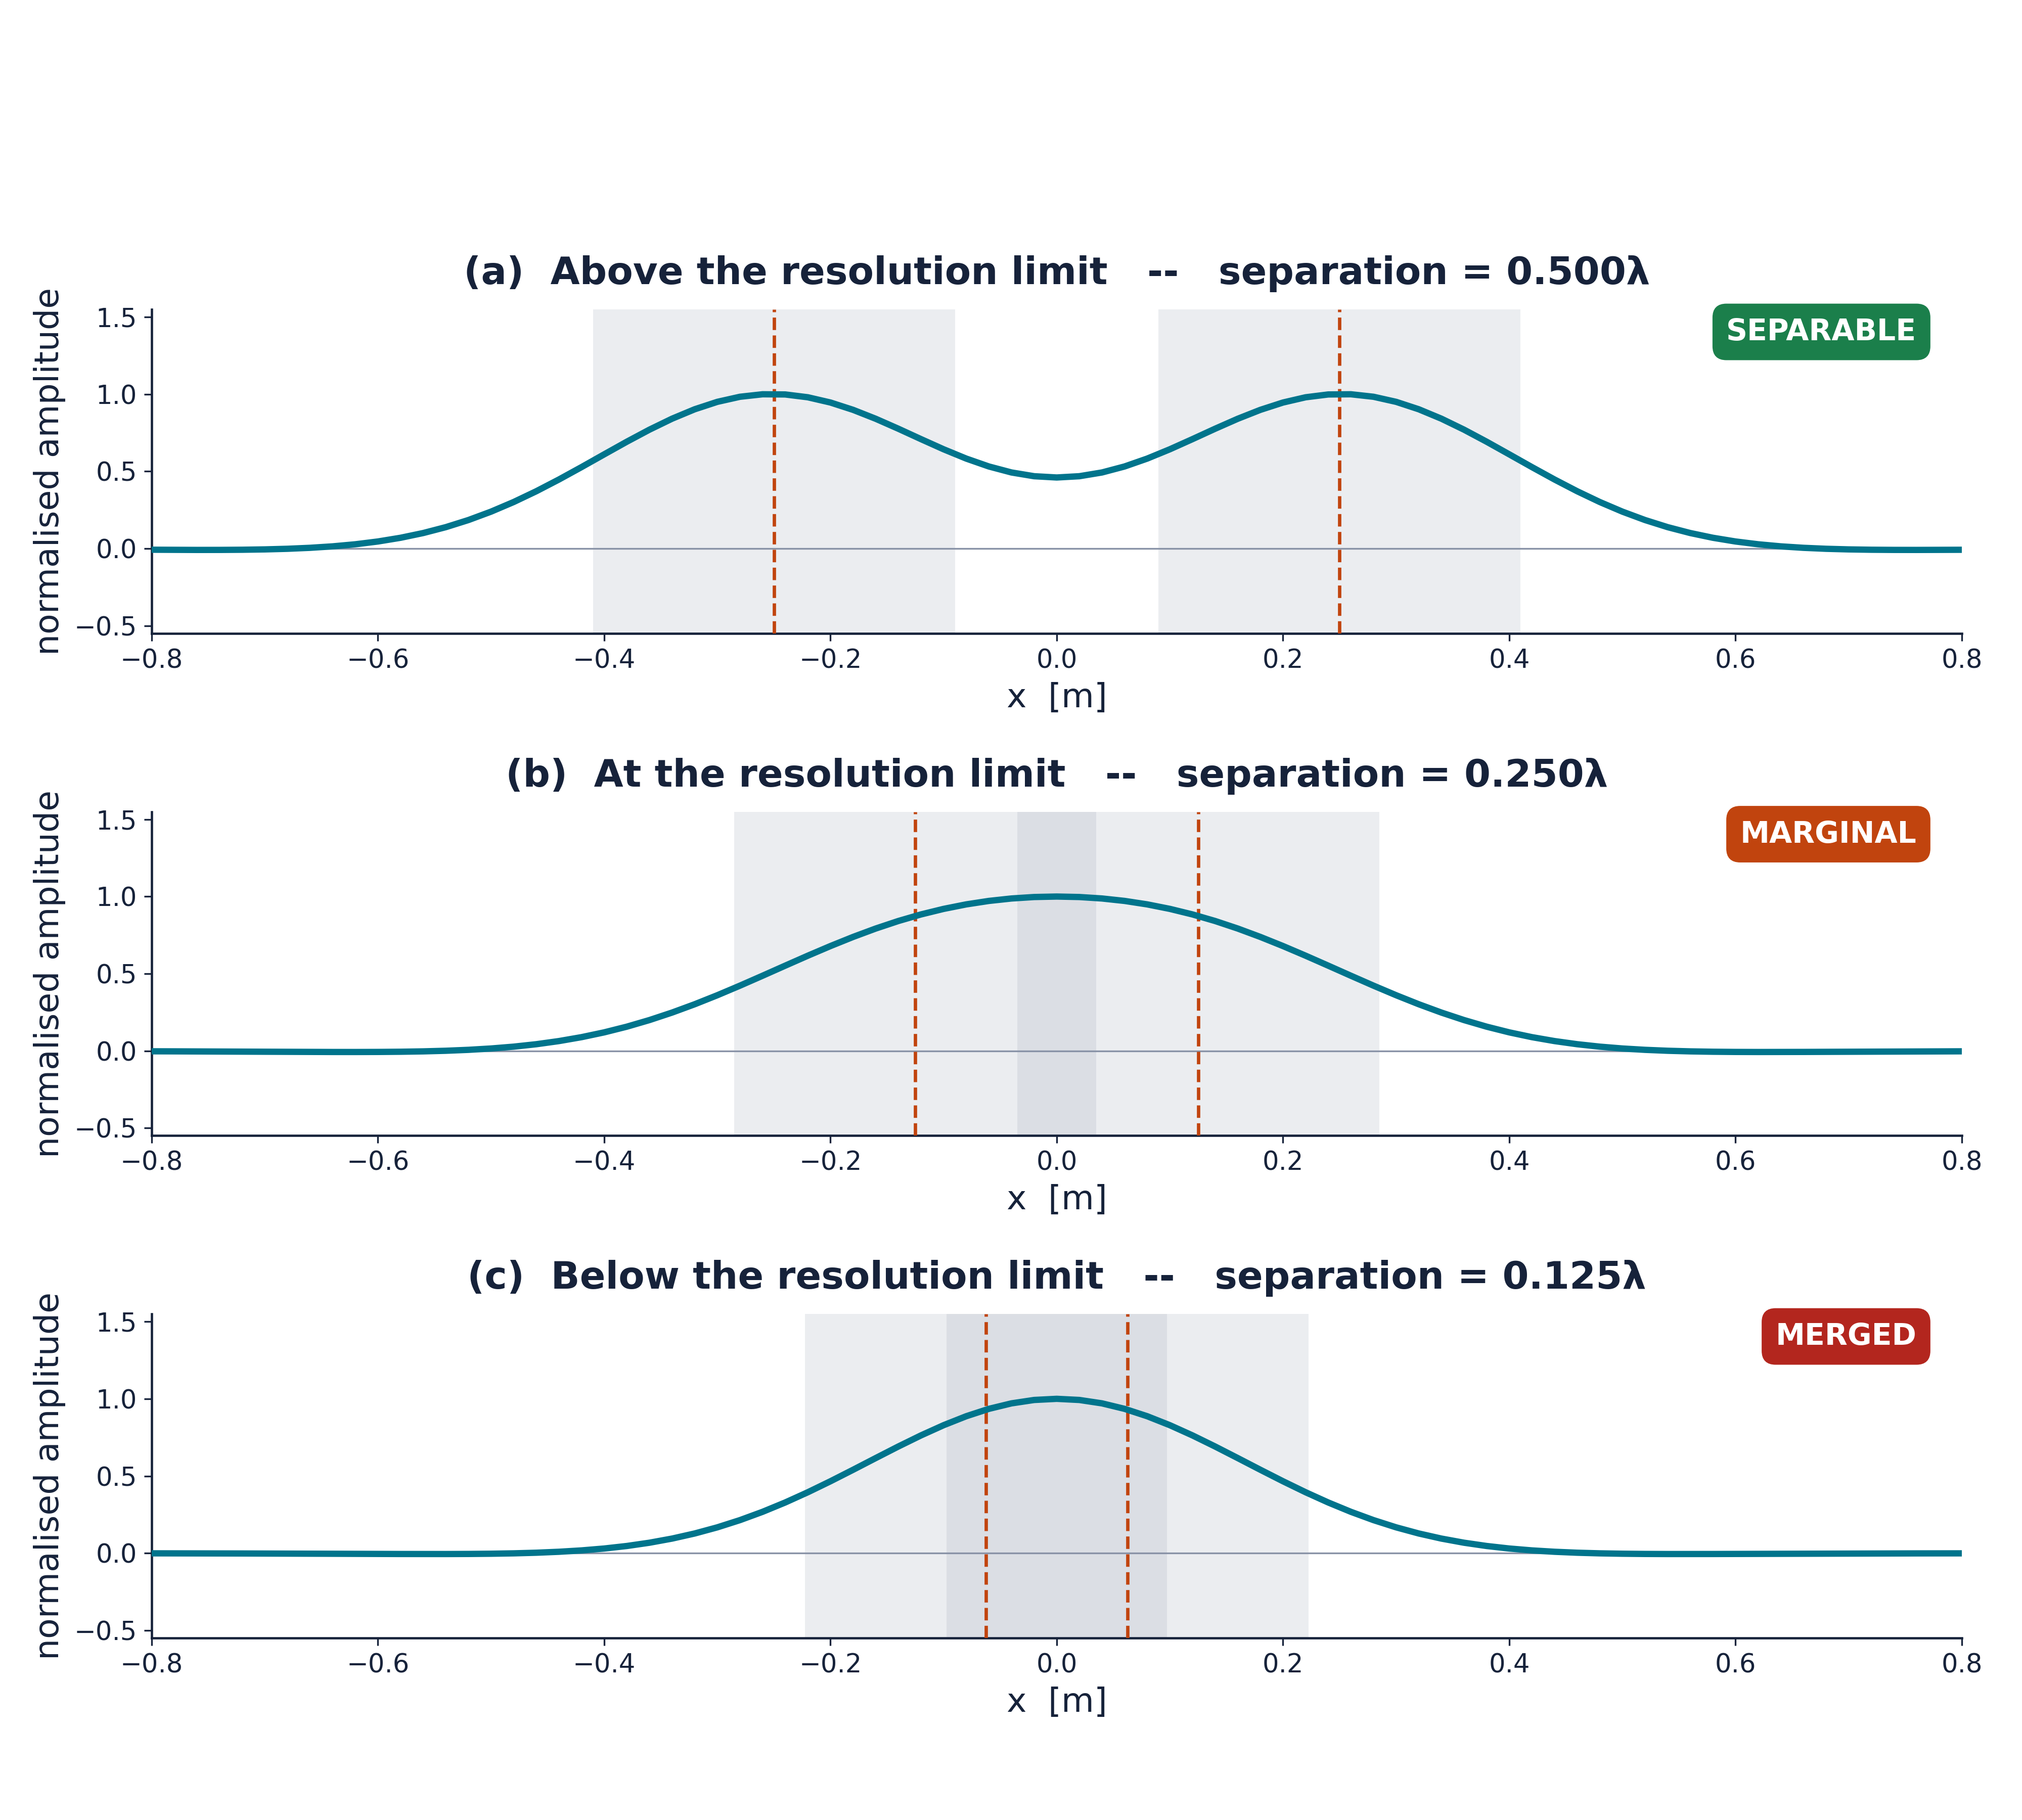

In [10]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
import gpr_style as gs
from IPython.display import Image, display

gs.apply_house_style(base=15)

# ==========================================
# 1. Physical constants & geometry -- same LAMBDA/V/DEPTH convention as
#    "Resolution Limits I/II", but migration is real FDTD back-propagation
#    (time-reversal of the recorded wavefield), matching the "Imaging:
#    Back-Propagation" cell's own solver, not the Kirchhoff stack used in
#    Resolution Limits I/II.
# ==========================================
LAMBDA = 1.0
V = 0.10
V_MIG = V / 2       # exploding-reflector convention
FC = V / LAMBDA
DEPTH = 5.0

X_HALF = 5.0
Z_MAX = 8.0
NX = 501
DX = (2 * X_HALF) / (NX - 1)
DZ = DX
NZ = int(Z_MAX / DZ) + 1
Z_MAX_ACTUAL = (NZ - 1) * DZ

x_pos = np.linspace(-X_HALF, X_HALF, NX)
z_pos = np.linspace(0, Z_MAX_ACTUAL, NZ)

DT_CFL = DX / (V_MIG * np.sqrt(2))
DT = DT_CFL * 0.9
T_MAX = 200.0
NT = int(T_MAX / DT) + 1
time_axis = np.linspace(0, T_MAX, NT)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def synth_bscan(sources):
    """sources: list of (x_pos, depth, amplitude) tuples."""
    B = np.zeros((NT, NX))
    for x_src, z_src, amp in sources:
        dist = np.sqrt((x_pos - x_src) ** 2 + z_src ** 2)
        for i in range(NX):
            B[:, i] += amp * ricker(time_axis - (2 * dist[i] / V), FC) * (z_src / dist[i]) ** 2
    return B


def back_propagate(b_scan):
    """FDTD time-reversal back-propagation (2nd-order leapfrog scalar wave
    equation, exploding-reflector v_mig): inject the recorded B-scan into the
    surface row in reverse time order, evolve the whole field, and return the
    fully time-reversed snapshot -- the same solver as the "Imaging:
    Back-Propagation" cell, generalised to any b_scan/geometry."""
    C2 = (V_MIG * DT / DX) ** 2
    P_past = np.zeros((NZ, NX))
    P_now = np.zeros((NZ, NX))
    P_next = np.zeros((NZ, NX))
    for t_step in range(NT - 1, -1, -1):
        Laplacian = (P_now[:-2, 1:-1] + P_now[2:, 1:-1] +
                     P_now[1:-1, :-2] + P_now[1:-1, 2:] - 4 * P_now[1:-1, 1:-1])
        P_next[1:-1, 1:-1] = 2 * P_now[1:-1, 1:-1] - P_past[1:-1, 1:-1] + C2 * Laplacian
        P_next[0, :] = b_scan[t_step, :]
        P_past[:, :] = P_now
        P_now[:, :] = P_next
    return P_now.copy()


def lateral_profile(img):
    z_idx = np.argmax(np.abs(img).max(axis=1))
    return img[z_idx, :]


def fwhm(profile, dx):
    prof_abs = np.abs(profile)
    half_max = prof_abs.max() / 2.0
    above = np.where(prof_abs >= half_max)[0]
    if len(above) < 2:
        return 0.0
    return (above[-1] - above[0]) * dx


# Reference FWHM: a single isolated back-propagated scatterer's own focal
# width -- the resolution kernel this migration technique actually delivers,
# measured the same way Resolution Limits II measures it for Kirchhoff.
B_ref = synth_bscan([(0.0, DEPTH, 1.0)])
img_ref = back_propagate(B_ref)
FWHM_REF = fwhm(lateral_profile(img_ref), DX)

# The Rayleigh limit itself -- thesis-established for back-propagation
# (04_methodology.typ, sec:meth-resolution): the best of the three migration
# techniques, resolving down to ~1/4 lambda (vs. ~1/2 lambda for Gazdag and
# ~1 lambda for Kirchhoff). The three rows are chosen relative to THIS fixed,
# known constant -- not to FWHM_REF, which is this toy solver's own (close
# but not identical) empirical measurement and shouldn't be trusted to land
# exactly on 0.25 lambda itself.
RAYLEIGH_LIMIT = 0.25 * LAMBDA

ROWS = [
    dict(label="(a)  Above the resolution limit", sep=0.50 * LAMBDA,
         badge="SEPARABLE", color=gs.C_GOOD),
    dict(label="(b)  At the resolution limit", sep=0.25 * LAMBDA,
         badge="MARGINAL", color=gs.C_WARM),
    dict(label="(c)  Below the resolution limit", sep=0.125 * LAMBDA,
         badge="MERGED", color=gs.C_BAD),
]

for row in ROWS:
    h = row["sep"] / 2
    B = synth_bscan([(-h, DEPTH, 1.0), (+h, DEPTH, 1.0)])
    img = back_propagate(B)
    prof = lateral_profile(img)
    row["prof_n"] = prof / (np.abs(prof).max() + 1e-30)

x_prof = np.linspace(-X_HALF, X_HALF, NX)

# ==========================================
# 2. Figure -- 3 stacked rows, one per separation regime. No resolution-
#    metric sweep panel (that needs many separations to be meaningful, not a
#    single static case) -- just the amplitude profile, matching Resolution
#    Limits II's panel (d).
# ==========================================
fig, axes = plt.subplots(3, 1, figsize=(13.333, 12.0))
fig.subplots_adjust(top=0.83, bottom=0.10, left=0.075, right=0.97, hspace=0.55)


zoom = 0.8 * LAMBDA
for ax, row in zip(axes, ROWS):
    h = row["sep"] / 2
    ax.set_xlim(-zoom, zoom)
    ax.set_ylim(-0.55, 1.55)
    ax.axhline(0.0, color=gs.C_GREY, lw=0.8, zorder=0)
    ax.set_title(f"{row['label']}   --   separation = {row['sep']/LAMBDA:.3f}λ",
                 color=gs.C_DARK, fontsize=18, pad=12)
    ax.set_xlabel("x  [m]", size=16)
    ax.set_ylabel("normalised amplitude", size=16)

    ax.plot(x_prof, row["prof_n"], color=gs.C_ACCENT, lw=3.0, zorder=5)
    for centre in (-h, +h):
        ax.axvspan(centre - FWHM_REF / 2, centre + FWHM_REF / 2, color=gs.C_GREY, alpha=0.16, lw=0)
        ax.axvline(centre, color=gs.C_WARM, ls="--", lw=1.6, zorder=4)

    ax.plot([], [], color=gs.C_WARM, ls="--", lw=1.6, label="true positions")
    ax.plot([], [], color=gs.C_GREY, lw=7, alpha=0.35,
            label=f"back-propagation FWHM ≈ {FWHM_REF/LAMBDA:.2f}λ")
    # ax.legend(loc="lower left", fontsize=11.5)

    badge = gs.readout(ax, row["badge"], loc="upper right", size=14, color="white")
    badge.get_bbox_patch().set_facecolor(row["color"])
    badge.get_bbox_patch().set_edgecolor(row["color"])
    badge.get_bbox_patch().set_alpha(1.0)

fig.savefig('Animations/Resolution_BackPropagation_Static.png', dpi=300, facecolor="white")
print("Saved Animations/Resolution_BackPropagation_Static.png")
display(Image(filename='Animations/Resolution_BackPropagation_Static.png'))


Saved Animations/Resolution_Gazdag_Static.png


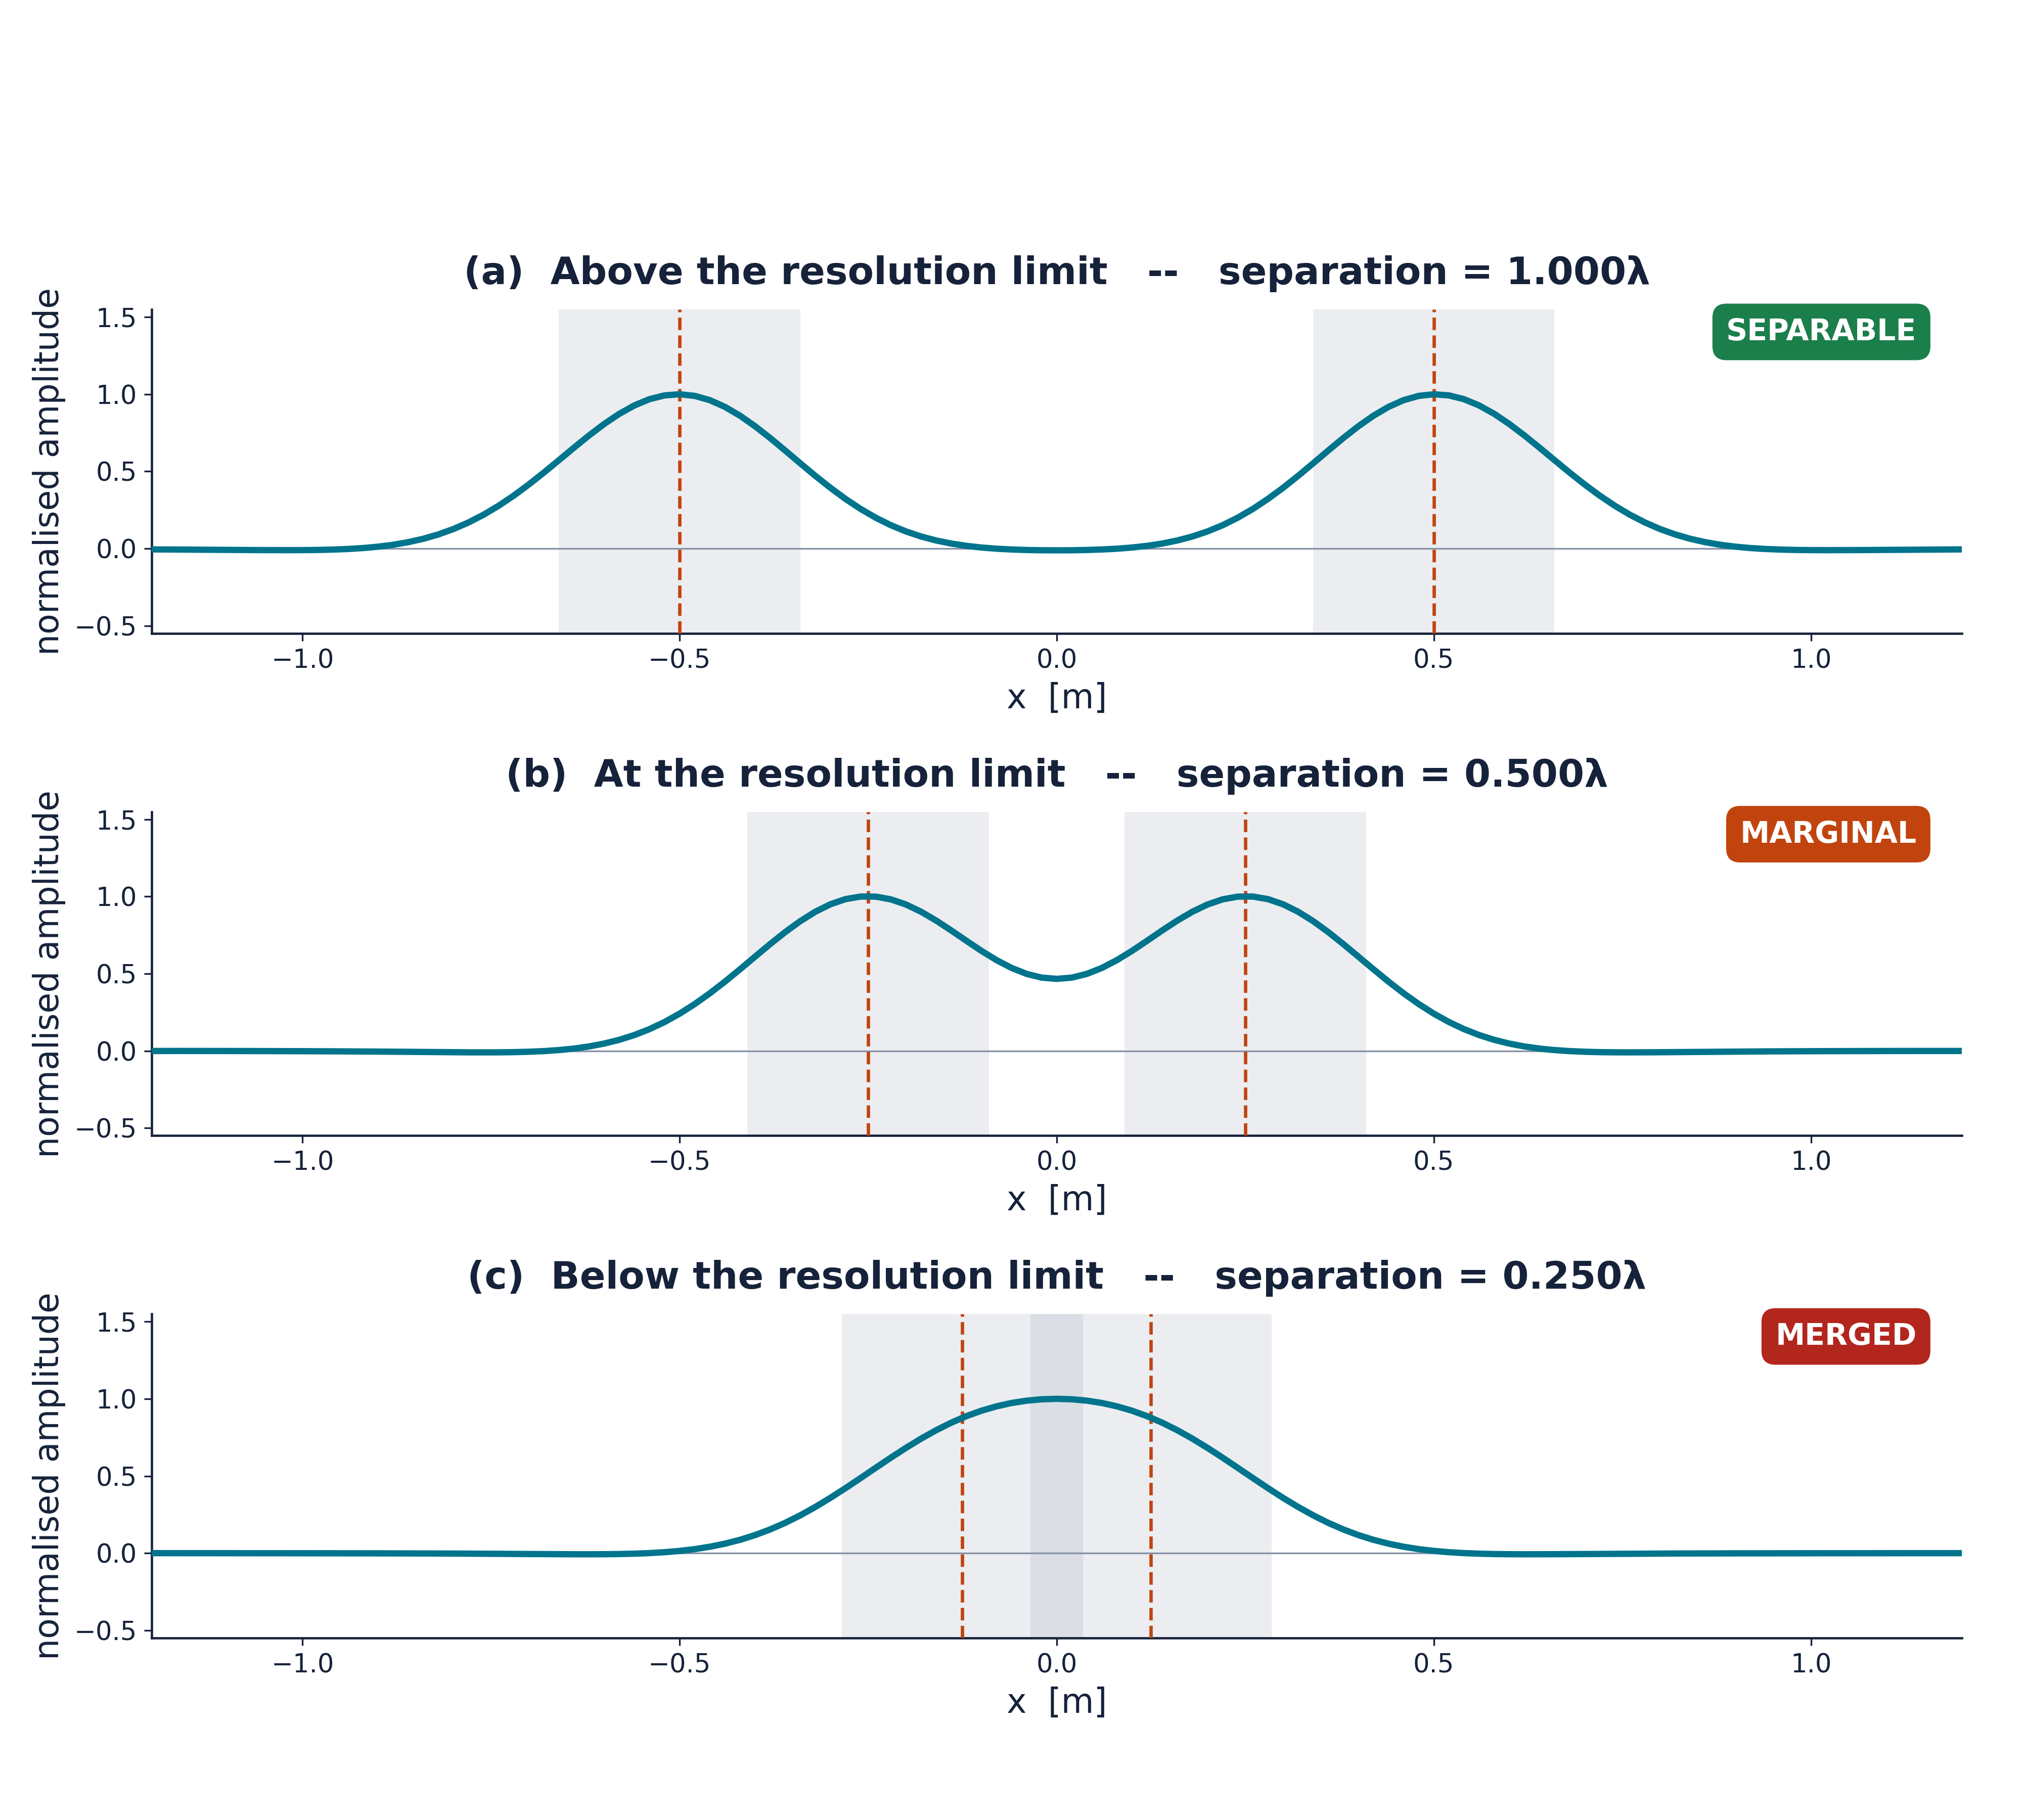

In [46]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
import gpr_style as gs
from IPython.display import Image, display

gs.apply_house_style(base=15)

# ==========================================
# 1. Physical constants & geometry
# ==========================================
LAMBDA = 1.0
V = 0.10
V_MIG = V / 2       # exploding-reflector convention
FC = V / LAMBDA
DEPTH = 5.0

X_HALF = 5.0
Z_MAX = 8.0
NX = 501
DX = (2 * X_HALF) / (NX - 1)
DZ = DX
NZ = int(Z_MAX / DZ) + 1
Z_MAX_ACTUAL = (NZ - 1) * DZ

x_pos = np.linspace(-X_HALF, X_HALF, NX)
z_pos = np.linspace(0, Z_MAX_ACTUAL, NZ)

DT_CFL = DX / (V_MIG * np.sqrt(2))
DT = DT_CFL * 0.9
T_MAX = 200.0
NT = int(T_MAX / DT) + 1
time_axis = np.linspace(0, T_MAX, NT)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def synth_bscan(sources):
    """sources: list of (x_pos, depth, amplitude) tuples."""
    B = np.zeros((NT, NX))
    for x_src, z_src, amp in sources:
        dist = np.sqrt((x_pos - x_src) ** 2 + z_src ** 2)
        for i in range(NX):
            B[:, i] += amp * ricker(time_axis - (2 * dist[i] / V), FC) * (z_src / dist[i]) ** 2
    return B


def gazdag_migrate(b_scan):
    """
    Gazdag (phase-shift) migration in the f-k domain.
    Includes anti-wrapping padding and evanescent filtering.
    """
    nt, nx = b_scan.shape
    pad_t = nt
    pad_x = nx // 2

    nt_pad = nt + pad_t
    nx_pad = nx + (2 * pad_x)

    # Apply padding (zeros) to the B-scan
    b_scan_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')

    # 2D FFT of the PADDED B-scan
    P_fk = np.fft.fft2(b_scan_padded)
    freqs = np.fft.fftfreq(nt_pad, d=DT)
    kxs = np.fft.fftfreq(nx_pad, d=DX)

    KX, F = np.meshgrid(kxs, freqs)
    omega = 2 * np.pi * F
    kx = 2 * np.pi * KX

    # Evanescent filter and wavenumber calculation
    kz_sq = (omega / V_MIG)**2 - kx**2
    kz = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0)
    kz = np.sign(omega) * kz

    migrated_image = np.zeros((NZ, NX), dtype=complex)
    
    # Downward continuation and imaging condition
    for i_z, z in enumerate(z_pos):
        # Phase shift to extrapolate wavefield down to depth z
        P_fk_z = P_fk * np.exp(1j * kz * z)
        # 2D Inverse FFT
        p_xt_z = np.fft.ifft2(P_fk_z)
        # Imaging condition: t=0 is index 0
        migrated_image[i_z, :] = p_xt_z[0, pad_x:pad_x+nx]
        
    return np.real(migrated_image)


def lateral_profile(img):
    z_idx = np.argmax(np.abs(img).max(axis=1))
    return img[z_idx, :]


def fwhm(profile, dx):
    prof_abs = np.abs(profile)
    half_max = prof_abs.max() / 2.0
    above = np.where(prof_abs >= half_max)[0]
    if len(above) < 2:
        return 0.0
    return (above[-1] - above[0]) * dx


# Reference FWHM for Gazdag
B_ref = synth_bscan([(0.0, DEPTH, 1.0)])
img_ref = gazdag_migrate(B_ref)
FWHM_REF = fwhm(lateral_profile(img_ref), DX)

# The Rayleigh limit for Gazdag migration is ~1/2 lambda 
# (wider than back-propagation's ~1/4 lambda).
RAYLEIGH_LIMIT = 0.50 * LAMBDA

# Adjusted separation distances to reflect Gazdag's physical limits
ROWS = [
    dict(label="(a)  Above the resolution limit", sep=1.00 * LAMBDA,
         badge="SEPARABLE", color=gs.C_GOOD),
    dict(label="(b)  At the resolution limit", sep=0.50 * LAMBDA,
         badge="MARGINAL", color=gs.C_WARM),
    dict(label="(c)  Below the resolution limit", sep=0.25 * LAMBDA,
         badge="MERGED", color=gs.C_BAD),
]

for row in ROWS:
    h = row["sep"] / 2
    B = synth_bscan([(-h, DEPTH, 1.0), (+h, DEPTH, 1.0)])
    img = gazdag_migrate(B)
    prof = lateral_profile(img)
    row["prof_n"] = prof / (np.abs(prof).max() + 1e-30)

x_prof = np.linspace(-X_HALF, X_HALF, NX)

# ==========================================
# 2. Figure
# ==========================================
fig, axes = plt.subplots(3, 1, figsize=(13.333, 12.0))
fig.subplots_adjust(top=0.83, bottom=0.10, left=0.075, right=0.97, hspace=0.55)

# Increased zoom window to comfortably fit the 1.0 lambda separation
zoom = 1.2 * LAMBDA 

for ax, row in zip(axes, ROWS):
    h = row["sep"] / 2
    ax.set_xlim(-zoom, zoom)
    ax.set_ylim(-0.55, 1.55)
    ax.axhline(0.0, color=gs.C_GREY, lw=0.8, zorder=0)
    ax.set_title(f"{row['label']}   --   separation = {row['sep']/LAMBDA:.3f}λ",
                 color=gs.C_DARK, fontsize=18, pad=12)
    ax.set_xlabel("x  [m]", size=16)
    ax.set_ylabel("normalised amplitude", size=16)

    ax.plot(x_prof, row["prof_n"], color=gs.C_ACCENT, lw=3.0, zorder=5)
    for centre in (-h, +h):
        ax.axvspan(centre - FWHM_REF / 2, centre + FWHM_REF / 2, color=gs.C_GREY, alpha=0.16, lw=0)
        ax.axvline(centre, color=gs.C_WARM, ls="--", lw=1.6, zorder=4)

    ax.plot([], [], color=gs.C_WARM, ls="--", lw=1.6, label="true positions")
    ax.plot([], [], color=gs.C_GREY, lw=7, alpha=0.35,
            label=f"Gazdag FWHM ≈ {FWHM_REF/LAMBDA:.2f}λ")

    badge = gs.readout(ax, row["badge"], loc="upper right", size=14, color="white")
    badge.get_bbox_patch().set_facecolor(row["color"])
    badge.get_bbox_patch().set_edgecolor(row["color"])
    badge.get_bbox_patch().set_alpha(1.0)

fig.savefig('Animations/Resolution_Gazdag_Static.png', dpi=300, facecolor="white")
print("Saved Animations/Resolution_Gazdag_Static.png")
display(Image(filename='Animations/Resolution_Gazdag_Static.png'))

Time-Lapse Differencing I

In [15]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# Parameters
# ==========================================
num_frames = 150
x_base, z_target = 5.0, 4.0
v, f_c = 0.1, 0.1
wavelength = v / f_c
lateral_shifts = np.linspace(0.0, 0.5 * wavelength, num_frames)

# Migration grid -- doubled from the original 200x200 for a sharper image
nx, nz = 400, 400
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dx, dz = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
time_axis = np.linspace(0, 160, 400)
dt = time_axis[1] - time_axis[0]
nt = len(time_axis)

v_mig = v / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dx), np.fft.fftfreq(nt_pad, d=dt))
omega, kx = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig)**2 - kx**2
kz = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz * dz)  # depths are evenly spaced -> step once, multiply per depth


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t)**2) * np.exp(-(np.pi * f * t)**2)


def migrate_target(x_tgt):
    """Gazdag (f-k) migration of a single point scatterer at x_tgt.

    Depths are stepped via a phase-shift recurrence (phase *= phase_step)
    instead of re-evaluating exp(1j*kz*z) from scratch every depth, and
    each depth only needs the t=0 row of the inverse transform -- the mean
    over the frequency axis followed by a single 1D IFFT along kx, not a
    full 2D IFFT. Both are algebraically exact (checked against the naive
    per-depth ifft2 to ~1e-14), not approximations; together they're what
    makes the doubled grid resolution affordable to render frame-by-frame.
    """
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_tgt)**2 + z_target**2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / v), f_c) * (z_target / dist)**2

    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)

    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated


mig_base = migrate_target(x_base)
vmax_m = np.max(np.abs(mig_base)) * 0.8
vmax_diff = vmax_m * 0.5

# ==========================================
# Figure Setup -- one figure, two rows: physical setup, then migration
# ==========================================
fig = plt.figure(figsize=(gs.FIGSIZE[0], 12.6))
grid = fig.add_gridspec(2, 6, left=0.055, right=0.97, top=0.80, bottom=0.08,
                        hspace=0.55, wspace=0.9)

ax_a = fig.add_subplot(grid[0, 0:3])
ax_b = fig.add_subplot(grid[0, 3:6])
ax_c = fig.add_subplot(grid[1, 0:2])
ax_d = fig.add_subplot(grid[1, 2:4])
ax_e = fig.add_subplot(grid[1, 4:6])

for ax in (ax_a, ax_b):
    ax.set_xlim(4, 6)
    ax.set_ylim(4.5, 3.5)  # Inverted depth
    ax.set_xlabel('x  [m]', size=20)
    ax.set_ylabel('z  [m]', size=20)
    ax.grid(True, linestyle='--', alpha=0.4, color=gs.C_GREY)

ax_a.set_title('(a)  Baseline (T0)', color=gs.C_DARK, pad=14, fontsize=20)
ax_a.plot(x_base, z_target, 'o', color=gs.C_ACCENT, markersize=15, markeredgecolor=gs.C_DARK)

ax_b.set_title('(b)  Monitor (T1)', color=gs.C_DARK, pad=14, fontsize=20)
baseline_dot, = ax_b.plot(x_base, z_target, 'o', color=gs.C_ACCENT, alpha=0.35, markersize=15,
                          markeredgecolor=gs.C_DARK, zorder=1)
mon_dot, = ax_b.plot(x_base, z_target, 'o', color=gs.C_WARM, markersize=15, markeredgecolor=gs.C_DARK, zorder=3)

for ax in (ax_c, ax_d, ax_e):
    ax.set_xlim(4, 6)
    ax.set_ylim(5, 3)
    ax.set_xlabel('x  [m]', size=20)
    ax.set_ylabel('z  [m]', size=20)

ax_c.set_title('(c)  Baseline (T0)', color=gs.C_DARK, pad=14, fontsize=20)
ax_c.imshow(mig_base, aspect='auto', cmap=gs.CMAP_IMG, extent=[0, 10, 8, 0], vmin=-vmax_m, vmax=vmax_m)
ax_c.plot(x_base, z_target, '+', color=gs.C_DARK, markersize=15, markeredgewidth=2.5)

ax_d.set_title('(d)  Monitor (T1)', color=gs.C_DARK, pad=14, fontsize=20)
im_d = ax_d.imshow(mig_base, aspect='auto', cmap=gs.CMAP_IMG, extent=[0, 10, 8, 0], vmin=-vmax_m, vmax=vmax_m)
tgt_cross, = ax_d.plot([], [], '+', color=gs.C_DARK, markersize=15, markeredgewidth=2.5)

ax_e.set_title('(e)  Difference ($\Delta$T)', color=gs.C_DARK, pad=14, fontsize=20)
im_e = ax_e.imshow(np.zeros_like(mig_base), aspect='auto', cmap=gs.CMAP_IMG,
                   extent=[0, 10, 8, 0], vmin=-vmax_diff, vmax=vmax_diff)

# Dashed vertical lines showing baseline and monitor positions in the second row
baseline_vlines = []
monitor_vlines = []
for ax in (ax_c, ax_d, ax_e):
    baseline_vlines.append(ax.axvline(x_base, color=gs.C_ACCENT, linestyle='--', linewidth=1.6, alpha=0.75))
    monitor_vlines.append(ax.axvline(x_base, color=gs.C_WARM, linestyle='--', linewidth=1.6, alpha=0.75))

# ==========================================
# Animation Logic
# ==========================================
def update(frame):
    current_x = x_base + lateral_shifts[frame]
    mig_mon = migrate_target(current_x)

    mon_dot.set_data([current_x], [z_target])
    tgt_cross.set_data([current_x], [z_target])
    for line in monitor_vlines:
        line.set_xdata([current_x, current_x])
    im_d.set_data(mig_mon)
    im_e.set_data(mig_mon - mig_base)

    return (mon_dot, tgt_cross, im_d, im_e,
            baseline_vlines[0], baseline_vlines[1], baseline_vlines[2],
            monitor_vlines[0], monitor_vlines[1], monitor_vlines[2])


ani = FuncAnimation(fig, update, frames=num_frames, blit=True, interval=100, repeat=False)

print("Exporting combined physical-setup + migration animation...")
writer = FFMpegWriter(fps=10, bitrate=8000)
ani.save('Animations/PhysicalSetup_To_Migration.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()

<>:115: SyntaxWarning: invalid escape sequence '\D'
<>:115: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Administrator\AppData\Local\Temp\ipykernel_7840\1068061581.py:115: SyntaxWarning: invalid escape sequence '\D'
  ax_e.set_title('(e)  Difference ($\Delta$T)', color=gs.C_DARK, pad=14, fontsize=20)


Exporting combined physical-setup + migration animation...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_7840\1068061581.py:152: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Time-Lapse Differencing II

In [21]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# Parameters & Precomputation
# ==========================================
num_frames = 200
v, f_c = 0.1, 0.1
wavelength = v / f_c
# Scatterers start coincident (closest possible) and separate as the
# animation progresses.
lateral_shifts = np.linspace(0.0, 0.75 * wavelength, num_frames)

x_base, z_target = 5.0, 4.0

# B-scan acquisition grid (traces)
nx_bscan = 200
x_bscan = np.linspace(0, 10, nx_bscan)

# Fine time axis -- avoids jagged np.interp artifacts in the Kirchhoff sum
# below (same fix used in gif_maker.ipynb's smooth tuning-curve cell).
t_max, nt = 160, 2000
time_axis = np.linspace(0, t_max, nt)

# Fine, DECOUPLED evaluation grid for the PSF slice itself. Peak-picking
# directly on the (coarse) trace grid is what produced the blocky/staircase
# change-detection line before: argmax/argmin could only land on multiples
# of the trace spacing (0.05 m). Kirchhoff summation can be evaluated at
# any x, so we read it out on a much finer grid instead of resolving it.
nx_slice = 3000
x_slice = np.linspace(3, 7, nx_slice)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t)**2) * np.exp(-(np.pi * f * t)**2)


def generate_bscan(x_tgt):
    b_scan = np.zeros((nt, nx_bscan))
    for i, x_tr in enumerate(x_bscan):
        dist = np.sqrt((x_tr - x_tgt)**2 + z_target**2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / v), f_c) * (z_target / dist)**2
    return b_scan


def migrate_1d_slice(b_scan):
    """Kirchhoff diffraction-stack, evaluated directly on the fine x_slice
    grid -- not snapped to the trace spacing the way an FFT-based (Gazdag)
    grid would be."""
    psf_slice = np.zeros(nx_slice)
    for i, x_tr in enumerate(x_bscan):
        dist_grid = np.sqrt((x_slice - x_tr)**2 + z_target**2)
        t_grid = 2 * dist_grid / v
        contribution = np.interp(t_grid, time_axis, b_scan[:, i])
        contribution *= (z_target / dist_grid)
        psf_slice += contribution
    return psf_slice


def lobe_bounds(y, peak_idx):
    """Half-max x-bounds of the single lobe (positive or negative) around
    peak_idx, walking outward until the curve crosses back through half the
    peak's own (signed) value."""
    peak_val = y[peak_idx]
    half = peak_val / 2.0
    i_left = peak_idx
    while i_left > 0 and ((peak_val > 0 and y[i_left] >= half) or (peak_val < 0 and y[i_left] <= half)):
        i_left -= 1
    i_right = peak_idx
    n = len(y)
    while i_right < n - 1 and ((peak_val > 0 and y[i_right] >= half) or (peak_val < 0 and y[i_right] <= half)):
        i_right += 1
    return x_slice[i_left], x_slice[i_right]


slice_base = migrate_1d_slice(generate_bscan(x_base))
amp_scale = np.max(np.abs(slice_base))
if amp_scale == 0:
    amp_scale = 1.0
slice_base = slice_base / amp_scale
y_max = 1.0
y_panel_max = 1.0
# Below this dipole amplitude the peak/trough split is noise, not signal --
# used to blank the FWHM bands and change-detection point near frame 0,
# where baseline and monitor still coincide.
amp_floor = 0.02 * y_max

# ==========================================
# Figure Setup
# ==========================================
fig, (ax1, ax2, ax3, ax4) = plt.subplots(
    1, 4, figsize=gs.FIGSIZE, gridspec_kw={'width_ratios': [1, 1, 1, 1.05]})
fig.subplots_adjust(top=0.74, bottom=0.14, left=0.045, right=0.98, wspace=0.42)

for ax in [ax1, ax2, ax3]:
    ax.set_xlim(4, 6)
    ax.set_xlabel('x  [m]', size=15)
    ax.set_ylabel('Amplitude', size=15)
    ax.set_box_aspect(1)
    ax.grid(True, linestyle='--', alpha=0.4, color=gs.C_GREY)

ax1.set_title('(a)  Baseline (T0)', color=gs.C_DARK, pad=14, fontsize=15)
ax1.set_ylim(-y_panel_max, y_panel_max)
ax1.plot(x_slice, slice_base, color=gs.C_ACCENT, linewidth=2)

ax2.set_title('(b)  Monitor (T1)', color=gs.C_DARK, pad=14, fontsize=15)
ax2.set_ylim(-y_panel_max, y_panel_max)
line2, = ax2.plot(x_slice, slice_base, color=gs.C_WARM, linewidth=2)

ax3.set_title('(c)  Difference ($\Delta$)T', color=gs.C_DARK, pad=14, fontsize=15)
ax3.set_ylim(-y_panel_max, y_panel_max)
line3, = ax3.plot(x_slice, np.zeros_like(slice_base), color=gs.C_BAD, linewidth=2, label='amplitude diff')
ax3.axhline(0, color=gs.C_DARK, linewidth=1, linestyle='-')

# FWHM highlight for each lobe of the dipole (updated per frame)
fwhm_pos = ax3.axvspan(x_base, x_base, color=gs.C_GREY, alpha=0.20, lw=0, zorder=0)
fwhm_neg = ax3.axvspan(x_base, x_base, color=gs.C_GREY, alpha=0.20, lw=0, zorder=0)

# --- Add True Location Dashed Lines to the three PSF panels ---
base_vlines = []
mon_vlines = []

for ax in [ax1, ax2, ax3]:
    # Teal dashed line for true baseline (matches the baseline PSF colour)
    b_line = ax.axvline(x_base, color=gs.C_ACCENT, linestyle='--', linewidth=1.5, alpha=0.8, label='true baseline')
    # Orange dashed line for true monitor (matches the monitor PSF colour)
    m_line = ax.axvline(x_base, color=gs.C_WARM, linestyle='--', linewidth=1.5, alpha=0.8, label='true monitor')

    base_vlines.append(b_line)
    mon_vlines.append(m_line)


# --- Panel (d): Change detection -- visual vs. true separation ---
diag_max = 0.5 * wavelength / wavelength * 1.15
ax4.set_title('(d)  Change Detection', color=gs.C_DARK, pad=14, fontsize=15)
ax4.set_xlabel('True Movement  [Î»]', size=15)
ax4.set_ylabel('Visual Separation  [Î»]', size=15)
ax4.set_xlim(0, diag_max)
ax4.set_ylim(0, diag_max)
ax4.set_aspect('equal', adjustable='box')
ax4.grid(True, linestyle='--', alpha=0.4, color=gs.C_GREY)

ax4.plot([0, diag_max], [0, diag_max], '--', color=gs.C_GREY, linewidth=1.6,
         zorder=1, label='ideal (visual = true)')
change_line, = ax4.plot([], [], '-o', color=gs.C_ACCENT, linewidth=2.2, ms=4.5,
                        zorder=5, label='measured')

true_moves = []
visual_seps = []

# ==========================================
# Animation Logic
# ==========================================
def update(frame):
    current_x = x_base + lateral_shifts[frame]
    slice_mon = migrate_1d_slice(generate_bscan(current_x)) / amp_scale
    slice_diff = slice_mon - slice_base

    # Panels (b), (c): PSF and dipole difference
    line2.set_ydata(slice_mon)
    line3.set_ydata(slice_diff)

    # Monitor true-location vertical line in all three PSF panels
    for m_line in mon_vlines:
        m_line.set_xdata([current_x, current_x])

    # Panel (c): FWHM of each dipole lobe -- blanked until the dipole has
    # separated enough from zero to be a real peak/trough, not noise
    pos_idx, neg_idx = np.argmax(slice_diff), np.argmin(slice_diff)
    if slice_diff[pos_idx] > amp_floor and -slice_diff[neg_idx] > amp_floor:
        xl, xr = lobe_bounds(slice_diff, pos_idx)
        fwhm_pos.set_x(xl)
        fwhm_pos.set_width(xr - xl)
        xl, xr = lobe_bounds(slice_diff, neg_idx)
        fwhm_neg.set_x(xl)
        fwhm_neg.set_width(xr - xl)

        # Panel (d): visual separation (peak-to-trough spacing) vs. true shift
        visual_sep = abs(x_slice[pos_idx] - x_slice[neg_idx])
        true_moves.append(lateral_shifts[frame] / wavelength)
        visual_seps.append(visual_sep / wavelength)
        change_line.set_data(true_moves, visual_seps)
    else:
        fwhm_pos.set_width(0)
        fwhm_neg.set_width(0)

    return (line3, fwhm_pos, fwhm_neg, change_line,
            mon_vlines[0], mon_vlines[1], mon_vlines[2])


ani = FuncAnimation(fig, update, frames=num_frames, blit=True, interval=100, repeat=False)

print("Rendering dipole / change-detection animation...")
writer = FFMpegWriter(fps=10, bitrate=8000)
ani.save('Animations/PSF_Dipole_ChangeDetection.mp4', writer=writer, dpi=300)
print("Export complete.")
plt.show()

<>:116: SyntaxWarning: invalid escape sequence '\D'
<>:116: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Administrator\AppData\Local\Temp\ipykernel_7840\2224383367.py:116: SyntaxWarning: invalid escape sequence '\D'
  ax3.set_title('(c)  Difference ($\Delta$)T', color=gs.C_DARK, pad=14, fontsize=15)
C:\Users\Administrator\AppData\Local\Temp\ipykernel_7840\2224383367.py:97: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, (ax1, ax2, ax3, ax4) = plt.subplots(


Rendering dipole / change-detection animation...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_7840\2224383367.py:203: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Time-Lapse Differencing III

In [36]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# Parameters -- shared physical setup (same point-scatterer geometry used by
# both Time-Lapse Differencing I's 2-D migration panels and Differencing II's
# 1-D lobe panels)
# ==========================================
x_base, z_target = 5.0, 4.0
v, f_c = 0.1, 0.1
wavelength = v / f_c
shift_max = 0.75 * wavelength

# Much slower than either source animation: more, finer frames, played back
# at half the frame rate.
num_frames = 260
FPS = 5
lateral_shifts = np.linspace(0.0, shift_max, num_frames)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t)**2) * np.exp(-(np.pi * f * t)**2)


# ==========================================
# Row 1 precomputation -- Gazdag (f-k) migration of the full 2-D image
# (from Time-Lapse Differencing I)
# ==========================================
nx_img, nz_img = 400, 400
x_img, z_img = np.linspace(0, 10, nx_img), np.linspace(0, 8, nz_img)
dx_img, dz_img = x_img[1] - x_img[0], z_img[1] - z_img[0]
t_img = np.linspace(0, 160, 400)
dt_img = t_img[1] - t_img[0]
nt_img = len(t_img)

v_mig = v / 2
pad_t_img, pad_x_img = nt_img, nx_img // 2
nt_img_pad, nx_img_pad = nt_img + pad_t_img, nx_img + 2 * pad_x_img
KX_img, F_img = np.meshgrid(np.fft.fftfreq(nx_img_pad, d=dx_img), np.fft.fftfreq(nt_img_pad, d=dt_img))
omega_img, kx_img = 2 * np.pi * F_img, 2 * np.pi * KX_img
kz_img_sq = (omega_img / v_mig)**2 - kx_img**2
kz_img = np.where(kz_img_sq >= 0, np.sqrt(np.maximum(kz_img_sq, 0)), 0) * np.sign(omega_img)
phase_step_img = np.exp(1j * kz_img * dz_img)


def migrate_target(x_tgt):
    """Gazdag (f-k) migration of a single point scatterer at x_tgt (see
    Time-Lapse Differencing I for the phase-shift recurrence + single-row
    IFFT shortcuts that make this affordable per-frame)."""
    b_scan = np.zeros((nt_img, nx_img))
    for i, x in enumerate(x_img):
        dist = np.sqrt((x - x_tgt)**2 + z_target**2)
        b_scan[:, i] = ricker(t_img - (2 * dist / v), f_c) * (z_target / dist)**2

    b_padded = np.pad(b_scan, ((0, pad_t_img), (pad_x_img, pad_x_img)), mode='constant')
    P_fk = np.fft.fft2(b_padded)

    migrated = np.zeros((nz_img, nx_img))
    phase = np.ones_like(kz_img, dtype=complex)
    for iz in range(nz_img):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_img_pad))
        migrated[iz, :] = row[pad_x_img:pad_x_img + nx_img]
        phase *= phase_step_img
    return migrated


mig_base = migrate_target(x_base)
vmax_m = np.max(np.abs(mig_base)) * 0.8
vmax_diff = vmax_m * 0.5

# ==========================================
# Row 2 precomputation -- Kirchhoff diffraction-stack PSF slice
# (from Time-Lapse Differencing II)
# ==========================================
nx_bscan = 200
x_bscan = np.linspace(0, 10, nx_bscan)
t_max_lobe, nt_lobe = 160, 2000
t_lobe = np.linspace(0, t_max_lobe, nt_lobe)
nx_slice = 3000
x_slice = np.linspace(3, 7, nx_slice)


def generate_bscan(x_tgt):
    b_scan = np.zeros((nt_lobe, nx_bscan))
    for i, x_tr in enumerate(x_bscan):
        dist = np.sqrt((x_tr - x_tgt)**2 + z_target**2)
        b_scan[:, i] = ricker(t_lobe - (2 * dist / v), f_c) * (z_target / dist)**2
    return b_scan


def migrate_1d_slice(b_scan):
    """Kirchhoff diffraction-stack, evaluated directly on the fine x_slice
    grid (not snapped to the trace spacing)."""
    psf_slice = np.zeros(nx_slice)
    for i, x_tr in enumerate(x_bscan):
        dist_grid = np.sqrt((x_slice - x_tr)**2 + z_target**2)
        t_grid = 2 * dist_grid / v
        contribution = np.interp(t_grid, t_lobe, b_scan[:, i])
        contribution *= (z_target / dist_grid)
        psf_slice += contribution
    return psf_slice


def lobe_bounds(y, peak_idx):
    """Half-max x-bounds of the single lobe (positive or negative) around
    peak_idx, walking outward until the curve crosses back through half the
    peak's own (signed) value."""
    peak_val = y[peak_idx]
    half = peak_val / 2.0
    i_left = peak_idx
    while i_left > 0 and ((peak_val > 0 and y[i_left] >= half) or (peak_val < 0 and y[i_left] <= half)):
        i_left -= 1
    i_right = peak_idx
    n = len(y)
    while i_right < n - 1 and ((peak_val > 0 and y[i_right] >= half) or (peak_val < 0 and y[i_right] <= half)):
        i_right += 1
    return x_slice[i_left], x_slice[i_right]


slice_base = migrate_1d_slice(generate_bscan(x_base))
amp_scale = np.max(np.abs(slice_base))
if amp_scale == 0:
    amp_scale = 1.0
slice_base = slice_base / amp_scale
y_panel_max = 1.0
# Below this dipole amplitude the peak/trough split is noise, not signal.
amp_floor = 0.02 * y_panel_max

diag_max = (shift_max / wavelength) * 1.15

# ==========================================
# Figure setup -- 2 rows x 4 columns
# Row 1: migrated baseline | migrated monitor | difference | moving point scatterers
# Row 2: baseline lobe     | monitor lobe      | difference lobes | change detection
# ==========================================
fig = plt.figure(figsize=(gs.FIGSIZE[0], 13.0))
grid = fig.add_gridspec(2, 4, left=0.05, right=0.98, top=0.90, bottom=0.07,
                        hspace=0.5, wspace=0.45, width_ratios=[1, 1, 1, 1.05])

ax_migbase = fig.add_subplot(grid[0, 0])
ax_migmon = fig.add_subplot(grid[0, 1])
ax_migdiff = fig.add_subplot(grid[0, 2])
ax_scatter = fig.add_subplot(grid[0, 3])

ax_lobebase = fig.add_subplot(grid[1, 0])
ax_lobemon = fig.add_subplot(grid[1, 1])
ax_lobediff = fig.add_subplot(grid[1, 2])
ax_change = fig.add_subplot(grid[1, 3])

# --- Row 1: migrated images -------------------------------------------------
for ax in (ax_migbase, ax_migmon, ax_migdiff):
    ax.set_xlim(4, 6)
    ax.set_ylim(5, 3)
    ax.set_xlabel('x  [m]', size=13)
    ax.set_ylabel('z  [m]', size=13)
    ax.axhline(y=4, color='white', linestyle='--', linewidth=1.5, alpha=0.6)

ax_migbase.set_title('(a)  Migrated Baseline', color=gs.C_DARK, pad=12, fontsize=15)
ax_migbase.imshow(mig_base, aspect='auto', cmap=gs.CMAP_IMG, extent=[0, 10, 8, 0], vmin=-vmax_m, vmax=vmax_m)

ax_migmon.set_title('(b)  Migrated Monitor', color=gs.C_DARK, pad=12, fontsize=15)
im_migmon = ax_migmon.imshow(mig_base, aspect='auto', cmap=gs.CMAP_IMG, extent=[0, 10, 8, 0], vmin=-vmax_m, vmax=vmax_m)

ax_migdiff.set_title('(c)  Difference ($\\Delta$T)', color=gs.C_DARK, pad=12, fontsize=15)
im_migdiff = ax_migdiff.imshow(np.zeros_like(mig_base), aspect='auto', cmap=gs.CMAP_IMG,
                               extent=[0, 10, 8, 0], vmin=-vmax_diff, vmax=vmax_diff)

# Vertical lines through the migrated profiles, marking the true baseline /
# monitor scatterer positions -- i.e. where the lobes in row 2 come from.
img_baseline_vlines, img_monitor_vlines = [], []
for ax in (ax_migbase, ax_migmon, ax_migdiff):
    img_baseline_vlines.append(ax.axvline(x_base, color=gs.C_ACCENT, linestyle='--', linewidth=1.6, alpha=0.75))
    img_monitor_vlines.append(ax.axvline(x_base, color=gs.C_WARM, linestyle='--', linewidth=1.6, alpha=0.75))

# --- Row 1, col 4: moving point scatterers ----------------------------------
ax_scatter.set_title('(d)  Moving Scatterers', color=gs.C_DARK, pad=12, fontsize=15)
ax_scatter.set_xlim(3.5, 6.5)
ax_scatter.set_ylim(4.5, 3.5)
ax_scatter.set_xlabel('x  [m]', size=13)
ax_scatter.set_ylabel('z  [m]', size=13)
ax_scatter.grid(True, linestyle='--', alpha=0.4, color=gs.C_GREY)
ax_scatter.plot(x_base, z_target, 'o', color=gs.C_ACCENT, alpha=0.35, markersize=15,
                markeredgecolor=gs.C_DARK, zorder=1)
mon_dot, = ax_scatter.plot(x_base, z_target, 'o', color=gs.C_WARM, markersize=15,
                           markeredgecolor=gs.C_DARK, zorder=3)

ax_scatter.axhline(y=4, color=gs.C_GREY, linestyle='--', linewidth=1.5, alpha=0.8, zorder=0)

# --- Row 2: PSF lobes (from Time-Lapse Differencing II) --------------------
for ax in (ax_lobebase, ax_lobemon, ax_lobediff):
    ax.set_xlim(4.5, 5.5)
    ax.set_ylim(-y_panel_max, y_panel_max)
    ax.set_xlabel('x  [m]', size=13)
    ax.set_ylabel('Amplitude', size=13)
    ax.grid(True, linestyle='--', alpha=0.4, color=gs.C_GREY)

ax_lobebase.set_title('(e)  Baseline Lobe', color=gs.C_DARK, pad=12, fontsize=15)
ax_lobebase.plot(x_slice, slice_base, color=gs.C_ACCENT, linewidth=2)

ax_lobemon.set_title('(f)  Monitor Lobe', color=gs.C_DARK, pad=12, fontsize=15)
line_lobemon, = ax_lobemon.plot(x_slice, slice_base, color=gs.C_WARM, linewidth=2)

ax_lobediff.set_title('(g)  Difference Lobes', color=gs.C_DARK, pad=12, fontsize=15)
line_lobediff, = ax_lobediff.plot(x_slice, np.zeros_like(slice_base), color=gs.C_BAD, linewidth=2)
ax_lobediff.axhline(0, color=gs.C_DARK, linewidth=1, linestyle='-')

fwhm_pos = ax_lobediff.axvspan(x_base, x_base, color=gs.C_GREY, alpha=0.20, lw=0, zorder=0)
fwhm_neg = ax_lobediff.axvspan(x_base, x_base, color=gs.C_GREY, alpha=0.20, lw=0, zorder=0)

lobe_baseline_vlines, lobe_monitor_vlines = [], []
for ax in (ax_lobebase, ax_lobemon, ax_lobediff):
    lobe_baseline_vlines.append(ax.axvline(x_base, color=gs.C_ACCENT, linestyle='--', linewidth=1.5, alpha=0.8))
    lobe_monitor_vlines.append(ax.axvline(x_base, color=gs.C_WARM, linestyle='--', linewidth=1.5, alpha=0.8))

# --- Row 2, col 4: change detection -----------------------------------------
ax_change.set_title('(h)  Change Detection', color=gs.C_DARK, pad=12, fontsize=15)
ax_change.set_xlabel('True Movement  [λ]', size=13)
ax_change.set_ylabel('Visual Separation  [λ]', size=13)
ax_change.set_xlim(0, diag_max)
ax_change.set_ylim(0, diag_max)
ax_change.set_aspect('equal', adjustable='box')
ax_change.grid(True, linestyle='--', alpha=0.4, color=gs.C_GREY)
ax_change.plot([0, diag_max], [0, diag_max], '--', color=gs.C_GREY, linewidth=1.6, zorder=1)
change_line, = ax_change.plot([], [], '-o', color=gs.C_ACCENT, linewidth=2.2, ms=4, zorder=5)

true_moves, visual_seps = [], []

# ==========================================
# Animation logic
# ==========================================
def update(frame):
    current_x = x_base + lateral_shifts[frame]

    # --- Row 1: migrated images + moving scatterer -------------------------
    mig_mon = migrate_target(current_x)
    im_migmon.set_data(mig_mon)
    im_migdiff.set_data(mig_mon - mig_base)
    for line in img_monitor_vlines:
        line.set_xdata([current_x, current_x])
    mon_dot.set_data([current_x], [z_target])

    # --- Row 2: PSF lobes + change detection --------------------------------
    slice_mon = migrate_1d_slice(generate_bscan(current_x)) / amp_scale
    slice_diff = slice_mon - slice_base
    line_lobemon.set_ydata(slice_mon)
    line_lobediff.set_ydata(slice_diff)
    for m_line in lobe_monitor_vlines:
        m_line.set_xdata([current_x, current_x])

    pos_idx, neg_idx = np.argmax(slice_diff), np.argmin(slice_diff)
    if slice_diff[pos_idx] > amp_floor and -slice_diff[neg_idx] > amp_floor:
        xl, xr = lobe_bounds(slice_diff, pos_idx)
        fwhm_pos.set_x(xl)
        fwhm_pos.set_width(xr - xl)
        xl, xr = lobe_bounds(slice_diff, neg_idx)
        fwhm_neg.set_x(xl)
        fwhm_neg.set_width(xr - xl)

        visual_sep = abs(x_slice[pos_idx] - x_slice[neg_idx])
        true_moves.append(lateral_shifts[frame] / wavelength)
        visual_seps.append(visual_sep / wavelength)
        change_line.set_data(true_moves, visual_seps)
    else:
        fwhm_pos.set_width(0)
        fwhm_neg.set_width(0)

    return (im_migmon, im_migdiff, mon_dot, line_lobemon, line_lobediff,
            fwhm_pos, fwhm_neg, change_line,
            *img_monitor_vlines, *lobe_monitor_vlines)


ani = FuncAnimation(fig, update, frames=num_frames, blit=False, interval=1000 // FPS, repeat=False)

print("Rendering merged time-lapse differencing animation...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/TimeLapse_Differencing_Merged.mp4', writer=writer, dpi=150)
print("Export complete.")

plt.show()


Rendering merged time-lapse differencing animation...


FileNotFoundError: [WinError 2] The system cannot find the file specified

In [44]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gpr_style as gs

gs.apply_house_style(base=14)

# ==========================================
# Parameters & Setup
# ==========================================
x_base, z_target = 5.0, 4.0
v, f_c = 0.1, 0.1
wavelength = v / f_c

def ricker(t, f):
    return (1 - 2 * (np.pi * f * t)**2) * np.exp(-(np.pi * f * t)**2)

# ==========================================
# 2D Gazdag (f-k) Migration Precomputation
# ==========================================
nx_img, nz_img = 400, 400
x_img, z_img = np.linspace(0, 10, nx_img), np.linspace(0, 8, nz_img)
dx_img, dz_img = x_img[1] - x_img[0], z_img[1] - z_img[0]
t_img = np.linspace(0, 160, 400)
dt_img = t_img[1] - t_img[0]
nt_img = len(t_img)

v_mig = v / 2
pad_t_img, pad_x_img = nt_img, nx_img // 2
nt_img_pad, nx_img_pad = nt_img + pad_t_img, nx_img + 2 * pad_x_img
KX_img, F_img = np.meshgrid(np.fft.fftfreq(nx_img_pad, d=dx_img), np.fft.fftfreq(nt_img_pad, d=dt_img))
omega_img, kx_img = 2 * np.pi * F_img, 2 * np.pi * KX_img
kz_img_sq = (omega_img / v_mig)**2 - kx_img**2
kz_img = np.where(kz_img_sq >= 0, np.sqrt(np.maximum(kz_img_sq, 0)), 0) * np.sign(omega_img)
phase_step_img = np.exp(1j * kz_img * dz_img)


def migrate_target(x_tgt):
    """Gazdag (f-k) migration of a single point scatterer at x_tgt."""
    b_scan = np.zeros((nt_img, nx_img))
    for i, x in enumerate(x_img):
        dist = np.sqrt((x - x_tgt)**2 + z_target**2)
        b_scan[:, i] = ricker(t_img - (2 * dist / v), f_c) * (z_target / dist)**2

    b_padded = np.pad(b_scan, ((0, pad_t_img), (pad_x_img, pad_x_img)), mode='constant')
    P_fk = np.fft.fft2(b_padded)

    migrated = np.zeros((nz_img, nx_img))
    phase = np.ones_like(kz_img, dtype=complex)
    for iz in range(nz_img):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_img_pad))
        migrated[iz, :] = row[pad_x_img:pad_x_img + nx_img]
        phase *= phase_step_img
    return migrated


# Pre-compute baseline migrated image and its z = 4.0 m slice
mig_base = migrate_target(x_base)
z_idx_target = np.argmin(np.abs(z_img - z_target))
slice_base = mig_base[z_idx_target, :]

vmax_m = np.max(np.abs(mig_base)) * 0.8
vmax_diff = vmax_m * 0.5
slice_max = np.max(np.abs(slice_base)) * 1.1

# Scenarios: 1, 1/2, 1/4, 1/8 wavelength
scenarios = [
    ("1.00", 1.0 * wavelength, "1_lambda"),
    ("0.50", 0.5 * wavelength, "half_lambda"),
    ("0.25", 0.25 * wavelength, "quarter_lambda"),
    ("0.125", 0.125 * wavelength, "eighth_lambda"),
    ("0.0625", 0.0625 * wavelength, "sixteenth_lambda")
]

out_dir = Path("Animations")
out_dir.mkdir(exist_ok=True)

# ==========================================
# Generate Static Figures
# ==========================================
for label_str, shift, file_suffix in scenarios:
    x_mon = x_base + shift
    mig_mon = migrate_target(x_mon)
    mig_diff = mig_mon - mig_base

    slice_mon = mig_mon[z_idx_target, :]
    slice_diff = mig_diff[z_idx_target, :]

    # Setup Grid: Increased width_ratio for Col 0 (1.25) to enlarge the scatterer panel
    fig = plt.figure(figsize=(19.5, 9.5))
    gs_grid = fig.add_gridspec(
        5, 4,
        height_ratios=[1, 0.2, 0.2, 0.2, 1],
        width_ratios=[1.25, 1, 1, 1],
        left=0.05, right=0.98, top=0.91, bottom=0.08,
        hspace=0.4, wspace=0.35
    )

    # 1. First panel (Col 0) spanning full height range to accommodate larger frame
    ax_scatter = fig.add_subplot(gs_grid[0:5, 0])

    # 2. Row 1: Migrated 2D images (Cols 1, 2, 3)
    ax_migbase = fig.add_subplot(gs_grid[0:2, 1])
    ax_migmon = fig.add_subplot(gs_grid[0:2, 2])
    ax_migdiff = fig.add_subplot(gs_grid[0:2, 3])

    # 3. Row 2: 1D Depth slices at z = 4 m (Cols 1, 2, 3)
    ax_slicebase = fig.add_subplot(gs_grid[3:5, 1])
    ax_slicemon = fig.add_subplot(gs_grid[3:5, 2])
    ax_slicediff = fig.add_subplot(gs_grid[3:5, 3])

    # --- Panel 1: Enlarged Scatterer Positions Panel (Col 0) ---
    ax_scatter.set_title('(a)  Scatterer Positions', color=gs.C_DARK, pad=12, fontsize=16)
    # Slightly wider extent to utilize the expanded box width cleanly while remaining 1:1
    ax_scatter.set_xlim(3.0, 7.0)
    ax_scatter.set_ylim(6.0, 2.0)  # Depth increases downwards
    ax_scatter.set_aspect('equal', adjustable='box')
    ax_scatter.set_xlabel('x  [m]', size=15)
    ax_scatter.set_ylabel('z  [m]', size=15)
    ax_scatter.tick_params(labelsize=15)
    ax_scatter.grid(True, linestyle='--', alpha=0.4, color=gs.C_GREY)

    # Reference line at z = 4 m
    ax_scatter.axhline(y=z_target, color=gs.C_GREY, linestyle='--', linewidth=2.1, alpha=0.8)

    # Plot Baseline & Monitor dots with scaled-up markers
    ax_scatter.plot(x_base, z_target, 'o', color=gs.C_ACCENT, markersize=16,
                    markeredgecolor=gs.C_DARK, label='Time 0', zorder=3)
    ax_scatter.plot(x_mon, z_target, 'o', color=gs.C_WARM, markersize=16,
                    markeredgecolor=gs.C_DARK, label='Time 1', zorder=4)
    ax_scatter.legend(loc='upper right', fontsize=15)

    # --- Row 1: Migrated 2D Images (Cols 1, 2, 3) ---
    mig_axes = [ax_migbase, ax_migmon, ax_migdiff]
    mig_data = [mig_base, mig_mon, mig_diff]
    titles_row1 = ['(b)  Migrated Time 0', '(c)  Migrated Time 1', r'(d)  Difference ($\Delta$T)']
    vmaxs = [vmax_m, vmax_m, vmax_diff]

    for ax, data, title, vm in zip(mig_axes, mig_data, titles_row1, vmaxs):
        ax.set_title(title, color=gs.C_DARK, pad=10, fontsize=15)
        ax.imshow(data, aspect='equal', cmap=gs.CMAP_IMG, extent=[0, 10, 8, 0], vmin=-vm, vmax=vm)
        ax.set_xlim(3.5, 6.5)
        ax.set_ylim(5.5, 2.5)
        ax.set_xlabel('x  [m]', size=15)
        ax.set_ylabel('z  [m]', size=15)
        ax.axhline(y=z_target, color=gs.C_GREY, linestyle='--', linewidth=2.1, alpha=0.7)

        # Position markers
        ax.axvline(x_base, color=gs.C_ACCENT, linestyle='--', linewidth=2.1, alpha=0.8)
        ax.axvline(x_mon, color=gs.C_WARM, linestyle='--', linewidth=2.1, alpha=0.8)

    # --- Row 2: Depth Slices at z = 4 m (Cols 1, 2, 3) ---
    slice_axes = [ax_slicebase, ax_slicemon, ax_slicediff]
    slice_data = [slice_base, slice_mon, slice_diff]
    titles_row2 = ['(e)  Time 0 Slice', '(f)  Time 1 Slice', '(g)  $\Delta$T Slice']
    colors = [gs.C_ACCENT, gs.C_WARM, gs.C_BAD]

    for ax, data, title, col in zip(slice_axes, slice_data, titles_row2, colors):
        ax.set_title(title, color=gs.C_DARK, pad=10, fontsize=15)
        ax.plot(x_img, data, color=col, linewidth=4)
        ax.set_xlim(3.5, 6.5)
        ax.set_ylim(-slice_max, slice_max)
        ax.set_aspect('auto')
        ax.set_xlabel('x  [m]', size=15)
        ax.set_ylabel('Amplitude', size=15)
        ax.grid(True, linestyle='--', alpha=0.4, color=gs.C_GREY)
        ax.axhline(0, color=gs.C_DARK, linewidth=2.1, linestyle='-')

        # Position markers
        ax.axvline(x_base, color=gs.C_ACCENT, linestyle='--', linewidth=2.1, alpha=0.8)
        ax.axvline(x_mon, color=gs.C_WARM, linestyle='--', linewidth=2.1, alpha=0.8)

        # Force physical square proportion for the slice box
        ax.set_box_aspect(1)

    fig.suptitle(f"$\Delta x = {label_str}\\lambda$ ({shift:.3f} m)",
                 fontsize=18, fontweight='bold', color=gs.C_DARK, y=0.98)

    save_path = out_dir / f"TimeLapse_Static_Shift_{file_suffix}.png"
    plt.savefig(save_path, dpi=300, facecolor="white")
    plt.close(fig)
    print(f"Saved: {save_path}")

print("All static images rendered successfully.")

<>:157: SyntaxWarning: invalid escape sequence '\D'
<>:178: SyntaxWarning: invalid escape sequence '\D'
<>:157: SyntaxWarning: invalid escape sequence '\D'
<>:178: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Administrator\AppData\Local\Temp\ipykernel_6092\2879820441.py:157: SyntaxWarning: invalid escape sequence '\D'
  titles_row2 = ['(e)  Time 0 Slice', '(f)  Time 1 Slice', '(g)  $\Delta$T Slice']
C:\Users\Administrator\AppData\Local\Temp\ipykernel_6092\2879820441.py:178: SyntaxWarning: invalid escape sequence '\D'
  fig.suptitle(f"$\Delta x = {label_str}\\lambda$ ({shift:.3f} m)",


Saved: Animations\TimeLapse_Static_Shift_1_lambda.png
Saved: Animations\TimeLapse_Static_Shift_half_lambda.png
Saved: Animations\TimeLapse_Static_Shift_quarter_lambda.png
Saved: Animations\TimeLapse_Static_Shift_eighth_lambda.png
Saved: Animations\TimeLapse_Static_Shift_sixteenth_lambda.png
All static images rendered successfully.


Time-Lapse Cross-Spectrum I

In [ ]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from scipy.ndimage import shift as nd_shift
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics: single-scatterer Gazdag migration
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX, DZ = 0.25 * LAMBDA, 0.125 * LAMBDA  # diagonal displacement (worked example)

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def migrate_point(x_src, z_src):
    """Gazdag (f-k) migration of a single point scatterer."""
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated


mig_baseline = migrate_point(X0, Z0)
vmax_m = np.abs(mig_baseline).max() * 0.85


def migrated_at(u):
    """Migrated monitor image, u of the way from baseline to (DX, DZ).

    Migration is linear and shift-invariant here (m(x,z) = b(x-DX, z-DZ)),
    so the monitor's migrated PSF is just the baseline PSF translated --
    no need to re-run Gazdag for every frame.
    """
    return nd_shift(mig_baseline, (u * DZ / dzg, u * DX / dxg),
                    order=1, mode='constant', cval=0.0)


def ease(p):
    return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))


# ==========================================
# 2. Figure setup -- two panels that change what they represent, not where
#    they sit: left stays "baseline", right stays "monitor" throughout.
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.06, right=0.97, wspace=0.28)

zoom = 1.0 * LAMBDA
for ax, letter, label in ((ax1, '(a)', 'Time 0'), (ax2, '(b)', 'Time 1')):
    ax.set_xlim(X0 - zoom, X0 + zoom)
    ax.set_ylim(Z0 + zoom, Z0 - zoom)
    ax.set_xlabel('x  [m]', size=20)
    ax.set_ylabel('z  [m]', size=20)
    ax.grid(True, linestyle='--', alpha=0.3, color=gs.C_GREY)
    ax.set_title(f'{letter}  {label}', color=gs.C_DARK, pad=14, fontsize=20)


base_dot, = ax1.plot([X0], [Z0], 'o', color=gs.C_ACCENT, markersize=16,
                     markeredgecolor=gs.C_DARK, zorder=5)
ghost_dot, = ax2.plot([X0], [Z0], 'o', color=gs.C_ACCENT, alpha=0.35,
                      markersize=16, markeredgecolor=gs.C_DARK, zorder=3)
mon_dot, = ax2.plot([X0], [Z0], 'o', color=gs.C_WARM, markersize=16,
                    markeredgecolor=gs.C_DARK, zorder=5)

im1 = ax1.imshow(mig_baseline, aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[0, 10, 8, 0], vmin=-vmax_m, vmax=vmax_m,
                 alpha=0.0, zorder=2)
im2 = ax2.imshow(mig_baseline, aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[0, 10, 8, 0], vmin=-vmax_m, vmax=vmax_m,
                 alpha=0.0, zorder=2)

# ==========================================
# 3. Timeline (15 fps): scatterer moves -> dissolve -> migrated PSF moves
# ==========================================
FPS = 15
N_MODEL_MOVE, N_MODEL_HOLD = 40, 12
N_DISSOLVE = 20
N_MIG_MOVE, N_HOLD = 40, 45
BOUNDS = np.cumsum([N_MODEL_MOVE, N_MODEL_HOLD, N_DISSOLVE, N_MIG_MOVE, N_HOLD])
num_frames = BOUNDS[-1]


def update(frame):
    if frame < BOUNDS[0]:
        u, u_mig = ease(frame / (N_MODEL_MOVE - 1)), 0.0
        a_model, a_mig = 1.0, 0.0
    elif frame < BOUNDS[1]:
        u, u_mig = 1.0, 0.0
        a_model, a_mig = 1.0, 0.0
    elif frame < BOUNDS[2]:
        p = (frame - BOUNDS[1]) / (N_DISSOLVE - 1)
        u, u_mig = 1.0, 0.0
        a_model, a_mig = 1.0 - p, p
    elif frame < BOUNDS[3]:
        u = 1.0
        u_mig = ease((frame - BOUNDS[2]) / (N_MIG_MOVE - 1))
        a_model, a_mig = 0.0, 1.0
    else:
        u, u_mig = 1.0, 1.0
        a_model, a_mig = 0.0, 1.0

    base_dot.set_alpha(a_model)
    ghost_dot.set_alpha(0.35 * a_model)
    mon_dot.set_data([X0 + u * DX], [Z0 + u * DZ])
    mon_dot.set_alpha(a_model)

    im1.set_alpha(a_mig)
    im2.set_data(migrated_at(u_mig))
    im2.set_alpha(a_mig)

    return base_dot, ghost_dot, mon_dot, im1, im2


ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering cross-spectrum I: scatterers -> migrated images...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/CrossSpectrum_1_SpaceToMigrated.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()


Rendering cross-spectrum I: scatterers -> migrated images...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_7840\1892692573.py:157: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [10]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from scipy.ndimage import shift as nd_shift
import gpr_style as gs

# 1. Ensure the output directory exists
Path("Animations").mkdir(parents=True, exist_ok=True)

# 2. Configure FFMpeg executable path
plt.rcParams['animation.ffmpeg_path'] = r"C:\Users\Administrator\miniconda3\envs\gprMax\Library\bin\ffmpeg.exe"

sys.path.insert(0, "Defense_Deck/animations")
gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics: single-scatterer Gazdag migration
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX, DZ = 0.25 * LAMBDA, 0.125 * LAMBDA  # diagonal displacement (worked example)

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def migrate_point(x_src, z_src):
    """Gazdag (f-k) migration of a single point scatterer."""
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated


mig_baseline = migrate_point(X0, Z0)
vmax_m = np.abs(mig_baseline).max() * 0.85


def migrated_at(u):
    """Migrated monitor image, u of the way from baseline to (DX, DZ)."""
    return nd_shift(mig_baseline, (u * DZ / dzg, u * DX / dxg),
                    order=1, mode='constant', cval=0.0)


def ease(p):
    return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))


# ==========================================
# 2. Figure setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.06, right=0.97, wspace=0.28)

zoom = 1.0 * LAMBDA
for ax, letter, label in ((ax1, '(a)', 'Baseline (Time 0)'), (ax2, '(b)', 'Monitor (Time 1)')):
    ax.set_xlim(X0 - zoom, X0 + zoom)
    ax.set_ylim(Z0 + zoom, Z0 - zoom)
    ax.set_xlabel('x  [m]', size=20)
    ax.set_ylabel('z  [m]', size=20)
    ax.grid(True, linestyle='--', alpha=0.3, color=gs.C_GREY)
    ax.set_title(f'{letter}  {label}', color=gs.C_DARK, pad=14, fontsize=20)


base_dot, = ax1.plot([X0], [Z0], 'o', color=gs.C_ACCENT, markersize=16,
                      markeredgecolor=gs.C_DARK, zorder=5)
ghost_dot, = ax2.plot([X0], [Z0], 'o', color=gs.C_ACCENT, alpha=0.35,
                      markersize=16, markeredgecolor=gs.C_DARK, zorder=3)
mon_dot, = ax2.plot([X0], [Z0], 'o', color=gs.C_WARM, markersize=16,
                    markeredgecolor=gs.C_DARK, zorder=5)

im1 = ax1.imshow(mig_baseline, aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[0, 10, 8, 0], vmin=-vmax_m, vmax=vmax_m,
                 alpha=0.0, zorder=2)
im2 = ax2.imshow(mig_baseline, aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[0, 10, 8, 0], vmin=-vmax_m, vmax=vmax_m,
                 alpha=0.0, zorder=2)

# Displacement arrow on Panel (b)
shift_arrow = ax2.annotate(
    '', xy=(X0, Z0), xytext=(X0, Z0),
    arrowprops=dict(
        arrowstyle='->',
        color=gs.C_ACCENT,
        lw=2.5,
        mutation_scale=18
    ),
    zorder=6
)

# ==========================================
# 3. Timeline (15 fps)
# ==========================================
FPS = 15
N_MODEL_MOVE, N_MODEL_HOLD = 40, 12
N_DISSOLVE = 20
N_MIG_MOVE, N_HOLD = 40, 45
BOUNDS = np.cumsum([N_MODEL_MOVE, N_MODEL_HOLD, N_DISSOLVE, N_MIG_MOVE, N_HOLD])
num_frames = BOUNDS[-1]


def update(frame):
    if frame < BOUNDS[0]:
        u, u_mig = ease(frame / (N_MODEL_MOVE - 1)), 0.0
        a_model, a_mig = 1.0, 0.0
    elif frame < BOUNDS[1]:
        u, u_mig = 1.0, 0.0
        a_model, a_mig = 1.0, 0.0
    elif frame < BOUNDS[2]:
        p = (frame - BOUNDS[1]) / (N_DISSOLVE - 1)
        u, u_mig = 1.0, 0.0
        a_model, a_mig = 1.0 - p, p
    elif frame < BOUNDS[3]:
        u = 1.0
        u_mig = ease((frame - BOUNDS[2]) / (N_MIG_MOVE - 1))
        a_model, a_mig = 0.0, 1.0
    else:
        u, u_mig = 1.0, 1.0
        a_model, a_mig = 0.0, 1.0

    # Model point updates
    base_dot.set_alpha(a_model)
    ghost_dot.set_alpha(0.35 * a_model)
    mon_dot.set_data([X0 + u * DX], [Z0 + u * DZ])
    mon_dot.set_alpha(a_model)

    # Migrated image updates
    im1.set_alpha(a_mig)
    im2.set_data(migrated_at(u_mig))
    im2.set_alpha(a_mig)

    # Dynamic Arrow Updates (Fixed: set_alpha applied directly to Annotation)
    if a_model > 0 and u > 0.01:
        shift_arrow.set_visible(True)
        shift_arrow.set_position((X0, Z0))
        shift_arrow.xy = (X0 + u * DX, Z0 + u * DZ)
        shift_arrow.set_alpha(a_model)
    elif a_mig > 0 and u_mig > 0.01:
        shift_arrow.set_visible(True)
        shift_arrow.set_position((X0, Z0))
        shift_arrow.xy = (X0 + u_mig * DX, Z0 + u_mig * DZ)
        shift_arrow.set_alpha(a_mig)
    else:
        shift_arrow.set_visible(False)

    return base_dot, ghost_dot, mon_dot, im1, im2, shift_arrow

ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering cross-spectrum I: scatterers -> migrated images...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/CrossSpectrum_1_SpaceToMigrated.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()

Rendering cross-spectrum I: scatterers -> migrated images...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\3942623320.py:185: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Time-Lapse Cross-Spectrum II

In [64]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from scipy.ndimage import shift as nd_shift
import gpr_style as gs

# Ensure output directory exists and setup style
Path("Animations").mkdir(parents=True, exist_ok=True)
gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics (High-resolution grid)
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX, DZ = 0.25 * LAMBDA, 0.125 * LAMBDA

nx, nz = 600, 600
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def migrate_point(x_src, z_src):
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated


mig_baseline = migrate_point(X0, Z0)
mig_monitor = nd_shift(mig_baseline, (DZ / dzg, DX / dxg), order=1,
                       mode='constant', cval=0.0)
vmax_m = np.abs(mig_baseline).max() * 0.85

# --- Wavenumber spectra & Phase calculation ---
KC = 2 * np.pi / LAMBDA
taper = np.outer(np.hanning(nz), np.hanning(nx))

kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi
extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

KXg, KZg = np.meshgrid(kx_axis, kz_axis)
theta = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
sigma = 0.55 * KC / 2.3548
band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
            * 0.5 * (1.0 - np.tanh((theta - np.radians(40.0)) / np.radians(13.0))))


def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask


B, M = spectrum_of(mig_baseline), spectrum_of(mig_monitor)

# Remove geometric linear phase ramp to reveal the true wavelet phase smoothly
phase_correction = np.exp(1j * (KXg * X0 + KZg * Z0))

phiB = np.angle(B * phase_correction)
phiM = np.angle(M * phase_correction)

# ==========================================
# 2. Figure setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
# Adjusted right margin to 0.88 to leave space for the colorbars
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.06, right=0.88, wspace=0.28)

zoom = 1.0 * LAMBDA
K_VIEW = 2.2 * KC

im1 = ax1.imshow(mig_baseline, aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[0, 10, 8, 0], vmin=-vmax_m, vmax=vmax_m)
im2 = ax2.imshow(mig_monitor, aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[0, 10, 8, 0], vmin=-vmax_m, vmax=vmax_m)

# --- Overlay Colorbars ---
# 1. Amplitude Colorbar
cax_amp = fig.add_axes([0.91, 0.12, 0.015, 0.66])
sm_amp = plt.cm.ScalarMappable(cmap=gs.CMAP_IMG, norm=plt.Normalize(-vmax_m, vmax_m))
sm_amp.set_array([])
cb_amp = fig.colorbar(sm_amp, cax=cax_amp)
cb_amp.set_label('amplitude', fontsize=13)
cb_amp.ax.tick_params(labelsize=11)

# 2. Phase Colorbar (Occupies the exact same space)
cax_phase = fig.add_axes([0.91, 0.12, 0.015, 0.66])
sm_phase = plt.cm.ScalarMappable(cmap=gs.CMAP_PHASE, norm=plt.Normalize(-np.pi, np.pi))
sm_phase.set_array([])
cb_phase = fig.colorbar(sm_phase, cax=cax_phase)
cb_phase.set_ticks([-np.pi, 0, np.pi])
cb_phase.set_ticklabels([r'$-\pi$', '0', r'$\pi$'])
cb_phase.set_label('phase   [rad]', fontsize=13)
cb_phase.ax.tick_params(labelsize=11)

# Initialize with Phase colorbar hidden
cax_phase.set_visible(False)


def set_space_axes():
    ax1.set_title('(a)  Baseline (Time 0)', color=gs.C_DARK, pad=14, fontsize=20)
    ax2.set_title('(b)  Monitor (Time 1)', color=gs.C_DARK, pad=14, fontsize=20)
    for ax in (ax1, ax2):
        ax.set_xlim(X0 - zoom, X0 + zoom)
        ax.set_ylim(Z0 + zoom, Z0 - zoom)
        ax.set_xlabel('x   [m]', size=20)
        ax.set_ylabel('z   [m]', size=20)


def set_k_axes():
    ax1.set_title(r'(a)  $\angle\,B(k_x,k_z)$ Baseline phase (Time 0)', color=gs.C_DARK, pad=14, fontsize=20)
    ax2.set_title(r'(b)  $\angle\,M(k_x,k_z)$ Monitor phase (Time 1)', color=gs.C_DARK, pad=14, fontsize=20)
    for ax in (ax1, ax2):
        ax.set_xlim(-K_VIEW, K_VIEW)
        ax.set_ylim(-K_VIEW, K_VIEW)
        ax.set_xlabel('$k_x$   [rad/m]', size=20)
        ax.set_ylabel('$k_z$   [rad/m]', size=20)


set_space_axes()

# ==========================================
# 3. Timeline
# ==========================================
FPS = 15
N_HOLD_A, N_DISSOLVE, N_HOLD_B = 18, 26, 70
BOUNDS = np.cumsum([N_HOLD_A, N_DISSOLVE, N_HOLD_B])
num_frames = BOUNDS[-1]
showing_k = [False]


def update(frame):
    if frame < BOUNDS[0]:
        return im1, im2

    if frame < BOUNDS[1]:
        p = (frame - BOUNDS[0]) / (N_DISSOLVE - 1)
        if p < 0.5:
            if showing_k[0]:
                set_space_axes()
                im1.set_data(mig_baseline); im1.set_extent([0, 10, 8, 0])
                im2.set_data(mig_monitor); im2.set_extent([0, 10, 8, 0])
                im1.set_clim(-vmax_m, vmax_m); im2.set_clim(-vmax_m, vmax_m)
                im1.set_cmap(gs.CMAP_IMG); im2.set_cmap(gs.CMAP_IMG)
                im1.set_interpolation('antialiased'); im2.set_interpolation('antialiased')
                
                # Switch colorbars back to Amplitude
                cax_phase.set_visible(False)
                cax_amp.set_visible(True)
                
                showing_k[0] = False
            alpha = 1.0 - 2 * p
        else:
            if not showing_k[0]:
                set_k_axes()
                im1.set_data(phiB); im1.set_extent(extent_k)
                im2.set_data(phiM); im2.set_extent(extent_k)
                im1.set_clim(-np.pi, np.pi); im2.set_clim(-np.pi, np.pi)
                im1.set_cmap(gs.CMAP_PHASE); im2.set_cmap(gs.CMAP_PHASE)
                im1.set_interpolation('bilinear'); im2.set_interpolation('bilinear')
                
                # Switch colorbars to Phase
                cax_amp.set_visible(False)
                cax_phase.set_visible(True)
                
                showing_k[0] = True
            alpha = 2 * p - 1.0
        
        # Fade the image matrices
        im1.set_alpha(alpha); im2.set_alpha(alpha)
        return im1, im2

    im1.set_alpha(1.0); im2.set_alpha(1.0)
    return im1, im2


ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering cross-spectrum II: migrated images -> smooth phase spectra...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/CrossSpectrum_2_MigratedToPhaseSpectrum.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()

Rendering cross-spectrum II: migrated images -> smooth phase spectra...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\2037415533.py:213: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [54]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from scipy.ndimage import shift as nd_shift
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics (see "Time-Lapse Cross-Spectrum I")
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX, DZ = 0.25 * LAMBDA, 0.125 * LAMBDA

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def migrate_point(x_src, z_src):
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated


mig_baseline = migrate_point(X0, Z0)
mig_monitor = nd_shift(mig_baseline, (DZ / dzg, DX / dxg), order=1,
                       mode='constant', cval=0.0)
vmax_m = np.abs(mig_baseline).max() * 0.85

# --- wavenumber spectra, softly band-limited around k_c and the migration's
# own aperture -- the coherence band the cross-spectrum estimator trusts ---
GAMMA = 0.45
KC = 2 * np.pi / LAMBDA
taper = np.outer(np.hanning(nz), np.hanning(nx))

# Wavenumber axes calculated directly in physical units [rad/m]
kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi
extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

KXg, KZg = np.meshgrid(kx_axis, kz_axis)
theta = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
sigma = 0.55 * KC / 2.3548
band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
            * 0.5 * (1.0 - np.tanh((theta - np.radians(40.0)) / np.radians(13.0))))


def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask


def mag_disp(a):
    m = np.abs(a)
    return (m / (m.max() + 1e-30)) ** GAMMA


B, M = spectrum_of(mig_baseline), spectrum_of(mig_monitor)
dispB, dispM = mag_disp(B), mag_disp(M)

# ==========================================
# 2. Figure setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.06, right=0.97, wspace=0.28)

zoom = 1.0 * LAMBDA
K_VIEW = 2.2 * KC  # Scaled to rad/m

for ax, letter, label in ((ax1, '(a)', 'Baseline (Time 0)'), (ax2, '(b)', 'Monitor (Time 1)')):
    ax.set_title(f'{letter}  {label}', color=gs.C_DARK, pad=14, fontsize=20)


im1 = ax1.imshow(mig_baseline, aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[0, 10, 8, 0], vmin=-vmax_m, vmax=vmax_m)
im2 = ax2.imshow(mig_monitor, aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[0, 10, 8, 0], vmin=-vmax_m, vmax=vmax_m)


def set_space_axes():
    for ax in (ax1, ax2):
        ax.set_xlim(X0 - zoom, X0 + zoom)
        ax.set_ylim(Z0 + zoom, Z0 - zoom)
        ax.set_xlabel('x  [m]', size=20)
        ax.set_ylabel('z  [m]', size=20)


def set_k_axes():
    for ax in (ax1, ax2):
        ax.set_xlim(-K_VIEW, K_VIEW)
        ax.set_ylim(-K_VIEW, K_VIEW)
        ax.set_xlabel('$k_x$   [rad/m]', size=20)
        ax.set_ylabel('$k_z$   [rad/m]', size=20)


set_space_axes()

# ==========================================
# 3. Timeline: hold migrated -> dissolve (hard cut at alpha=0) -> hold spectra
# ==========================================
FPS = 15
N_HOLD_A, N_DISSOLVE, N_HOLD_B = 18, 26, 70
BOUNDS = np.cumsum([N_HOLD_A, N_DISSOLVE, N_HOLD_B])
num_frames = BOUNDS[-1]
showing_k = [False]


def update(frame):
    if frame < BOUNDS[0]:
        return im1, im2

    if frame < BOUNDS[1]:
        p = (frame - BOUNDS[0]) / (N_DISSOLVE - 1)
        if p < 0.5:
            if showing_k[0]:
                set_space_axes()
                im1.set_data(mig_baseline); im1.set_extent([0, 10, 8, 0])
                im2.set_data(mig_monitor); im2.set_extent([0, 10, 8, 0])
                im1.set_clim(-vmax_m, vmax_m); im2.set_clim(-vmax_m, vmax_m)
                im1.set_cmap(gs.CMAP_IMG); im2.set_cmap(gs.CMAP_IMG)
                im1.set_interpolation('antialiased'); im2.set_interpolation('antialiased')
                showing_k[0] = False
            alpha = 1.0 - 2 * p
        else:
            if not showing_k[0]:
                set_k_axes()
                im1.set_data(dispB); im1.set_extent(extent_k)
                im2.set_data(dispM); im2.set_extent(extent_k)
                im1.set_clim(0, 1); im2.set_clim(0, 1)
                im1.set_cmap('magma'); im2.set_cmap('magma')
                im1.set_interpolation('bilinear'); im2.set_interpolation('bilinear')
                showing_k[0] = True
            alpha = 2 * p - 1.0
        im1.set_alpha(alpha); im2.set_alpha(alpha)
        return im1, im2

    im1.set_alpha(1.0); im2.set_alpha(1.0)
    return im1, im2


ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering cross-spectrum II: migrated images -> wavenumber spectra...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/CrossSpectrum_2_MigratedToSpectrum.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()

Rendering cross-spectrum II: migrated images -> wavenumber spectra...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\389657913.py:179: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Time-Lapse Cross-Spectrum III

In [ ]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from scipy.ndimage import shift as nd_shift
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics (see "Time-Lapse Cross-Spectrum I")
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX, DZ = 0.25 * LAMBDA, 0.125 * LAMBDA

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def migrate_point(x_src, z_src):
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated


mig_baseline = migrate_point(X0, Z0)
mig_monitor = nd_shift(mig_baseline, (DZ / dzg, DX / dxg), order=1,
                       mode='constant', cval=0.0)
vmax_m = np.abs(mig_baseline).max() * 0.85

GAMMA = 0.45
KC = 2 * np.pi / LAMBDA
taper = np.outer(np.hanning(nz), np.hanning(nx))
kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi / KC
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi / KC
extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

KXg, KZg = np.meshgrid(kx_axis * KC, kz_axis * KC)
theta = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
sigma = 0.55 * KC / 2.3548
band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
            * 0.5 * (1.0 - np.tanh((theta - np.radians(40.0)) / np.radians(13.0))))


def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask


def mag_disp(a):
    m = np.abs(a)
    return (m / (m.max() + 1e-30)) ** GAMMA


B, M = spectrum_of(mig_baseline), spectrum_of(mig_monitor)
dispB, dispM = mag_disp(B), mag_disp(M)

# --- cross-spectrum ---
XS = B * np.conj(M)
absXS, phiXS = np.abs(XS), np.angle(XS)
dispXS = mag_disp(absXS)

# ==========================================
# 2. Figure setup (both panels stay in the wavenumber domain throughout,
#    so this dissolve never needs to touch the axis limits)
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.06, right=0.93, wspace=0.32)

K_VIEW = 2.2
for ax in (ax1, ax2):
    ax.set_xlim(-K_VIEW, K_VIEW)
    ax.set_ylim(-K_VIEW, K_VIEW)
    ax.set_xlabel('$k_x$   [$k_c$]', size=20)
    ax.set_ylabel('$k_z$   [$k_c$]', size=20)

title1 = ax1.set_title('(a)  |B(k_x,k_z)| Baseline (Time 0)', color=gs.C_DARK, pad=14, fontsize=20)
title2 = ax2.set_title('(b)  |M(k_x,k_z)| Monitor (Time 1)', color=gs.C_DARK, pad=14, fontsize=20)



im1 = ax1.imshow(dispB, cmap='magma', extent=extent_k, vmin=0, vmax=1,
                 interpolation='bilinear')
im2 = ax2.imshow(dispM, cmap='magma', extent=extent_k, vmin=0, vmax=1,
                 interpolation='bilinear')

box = ax2.get_position()
cax = fig.add_axes([box.x1 + 0.015, box.y0, 0.015, box.height])
cb = fig.colorbar(im2, cax=cax)
cb.set_label('magnitude (normalised)', fontsize=13)
cb.ax.tick_params(labelsize=11)

# ==========================================
# 3. Timeline: hold spectra -> dissolve (hard cut at alpha=0) -> hold cross
# ==========================================
FPS = 15
N_HOLD_A, N_DISSOLVE, N_HOLD_B = 18, 26, 70
BOUNDS = np.cumsum([N_HOLD_A, N_DISSOLVE, N_HOLD_B])
num_frames = BOUNDS[-1]
showing_cross = [False]


def update(frame):
    if frame < BOUNDS[0]:
        return im1, im2

    if frame < BOUNDS[1]:
        p = (frame - BOUNDS[0]) / (N_DISSOLVE - 1)
        if p < 0.5:
            if showing_cross[0]:
                im1.set_data(dispB); im1.set_cmap('magma'); im1.set_clim(0, 1)
                im2.set_data(dispM); im2.set_cmap('magma'); im2.set_clim(0, 1)
                title1.set_text('(a)  $|B(k_x,k_z)|$ Baseline (Time 0)')
                title2.set_text('(b)  $|M(k_x,k_z)|$ Monitor (Time 1)')
                cb.update_normal(im2)
                cb.set_ticks(np.linspace(0, 1, 6))
                cb.set_label('magnitude (normalised)', fontsize=13)
                showing_cross[0] = False
            alpha = 1.0 - 2 * p
            
        else:
            if not showing_cross[0]:
                im1.set_data(dispXS); im1.set_cmap('magma'); im1.set_clim(0, 1)
                im2.set_data(phiXS); im2.set_cmap(gs.CMAP_PHASE); im2.set_clim(-np.pi, np.pi)
                title1.set_text('(a)  $|XS(k_x,k_z)|$')
                title2.set_text('(b)  $\\angle\\,XS(k_x,k_z)$')
                cb.update_normal(im2)
                cb.set_ticks([-np.pi, 0, np.pi])
                cb.set_ticklabels(['$-\\pi$', '0', '$\\pi$'])
                cb.set_label('phase  [rad]', fontsize=13)
                showing_cross[0] = True
            alpha = 2 * p - 1.0
            
        im1.set_alpha(alpha); im2.set_alpha(alpha)
        return im1, im2

    im1.set_alpha(1.0); im2.set_alpha(1.0)
    
    return im1, im2


ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering cross-spectrum III: spectra -> cross-spectrum amplitude & phase...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/CrossSpectrum_3_SpectrumToCross.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()


Rendering cross-spectrum III: spectra -> cross-spectrum amplitude & phase...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\2894099231.py:178: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [62]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from scipy.ndimage import shift as nd_shift
import gpr_style as gs

# Ensure output directory exists and setup style
Path("Animations").mkdir(parents=True, exist_ok=True)
gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX, DZ = 0.25 * LAMBDA, 0.125 * LAMBDA

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)

def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)

def migrate_point(x_src, z_src):
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated

mig_baseline = migrate_point(X0, Z0)
mig_monitor = nd_shift(mig_baseline, (DZ / dzg, DX / dxg), order=1,
                       mode='constant', cval=0.0)

GAMMA = 0.45
KC = 2 * np.pi / LAMBDA
taper = np.outer(np.hanning(nz), np.hanning(nx))

# Wavenumber axes directly in physical units [rad/m]
kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi
extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

KXg, KZg = np.meshgrid(kx_axis, kz_axis)
theta = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
sigma = 0.55 * KC / 2.3548
band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
             * 0.5 * (1.0 - np.tanh((theta - np.radians(40.0)) / np.radians(13.0))))

def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask

def mag_disp(a):
    m = np.abs(a)
    return (m / (m.max() + 1e-30)) ** GAMMA

B, M = spectrum_of(mig_baseline), spectrum_of(mig_monitor)

# Remove the geometric linear phase ramp to reveal the smooth wavelet phase
phase_correction = np.exp(1j * (KXg * X0 + KZg * Z0))
phiB = np.angle(B * phase_correction)
phiM = np.angle(M * phase_correction)

# --- cross-spectrum ---
XS = B * np.conj(M)
absXS, phiXS = np.abs(XS), np.angle(XS)
dispXS = mag_disp(absXS)

# ==========================================
# 2. Figure setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.06, right=0.93, wspace=0.32)

K_VIEW = 2.2 * KC
for ax in (ax1, ax2):
    ax.set_xlim(-K_VIEW, K_VIEW)
    ax.set_ylim(-K_VIEW, K_VIEW)
    ax.set_xlabel(r'$k_x$   [rad/m]', size=20)
    ax.set_ylabel(r'$k_z$   [rad/m]', size=20)

title1 = ax1.set_title(r'(a)  $\angle\,B(k_x,k_z)$ Baseline phase (Time 0)', color=gs.C_DARK, pad=14, fontsize=20)
title2 = ax2.set_title(r'(b)  $\angle\,M(k_x,k_z)$ Monitor phase (Time 1)', color=gs.C_DARK, pad=14, fontsize=20)

# Initialize with Phase images
im1 = ax1.imshow(phiB, cmap=gs.CMAP_PHASE, extent=extent_k, vmin=-np.pi, vmax=np.pi, interpolation='bilinear')
im2 = ax2.imshow(phiM, cmap=gs.CMAP_PHASE, extent=extent_k, vmin=-np.pi, vmax=np.pi, interpolation='bilinear')

box = ax2.get_position()
cax = fig.add_axes([box.x1 + 0.015, box.y0, 0.015, box.height])

# Create a standalone ScalarMappable to decouple the colorbar from the animating images
sm_cb = plt.cm.ScalarMappable(cmap=gs.CMAP_PHASE, norm=plt.Normalize(-np.pi, np.pi))
sm_cb.set_array([])
cb = fig.colorbar(sm_cb, cax=cax)

# The right panel (im2) stays as Phase the entire time, so this colorbar remains valid throughout
cb.set_ticks([-np.pi, 0, np.pi])
cb.set_ticklabels([r'$-\pi$', '0', r'$\pi$'])
cb.set_label('phase   [rad]', fontsize=13)
cb.ax.tick_params(labelsize=11)

# ==========================================
# 3. Timeline: hold spectra -> dissolve (hard cut at alpha=0) -> hold cross
# ==========================================
FPS = 15
N_HOLD_A, N_DISSOLVE, N_HOLD_B = 18, 26, 70
BOUNDS = np.cumsum([N_HOLD_A, N_DISSOLVE, N_HOLD_B])
num_frames = BOUNDS[-1]
showing_cross = [False]

def update(frame):
    if frame < BOUNDS[0]:
        return im1, im2

    if frame < BOUNDS[1]:
        p = (frame - BOUNDS[0]) / (N_DISSOLVE - 1)
        if p < 0.5:
            if showing_cross[0]:
                im1.set_data(phiB); im1.set_cmap(gs.CMAP_PHASE); im1.set_clim(-np.pi, np.pi)
                im2.set_data(phiM); im2.set_cmap(gs.CMAP_PHASE); im2.set_clim(-np.pi, np.pi)
                title1.set_text(r'(a)  $\angle\,B(k_x,k_z)$ Baseline phase (Time 0)')
                title2.set_text(r'(b)  $\angle\,M(k_x,k_z)$ Monitor phase (Time 1)')
                showing_cross[0] = False
            alpha = 1.0 - 2 * p
            
        else:
            if not showing_cross[0]:
                im1.set_data(dispXS); im1.set_cmap('magma'); im1.set_clim(0, 1)
                im2.set_data(phiXS); im2.set_cmap(gs.CMAP_PHASE); im2.set_clim(-np.pi, np.pi)
                title1.set_text(r'(a)  $|XS(k_x,k_z)|$ Cross-amplitude')
                title2.set_text(r'(b)  $\angle\,XS(k_x,k_z)$ Cross-phase')
                showing_cross[0] = True
            alpha = 2 * p - 1.0
            
        im1.set_alpha(alpha); im2.set_alpha(alpha)
        return im1, im2

    im1.set_alpha(1.0); im2.set_alpha(1.0)
    
    return im1, im2

ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering cross-spectrum III: phase spectra -> cross-spectrum amplitude & phase...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/CrossSpectrum_3_SpectrumToCross.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()

Rendering cross-spectrum III: phase spectra -> cross-spectrum amplitude & phase...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\334457803.py:175: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Time-Lapse Cross-Spectrum IV

In [26]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from scipy.ndimage import shift as nd_shift
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics (see "Time-Lapse Cross-Spectrum I")
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX, DZ = 0.25 * LAMBDA, 0.125 * LAMBDA

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def migrate_point(x_src, z_src):
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated


mig_baseline = migrate_point(X0, Z0)
mig_monitor = nd_shift(mig_baseline, (DZ / dzg, DX / dxg), order=1,
                       mode='constant', cval=0.0)

GAMMA = 0.45
KC = 2 * np.pi / LAMBDA
taper = np.outer(np.hanning(nz), np.hanning(nx))
kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi / KC
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi / KC
extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

KXg, KZg = np.meshgrid(kx_axis * KC, kz_axis * KC)
theta = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
sigma = 0.55 * KC / 2.3548
band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
            * 0.5 * (1.0 - np.tanh((theta - np.radians(40.0)) / np.radians(13.0))))


def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask


def mag_disp(a):
    m = np.abs(a)
    return (m / (m.max() + 1e-30)) ** GAMMA


def ease(p):
    return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))


B, M = spectrum_of(mig_baseline), spectrum_of(mig_monitor)
XS = B * np.conj(M)
absXS, phiXS = np.abs(XS), np.angle(XS)
dispXS = mag_disp(absXS)

# ==========================================
# 2. Figure setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.06, right=0.93, wspace=0.32)

K_VIEW = 2.2
for ax in (ax1, ax2):
    ax.set_xlim(-K_VIEW, K_VIEW)
    ax.set_ylim(-K_VIEW, K_VIEW)
    ax.set_xlabel('$k_x$   [$k_c$]', size=20)
    ax.set_ylabel('$k_z$   [$k_c$]', size=20)

ax1.set_title('(a)  $|XS(k_x,k_z)|$   --   amplitude', color=gs.C_DARK, pad=14, fontsize=20)
ax2.set_title('(b)  $\\angle\\,XS(k_x,k_z)$   --   phase', color=gs.C_DARK, pad=14, fontsize=20)


im1 = ax1.imshow(dispXS, cmap='magma', extent=extent_k, vmin=0, vmax=1,
                 interpolation='bilinear')
im2 = ax2.imshow(phiXS, cmap=gs.CMAP_PHASE, extent=extent_k,
                 vmin=-np.pi, vmax=np.pi, interpolation='bilinear')

box = ax2.get_position()
cax = fig.add_axes([box.x1 + 0.015, box.y0, 0.015, box.height])
cb = fig.colorbar(im2, cax=cax)
cb.set_ticks([-np.pi, 0, np.pi])
cb.set_ticklabels(['$-\\pi$', '0', '$\\pi$'])
cb.set_label('phase  [rad]', fontsize=13)
cb.ax.tick_params(labelsize=11)

# --- coherence mask: keep pixels where |XS| exceeds 20% of its peak ---
THRESH = 0.10
mask = absXS > THRESH * absXS.max()
alpha_target = np.where(mask, 1.0, 0.03)

# ==========================================
# 3. Timeline: hold opaque -> reveal the coherence mask -> hold masked
# ==========================================
FPS = 15
N_HOLD_A, N_MASK, N_HOLD_B = 18, 50, 70
BOUNDS = np.cumsum([N_HOLD_A, N_MASK, N_HOLD_B])
num_frames = BOUNDS[-1]


def update(frame):
    if frame < BOUNDS[0]:
        alpha_b = 1.0
        
    elif frame < BOUNDS[1]:
        u = ease((frame - BOUNDS[0]) / (N_MASK - 1))
        alpha_b = 1.0 + u * (alpha_target - 1.0)
        
    else:
        alpha_b = alpha_target
        
    im2.set_alpha(alpha_b)
    return im1, im2


ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering cross-spectrum IV: masking the phase by coherence...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/CrossSpectrum_4_PhaseMasking.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()


Rendering cross-spectrum IV: masking the phase by coherence...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_7840\756956305.py:159: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [17]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MPath
from scipy.ndimage import shift as nd_shift
import gpr_style as gs

# Ensure output directory exists and setup style
Path("Animations").mkdir(parents=True, exist_ok=True)
gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX, DZ = 0.25 * LAMBDA, 0.125 * LAMBDA

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def migrate_point(x_src, z_src):
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated


mig_baseline = migrate_point(X0, Z0)
mig_monitor = nd_shift(mig_baseline, (DZ / dzg, DX / dxg), order=1,
                       mode='constant', cval=0.0)

GAMMA = 0.45
KC = 2 * np.pi / LAMBDA
taper = np.outer(np.hanning(nz), np.hanning(nx))
kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi / KC
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi / KC
extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

KXg, KZg = np.meshgrid(kx_axis * KC, kz_axis * KC)
theta = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
sigma = 0.55 * KC / 2.3548
band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
             * 0.5 * (1.0 - np.tanh((theta - np.radians(40.0)) / np.radians(13.0))))


def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask


def mag_disp(a):
    m = np.abs(a)
    return (m / (m.max() + 1e-30)) ** GAMMA


def ease(p):
    return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))


B, M = spectrum_of(mig_baseline), spectrum_of(mig_monitor)
XS = B * np.conj(M)
absXS, phiXS = np.abs(XS), np.angle(XS)
dispXS = mag_disp(absXS)

# Pre-convert phase matrix to full RGBA array using colormap
cmap_phase = plt.get_cmap(gs.CMAP_PHASE)
norm_phase = plt.Normalize(-np.pi, np.pi)
base_rgba = cmap_phase(norm_phase(phiXS))

# Coherence mask setup
THRESH = 0.03
thresh_val = THRESH * absXS.max()
mask = absXS > thresh_val
alpha_target = np.where(mask, 1.0, 0.22)


def get_pixel_boundary_path(mask_grid, extent):
    """
    Constructs a sharp, exact stair-step vector line along pixel edges of a boolean mask.
    """
    ny, nx = mask_grid.shape
    x0, x1, y0, y1 = extent
    dx = (x1 - x0) / nx
    dy = (y1 - y0) / ny

    # Physical grid pixel corner coordinates
    x_edges = np.linspace(x0, x1, nx + 1)
    # Note: imshow displays row 0 at the top (y1 down to y0)
    y_edges = np.linspace(y1, y0, ny + 1)

    verts = []
    codes = []

    # 1. Vertical edges between adjacent horizontal pixels
    diff_h = mask_grid[:, :-1] ^ mask_grid[:, 1:]
    y_indices, x_indices = np.where(diff_h)
    for r, c in zip(y_indices, x_indices):
        x = x_edges[c + 1]
        y_top = y_edges[r]
        y_bot = y_edges[r + 1]
        verts.extend([(x, y_top), (x, y_bot)])
        codes.extend([MPath.MOVETO, MPath.LINETO])

    # 2. Horizontal edges between adjacent vertical pixels
    diff_v = mask_grid[:-1, :] ^ mask_grid[1:, :]
    y_indices, x_indices = np.where(diff_v)
    for r, c in zip(y_indices, x_indices):
        y = y_edges[r + 1]
        x_left = x_edges[c]
        x_right = x_edges[c + 1]
        verts.extend([(x_left, y), (x_right, y)])
        codes.extend([MPath.MOVETO, MPath.LINETO])

    if not verts:
        return None
    return MPath(verts, codes)


# ==========================================
# 2. Figure setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.06, right=0.93, wspace=0.32)

K_VIEW = 2.2
for ax in (ax1, ax2):
    ax.set_xlim(-K_VIEW, K_VIEW)
    ax.set_ylim(-K_VIEW, K_VIEW)
    ax.set_xlabel(r'$k_x$   [$k_c$]', size=20)
    ax.set_ylabel(r'$k_z$   [$k_c$]', size=20)

ax1.set_title(r'(a)  $|XS(k_x,k_z)|$   --   amplitude', color=gs.C_DARK, pad=14, fontsize=20)
ax2.set_title(r'(b)  $\angle\,XS(k_x,k_z)$   --   phase', color=gs.C_DARK, pad=14, fontsize=20)

im1 = ax1.imshow(dispXS, cmap='magma', extent=extent_k, vmin=0, vmax=1,
                 interpolation='bilinear')

# Display RGBA phase image
im2 = ax2.imshow(base_rgba, extent=extent_k, interpolation='nearest')

# Add thin lime green stair-step vector outline along pixel boundaries
boundary_path = get_pixel_boundary_path(mask, extent_k)
if boundary_path is not None:
    # Adjust linewidth here for your preferred line weight (e.g. 0.75 for thin)
    patch = PathPatch(boundary_path, edgecolor='#00FF00', facecolor='none',
                      linewidth=0.75, zorder=10)
    ax2.add_patch(patch)

box = ax2.get_position()
cax = fig.add_axes([box.x1 + 0.015, box.y0, 0.015, box.height])
sm = plt.cm.ScalarMappable(cmap=cmap_phase, norm=norm_phase)
cb = fig.colorbar(sm, cax=cax)
cb.set_ticks([-np.pi, 0, np.pi])
cb.set_ticklabels([r'$-\pi$', '0', r'$\pi$'])
cb.set_label('phase   [rad]', fontsize=13)
cb.ax.tick_params(labelsize=11)

# ==========================================
# 3. Timeline
# ==========================================
FPS = 15
N_HOLD_A, N_MASK, N_HOLD_B = 18, 50, 70
BOUNDS = np.cumsum([N_HOLD_A, N_MASK, N_HOLD_B])
num_frames = BOUNDS[-1]


def update(frame):
    if frame < BOUNDS[0]:
        alpha_b = np.ones_like(alpha_target)
    elif frame < BOUNDS[1]:
        u = ease((frame - BOUNDS[0]) / (N_MASK - 1))
        alpha_b = 1.0 + u * (alpha_target - 1.0)
    else:
        alpha_b = alpha_target

    # Update alpha channel dynamically
    frame_rgba = base_rgba.copy()
    frame_rgba[..., 3] = alpha_b
    im2.set_data(frame_rgba)

    return im1, im2


ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering cross-spectrum IV: masking the phase by coherence...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/CrossSpectrum_4_PhaseMasking.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()

Rendering cross-spectrum IV: masking the phase by coherence...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\235607929.py:223: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [65]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MPath
from scipy.ndimage import shift as nd_shift
import gpr_style as gs

# Ensure output directory exists and setup style
Path("Animations").mkdir(parents=True, exist_ok=True)
gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX, DZ = 0.25 * LAMBDA, 0.125 * LAMBDA

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)

def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)

def migrate_point(x_src, z_src):
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated

mig_baseline = migrate_point(X0, Z0)
mig_monitor = nd_shift(mig_baseline, (DZ / dzg, DX / dxg), order=1,
                       mode='constant', cval=0.0)

GAMMA = 0.45
KC = 2 * np.pi / LAMBDA
taper = np.outer(np.hanning(nz), np.hanning(nx))

# Axes converted to physical units [rad/m]
kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi
extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

KXg, KZg = np.meshgrid(kx_axis, kz_axis)
theta = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
sigma = 0.55 * KC / 2.3548
band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
             * 0.5 * (1.0 - np.tanh((theta - np.radians(40.0)) / np.radians(13.0))))

def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask

def mag_disp(a):
    m = np.abs(a)
    return (m / (m.max() + 1e-30)) ** GAMMA

def ease(p):
    return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))

B, M = spectrum_of(mig_baseline), spectrum_of(mig_monitor)
XS = B * np.conj(M)
absXS, phiXS = np.abs(XS), np.angle(XS)
dispXS = mag_disp(absXS)

# Pre-convert phase matrix to full RGBA array using colormap
cmap_phase = plt.get_cmap(gs.CMAP_PHASE)
norm_phase = plt.Normalize(-np.pi, np.pi)
base_rgba = cmap_phase(norm_phase(phiXS))

# Coherence mask setup
THRESH = 0.03
thresh_val = THRESH * absXS.max()
mask = absXS > thresh_val
alpha_target = np.where(mask, 1.0, 0.22)

def get_pixel_boundary_path(mask_grid, extent):
    """
    Constructs a sharp, exact stair-step vector line along pixel edges of a boolean mask.
    """
    ny, nx = mask_grid.shape
    x0, x1, y0, y1 = extent
    dx = (x1 - x0) / nx
    dy = (y1 - y0) / ny

    # Physical grid pixel corner coordinates
    x_edges = np.linspace(x0, x1, nx + 1)
    # Note: imshow displays row 0 at the top (y1 down to y0)
    y_edges = np.linspace(y1, y0, ny + 1)

    verts = []
    codes = []

    # 1. Vertical edges between adjacent horizontal pixels
    diff_h = mask_grid[:, :-1] ^ mask_grid[:, 1:]
    y_indices, x_indices = np.where(diff_h)
    for r, c in zip(y_indices, x_indices):
        x = x_edges[c + 1]
        y_top = y_edges[r]
        y_bot = y_edges[r + 1]
        verts.extend([(x, y_top), (x, y_bot)])
        codes.extend([MPath.MOVETO, MPath.LINETO])

    # 2. Horizontal edges between adjacent vertical pixels
    diff_v = mask_grid[:-1, :] ^ mask_grid[1:, :]
    y_indices, x_indices = np.where(diff_v)
    for r, c in zip(y_indices, x_indices):
        y = y_edges[r + 1]
        x_left = x_edges[c]
        x_right = x_edges[c + 1]
        verts.extend([(x_left, y), (x_right, y)])
        codes.extend([MPath.MOVETO, MPath.LINETO])

    if not verts:
        return None
    return MPath(verts, codes)


# ==========================================
# 2. Figure setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.06, right=0.93, wspace=0.32)

K_VIEW = 2.2 * KC
for ax in (ax1, ax2):
    ax.set_xlim(-K_VIEW, K_VIEW)
    ax.set_ylim(-K_VIEW, K_VIEW)
    ax.set_xlabel(r'$k_x$   [rad/m]', size=20)
    ax.set_ylabel(r'$k_z$   [rad/m]', size=20)

# Titles exactly matching the end frame of the previous animation
ax1.set_title(r'(a)  $|XS(k_x,k_z)|$ Cross-amplitude', color=gs.C_DARK, pad=14, fontsize=20)
ax2.set_title(r'(b)  $\angle\,XS(k_x,k_z)$ Cross-phase', color=gs.C_DARK, pad=14, fontsize=20)

im1 = ax1.imshow(dispXS, cmap='magma', extent=extent_k, vmin=0, vmax=1,
                 interpolation='bilinear')

# Display RGBA phase image
im2 = ax2.imshow(base_rgba, extent=extent_k, interpolation='nearest')

# Add thin lime green stair-step vector outline, initialized to transparent (alpha=0)
boundary_path = get_pixel_boundary_path(mask, extent_k)
patch = None
if boundary_path is not None:
    patch = PathPatch(boundary_path, edgecolor='#00FF00', facecolor='none',
                      linewidth=0.75, zorder=10, alpha=0.0)
    ax2.add_patch(patch)

box = ax2.get_position()
cax = fig.add_axes([box.x1 + 0.015, box.y0, 0.015, box.height])
sm = plt.cm.ScalarMappable(cmap=cmap_phase, norm=norm_phase)
cb = fig.colorbar(sm, cax=cax)
cb.set_ticks([-np.pi, 0, np.pi])
cb.set_ticklabels([r'$-\pi$', '0', r'$\pi$'])
cb.set_label('phase   [rad]', fontsize=13)
cb.ax.tick_params(labelsize=11)

# ==========================================
# 3. Timeline
# ==========================================
FPS = 15
N_HOLD_A, N_MASK, N_HOLD_B = 18, 50, 70
BOUNDS = np.cumsum([N_HOLD_A, N_MASK, N_HOLD_B])
num_frames = BOUNDS[-1]

def update(frame):
    if frame < BOUNDS[0]:
        alpha_b = np.ones_like(alpha_target)
        if patch is not None:
            patch.set_alpha(0.0)
    elif frame < BOUNDS[1]:
        u = ease((frame - BOUNDS[0]) / (N_MASK - 1))
        alpha_b = 1.0 + u * (alpha_target - 1.0)
        # Fade in the green pixel outline alongside the mask
        if patch is not None:
            patch.set_alpha(u)
    else:
        alpha_b = alpha_target
        if patch is not None:
            patch.set_alpha(1.0)

    # Update alpha channel dynamically
    frame_rgba = base_rgba.copy()
    frame_rgba[..., 3] = alpha_b
    im2.set_data(frame_rgba)

    return im1, im2

ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering cross-spectrum IV: masking the phase by coherence...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/CrossSpectrum_4_PhaseMasking.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()

Rendering cross-spectrum IV: masking the phase by coherence...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\224409306.py:223: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Time-Lapse Cross-Spectrum V

Saved Animations/CrossSpectrum_5_PhasePlaneFit3D.png
dz_est=0.12589 (true 0.12500)  dx_est=0.24954 (true 0.25000)  phi0_est=-0.00000  resid_rms=0.00496  n_mask=146


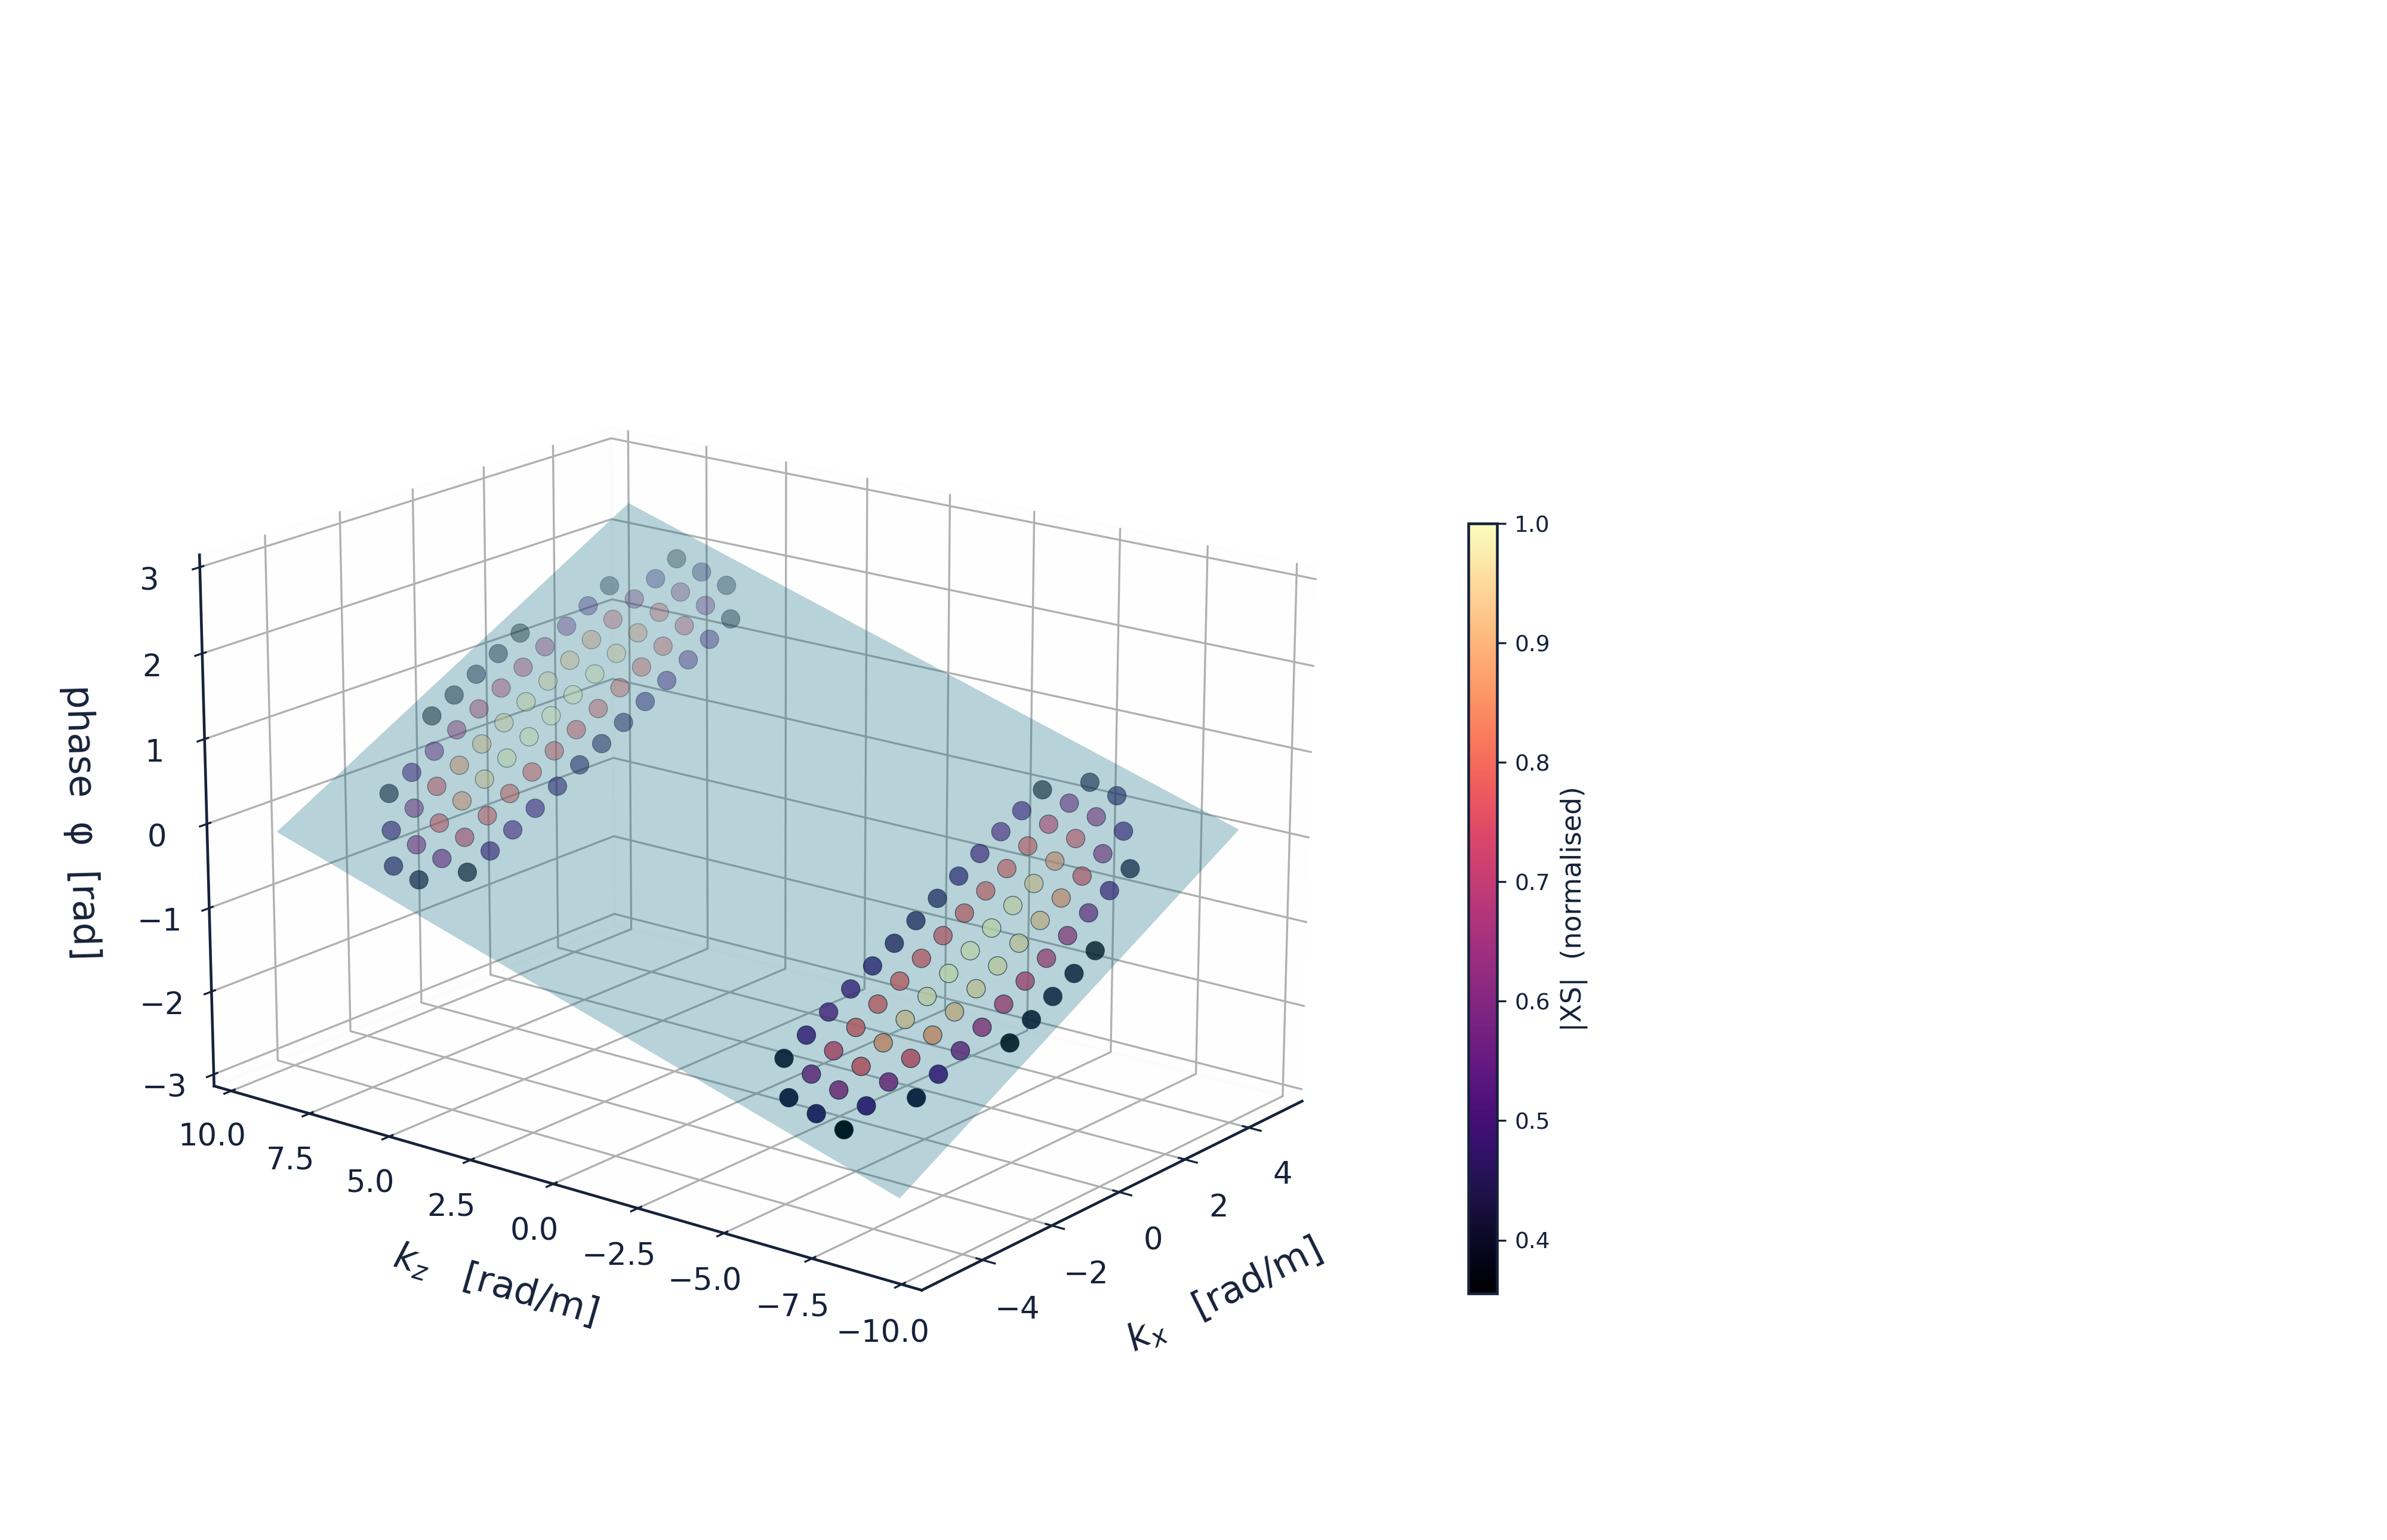

In [37]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (3D projection registration)
from scipy.ndimage import shift as nd_shift
import gpr_style as gs
from IPython.display import Image, display

gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics (see "Time-Lapse Cross-Spectrum I")
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX, DZ = 0.25 * LAMBDA, 0.125 * LAMBDA

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def migrate_point(x_src, z_src):
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated


mig_baseline = migrate_point(X0, Z0)
mig_monitor = nd_shift(mig_baseline, (DZ / dzg, DX / dxg), order=1,
                       mode='constant', cval=0.0)

GAMMA = 0.45
KC = 2 * np.pi / LAMBDA
taper = np.outer(np.hanning(nz), np.hanning(nx))
kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi / KC
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi / KC

KXg, KZg = np.meshgrid(kx_axis * KC, kz_axis * KC)
theta = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
sigma = 0.55 * KC / 2.3548
band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
            * 0.5 * (1.0 - np.tanh((theta - np.radians(40.0)) / np.radians(13.0))))


def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask


def mag_disp(a):
    m = np.abs(a)
    return (m / (m.max() + 1e-30)) ** GAMMA


B, M = spectrum_of(mig_baseline), spectrum_of(mig_monitor)
XS = B * np.conj(M)
absXS, phiXS = np.abs(XS), np.angle(XS)

# --- coherence mask: same 10%-of-peak gate as "Time-Lapse Cross-Spectrum IV" ---
THRESH = 0.10
mask = absXS > THRESH * absXS.max()
n_mask = int(mask.sum())

kx_pts, kz_pts, phi_pts, w_pts = KXg[mask], KZg[mask], phiXS[mask], absXS[mask]
color_pts = mag_disp(w_pts)

# --- weighted least-squares plane fit: phi = kz*dz_est + kx*dx_est + phi_0,
# same model/weighting as helper_functions.migration.wls_phase_plane_fit ---
A = np.column_stack([kz_pts, kx_pts, np.ones(n_mask)])
coeffs, *_ = np.linalg.lstsq(A * w_pts[:, None], phi_pts * w_pts, rcond=None)
dz_est, dx_est, phi0_est = coeffs
resid = phi_pts - (kz_pts * dz_est + kx_pts * dx_est + phi0_est)
resid_rms = float(np.sqrt(np.mean(resid ** 2)))

# ==========================================
# 2. Figure -- one 3D panel: the coherent (kx, kz, phi) point cloud plus the
#    fitted plane it was estimated from, and an info panel with the numbers.
# ==========================================
fig = plt.figure(figsize=(13.333, 8.6))


ax = fig.add_axes([0.02, 0.06, 0.58, 0.78], projection='3d')
ax.set_facecolor("white")

pad_x_, pad_z_ = 0.6, 0.6
kx_lo, kx_hi = kx_pts.min() - pad_x_, kx_pts.max() + pad_x_
kz_lo, kz_hi = kz_pts.min() - pad_z_, kz_pts.max() + pad_z_
kx_grid = np.linspace(kx_lo, kx_hi, 30)
kz_grid = np.linspace(kz_lo, kz_hi, 30)
KXs, KZs = np.meshgrid(kx_grid, kz_grid)
PHIs = KZs * dz_est + KXs * dx_est + phi0_est
ax.plot_surface(KXs, KZs, PHIs, color=gs.C_ACCENT, alpha=0.28,
                linewidth=0, antialiased=True, rstride=1, cstride=1, zorder=1)

sc = ax.scatter(kx_pts, kz_pts, phi_pts, c=color_pts, cmap='magma',
                s=55, edgecolors=gs.C_DARK, linewidths=0.3, depthshade=True,
                zorder=5)

ax.set_xlabel("$k_x$   [rad/m]", labelpad=14, fontsize=15)
ax.set_ylabel("$k_z$   [rad/m]", labelpad=14, fontsize=15)
ax.set_zlabel("phase  φ  [rad]", labelpad=8, fontsize=15)
ax.set_zlim(-np.pi, np.pi)
ax.set_box_aspect((1.15, 1.6, 1.0))
ax.view_init(elev=18, azim=-52 + 45 + 180 + 45)
ax.xaxis.pane.set_alpha(0.04)
ax.yaxis.pane.set_alpha(0.04)
ax.zaxis.pane.set_alpha(0.04)
ax.grid(True, alpha=0.25)

cax = fig.add_axes([0.615, 0.16, 0.012, 0.5])
cb = fig.colorbar(sc, cax=cax)
cb.set_label("|XS|  (normalised)", fontsize=11)
cb.ax.tick_params(labelsize=9)



fig.savefig('Animations/CrossSpectrum_5_PhasePlaneFit3D.png', dpi=300, facecolor="white")
print("Saved Animations/CrossSpectrum_5_PhasePlaneFit3D.png")
print(f"dz_est={dz_est:.5f} (true {DZ:.5f})  dx_est={dx_est:.5f} (true {DX:.5f})  "
      f"phi0_est={phi0_est:.5f}  resid_rms={resid_rms:.5f}  n_mask={n_mask}")
display(Image(filename='Animations/CrossSpectrum_5_PhasePlaneFit3D.png'))


Saved Animations/CrossSpectrum_5_PhasePlaneFit3D.png
dz_est=0.12589 (true 0.12500)   dx_est=0.24954 (true 0.25000)   phi0_est=-0.00000   resid_rms=0.00496   n_mask=146


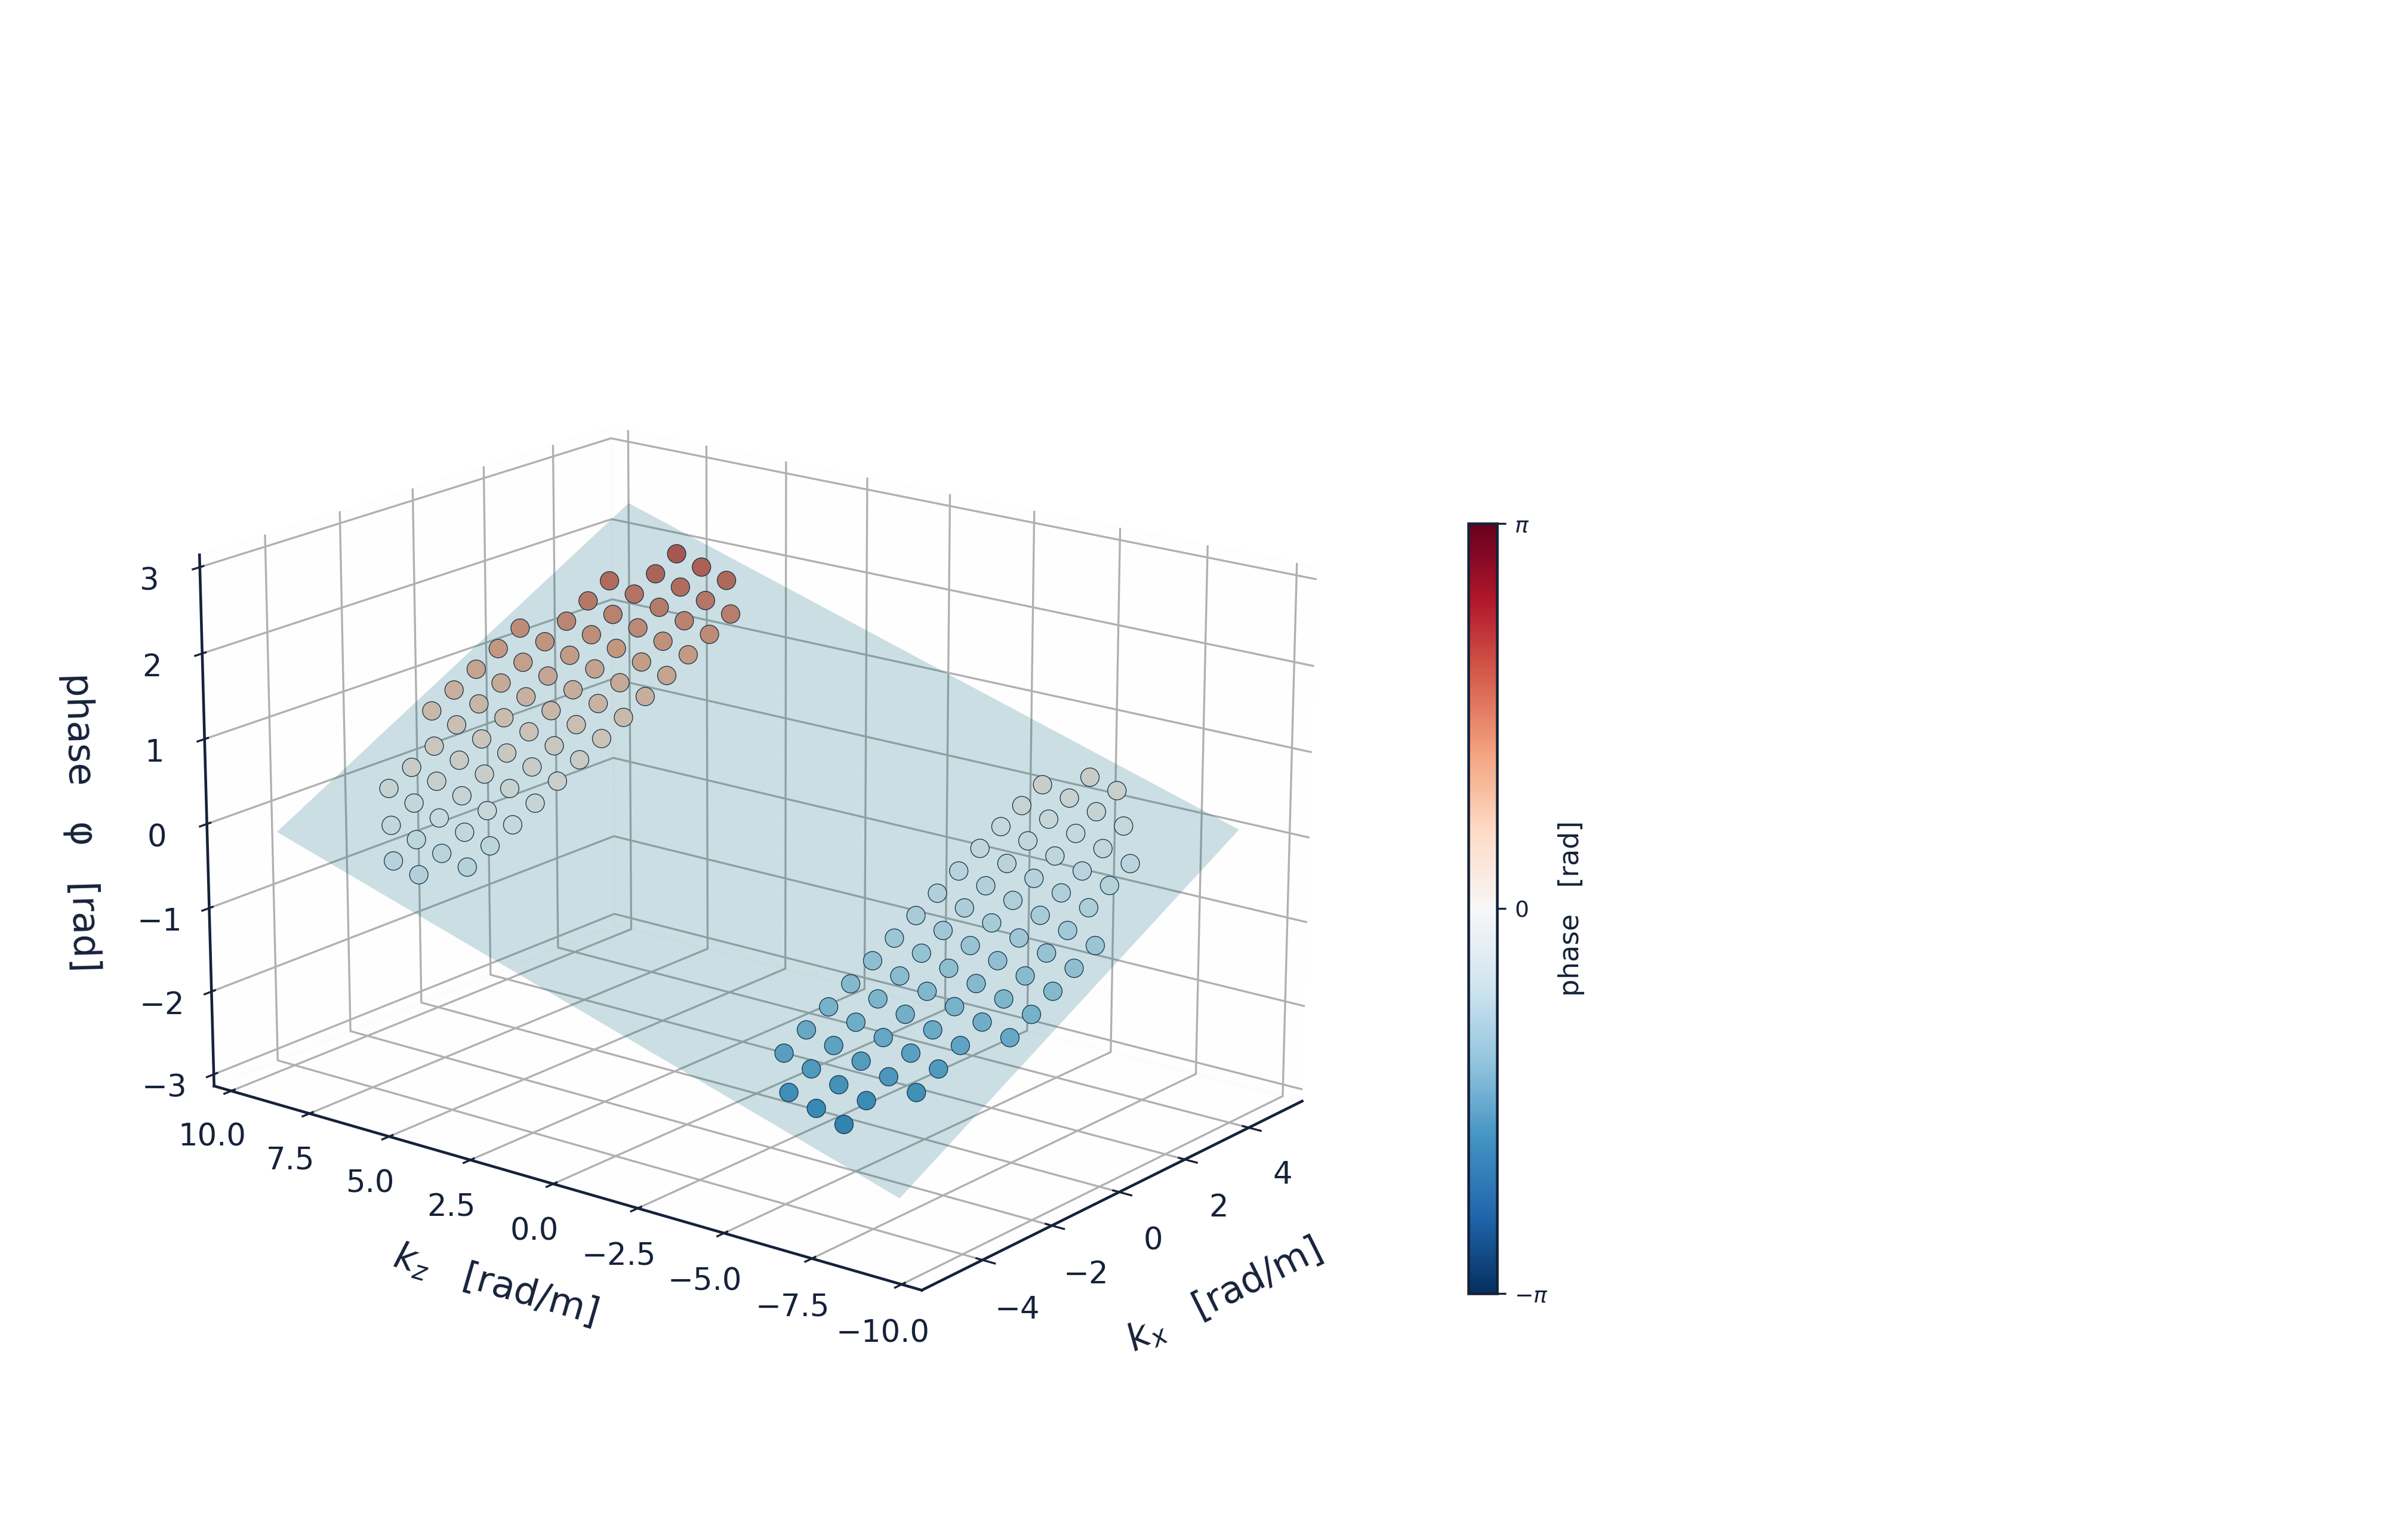

In [45]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (3D projection registration)
from scipy.ndimage import shift as nd_shift
import gpr_style as gs
from IPython.display import Image, display

gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics (see "Time-Lapse Cross-Spectrum I")
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX, DZ = 0.25 * LAMBDA, 0.125 * LAMBDA

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def migrate_point(x_src, z_src):
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated


mig_baseline = migrate_point(X0, Z0)
mig_monitor = nd_shift(mig_baseline, (DZ / dzg, DX / dxg), order=1,
                       mode='constant', cval=0.0)

GAMMA = 0.45
KC = 2 * np.pi / LAMBDA
taper = np.outer(np.hanning(nz), np.hanning(nx))
kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi / KC
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi / KC

KXg, KZg = np.meshgrid(kx_axis * KC, kz_axis * KC)
theta = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
sigma = 0.55 * KC / 2.3548
band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
             * 0.5 * (1.0 - np.tanh((theta - np.radians(40.0)) / np.radians(13.0))))


def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask


def mag_disp(a):
    m = np.abs(a)
    return (m / (m.max() + 1e-30)) ** GAMMA


B, M = spectrum_of(mig_baseline), spectrum_of(mig_monitor)
XS = B * np.conj(M)
absXS, phiXS = np.abs(XS), np.angle(XS)

# --- coherence mask: same 10%-of-peak gate as "Time-Lapse Cross-Spectrum IV" ---
THRESH = 0.10
mask = absXS > THRESH * absXS.max()
n_mask = int(mask.sum())

kx_pts, kz_pts, phi_pts, w_pts = KXg[mask], KZg[mask], phiXS[mask], absXS[mask]

# --- weighted least-squares plane fit: phi = kz*dz_est + kx*dx_est + phi_0 ---
A = np.column_stack([kz_pts, kx_pts, np.ones(n_mask)])
coeffs, *_ = np.linalg.lstsq(A * w_pts[:, None], phi_pts * w_pts, rcond=None)
dz_est, dx_est, phi0_est = coeffs
resid = phi_pts - (kz_pts * dz_est + kx_pts * dx_est + phi0_est)
resid_rms = float(np.sqrt(np.mean(resid ** 2)))

# ==========================================
# 2. Figure -- 3D panel with points explicitly shifted above the plane
# ==========================================
fig = plt.figure(figsize=(13.333, 8.6))

ax = fig.add_axes([0.02, 0.06, 0.58, 0.78], projection='3d')
ax.set_facecolor("white")

pad_x_, pad_z_ = 0.6, 0.6
kx_lo, kx_hi = kx_pts.min() - pad_x_, kx_pts.max() + pad_x_
kz_lo, kz_hi = kz_pts.min() - pad_z_, kz_pts.max() + pad_z_
kx_grid = np.linspace(kx_lo, kx_hi, 30)
kz_grid = np.linspace(kz_lo, kz_hi, 30)
KXs, KZs = np.meshgrid(kx_grid, kz_grid)
PHIs = KZs * dz_est + KXs * dx_est + phi0_est

# Fitted plane surface rendered at a lower zorder
ax.plot_surface(KXs, KZs, PHIs, color=gs.C_ACCENT, alpha=0.20,
                linewidth=0, antialiased=True, rstride=1, cstride=1, zorder=1)

# Scatter points colored by phase, shifted slightly upward in Z (+0.06) with depthshade disabled and high zorder
sc = ax.scatter(kx_pts, kz_pts, phi_pts + 0.06, c=phi_pts, cmap=gs.CMAP_PHASE,
                vmin=-np.pi, vmax=np.pi, s=55, edgecolors=gs.C_DARK, 
                linewidths=0.3, depthshade=False, zorder=10)

ax.set_xlabel("$k_x$   [rad/m]", labelpad=14, fontsize=15)
ax.set_ylabel("$k_z$   [rad/m]", labelpad=14, fontsize=15)
ax.set_zlabel("phase   φ   [rad]", labelpad=8, fontsize=15)
ax.set_zlim(-np.pi, np.pi)
ax.set_box_aspect((1.15, 1.6, 1.0))
ax.view_init(elev=18, azim=-52 + 45 + 180 + 45)
ax.xaxis.pane.set_alpha(0.04)
ax.yaxis.pane.set_alpha(0.04)
ax.zaxis.pane.set_alpha(0.04)
ax.grid(True, alpha=0.25)

cax = fig.add_axes([0.615, 0.16, 0.012, 0.5])
cb = fig.colorbar(sc, cax=cax)
cb.set_ticks([-np.pi, 0, np.pi])
cb.set_ticklabels([r'$-\pi$', '0', r'$\pi$'])
cb.set_label('phase   [rad]', fontsize=11)
cb.ax.tick_params(labelsize=9)

fig.savefig('Animations/CrossSpectrum_5_PhasePlaneFit3D.png', dpi=300, facecolor="white")
print("Saved Animations/CrossSpectrum_5_PhasePlaneFit3D.png")
print(f"dz_est={dz_est:.5f} (true {DZ:.5f})   dx_est={dx_est:.5f} (true {DX:.5f})   "
      f"phi0_est={phi0_est:.5f}   resid_rms={resid_rms:.5f}   n_mask={n_mask}")
display(Image(filename='Animations/CrossSpectrum_5_PhasePlaneFit3D.png'))

In [30]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from scipy.ndimage import shift as nd_shift
import gpr_style as gs

# Ensure output directory exists and setup style
Path("Animations").mkdir(parents=True, exist_ok=True)
gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX, DZ = 0.25 * LAMBDA, 0.125 * LAMBDA

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)

def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)

def migrate_point(x_src, z_src):
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated

mig_baseline = migrate_point(X0, Z0)
mig_monitor = nd_shift(mig_baseline, (DZ / dzg, DX / dxg), order=1,
                       mode='constant', cval=0.0)

GAMMA = 0.45
KC = 2 * np.pi / LAMBDA
taper = np.outer(np.hanning(nz), np.hanning(nx))
kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi / KC
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi / KC
extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

KXg, KZg = np.meshgrid(kx_axis * KC, kz_axis * KC)
theta = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
sigma = 0.55 * KC / 2.3548
band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
             * 0.5 * (1.0 - np.tanh((theta - np.radians(40.0)) / np.radians(13.0))))

def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask

def mag_disp(a):
    m = np.abs(a)
    return (m / (m.max() + 1e-30)) ** GAMMA

def ease(p):
    return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))

B, M = spectrum_of(mig_baseline), spectrum_of(mig_monitor)
XS = B * np.conj(M)
absXS, phiXS = np.abs(XS), np.angle(XS)
dispXS = mag_disp(absXS)

# ==========================================
# 2. Extract Data & Fit 3D Plane
# ==========================================
THRESH = 0.05
mask = absXS > THRESH * absXS.max()
n_mask = int(mask.sum())

# Raw (unscaled) rad/m values used for the math fit
kx_pts_raw, kz_pts_raw = KXg[mask], KZg[mask]
phi_pts, w_pts = phiXS[mask], absXS[mask]

# Weighted least-squares plane fit
A = np.column_stack([kz_pts_raw, kx_pts_raw, np.ones(n_mask)])
coeffs, *_ = np.linalg.lstsq(A * w_pts[:, None], phi_pts * w_pts, rcond=None)
dz_est, dx_est, phi0_est = coeffs

# Scaled values (divided by KC) for plotting within the [-2.2, 2.2] domain
kx_pts_c = kx_pts_raw / KC
kz_pts_c = kz_pts_raw / KC

# Generate 3D Surface grid in scaled units
pad_c = 0.6
kx_lo, kx_hi = kx_pts_c.min() - pad_c, kx_pts_c.max() + pad_c
kz_lo, kz_hi = kz_pts_c.min() - pad_c, kz_pts_c.max() + pad_c
kx_grid_c = np.linspace(kx_lo, kx_hi, 30)
kz_grid_c = np.linspace(kz_lo, kz_hi, 30)
KXs_c, KZs_c = np.meshgrid(kx_grid_c, kz_grid_c)

# Calculate phase heights using the exact raw units for the plane equation
PHIs = (KZs_c * KC) * dz_est + (KXs_c * KC) * dx_est + phi0_est

# ==========================================
# 3. Figure Setup (2D Left, 3D Right)
# ==========================================
fig = plt.figure(figsize=(15, 7.5))
fig.subplots_adjust(top=0.85, bottom=0.12, left=0.05, right=0.92, wspace=0.2)

# Left Panel (2D Amplitude)
ax1 = fig.add_subplot(1, 2, 1)
K_VIEW = 2.2
ax1.set_xlim(-K_VIEW, K_VIEW)
ax1.set_ylim(-K_VIEW, K_VIEW)
ax1.set_xticks([-2, -1, 0, 1, 2])
ax1.set_yticks([-2, -1, 0, 1, 2])
ax1.set_xlabel(r'$k_x$   [$k_c$]', size=18)
ax1.set_ylabel(r'$k_z$   [$k_c$]', size=18)
ax1.set_title(r'(a)  $|XS(k_x,k_z)|$   --   amplitude', color=gs.C_DARK, pad=14, fontsize=20)
ax1.set_aspect('equal')
im1 = ax1.imshow(dispXS, cmap='magma', extent=extent_k, vmin=0, vmax=1, interpolation='bilinear')

# Right Panel (3D Phase)
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.set_facecolor("white")
ax2.set_xlim(-K_VIEW, K_VIEW)
ax2.set_ylim(-K_VIEW, K_VIEW)
ax2.set_zlim(-np.pi, np.pi)

# Explicitly space out the ticks so numbers don't overlap, and add padding
ax2.set_xticks([-2, -1, 0, 1, 2])
ax2.set_yticks([-2, -1, 0, 1, 2])
ax2.tick_params(axis='x', pad=8)
ax2.tick_params(axis='y', pad=8)
ax2.tick_params(axis='z', pad=8)

# Set an Orthographic projection so the top-down 2D view has no perspective distortion
ax2.set_proj_type('ortho')

ax2.set_xlabel(r"$k_x$   [$k_c$]", labelpad=16, fontsize=15)
ax2.set_ylabel(r"$k_z$   [$k_c$]", labelpad=16, fontsize=15)
ax2.set_zlabel(r"phase   $\phi$   [rad]", labelpad=12, fontsize=15)
ax2.set_title(r'(b)  $\angle\,XS(k_x,k_z)$   --   phase & plane fit', color=gs.C_DARK, pad=14, fontsize=20)

# Set 1:1 XY footprint so it looks perfectly square from top-down
ax2.set_box_aspect((1, 1, 0.8))

ax2.xaxis.pane.set_alpha(0.05)
ax2.yaxis.pane.set_alpha(0.05)
ax2.zaxis.pane.set_alpha(0.05)
ax2.grid(True, alpha=0.3)

# Scatter points: disabled depthshade and forced zorder=10 so they sit strictly on top of the plane
sc = ax2.scatter(kx_pts_c, kz_pts_c, -np.pi * np.ones_like(phi_pts), 
                 c=phi_pts, cmap=gs.CMAP_PHASE, vmin=-np.pi, vmax=np.pi, 
                 s=40, marker='s', edgecolors='none', depthshade=False, zorder=10)

# Colorbar for Phase
cax = fig.add_axes([0.93, 0.2, 0.015, 0.6])
cb = fig.colorbar(sc, cax=cax)
cb.set_ticks([-np.pi, 0, np.pi])
cb.set_ticklabels([r'$-\pi$', '0', r'$\pi$'])
cb.set_label('phase   [rad]', fontsize=14)
cb.ax.tick_params(labelsize=12)

# Set initial top-down view (looks perfectly 2D)
START_ELEV, START_AZIM = 90, -90
END_ELEV, END_AZIM = 8, 52 + 180
ax2.view_init(elev=START_ELEV, azim=START_AZIM)

# Container to hold the surface reference so we can redraw it with changing alpha
surf_ref = [None]

# ==========================================
# 4. Animation Timeline
# ==========================================
FPS = 15
N_HOLD_2D = 30
N_ORBIT = 75
N_PLANE_FADE = 30
N_HOLD_3D = 45
BOUNDS = np.cumsum([N_HOLD_2D, N_ORBIT, N_PLANE_FADE, N_HOLD_3D])
num_frames = BOUNDS[-1]

def update(frame):
    # Determine states based on frame
    if frame < BOUNDS[0]:
        elev, azim = START_ELEV, START_AZIM
        plane_alpha = 0.0
        z_extrude = 0.0
    elif frame < BOUNDS[1]:
        u = ease((frame - BOUNDS[0]) / (N_ORBIT - 1))
        elev = START_ELEV + u * (END_ELEV - START_ELEV)
        azim = START_AZIM + u * (END_AZIM - START_AZIM)
        plane_alpha = 0.0
        z_extrude = u
    elif frame < BOUNDS[2]:
        elev, azim = END_ELEV, END_AZIM
        u = ease((frame - BOUNDS[1]) / (N_PLANE_FADE - 1))
        plane_alpha = u * 0.28
        z_extrude = 1.0
    else:
        elev, azim = END_ELEV, END_AZIM
        plane_alpha = 0.28
        z_extrude = 1.0

    # Apply camera orbit
    ax2.view_init(elev=elev, azim=azim)
    
    # Animate points extruding from the bottom floor (-np.pi) up to their true phase values
    current_z = -np.pi + z_extrude * (phi_pts - (-np.pi))
    sc._offsets3d = (kx_pts_c, kz_pts_c, current_z)

    # Apply plane fade-in (drawn with low zorder=1 so it stays strictly behind the scatter points)
    if surf_ref[0] is not None:
        surf_ref[0].remove()
        surf_ref[0] = None

    if plane_alpha > 0.01:
        surf_ref[0] = ax2.plot_surface(KXs_c, KZs_c, PHIs, color=gs.C_ACCENT, 
                                       alpha=plane_alpha, linewidth=0, antialiased=True, zorder=1)

    return ax1, ax2

ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering 2D to 3D phase-plane transition...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/CrossSpectrum_Transition_2Dto3D.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()

Rendering 2D to 3D phase-plane transition...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\577171762.py:247: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [ ]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from scipy.ndimage import shift as nd_shift
import gpr_style as gs

# Ensure output directory exists and setup style
Path("Animations").mkdir(parents=True, exist_ok=True)
gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX, DZ = 0.25 * LAMBDA, 0.125 * LAMBDA

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)

def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)

def migrate_point(x_src, z_src):
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated

mig_baseline = migrate_point(X0, Z0)
mig_monitor = nd_shift(mig_baseline, (DZ / dzg, DX / dxg), order=1,
                       mode='constant', cval=0.0)

GAMMA = 0.45
KC = 2 * np.pi / LAMBDA
taper = np.outer(np.hanning(nz), np.hanning(nx))
kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi / KC
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi / KC
extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

KXg, KZg = np.meshgrid(kx_axis * KC, kz_axis * KC)
theta = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
sigma = 0.55 * KC / 2.3548
band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
             * 0.5 * (1.0 - np.tanh((theta - np.radians(40.0)) / np.radians(13.0))))

def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask

def mag_disp(a):
    m = np.abs(a)
    return (m / (m.max() + 1e-30)) ** GAMMA

def ease(p):
    return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))

B, M = spectrum_of(mig_baseline), spectrum_of(mig_monitor)
XS = B * np.conj(M)
absXS, phiXS = np.abs(XS), np.angle(XS)
dispXS = mag_disp(absXS)

# ==========================================
# 2. Extract Data & Fit 3D Plane
# ==========================================
THRESH = 0.10
mask = absXS > THRESH * absXS.max()
n_mask = int(mask.sum())

kx_pts, kz_pts, phi_pts, w_pts = KXg[mask], KZg[mask], phiXS[mask], absXS[mask]

# Weighted least-squares plane fit
A = np.column_stack([kz_pts, kx_pts, np.ones(n_mask)])
coeffs, *_ = np.linalg.lstsq(A * w_pts[:, None], phi_pts * w_pts, rcond=None)
dz_est, dx_est, phi0_est = coeffs

pad_x_, pad_z_ = 0.6, 0.6
kx_lo, kx_hi = kx_pts.min() - pad_x_, kx_pts.max() + pad_x_
kz_lo, kz_hi = kz_pts.min() - pad_z_, kz_pts.max() + pad_z_
kx_grid = np.linspace(kx_lo, kx_hi, 30)
kz_grid = np.linspace(kz_lo, kz_hi, 30)
KXs, KZs = np.meshgrid(kx_grid, kz_grid)
PHIs = KZs * dz_est + KXs * dx_est + phi0_est

# ==========================================
# 3. Figure Setup (2D Left, 3D Right)
# ==========================================
fig = plt.figure(figsize=(15, 7.5))
fig.subplots_adjust(top=0.85, bottom=0.12, left=0.05, right=0.92, wspace=0.2)

# Left Panel (2D Amplitude)
ax1 = fig.add_subplot(1, 2, 1)
ax1.set_xlabel(r'$k_x$   [$k_c$]', size=18)
ax1.set_ylabel(r'$k_z$   [$k_c$]', size=18)
ax1.set_title(r'(a)  $|XS(k_x,k_z)|$   --   amplitude', color=gs.C_DARK, pad=14, fontsize=20)
ax1.set_aspect('equal')
im1 = ax1.imshow(dispXS, cmap='magma', extent=extent_k, vmin=0, vmax=1, interpolation='bilinear')

# Right Panel (3D Phase)
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.set_facecolor("white")
ax2.set_zlim(-np.pi, np.pi)

ax2.set_xlabel("$k_x$   [rad/m]", labelpad=14, fontsize=15)
ax2.set_ylabel("$k_z$   [rad/m]", labelpad=14, fontsize=15)
ax2.set_zlabel("phase   φ   [rad]", labelpad=8, fontsize=15)

# Increased tick padding to prevent tick label overlap with axes
ax2.tick_params(axis='x', pad=12)
ax2.tick_params(axis='y', pad=12)
ax2.tick_params(axis='z', pad=8)

ax2.set_box_aspect((1.15, 1.6, 1.0))

ax2.xaxis.pane.set_alpha(0.04)
ax2.yaxis.pane.set_alpha(0.04)
ax2.zaxis.pane.set_alpha(0.04)
ax2.grid(True, alpha=0.25)

sc = ax2.scatter(kx_pts, kz_pts, -np.pi * np.ones_like(phi_pts), 
                 c=phi_pts, cmap=gs.CMAP_PHASE, vmin=-np.pi, vmax=np.pi, 
                 s=55, edgecolors=gs.C_DARK, linewidths=0.3, depthshade=False, zorder=10)

cax = fig.add_axes([0.93, 0.2, 0.015, 0.6])
cb = fig.colorbar(sc, cax=cax)
cb.set_ticks([-np.pi, 0, np.pi])
cb.set_ticklabels([r'$-\pi$', '0', r'$\pi$'])
cb.set_label('phase   [rad]', fontsize=11)
cb.ax.tick_params(labelsize=9)

START_ELEV, START_AZIM = 90, -90
END_ELEV, END_AZIM = 18, -52 + 45 + 180 + 45
ax2.view_init(elev=START_ELEV, azim=START_AZIM)

surf_ref = [None]

# ==========================================
# 4. Animation Timeline (Optimized with a pause before plane drawing)
# ==========================================
FPS = 30
N_HOLD_2D = 15
N_ORBIT = 40
N_PAUSE_BEFORE_PLANE = 30  # Longer pause after angle move and before drawing the plane
N_PLANE_FADE = 15
N_HOLD_3D = 25
BOUNDS = np.cumsum([N_HOLD_2D, N_ORBIT, N_PAUSE_BEFORE_PLANE, N_PLANE_FADE, N_HOLD_3D])
num_frames = BOUNDS[-1]

def update(frame):
    if frame < BOUNDS[0]:
        elev, azim = START_ELEV, START_AZIM
        plane_alpha = 0.0
        z_extrude = 0.0
    elif frame < BOUNDS[1]:
        u = ease((frame - BOUNDS[0]) / (N_ORBIT - 1))
        elev = START_ELEV + u * (END_ELEV - START_ELEV)
        azim = START_AZIM + u * (END_AZIM - START_AZIM)
        plane_alpha = 0.0
        z_extrude = u
    elif frame < BOUNDS[2]:
        # Pause state after rotation completion
        elev, azim = END_ELEV, END_AZIM
        plane_alpha = 0.0
        z_extrude = 1.0
    elif frame < BOUNDS[3]:
        # Plane fade-in phase
        elev, azim = END_ELEV, END_AZIM
        u = ease((frame - BOUNDS[2]) / (N_PLANE_FADE - 1))
        plane_alpha = u * 0.20
        z_extrude = 1.0
    else:
        # Final hold state
        elev, azim = END_ELEV, END_AZIM
        plane_alpha = 0.20
        z_extrude = 1.0

    ax2.view_init(elev=elev, azim=azim)
    
    current_z = -np.pi + z_extrude * ((phi_pts + 0.06) - (-np.pi))
    sc._offsets3d = (kx_pts, kz_pts, current_z)

    if surf_ref[0] is not None:
        surf_ref[0].remove()
        surf_ref[0] = None

    if plane_alpha > 0.01:
        surf_ref[0] = ax2.plot_surface(KXs, KZs, PHIs, color=gs.C_ACCENT, 
                                       alpha=plane_alpha, linewidth=0, antialiased=True, zorder=1)

    return im1, ax2

ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering high-framerate 3D phase-plane transition...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/CrossSpectrum_Transition_2Dto3D.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()

Rendering high-framerate 3D phase-plane transition...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\1739510180.py:224: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Time-Lapse Monitoring I

In [ ]:
# import sys
# sys.path.insert(0, "Defense_Deck/animations")
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.animation import FuncAnimation, FFMpegWriter
# from scipy.ndimage import shift as nd_shift
# import gpr_style as gs

# gs.apply_house_style(base=15)

# # ==========================================
# # 1. Shared physics (see "Time-Lapse Cross-Spectrum I")
# # ==========================================
# LAMBDA = 1.0
# V, FC = 0.10, 0.10
# X0, Z0 = 5.0, 4.0
# DX0, DZ0 = 0.25 * LAMBDA, 0.125 * LAMBDA  # worked-example direction (diagonal)
# THETA = np.arctan2(DZ0, DX0)              # motion direction stays fixed

# nx, nz = 300, 300
# x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
# dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
# t_max, nt = 160, 400
# time_axis = np.linspace(0, t_max, nt)
# dt = time_axis[1] - time_axis[0]

# v_mig = V / 2
# pad_t, pad_x = nt, nx // 2
# nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
# KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
# omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
# kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
# kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
# phase_step = np.exp(1j * kz_fk * dzg)


# def ricker(t, f):
#     return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


# def migrate_point(x_src, z_src):
#     """Gazdag (f-k) migration of a single point scatterer."""
#     b_scan = np.zeros((nt, nx))
#     for i, x in enumerate(x_pos):
#         dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
#         b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
#     b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
#     P_fk = np.fft.fft2(b_padded)
#     migrated = np.zeros((nz, nx))
#     phase = np.ones_like(kz_fk, dtype=complex)
#     for iz in range(nz):
#         row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
#         migrated[iz, :] = row[pad_x:pad_x + nx]
#         phase *= phase_step
#     return migrated


# mig_baseline = migrate_point(X0, Z0)
# vmax_m = np.abs(mig_baseline).max() * 0.85


# def migrated_shift(dx, dz):
#     """Migrated monitor image for an arbitrary (dx, dz).

#     Migration is linear and shift-invariant here, so the monitor's migrated
#     PSF is just the baseline PSF translated -- no need to re-run Gazdag.
#     """
#     return nd_shift(mig_baseline, (dz / dzg, dx / dxg),
#                     order=1, mode='constant', cval=0.0)


# # --- wavenumber spectra, softly band-limited around k_c and the migration's
# # own aperture (the coherence band the cross-spectrum estimator trusts) ---
# KC = 2 * np.pi / LAMBDA
# taper = np.outer(np.hanning(nz), np.hanning(nx))
# kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi / KC
# kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi / KC
# extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

# KXg, KZg = np.meshgrid(kx_axis * KC, kz_axis * KC)
# theta_ap = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
# sigma = 0.55 * KC / 2.3548
# band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
#             * 0.5 * (1.0 - np.tanh((theta_ap - np.radians(40.0)) / np.radians(13.0))))


# def spectrum_of(img):
#     return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask


# B = spectrum_of(mig_baseline)


# def fit_plane(phi, weight, mask):
#     """Weighted least-squares fit of phi = kz*dz + kx*dx + c."""
#     kzf, kxf, wf = KZg[mask], KXg[mask], weight[mask]
#     A = np.column_stack([kzf, kxf, np.ones_like(kzf)])
#     sol, *_ = np.linalg.lstsq(A * wf[:, None], phi[mask] * wf, rcond=None)
#     return sol[1], sol[0]  # est_dx, est_dz


# # --- error-sweep panel: the same log-log "flat, then a cliff" readout as
# # Defense_Deck's anim4_kdomain_phase_ramp.py, ported to this notebook's style
# ERR_THRESHOLD = 5.0
# LAM_TICKS = [1 / 64, 1 / 32, 1 / 16, 1 / 8, 1 / 4, 1 / 2]
# LAM_LABELS = ["Â¹â„â‚†â‚„Î»", "Â¹â„â‚ƒâ‚‚Î»", "Â¹â„â‚â‚†Î»", "â…›Î»", "Â¼Î»", "Â½Î»"]


# def make_error_panel(ax, shift_min, shift_max):
#     ax.set_title('(d)  Estimate error across the sweep', color=gs.C_DARK, pad=14, fontsize=20)
#     ax.set_xscale('log')
#     ax.set_yscale('log')
#     ax.set_xlim(shift_min / LAMBDA * 0.85, shift_max / LAMBDA * 1.18)
#     ax.set_ylim(1e-3, 3e2)
#     ax.set_xlabel('true displacement   [Î»]', size=17)
#     ax.set_ylabel('|error|   [% of true]', size=17)
#     ax.set_facecolor(gs.C_PANEL)
#     ax.set_xticks(LAM_TICKS)
#     ax.set_xticklabels(LAM_LABELS, fontsize=11)
#     ax.tick_params(axis='x', which='minor', bottom=False)
#     ax.grid(True, which='major', color='white', lw=1.0, alpha=0.9)
#     ax.axhline(ERR_THRESHOLD, color=gs.C_GREY, ls='--', lw=1.6, zorder=2)
#     ax.text(shift_max / LAMBDA * 1.10, ERR_THRESHOLD * 1.4,
#             f'{ERR_THRESHOLD:.0f}% threshold', fontsize=10.5, color=gs.C_GREY,
#             va='bottom', ha='right')


# # ==========================================
# # 2. Figure setup -- (a) migrated image, (b) cross-spectrum phase,
# #    (c) the 1-D fit that recovers the lateral slope, (d) error sweep
# # ==========================================
# fig = plt.figure(figsize=gs.FIGSIZE)
# grid = fig.add_gridspec(2, 2, left=0.065, right=0.93, top=0.82, bottom=0.09,
#                         wspace=0.34, hspace=0.62)
# ax_a = fig.add_subplot(grid[0, 0])
# ax_b = fig.add_subplot(grid[0, 1])
# ax_c = fig.add_subplot(grid[1, 0])
# ax_d = fig.add_subplot(grid[1, 1])

# zoom, K_VIEW = 1.0 * LAMBDA, 2.2

# # --- panel (a): migrated image, diagonal motion arrow ---
# ax_a.set_xlim(X0 - zoom, X0 + zoom)
# ax_a.set_ylim(Z0 + zoom, Z0 - zoom)
# ax_a.set_xlabel('x  [m]', size=17)
# ax_a.set_ylabel('z  [m]', size=17)
# ax_a.set_title('(a)  Migrated monitor image', color=gs.C_DARK, pad=14, fontsize=20)
# im_a = ax_a.imshow(mig_baseline, aspect='auto', cmap=gs.CMAP_IMG,
#                    extent=[0, 10, 8, 0], vmin=-vmax_m, vmax=vmax_m,
#                    interpolation='bilinear')
# ax_a.plot([X0], [Z0], '+', color=gs.C_DARK, markersize=15, markeredgewidth=2.5, zorder=5)
# arrow = ax_a.annotate('', xy=(X0, Z0), xytext=(X0, Z0),
#                       arrowprops=dict(arrowstyle='-|>', lw=2.8, color=gs.C_WARM), zorder=6)

# # --- panel (b): cross-spectrum phase, masked by coherence ---
# ax_b.set_xlim(-K_VIEW, K_VIEW)
# ax_b.set_ylim(-K_VIEW, K_VIEW)
# ax_b.set_facecolor(gs.C_PANEL)
# ax_b.set_xlabel('$k_x$   [$k_c$]', size=17)
# ax_b.set_ylabel('$k_z$   [$k_c$]', size=17)
# ax_b.set_title('(b)  Cross-spectrum phase', color=gs.C_DARK, pad=14, fontsize=20)
# im_b = ax_b.imshow(np.zeros((nz, nx, 4)), aspect='auto', extent=extent_k,
#                    origin='lower', interpolation='nearest')
# ax_b.axhline(0, color=gs.C_GREY, lw=0.7, zorder=4)
# ax_b.axvline(0, color=gs.C_GREY, lw=0.7, zorder=4)

# box_b = ax_b.get_position()
# cax = fig.add_axes([box_b.x1 + 0.012, box_b.y0, 0.012, box_b.height])
# cb = fig.colorbar(plt.cm.ScalarMappable(cmap=gs.CMAP_PHASE,
#                                         norm=plt.Normalize(-np.pi, np.pi)), cax=cax)
# cb.set_ticks([-np.pi, 0, np.pi])
# cb.set_ticklabels(['$-\\pi$', '0', '$\\pi$'])
# cb.ax.tick_params(labelsize=10.5)

# # --- panel (c): 1-D fit along k_x (lateral) ---
# ax_c.set_xlim(-K_VIEW, K_VIEW)
# ax_c.set_ylim(-np.pi * 1.08, np.pi * 1.08)
# ax_c.set_facecolor(gs.C_PANEL)
# ax_c.set_xlabel('$k_x$   [$k_c$]', size=17)
# ax_c.set_ylabel('phase, $k_z$-term removed  [rad]', size=13.5)
# ax_c.set_title('(c)  Fit the slope along $k_x$', color=gs.C_DARK, pad=14, fontsize=20)
# ax_c.axhline(0, color=gs.C_GREY, lw=0.8)
# ax_c.set_yticks([-np.pi, 0, np.pi])
# ax_c.set_yticklabels(['$-\\pi$', '0', '$\\pi$'])
# (ln_fit,) = ax_c.plot([], [], color=gs.C_WARM, lw=3.2, zorder=3,
#                       label='weighted least-squares fit')
# sc = ax_c.scatter([], [], s=24, c=[], cmap='viridis', vmin=0, vmax=1,
#                   alpha=0.9, zorder=5, edgecolors='none',
#                   label='cross-spectrum phase points')
# ax_c.legend(loc='lower right', fontsize=9.5)
# cb2 = fig.colorbar(sc, ax=ax_c, fraction=0.055, pad=0.03)
# cb2.set_label('fit weight  |XS|', fontsize=11)

# # --- panel (d): error sweep, accumulating live ---
# SHIFT_MIN, SHIFT_MAX = LAMBDA / 64, LAMBDA / 2
# make_error_panel(ax_d, SHIFT_MIN, SHIFT_MAX)
# (ln_err,) = ax_d.plot([], [], color=gs.C_ACCENT, lw=3.0, zorder=6,
#                       label='diagonal shift, |d|')
# (mk_err,) = ax_d.plot([], [], 'o', color=gs.C_ACCENT, ms=8, zorder=7)
# ax_d.legend(loc='lower right', fontsize=10.5)

# caption_true = fig.text(0.5, 0.955, '', ha='center', va='top', fontsize=15,
#                         fontweight='bold', color=gs.C_DARK, family='DejaVu Sans Mono')
# caption_est = fig.text(0.5, 0.918, '', ha='center', va='top', fontsize=15,
#                        fontweight='bold', color=gs.C_ACCENT, family='DejaVu Sans Mono')

# # ==========================================
# # 3. Timeline: geometric sweep of a DIAGONAL displacement (lateral and
# #    vertical grow together, along the fixed worked-example direction),
# #    from 1/64 lambda to 1/2 lambda -- the same ladder anim4 sweeps, so the
# #    error panel's "flat, then a cliff" behaviour shows up authentically.
# # ==========================================
# FPS = 15
# N_SWEEP, N_HOLD = 100, 45
# shifts = np.geomspace(SHIFT_MIN, SHIFT_MAX, N_SWEEP)
# shifts = np.concatenate([shifts, np.repeat(shifts[-1], N_HOLD)])
# num_frames = len(shifts)

# hist_d, hist_e = [], []


# def update(frame):
#     d = shifts[frame]
#     if frame == 0:
#         hist_d.clear(); hist_e.clear()
#     dx, dz = d * np.cos(THETA), d * np.sin(THETA)

#     mig_mon = migrated_shift(dx, dz)
#     M = spectrum_of(mig_mon)
#     XS = B * np.conj(M)
#     absXS, phi = np.abs(XS), np.angle(XS)
#     mask = absXS > 0.20 * absXS.max()
#     est_dx, est_dz = fit_plane(phi, absXS, mask)

#     # panel (a)
#     im_a.set_data(mig_mon)
#     arrow.xy = (X0 + dx, Z0 + dz)
#     caption_true.set_text(f'true       Î”x = {dx/LAMBDA:6.3f} Î»    Î”z = {dz/LAMBDA:6.3f} Î»')
#     caption_est.set_text(f'recovered  Î”x = {est_dx/LAMBDA:6.3f} Î»    Î”z = {est_dz/LAMBDA:6.3f} Î»')

#     # panel (b)
#     cmap = plt.get_cmap(gs.CMAP_PHASE)
#     rgba = cmap((phi + np.pi) / (2 * np.pi))
#     rgba[..., 3] = np.where(mask, 1.0, 0.05)
#     im_b.set_data(rgba)

#     # panel (c): project out the kz*dz term, fit the kx slope
#     resid = phi[mask] - KZg[mask] * est_dz
#     kax = KXg[mask] / KC
#     w = absXS[mask]
#     w = w / (w.max() + 1e-30)
#     sc.set_offsets(np.column_stack([kax, resid]))
#     sc.set_array(w)
#     if kax.size:
#         kk = np.linspace(kax.min(), kax.max(), 60)
#     else:
#         kk = np.linspace(-1, 1, 60)
#     ln_fit.set_data(kk, est_dx * kk * KC)

#     # panel (d): magnitude error, accumulating live
#     true_mag = d / LAMBDA
#     est_mag = np.hypot(est_dx, est_dz) / LAMBDA
#     err_pct = max(abs(est_mag - true_mag) / true_mag * 100.0, 1e-3)
#     hist_d.append(true_mag)
#     hist_e.append(err_pct)
#     ln_err.set_data(hist_d, hist_e)
#     mk_err.set_data([hist_d[-1]], [hist_e[-1]])

#     return (im_a, arrow, im_b, sc, ln_fit, ln_err, mk_err,
#             caption_true, caption_est)


# ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
#                     interval=1000 // FPS, repeat=False)

# print("Rendering time-lapse monitoring: diagonal shift -> phase-plane fit -> error sweep...")
# writer = FFMpegWriter(fps=FPS, bitrate=8000)
# ani.save('Animations/TimeLapseMonitoring_DiagonalPhaseFit.mp4', writer=writer, dpi=300)
# print("Export complete.")

# plt.show()


Rendering time-lapse monitoring: diagonal shift -> phase-plane fit -> error sweep...


Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_22960\1344078576.py:281: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [5]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from scipy.ndimage import shift as nd_shift
import gpr_style as gs

warnings.filterwarnings('ignore', message='No contour levels were found')
gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics (see "Time-Lapse Cross-Spectrum I")
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def migrate_point(x_src, z_src):
    """Gazdag (f-k) migration of a single point scatterer."""
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated


mig_baseline = migrate_point(X0, Z0)


def migrated_shift(dx, dz):
    """Migrated monitor image for an arbitrary (dx, dz).

    Migration is linear and shift-invariant here, so the monitor's migrated
    PSF is just the baseline PSF translated -- no need to re-run Gazdag.
    """
    return nd_shift(mig_baseline, (dz / dzg, dx / dxg),
                    order=1, mode='constant', cval=0.0)


# --- wavenumber spectra, softly band-limited around k_c and the migration's
# own aperture (the coherence band the cross-spectrum estimator trusts) ---
KC = 2 * np.pi / LAMBDA
taper = np.outer(np.hanning(nz), np.hanning(nx))
kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi / KC
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi / KC
extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

KXg, KZg = np.meshgrid(kx_axis * KC, kz_axis * KC)
theta_ap = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
sigma = 0.55 * KC / 2.3548
band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
            * 0.5 * (1.0 - np.tanh((theta_ap - np.radians(40.0)) / np.radians(13.0))))


def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask


B = spectrum_of(mig_baseline)


def fit_plane(phi, weight, mask):
    """Weighted least-squares fit of phi = kz*dz + kx*dx + c."""
    kzf, kxf, wf = KZg[mask], KXg[mask], weight[mask]
    A = np.column_stack([kzf, kxf, np.ones_like(kzf)])
    sol, *_ = np.linalg.lstsq(A * wf[:, None], phi[mask] * wf, rcond=None)
    return sol[1], sol[0]  # est_dx, est_dz


def clear_contour(c):
    """Remove a previous frame's contour artist, old- or new-style matplotlib."""
    if c is None:
        return
    try:
        c.remove()
    except (AttributeError, NotImplementedError):
        for coll in getattr(c, 'collections', []):
            coll.remove()


SHIFT_MIN, SHIFT_MAX = LAMBDA / 64, LAMBDA / 2
K_VIEW = 2.2
AMP_THRESH = 0.20  # fraction of peak |cross-spectrum| the lime outline traces

# ==========================================
# 2. Figure -- point scatterer | cross-spectrum phase | 1-D fit, with the
#    true/recovered readout centered above the row (it used to sit inside
#    the phase panel and collide with the phase image).
# ==========================================
fig = plt.figure(figsize=gs.FIGSIZE)
gs.slide_title(fig, 'Lateral motion tilts the phase along $k_x$',
               'Displacement swept from 1/2 λ down to 1/64 λ')
gs.footnote(fig, f'lime outline: |cross-spectrum| above {AMP_THRESH:.0%} of peak amplitude')

grid = fig.add_gridspec(1, 3, left=0.055, right=0.90, top=0.72, bottom=0.12, wspace=0.55)
ax_i = fig.add_subplot(grid[0, 0])
ax_k = fig.add_subplot(grid[0, 1])
ax_f = fig.add_subplot(grid[0, 2])

zoom = 1.0 * LAMBDA

# --- panel 1: point scatterer, baseline vs monitor ---
ax_i.set_xlim(X0 - zoom, X0 + zoom)
ax_i.set_ylim(Z0 + zoom, Z0 - zoom)
ax_i.set_facecolor(gs.C_PANEL)
ax_i.grid(True, color='white', lw=1.0, alpha=0.9, zorder=0)
ax_i.set_xlabel('x  [m]', size=13.5)
ax_i.set_ylabel('z  [m]', size=13.5)
ax_i.tick_params(labelsize=10)
ax_i.set_title('LATERAL motion', color=gs.C_DARK, pad=11, fontsize=16)
(base_dot,) = ax_i.plot([X0], [Z0], 'o', color='tab:blue', markersize=20,
                        alpha=0.35, zorder=3, label='baseline')
(mon_dot,) = ax_i.plot([X0], [Z0], 'o', color=gs.C_BAD, markersize=14,
                       zorder=5, label='monitor')
ax_i.legend(loc='lower right', fontsize=10, framealpha=0.9)

# --- panel 2: cross-spectrum phase, lime outline above the amplitude threshold ---
ax_k.set_xlim(-K_VIEW, K_VIEW)
ax_k.set_ylim(-K_VIEW, K_VIEW)
ax_k.set_facecolor(gs.C_PANEL)
ax_k.set_xlabel('$k_x$   [$k_c$]', size=13.5)
ax_k.set_ylabel('$k_z$   [$k_c$]', size=13.5)
ax_k.tick_params(labelsize=10)
ax_k.set_title('cross-spectrum phase', color=gs.C_DARK, pad=11, fontsize=14)
im_k = ax_k.imshow(np.zeros((nz, nx)), aspect='auto', extent=extent_k, origin='lower',
                   cmap=gs.CMAP_PHASE, vmin=-np.pi, vmax=np.pi, interpolation='nearest')
ax_k.axhline(0, color=gs.C_GREY, lw=0.7, zorder=4)
ax_k.axvline(0, color=gs.C_GREY, lw=0.7, zorder=4)
contour_state = {'artist': None}

# --- panel 3: 1-D fit along k_x ---
ax_f.set_xlim(-K_VIEW, K_VIEW)
ax_f.set_ylim(-np.pi * 1.08, np.pi * 1.08)
ax_f.set_facecolor(gs.C_PANEL)
ax_f.set_xlabel('$k_x$   [$k_c$]', size=13.5)
ax_f.set_ylabel('phase  [rad]', size=13)
ax_f.tick_params(labelsize=10)
ax_f.set_title('fit the slope along $k_x$', color=gs.C_DARK, pad=11, fontsize=14)
ax_f.axhline(0, color=gs.C_GREY, lw=0.8)
ax_f.set_yticks([-np.pi, 0, np.pi])
ax_f.set_yticklabels(['$-\\pi$', '0', '$\\pi$'])
(ln_fit,) = ax_f.plot([], [], color=gs.C_WARM, lw=2.6, zorder=3)
sc = ax_f.scatter([], [], s=18, c=[], cmap='viridis', vmin=0, vmax=1,
                  alpha=0.9, zorder=5, edgecolors='none')

# shared phase colourbar, in the gap between the phase and fit columns
sm_phase = plt.cm.ScalarMappable(cmap=gs.CMAP_PHASE, norm=plt.Normalize(-np.pi, np.pi))
kbox, fbox = ax_k.get_position(), ax_f.get_position()
gap1 = kbox.x1 + 0.18 * (fbox.x0 - kbox.x1)
cax1 = fig.add_axes([gap1, kbox.y0, 0.011, kbox.y1 - kbox.y0])
cb1 = fig.colorbar(sm_phase, cax=cax1)
cb1.set_ticks([-np.pi, 0, np.pi])
cb1.set_ticklabels(['$-\\pi$', '0', '$\\pi$'])
cb1.ax.tick_params(labelsize=9)
fig.text(cax1.get_position().x0 + 0.003, kbox.y1 + 0.045,
         'phase', fontsize=10, color=gs.C_GREY, ha='center', va='bottom')

# fit-weight colourbar, to the right of the fit panel
sm_weight = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(0, 1))
gap2 = fbox.x1 + 0.35 * (0.965 - fbox.x1)
cax2 = fig.add_axes([gap2, fbox.y0, 0.011, fbox.y1 - fbox.y0])
cb2 = fig.colorbar(sm_weight, cax=cax2)
cb2.set_ticks([0, 1])
cb2.ax.tick_params(labelsize=9)
fig.text(cax2.get_position().x0 + 0.003, fbox.y1 + 0.045,
         'fit\nweight', fontsize=9.5, color=gs.C_GREY, ha='center', va='bottom')

# --- true/recovered readout, centered above all three panels ---
ibox = ax_i.get_position()
readout_x = (ibox.x0 + fbox.x1) / 2
readout_box = fig.text(readout_x, ibox.y1 + 0.05, '', ha='center', va='bottom',
                       fontsize=14, color=gs.C_DARK, fontweight='bold',
                       family='DejaVu Sans Mono',
                       bbox=dict(boxstyle='round,pad=0.45', fc='white',
                                 ec=gs.C_DARK, lw=1.4, alpha=0.94))

# ==========================================
# 3. Timeline: lateral displacement sweeps BIG to SMALL, 1/2 lambda down to
#    1/64 lambda -- the mirror of the vertical cell's sweep direction.
# ==========================================
FPS = 15
N_SWEEP, N_HOLD = 100, 45
shifts = np.geomspace(SHIFT_MAX, SHIFT_MIN, N_SWEEP)
shifts = np.concatenate([shifts, np.repeat(shifts[-1], N_HOLD)])
num_frames = len(shifts)


def update(frame):
    d = shifts[frame]
    true_l = d / LAMBDA
    dx, dz = d, 0.0

    mig_mon = migrated_shift(dx, dz)
    M = spectrum_of(mig_mon)
    XS = B * np.conj(M)
    absXS, phi = np.abs(XS), np.angle(XS)
    mask = absXS > AMP_THRESH * absXS.max()
    est_dx, est_dz = fit_plane(phi, absXS, mask)

    # panel 1: monitor scatterer moves, baseline dot stays put
    mon_dot.set_data([X0 + dx], [Z0 + dz])

    # panel 2: phase image + lime outline around the fitting mask
    im_k.set_data(phi)
    clear_contour(contour_state['artist'])
    contour_state['artist'] = ax_k.contour(kx_axis, kz_axis, mask.astype(float),
                                           levels=[0.5], colors='lime',
                                           linewidths=1.8, zorder=6)

    # panel 3: project out the orthogonal-axis term, fit the slope along k_x
    w = absXS[mask]
    w = w / (w.max() + 1e-30)
    resid = phi[mask] - KZg[mask] * est_dz
    kax = KXg[mask] / KC
    sc.set_offsets(np.column_stack([kax, resid]))
    sc.set_array(w)
    if kax.size:
        kk = np.linspace(kax.min(), kax.max(), 60)
    else:
        kk = np.linspace(-1, 1, 60)
    ln_fit.set_data(kk, est_dx * kk * KC)

    readout_box.set_text(f'true       {true_l:8.4f} λ\n'
                         f'recovered  {est_dx / LAMBDA:8.4f} λ')

    return [mon_dot, im_k, ln_fit, sc, readout_box]


ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering time-lapse monitoring: lateral motion...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/TimeLapseMonitoring_Lateral.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()

Rendering time-lapse monitoring: lateral motion...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_21428\334484675.py:268: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [1]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from scipy.ndimage import shift as nd_shift
import gpr_style as gs

warnings.filterwarnings('ignore', message='No contour levels were found')
gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics (see "Time-Lapse Cross-Spectrum I")
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def migrate_point(x_src, z_src):
    """Gazdag (f-k) migration of a single point scatterer."""
    b_scan = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_src) ** 2 + z_src ** 2)
        b_scan[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_src / dist) ** 2
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated


mig_baseline = migrate_point(X0, Z0)


def migrated_shift(dx, dz):
    """Migrated monitor image for an arbitrary (dx, dz).

    Migration is linear and shift-invariant here, so the monitor's migrated
    PSF is just the baseline PSF translated -- no need to re-run Gazdag.
    """
    return nd_shift(mig_baseline, (dz / dzg, dx / dxg),
                    order=1, mode='constant', cval=0.0)


# --- wavenumber spectra, softly band-limited around k_c and the migration's
# own aperture (the coherence band the cross-spectrum estimator trusts) ---
KC = 2 * np.pi / LAMBDA
taper = np.outer(np.hanning(nz), np.hanning(nx))
kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi / KC
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi / KC
extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

KXg, KZg = np.meshgrid(kx_axis * KC, kz_axis * KC)
theta_ap = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
sigma = 0.55 * KC / 2.3548
band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
            * 0.5 * (1.0 - np.tanh((theta_ap - np.radians(40.0)) / np.radians(13.0))))


def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask


B = spectrum_of(mig_baseline)


def fit_plane(phi, weight, mask):
    """Weighted least-squares fit of phi = kz*dz + kx*dx + c."""
    kzf, kxf, wf = KZg[mask], KXg[mask], weight[mask]
    A = np.column_stack([kzf, kxf, np.ones_like(kzf)])
    sol, *_ = np.linalg.lstsq(A * wf[:, None], phi[mask] * wf, rcond=None)
    return sol[1], sol[0]  # est_dx, est_dz


def clear_contour(c):
    """Remove a previous frame's contour artist, old- or new-style matplotlib."""
    if c is None:
        return
    try:
        c.remove()
    except (AttributeError, NotImplementedError):
        for coll in getattr(c, 'collections', []):
            coll.remove()


SHIFT_MIN, SHIFT_MAX = LAMBDA / 64, LAMBDA / 2
K_VIEW = 2.2
AMP_THRESH = 0.20  # fraction of peak |cross-spectrum| the lime outline traces

# ==========================================
# 2. Figure -- point scatterer | cross-spectrum phase | 1-D fit, with the
#    true/recovered readout centered above the row (it used to sit inside
#    the phase panel and collide with the phase image).
# ==========================================
fig = plt.figure(figsize=gs.FIGSIZE)
gs.slide_title(fig, 'Vertical motion tilts the phase along $k_z$',
               'Displacement swept from 1/64 λ up to 1/2 λ')
gs.footnote(fig, f'lime outline: |cross-spectrum| above {AMP_THRESH:.0%} of peak amplitude')

grid = fig.add_gridspec(1, 3, left=0.055, right=0.90, top=0.72, bottom=0.12, wspace=0.55)
ax_i = fig.add_subplot(grid[0, 0])
ax_k = fig.add_subplot(grid[0, 1])
ax_f = fig.add_subplot(grid[0, 2])

zoom = 1.0 * LAMBDA

# --- panel 1: point scatterer, baseline vs monitor ---
ax_i.set_xlim(X0 - zoom, X0 + zoom)
ax_i.set_ylim(Z0 + zoom, Z0 - zoom)
ax_i.set_facecolor(gs.C_PANEL)
ax_i.grid(True, color='white', lw=1.0, alpha=0.9, zorder=0)
ax_i.set_xlabel('x  [m]', size=13.5)
ax_i.set_ylabel('z  [m]', size=13.5)
ax_i.tick_params(labelsize=10)
ax_i.set_title('VERTICAL motion', color=gs.C_DARK, pad=11, fontsize=16)
(base_dot,) = ax_i.plot([X0], [Z0], 'o', color='tab:blue', markersize=20,
                        alpha=0.35, zorder=3, label='baseline')
(mon_dot,) = ax_i.plot([X0], [Z0], 'o', color=gs.C_BAD, markersize=14,
                       zorder=5, label='monitor')
ax_i.legend(loc='lower right', fontsize=10, framealpha=0.9)

# --- panel 2: cross-spectrum phase, lime outline above the amplitude threshold ---
ax_k.set_xlim(-K_VIEW, K_VIEW)
ax_k.set_ylim(-K_VIEW, K_VIEW)
ax_k.set_facecolor(gs.C_PANEL)
ax_k.set_xlabel('$k_x$   [$k_c$]', size=13.5)
ax_k.set_ylabel('$k_z$   [$k_c$]', size=13.5)
ax_k.tick_params(labelsize=10)
ax_k.set_title('cross-spectrum phase', color=gs.C_DARK, pad=11, fontsize=14)
im_k = ax_k.imshow(np.zeros((nz, nx)), aspect='auto', extent=extent_k, origin='lower',
                   cmap=gs.CMAP_PHASE, vmin=-np.pi, vmax=np.pi, interpolation='nearest')
ax_k.axhline(0, color=gs.C_GREY, lw=0.7, zorder=4)
ax_k.axvline(0, color=gs.C_GREY, lw=0.7, zorder=4)
contour_state = {'artist': None}

# --- panel 3: 1-D fit along k_z ---
ax_f.set_xlim(-K_VIEW, K_VIEW)
ax_f.set_ylim(-np.pi * 1.08, np.pi * 1.08)
ax_f.set_facecolor(gs.C_PANEL)
ax_f.set_xlabel('$k_z$   [$k_c$]', size=13.5)
ax_f.set_ylabel('phase  [rad]', size=13)
ax_f.tick_params(labelsize=10)
ax_f.set_title('fit the slope along $k_z$', color=gs.C_DARK, pad=11, fontsize=14)
ax_f.axhline(0, color=gs.C_GREY, lw=0.8)
ax_f.set_yticks([-np.pi, 0, np.pi])
ax_f.set_yticklabels(['$-\\pi$', '0', '$\\pi$'])
(ln_fit,) = ax_f.plot([], [], color=gs.C_WARM, lw=2.6, zorder=3)
sc = ax_f.scatter([], [], s=18, c=[], cmap='viridis', vmin=0, vmax=1,
                  alpha=0.9, zorder=5, edgecolors='none')

# shared phase colourbar, in the gap between the phase and fit columns
sm_phase = plt.cm.ScalarMappable(cmap=gs.CMAP_PHASE, norm=plt.Normalize(-np.pi, np.pi))
kbox, fbox = ax_k.get_position(), ax_f.get_position()
gap1 = kbox.x1 + 0.18 * (fbox.x0 - kbox.x1)
cax1 = fig.add_axes([gap1, kbox.y0, 0.011, kbox.y1 - kbox.y0])
cb1 = fig.colorbar(sm_phase, cax=cax1)
cb1.set_ticks([-np.pi, 0, np.pi])
cb1.set_ticklabels(['$-\\pi$', '0', '$\\pi$'])
cb1.ax.tick_params(labelsize=9)
fig.text(cax1.get_position().x0 + 0.003, kbox.y1 + 0.045,
         'phase', fontsize=10, color=gs.C_GREY, ha='center', va='bottom')

# fit-weight colourbar, to the right of the fit panel
sm_weight = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(0, 1))
gap2 = fbox.x1 + 0.35 * (0.965 - fbox.x1)
cax2 = fig.add_axes([gap2, fbox.y0, 0.011, fbox.y1 - fbox.y0])
cb2 = fig.colorbar(sm_weight, cax=cax2)
cb2.set_ticks([0, 1])
cb2.ax.tick_params(labelsize=9)
fig.text(cax2.get_position().x0 + 0.003, fbox.y1 + 0.045,
         'fit\nweight', fontsize=9.5, color=gs.C_GREY, ha='center', va='bottom')

# --- true/recovered readout, centered above all three panels ---
ibox = ax_i.get_position()
readout_x = (ibox.x0 + fbox.x1) / 2
readout_box = fig.text(readout_x, ibox.y1 + 0.05, '', ha='center', va='bottom',
                       fontsize=14, color=gs.C_DARK, fontweight='bold',
                       family='DejaVu Sans Mono',
                       bbox=dict(boxstyle='round,pad=0.45', fc='white',
                                 ec=gs.C_DARK, lw=1.4, alpha=0.94))

# ==========================================
# 3. Timeline: vertical displacement sweeps SMALL to BIG, 1/64 lambda up to
#    1/2 lambda -- the mirror of the lateral cell's sweep direction.
# ==========================================
FPS = 15
N_SWEEP, N_HOLD = 100, 45
shifts = np.geomspace(SHIFT_MIN, SHIFT_MAX, N_SWEEP)
shifts = np.concatenate([shifts, np.repeat(shifts[-1], N_HOLD)])
num_frames = len(shifts)


def update(frame):
    d = shifts[frame]
    true_l = d / LAMBDA
    dx, dz = 0.0, d

    mig_mon = migrated_shift(dx, dz)
    M = spectrum_of(mig_mon)
    XS = B * np.conj(M)
    absXS, phi = np.abs(XS), np.angle(XS)
    mask = absXS > AMP_THRESH * absXS.max()
    est_dx, est_dz = fit_plane(phi, absXS, mask)

    # panel 1: monitor scatterer moves, baseline dot stays put
    mon_dot.set_data([X0 + dx], [Z0 + dz])

    # panel 2: phase image + lime outline around the fitting mask
    im_k.set_data(phi)
    clear_contour(contour_state['artist'])
    contour_state['artist'] = ax_k.contour(kx_axis, kz_axis, mask.astype(float),
                                           levels=[0.5], colors='lime',
                                           linewidths=1.8, zorder=6)

    # panel 3: project out the orthogonal-axis term, fit the slope along k_z
    w = absXS[mask]
    w = w / (w.max() + 1e-30)
    resid = phi[mask] - KXg[mask] * est_dx
    kax = KZg[mask] / KC
    sc.set_offsets(np.column_stack([kax, resid]))
    sc.set_array(w)
    if kax.size:
        kk = np.linspace(kax.min(), kax.max(), 60)
    else:
        kk = np.linspace(-1, 1, 60)
    ln_fit.set_data(kk, est_dz * kk * KC)

    readout_box.set_text(f'true       {true_l:8.4f} λ\n'
                         f'recovered  {est_dz / LAMBDA:8.4f} λ')

    return [mon_dot, im_k, ln_fit, sc, readout_box]


ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering time-lapse monitoring: vertical motion...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/TimeLapseMonitoring_Vertical.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()

Rendering time-lapse monitoring: vertical motion...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_21428\1420390558.py:268: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Time-Lapse Monitoring II

In [56]:
gs.FIGSIZE

(13.333, 7.5)

In [ ]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.patches import Rectangle
from scipy.signal.windows import tukey
from fractions import Fraction
from pathlib import Path
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Load the real FluidFlow FDTD dataset (TimeLapse_Notebooks/fluidflow_study),
#    the same data used by gif_maker.ipynb's "Fluid Front Moving" cell.
#    Panel (b) shows the raw (unmigrated) B-scan -- the front's diffraction
#    hyperbola is still visible there, before Kirchhoff collapses it for the
#    phase-plane fit in panel (c).
# ==========================================
FF_ROOT = Path("TimeLapse_Notebooks/fluidflow_study")
mig = np.load(str(FF_ROOT / "migrated_results.npz"), allow_pickle=False)
stat = np.load(str(FF_ROOT / "static_results.npz"), allow_pickle=False)

scenarios = [str(s) for s in mig["scenarios"]]   # Baseline, 2Î», 1Î», Â½Î», Â¼Î», â…›Î», 1/16Î», 1/32Î»
separation_lambda = mig["separation_lambda"]      # 0, 2, 1, 0.5, 0.25, 0.125, 0.0625, 0.03125
x_traces = mig["x_traces"]
z_img = mig["z_img"]
x_scatterer = mig["x_scatterer"]                  # graded-zone (front) centre per scenario (m)
z_scatterer = float(mig["z_scatterer"])
kirchhoff = mig["kirchhoff"]                      # (8, nz, nx) migrated images, used for panel (c)
total_width = float(stat["total_width"])          # graded-zone total width (7 blocks)
data_static = stat["data_static"]                 # (8, nt, nx) raw B-scans, used for panel (b)
time_ns = stat["time_ns"]

v_ice, f_c_GHz = 0.168, 1.5                        # m/ns, GHz -- ice medium
wavelength = v_ice / f_c_GHz                       # 0.112 m
eps_steps = np.array([70, 60, 50, 40, 30, 20, 10])  # 7 graded blocks, water(80) -> air(1)

dz_mig = float(z_img[1] - z_img[0])
dx_mig = float(x_traces[1] - x_traces[0])
kz_c = 2 * np.pi / wavelength


def estimate_shift_2d(base, mon, dz_g, dx_g, kz_cent):
    """Weighted least-squares phase-plane fit phi(kz,kx) = kz*dz + kx*dx + phi_0
    (same estimator used throughout the Time-Lapse Cross-Spectrum cells)."""
    Nz, Nx = base.shape
    kz_ax = np.fft.fftfreq(Nz, d=dz_g) * 2 * np.pi
    kx_ax = np.fft.fftfreq(Nx, d=dx_g) * 2 * np.pi
    KZ, KX = np.meshgrid(kz_ax, kx_ax, indexing='ij')
    taper = np.outer(tukey(Nz, alpha=0.15), tukey(Nx, alpha=0.15))
    base_fft = np.fft.fft2(base * taper)
    mon_fft = np.fft.fft2(mon * taper)
    XS = base_fft * np.conj(mon_fft)
    w, phi = np.abs(XS), np.angle(XS)
    band = (np.abs(KZ) < 1.4 * kz_cent) & (np.abs(KX) < 1.4 * kz_cent)
    mask = (w > 0.10 * w.max()) & band & ((np.abs(KZ) + np.abs(KX)) > 0)
    W = w[mask]
    A = np.column_stack([KZ[mask], KX[mask], np.ones(mask.sum())])
    c = np.linalg.lstsq(A * W[:, None], phi[mask] * W, rcond=None)[0]
    return c[0], c[1], c[2], XS, KZ, KX, mask


DISPLAY_PAD, DISPLAY_WTHRESH = 4, 0.05
def cross_spectrum_display(base, mon, dz_g, dx_g, kz_cent, pad=DISPLAY_PAD, wthresh=DISPLAY_WTHRESH):
    """Zero-padded cross-spectrum for the scatter plot only -- resamples the
    same measured cross-spectrum more densely so the fit band shows a proper
    cloud of points; the reported dz/dx/phi0 always come from the unpadded
    estimate_shift_2d above."""
    Nz, Nx = base.shape
    Nz_p, Nx_p = Nz * pad, Nx * pad
    kz_ax = np.fft.fftfreq(Nz_p, d=dz_g) * 2 * np.pi
    kx_ax = np.fft.fftfreq(Nx_p, d=dx_g) * 2 * np.pi
    KZ, KX = np.meshgrid(kz_ax, kx_ax, indexing='ij')
    taper = np.outer(tukey(Nz, alpha=0.15), tukey(Nx, alpha=0.15))
    base_fft = np.fft.fft2(base * taper, s=(Nz_p, Nx_p))
    mon_fft = np.fft.fft2(mon * taper, s=(Nz_p, Nx_p))
    XS = base_fft * np.conj(mon_fft)
    w = np.abs(XS)
    band = (np.abs(KZ) < 1.4 * kz_cent) & (np.abs(KX) < 1.4 * kz_cent)
    mask = (w > wthresh * w.max()) & band & ((np.abs(KZ) + np.abs(KX)) > 0)
    return XS, KZ, KX, mask


def lam_label(sep):
    if sep == 0:
        return "baseline"
    frac = Fraction(sep).limit_denominator(64)
    if frac.denominator == 1:
        return f"{frac.numerator}"
    if frac.numerator == 1:
        return f"1/{frac.denominator}"
    return f"{frac.numerator}/{frac.denominator}"


def partition_edges(start_x, total_w, n_boxes):
    """Gap-free partition of [start_x, start_x+total_w] into n_boxes sub-intervals."""
    raw_edges = start_x + np.linspace(0, total_w, n_boxes + 1)
    edges = np.round(raw_edges, 4)
    for i in range(1, len(edges)):
        if edges[i] <= edges[i - 1]:
            edges[i] = edges[i - 1] + 0.001
    return edges


x_apex_base = x_scatterer[0]
HW = 2.5 * wavelength
ix_lo = int(np.searchsorted(x_traces, x_apex_base - HW))
ix_hi = int(np.searchsorted(x_traces, x_apex_base + HW))
base_img = kirchhoff[0]
base_crop = base_img[:, ix_lo:ix_hi]

Nz_c, Nx_c = base_crop.shape
taper0 = np.outer(tukey(Nz_c, alpha=0.15), tukey(Nx_c, alpha=0.15))
base_fft0 = np.fft.fft2(base_crop * taper0, s=(Nz_c * DISPLAY_PAD, Nx_c * DISPLAY_PAD))
w_vmax = np.max(np.abs(base_fft0) ** 2)

# Real snapshots only exist at these 7 discrete separations -- order them
# ascending (frame 0 = baseline, i.e. front and scatterer coincident, then
# growing) so the front starts at its closest position and creeps outward
# as the animation progresses, matching the rest of the deck's convention.
frame_order = [0, 7, 6, 5, 4, 3]
N_HOLD = 6
frame_order = frame_order + [frame_order[-1]] * N_HOLD
num_frames = len(frame_order)

vmax_b = np.percentile(np.abs(data_static[0]), 99.9)
t_peak = time_ns[np.unravel_index(np.argmax(np.abs(data_static[0])), data_static[0].shape)[0]]
t_lo_view, t_hi_view = t_peak - 2.0, t_peak + 2.0

x_lo_view = x_apex_base - 3.0 * wavelength
x_hi_view = x_apex_base + 3.0 * wavelength

# ==========================================
# 2. Figure setup (3 panels, all the same size and square -- constrained via
#    set_box_aspect(1) on the rendered box itself, not via data ylim/xlim, so
#    each panel keeps its own natural data window but the drawn box shrinks
#    to a square instead of stretching to fill the row's full height).
# ==========================================
fig = plt.figure(figsize=gs.FIGSIZE)
# Panel (c) gets a slightly wider column than (a)/(b) to leave room for its
# colorbar without shrinking the square itself.
grid = fig.add_gridspec(1, 5, width_ratios=[1, 0.2, 1, 0.2, 1.1],
                        left=0.035, right=0.965, top=0.78, bottom=0.15, wspace=0.0)
ax1 = fig.add_subplot(grid[0, 0])
ax2 = fig.add_subplot(grid[0, 2])
ax3 = fig.add_subplot(grid[0, 4])
for _ax in (ax1, ax2, ax3):
    _ax.set_box_aspect(1)

# --- Panel (a): physical domain, graded fracture cross-section -------------
band_half = 0.10 * wavelength
ax1.set_title('(a)  Fluid front', color=gs.C_DARK, pad=14)
ax1.set_xlim(x_lo_view, x_hi_view)
# Bottom limit extended a bit further than the top (asymmetric) to leave the
# scale bar + its label room to breathe below the graded band.
ax1.set_ylim(z_scatterer + 4.3 * band_half, z_scatterer - 3 * band_half)
ax1.set_xlabel('x  [m]')
ax1.set_ylabel('z  [m]')
ax1.set_facecolor('#EDEFF3')
ax1.grid(True, linestyle='--', alpha=0.3, color=gs.C_GREY)

cmap_grade = plt.get_cmap('Blues')
def grade_color(eps):
    return cmap_grade(0.15 + 0.75 * eps / 80.0)

seg_colors = [grade_color(80.0)] + [grade_color(e) for e in eps_steps] + [grade_color(1.0)]
seg_patches = [Rectangle((0, z_scatterer - band_half), 0, 2 * band_half,
                          facecolor=c, edgecolor='white', lw=0.6, zorder=3)
               for c in seg_colors]
for p in seg_patches:
    ax1.add_patch(p)
ax1.axhline(z_scatterer - band_half, color=gs.C_DARK, lw=0.8, zorder=4)
ax1.axhline(z_scatterer + band_half, color=gs.C_DARK, lw=0.8, zorder=4)

# Scale bar sits in the lower margin (not the top-left, which the $\Delta x$ readout
# box above already occupies). Offsets are generous because the panel's box
# is now small (square) so a fixed-size font eats a larger data-range share.
y_bar = z_scatterer + 2.0 * band_half
bar_x0 = x_lo_view + 0.15 * wavelength
ax1.annotate('', xy=(bar_x0 + wavelength, y_bar), xytext=(bar_x0, y_bar),
             arrowprops=dict(arrowstyle='<->', color=gs.C_WARM, lw=1.6))
ax1.text(bar_x0 + wavelength / 2, y_bar + 1.0 * band_half, '1 $\lambda$', color=gs.C_WARM,
         ha='center', va='bottom', fontsize=13, fontweight='bold')
ax1.set_xlabel('x  [m]')
ax1.axvline(x_apex_base, color=gs.C_GREY, lw=2.0, ls=':', alpha=0.8, zorder=4, label='Baseline Front')
front_marker = ax1.annotate('front', xy=(x_apex_base, z_scatterer - band_half), xytext=(0, 10),
                             textcoords='offset points', ha='center', va='bottom',
                             fontsize=12, color=gs.C_WARM, fontweight='bold',
                             arrowprops=dict(arrowstyle='-|>', color=gs.C_WARM, lw=1.6))
ax1.legend(loc='lower right', fontsize=15)
readout1 = gs.readout(ax1, '', loc='upper left', size=13)

# --- Panel (b): raw (unmigrated) B-scan -- the front's diffraction hyperbola
#     is still visible here, before Kirchhoff collapses it in panel (c) ------
ax2.set_title('(b)  Raw B-scan', color=gs.C_DARK, pad=14)
ax2.set_xlabel('x  [m]')
ax2.set_ylabel('TWT  [ns]')
ax2.set_xlim(x_lo_view, x_hi_view)
ax2.set_ylim(t_hi_view, t_lo_view)
im2 = ax2.imshow(data_static[0], aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[x_traces[0], x_traces[-1], time_ns[-1], time_ns[0]],
                 vmin=-vmax_b, vmax=vmax_b, interpolation='bilinear')
ax2.axvline(x_apex_base, color=gs.C_GREY, lw=1.0, ls=':', alpha=0.8)

# --- Panel (c): phase-plane fit along x -------------------------------------
ax3.set_title('(c)  Phase-plane fit', color=gs.C_DARK, pad=14)
ax3.set_xlabel('$k_x$  [rad/m]')
ax3.set_ylabel('phase  [rad]')
klim = 1.4 * kz_c
ax3.set_xlim(-25, 25)
ax3.set_ylim(-np.pi, np.pi)
ax3.grid(True, linestyle='--', alpha=0.5, color=gs.C_GREY)
# ax3.axvline(-klim, color=gs.C_WARM, ls='--', lw=1.2, alpha=0.8, label='fit band')
# ax3.axvline(klim, color=gs.C_WARM, ls='--', lw=1.2, alpha=0.8)

scatter_phase = ax3.scatter([], [], c=[], cmap='viridis', vmin=0, vmax=1,
                             s=45, edgecolor=gs.C_DARK, linewidth=0.4, alpha=0.9, zorder=3)
line_fit, = ax3.plot([], [], color=gs.C_WARM, lw=3, zorder=2, label='WLS fit')
ax3.legend(loc='lower right', fontsize=15)
cbar3 = fig.colorbar(scatter_phase, ax=ax3, fraction=0.030, pad=0.06)
cbar3.set_label('Weight (normalised)', fontsize=12)
cbar3.ax.tick_params(labelsize=8)

# ==========================================
# 3. Animation: step through the real FDTD scenarios
# ==========================================
kx_line = np.linspace(-1.15 * klim, 1.15 * klim, 50)


def update(frame):
    i = frame_order[frame]
    sep_lam = separation_lambda[i]
    x_front = x_scatterer[i]

    # --- Panel (a): real graded-block geometry for this scenario -----------
    half_width = total_width / 2
    edges = partition_edges(x_front - half_width, total_width, len(eps_steps))
    all_edges = [x_lo_view] + list(edges) + [x_hi_view]
    for p, lo, hi in zip(seg_patches, all_edges[:-1], all_edges[1:]):
        lo_c, hi_c = max(lo, x_lo_view), min(hi, x_hi_view)
        if hi_c > lo_c:
            p.set_x(lo_c)
            p.set_width(hi_c - lo_c)
            p.set_visible(True)
        else:
            p.set_visible(False)
    front_marker.xy = (x_front, z_scatterer - band_half)
    readout1.set_text(f"$\Delta x = {lam_label(sep_lam)} \lambda$")

    # --- Panel (b): real raw B-scan for this scenario -----------------------
    im2.set_data(data_static[i])

    # --- Panel (c): real 2D phase-plane fit, weights normalised to [0, 1] --
    mon_crop = kirchhoff[i][:, ix_lo:ix_hi]
    dz_est, dx_est, phi0, _, _, _, _ = estimate_shift_2d(
        base_crop, mon_crop, dz_mig, dx_mig, kz_c)

    XS_d, KZ_d, KX_d, mask_d = cross_spectrum_display(base_crop, mon_crop, dz_mig, dx_mig, kz_c)
    kx_valid = KX_d[mask_d]
    w_valid = np.abs(XS_d)[mask_d] / w_vmax
    phi_corrected = np.angle(XS_d)[mask_d] - KZ_d[mask_d] * dz_est

    scatter_phase.set_offsets(np.c_[kx_valid, phi_corrected])
    scatter_phase.set_array(w_valid)
    line_fit.set_data(kx_line, phi0 + kx_line * dx_est)

    return im2, scatter_phase, line_fit


FPS = 1
ani = FuncAnimation(fig, update, frames=num_frames, blit=False, interval=1000 // FPS, repeat=False)

print("Rendering fluid front (real-data snapshots) time-lapse animation...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/TimeLapseMonitoring_FluidFront.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()

<>:184: SyntaxWarning: invalid escape sequence '\l'
<>:250: SyntaxWarning: invalid escape sequence '\D'
<>:250: SyntaxWarning: invalid escape sequence '\l'
<>:184: SyntaxWarning: invalid escape sequence '\l'
<>:250: SyntaxWarning: invalid escape sequence '\D'
<>:250: SyntaxWarning: invalid escape sequence '\l'
C:\Users\Administrator\AppData\Local\Temp\ipykernel_6092\437596653.py:184: SyntaxWarning: invalid escape sequence '\l'
  ax1.text(bar_x0 + wavelength / 2, y_bar + 1.0 * band_half, '1 $\lambda$', color=gs.C_WARM,
C:\Users\Administrator\AppData\Local\Temp\ipykernel_6092\437596653.py:250: SyntaxWarning: invalid escape sequence '\D'
  readout1.set_text(f"$\Delta x = {lam_label(sep_lam)} \lambda$")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_6092\437596653.py:250: SyntaxWarning: invalid escape sequence '\l'
  readout1.set_text(f"$\Delta x = {lam_label(sep_lam)} \lambda$")


Rendering fluid front (real-data snapshots) time-lapse animation...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_6092\437596653.py:280: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [ ]:
# import sys
# sys.path.insert(0, "Defense_Deck/animations")
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.animation import FuncAnimation, FFMpegWriter
# from matplotlib.patches import Rectangle
# from scipy.signal.windows import tukey
# from fractions import Fraction
# from pathlib import Path
# import gpr_style as gs

# gs.apply_house_style(base=15)

# # Ensure output directory exists before writing animation
# Path("Animations").mkdir(parents=True, exist_ok=True)

# # ==========================================
# # 1. Load the real FluidFlow FDTD dataset (TimeLapse_Notebooks/fluidflow_study)
# # ==========================================
# FF_ROOT = Path("TimeLapse_Notebooks/fluidflow_study")
# mig = np.load(str(FF_ROOT / "migrated_results.npz"), allow_pickle=False)
# stat = np.load(str(FF_ROOT / "static_results.npz"), allow_pickle=False)

# scenarios = [str(s) for s in mig["scenarios"]]   # Baseline, 2λ, 1λ, ½λ, ¼λ, ⅛λ, 1/16λ, 1/32λ
# separation_lambda = mig["separation_lambda"]      # 0, 2, 1, 0.5, 0.25, 0.125, 0.0625, 0.03125
# x_traces = mig["x_traces"]
# z_img = mig["z_img"]
# x_scatterer = mig["x_scatterer"]                  # graded-zone (front) centre per scenario (m)
# z_scatterer = float(mig["z_scatterer"])
# kirchhoff = mig["kirchhoff"]                      # (8, nz, nx) migrated images, used for panel (c)
# total_width = float(stat["total_width"])          # graded-zone total width (7 blocks)
# data_static = stat["data_static"]                 # (8, nt, nx) raw B-scans, used for panel (b)
# time_ns = stat["time_ns"]

# v_ice, f_c_GHz = 0.168, 1.5                        # m/ns, GHz -- ice medium
# wavelength = v_ice / f_c_GHz                       # 0.112 m
# eps_steps = np.array([70, 60, 50, 40, 30, 20, 10])  # 7 graded blocks, water(80) -> air(1)

# dz_mig = float(z_img[1] - z_img[0])
# dx_mig = float(x_traces[1] - x_traces[0])
# kz_c = 2 * np.pi / wavelength


# def estimate_shift_2d(base, mon, dz_g, dx_g, kz_cent):
#     """Weighted least-squares phase-plane fit phi(kz,kx) = kz*dz + kx*dx + phi_0."""
#     Nz, Nx = base.shape
#     kz_ax = np.fft.fftfreq(Nz, d=dz_g) * 2 * np.pi
#     kx_ax = np.fft.fftfreq(Nx, d=dx_g) * 2 * np.pi
#     KZ, KX = np.meshgrid(kz_ax, kx_ax, indexing='ij')
#     taper = np.outer(tukey(Nz, alpha=0.15), tukey(Nx, alpha=0.15))
#     base_fft = np.fft.fft2(base * taper)
#     mon_fft = np.fft.fft2(mon * taper)
#     XS = base_fft * np.conj(mon_fft)
#     w, phi = np.abs(XS), np.angle(XS)
#     band = (np.abs(KZ) < 1.4 * kz_cent) & (np.abs(KX) < 1.4 * kz_cent)
#     mask = (w > 0.10 * w.max()) & band & ((np.abs(KZ) + np.abs(KX)) > 0)
#     W = w[mask]
#     A = np.column_stack([KZ[mask], KX[mask], np.ones(mask.sum())])
#     c = np.linalg.lstsq(A * W[:, None], phi[mask] * W, rcond=None)[0]
#     return c[0], c[1], c[2], XS, KZ, KX, mask


# DISPLAY_PAD, DISPLAY_WTHRESH = 4, 0.05
# def cross_spectrum_display(base, mon, dz_g, dx_g, kz_cent, pad=DISPLAY_PAD, wthresh=DISPLAY_WTHRESH):
#     """Zero-padded cross-spectrum for the scatter plot only."""
#     Nz, Nx = base.shape
#     Nz_p, Nx_p = Nz * pad, Nx * pad
#     kz_ax = np.fft.fftfreq(Nz_p, d=dz_g) * 2 * np.pi
#     kx_ax = np.fft.fftfreq(Nx_p, d=dx_g) * 2 * np.pi
#     KZ, KX = np.meshgrid(kz_ax, kx_ax, indexing='ij')
#     taper = np.outer(tukey(Nz, alpha=0.15), tukey(Nx, alpha=0.15))
#     base_fft = np.fft.fft2(base * taper, s=(Nz_p, Nx_p))
#     mon_fft = np.fft.fft2(mon * taper, s=(Nz_p, Nx_p))
#     XS = base_fft * np.conj(mon_fft)
#     w = np.abs(XS)
#     band = (np.abs(KZ) < 1.4 * kz_cent) & (np.abs(KX) < 1.4 * kz_cent)
#     mask = (w > wthresh * w.max()) & band & ((np.abs(KZ) + np.abs(KX)) > 0)
#     return XS, KZ, KX, mask


# def lam_label(sep):
#     if sep == 0:
#         return "baseline"
#     frac = Fraction(sep).limit_denominator(64)
#     if frac.denominator == 1:
#         return f"{frac.numerator}"
#     if frac.numerator == 1:
#         return f"1/{frac.denominator}"
#     return f"{frac.numerator}/{frac.denominator}"


# def partition_edges(start_x, total_w, n_boxes):
#     """Gap-free partition of [start_x, start_x+total_w] into n_boxes sub-intervals."""
#     raw_edges = start_x + np.linspace(0, total_w, n_boxes + 1)
#     edges = np.round(raw_edges, 4)
#     for i in range(1, len(edges)):
#         if edges[i] <= edges[i - 1]:
#             edges[i] = edges[i - 1] + 0.001
#     return edges


# x_apex_base = x_scatterer[0]
# HW = 2.5 * wavelength
# ix_lo = int(np.searchsorted(x_traces, x_apex_base - HW))
# ix_hi = int(np.searchsorted(x_traces, x_apex_base + HW))
# base_img = kirchhoff[0]
# base_crop = base_img[:, ix_lo:ix_hi]

# Nz_c, Nx_c = base_crop.shape
# taper0 = np.outer(tukey(Nz_c, alpha=0.15), tukey(Nx_c, alpha=0.15))
# base_fft0 = np.fft.fft2(base_crop * taper0, s=(Nz_c * DISPLAY_PAD, Nx_c * DISPLAY_PAD))
# w_vmax = np.max(np.abs(base_fft0) ** 2)

# frame_order = [0, 7, 6, 5, 4, 3]
# N_HOLD = 6
# frame_order = frame_order + [frame_order[-1]] * N_HOLD
# num_frames = len(frame_order)

# vmax_b = np.percentile(np.abs(data_static[0]), 99.9)
# t_peak = time_ns[np.unravel_index(np.argmax(np.abs(data_static[0])), data_static[0].shape)[0]]
# t_lo_view, t_hi_view = t_peak - 2.0, t_peak + 2.0

# x_lo_view = x_apex_base - 2.0 * wavelength
# x_hi_view = x_apex_base + 2.0 * wavelength

# # ==========================================
# # 2. Figure setup (3 panels)
# # ==========================================
# fig = plt.figure(figsize=gs.FIGSIZE)
# # Increased left margin from 0.035 to 0.08 so the leftmost y-axis label doesn't get clipped
# grid = fig.add_gridspec(1, 5, width_ratios=[1, 0.2, 1, 0.2, 1.1],
#                         left=0.08, right=0.92, top=0.78, bottom=0.15, wspace=0.0)
# ax1 = fig.add_subplot(grid[0, 0])
# ax2 = fig.add_subplot(grid[0, 2])
# ax3 = fig.add_subplot(grid[0, 4])
# for _ax in (ax1, ax2, ax3):
#     _ax.set_box_aspect(1)

# # --- Panel (a): physical domain, graded fracture cross-section -------------
# band_half = 0.10 * wavelength
# ax1.set_title('(a)  Fluid front', color=gs.C_DARK, pad=14)
# ax1.set_xlim(x_lo_view, x_hi_view)
# ax1.set_ylim(z_scatterer + 4.3 * band_half, z_scatterer - 3 * band_half)
# ax1.set_xlabel('x  [m]')
# ax1.set_ylabel('z  [m]')
# ax1.set_facecolor('#EDEFF3')
# ax1.grid(True, linestyle='--', alpha=0.3, color=gs.C_GREY)

# cmap_grade = plt.get_cmap('Blues')
# def grade_color(eps):
#     return cmap_grade(0.15 + 0.75 * eps / 80.0)

# seg_colors = [grade_color(80.0)] + [grade_color(e) for e in eps_steps] + [grade_color(1.0)]
# seg_patches = [Rectangle((0, z_scatterer - band_half), 0, 2 * band_half,
#                           facecolor=c, edgecolor='white', lw=0.6, zorder=3)
#                for c in seg_colors]
# for p in seg_patches:
#     ax1.add_patch(p)
# ax1.axhline(z_scatterer - band_half, color=gs.C_DARK, lw=0.8, zorder=4)
# ax1.axhline(z_scatterer + band_half, color=gs.C_DARK, lw=0.8, zorder=4)

# y_bar = z_scatterer + 2.0 * band_half
# bar_x0 = x_lo_view + 0.15 * wavelength
# ax1.annotate('', xy=(bar_x0 + wavelength, y_bar), xytext=(bar_x0, y_bar),
#              arrowprops=dict(arrowstyle='<->', color=gs.C_WARM, lw=1.6))
# ax1.text(bar_x0 + wavelength / 2, y_bar + 1.0 * band_half, '1 $\lambda$', color=gs.C_WARM,
#          ha='center', va='bottom', fontsize=13, fontweight='bold')
# ax1.axvline(x_apex_base, color=gs.C_GREY, lw=2.0, ls=':', alpha=0.8, zorder=4, label='Baseline Front')
# front_marker = ax1.annotate('front', xy=(x_apex_base, z_scatterer - band_half), xytext=(0, 10),
#                              textcoords='offset points', ha='center', va='bottom',
#                              fontsize=12, color=gs.C_WARM, fontweight='bold',
#                              arrowprops=dict(arrowstyle='-|>', color=gs.C_WARM, lw=1.6))
# ax1.legend(loc='lower right', fontsize=15)
# readout1 = gs.readout(ax1, '', loc='upper left', size=13)

# # --- Panel (b): raw (unmigrated) B-scan ------------------------------------
# ax2.set_title('(b)  Raw B-scan', color=gs.C_DARK, pad=14)
# ax2.set_xlabel('x  [m]')
# ax2.set_ylabel('TWT  [ns]')
# ax2.set_xlim(x_lo_view, x_hi_view)
# ax2.set_ylim(t_hi_view, t_lo_view)
# im2 = ax2.imshow(data_static[0], aspect='auto', cmap=gs.CMAP_IMG,
#                  extent=[x_traces[0], x_traces[-1], time_ns[-1], time_ns[0]],
#                  vmin=-vmax_b, vmax=vmax_b, interpolation='bilinear')
# ax2.axvline(x_apex_base, color=gs.C_GREY, lw=1.0, ls=':', alpha=0.8)

# # --- Panel (c): phase-plane fit along x -------------------------------------
# ax3.set_title('(c)  Phase-plane fit', color=gs.C_DARK, pad=14)
# ax3.set_xlabel('$k_x$  [rad/m]')
# ax3.set_ylabel('phase  [rad]')
# klim = 1.4 * kz_c
# ax3.set_xlim(-25, 25)
# ax3.set_ylim(-1, 1)
# ax3.grid(True, linestyle='--', alpha=0.5, color=gs.C_GREY)

# scatter_phase = ax3.scatter([], [], c=[], cmap='viridis', vmin=0, vmax=1,
#                              s=45, edgecolor=gs.C_DARK, linewidth=0.4, alpha=0.9, zorder=3)
# line_fit, = ax3.plot([], [], color=gs.C_WARM, lw=3, zorder=2, label='WLS fit')
# ax3.legend(loc='lower right', fontsize=15)
# cbar3 = fig.colorbar(scatter_phase, ax=ax3, fraction=0.030, pad=0.06)
# cbar3.set_label('Weight (normalised)', fontsize=12)
# cbar3.ax.tick_params(labelsize=8)

# # ==========================================
# # 3. Animation logic
# # ==========================================
# kx_line = np.linspace(-1.15 * klim, 1.15 * klim, 50)


# def update(frame):
#     i = frame_order[frame]
#     sep_lam = separation_lambda[i]
#     x_front = x_scatterer[i]

#     # --- Panel (a) ---
#     half_width = total_width / 2
#     edges = partition_edges(x_front - half_width, total_width, len(eps_steps))
#     all_edges = [x_lo_view] + list(edges) + [x_hi_view]
#     for p, lo, hi in zip(seg_patches, all_edges[:-1], all_edges[1:]):
#         lo_c, hi_c = max(lo, x_lo_view), min(hi, x_hi_view)
#         if hi_c > lo_c:
#             p.set_x(lo_c)
#             p.set_width(hi_c - lo_c)
#             p.set_visible(True)
#         else:
#             p.set_visible(False)
#     front_marker.xy = (x_front, z_scatterer - band_half)
#     readout1.set_text(f"$\Delta x = {lam_label(sep_lam)} \lambda$")

#     # --- Panel (b) ---
#     im2.set_data(data_static[i])

#     # --- Panel (c) ---
#     mon_crop = kirchhoff[i][:, ix_lo:ix_hi]
#     dz_est, dx_est, phi0, _, _, _, _ = estimate_shift_2d(
#         base_crop, mon_crop, dz_mig, dx_mig, kz_c)

#     XS_d, KZ_d, KX_d, mask_d = cross_spectrum_display(base_crop, mon_crop, dz_mig, dx_mig, kz_c)
#     kx_valid = KX_d[mask_d]
#     w_valid = np.abs(XS_d)[mask_d] / w_vmax
#     phi_corrected = np.angle(XS_d)[mask_d] - KZ_d[mask_d] * dz_est

#     scatter_phase.set_offsets(np.c_[kx_valid, phi_corrected])
#     scatter_phase.set_array(w_valid)
#     line_fit.set_data(kx_line, phi0 + kx_line * dx_est)

#     return im2, scatter_phase, line_fit


# FPS = 1
# ani = FuncAnimation(fig, update, frames=num_frames, blit=False, interval=1000 // FPS, repeat=False)

# print("Rendering fluid front (real-data snapshots) time-lapse animation...")
# writer = FFMpegWriter(fps=FPS, bitrate=8000)
# ani.save('Animations/TimeLapseMonitoring_FluidFront.mp4', writer=writer, dpi=300)
# print("Export complete.")

# plt.show()

<>:166: SyntaxWarning: invalid escape sequence '\l'
<>:228: SyntaxWarning: invalid escape sequence '\D'
<>:228: SyntaxWarning: invalid escape sequence '\l'
<>:166: SyntaxWarning: invalid escape sequence '\l'
<>:228: SyntaxWarning: invalid escape sequence '\D'
<>:228: SyntaxWarning: invalid escape sequence '\l'
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\774637490.py:166: SyntaxWarning: invalid escape sequence '\l'
  ax1.text(bar_x0 + wavelength / 2, y_bar + 1.0 * band_half, '1 $\lambda$', color=gs.C_WARM,
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\774637490.py:228: SyntaxWarning: invalid escape sequence '\D'
  readout1.set_text(f"$\Delta x = {lam_label(sep_lam)} \lambda$")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\774637490.py:228: SyntaxWarning: invalid escape sequence '\l'
  readout1.set_text(f"$\Delta x = {lam_label(sep_lam)} \lambda$")


Rendering fluid front (real-data snapshots) time-lapse animation...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\774637490.py:258: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [71]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.patches import Rectangle
from scipy.signal.windows import tukey
from fractions import Fraction
from pathlib import Path
import gpr_style as gs

gs.apply_house_style(base=15)

# Ensure output directory exists before writing animation
Path("Animations").mkdir(parents=True, exist_ok=True)

# ==========================================
# 1. Load the real FluidFlow FDTD dataset (TimeLapse_Notebooks/fluidflow_study)
# ==========================================
FF_ROOT = Path("TimeLapse_Notebooks/fluidflow_study")
mig = np.load(str(FF_ROOT / "migrated_results.npz"), allow_pickle=False)
stat = np.load(str(FF_ROOT / "static_results.npz"), allow_pickle=False)

scenarios = [str(s) for s in mig["scenarios"]]   # Baseline, 2λ, 1λ, ½λ, ¼λ, ⅛λ, 1/16λ, 1/32λ
separation_lambda = mig["separation_lambda"]      # 0, 2, 1, 0.5, 0.25, 0.125, 0.0625, 0.03125
x_traces = mig["x_traces"]
z_img = mig["z_img"]
x_scatterer = mig["x_scatterer"]                  # graded-zone (front) centre per scenario (m)
z_scatterer = float(mig["z_scatterer"])
kirchhoff = mig["kirchhoff"]                      # (8, nz, nx) migrated images, used for panel (c)
total_width = float(stat["total_width"])          # graded-zone total width (7 blocks)
data_static = stat["data_static"]                 # (8, nt, nx) raw B-scans, used for panel (b)
time_ns = stat["time_ns"]

v_ice, f_c_GHz = 0.168, 1.5                        # m/ns, GHz -- ice medium
wavelength = v_ice / f_c_GHz                       # 0.112 m
eps_steps = np.array([70, 60, 50, 40, 30, 20, 10])  # 7 graded blocks, water(80) -> air(1)

dz_mig = float(z_img[1] - z_img[0])
dx_mig = float(x_traces[1] - x_traces[0])
kz_c = 2 * np.pi / wavelength


def estimate_shift_2d(base, mon, dz_g, dx_g, kz_cent):
    """Weighted least-squares phase-plane fit phi(kz,kx) = kz*dz + kx*dx + phi_0."""
    Nz, Nx = base.shape
    kz_ax = np.fft.fftfreq(Nz, d=dz_g) * 2 * np.pi
    kx_ax = np.fft.fftfreq(Nx, d=dx_g) * 2 * np.pi
    KZ, KX = np.meshgrid(kz_ax, kx_ax, indexing='ij')
    taper = np.outer(tukey(Nz, alpha=0.15), tukey(Nx, alpha=0.15))
    base_fft = np.fft.fft2(base * taper)
    mon_fft = np.fft.fft2(mon * taper)
    XS = base_fft * np.conj(mon_fft)
    w, phi = np.abs(XS), np.angle(XS)
    band = (np.abs(KZ) < 1.4 * kz_cent) & (np.abs(KX) < 1.4 * kz_cent)
    mask = (w > 0.10 * w.max()) & band & ((np.abs(KZ) + np.abs(KX)) > 0)
    W = w[mask]
    A = np.column_stack([KZ[mask], KX[mask], np.ones(mask.sum())])
    c = np.linalg.lstsq(A * W[:, None], phi[mask] * W, rcond=None)[0]
    return c[0], c[1], c[2], XS, KZ, KX, mask


DISPLAY_PAD, DISPLAY_WTHRESH = 4, 0.05
def cross_spectrum_display(base, mon, dz_g, dx_g, kz_cent, pad=DISPLAY_PAD, wthresh=DISPLAY_WTHRESH):
    """Zero-padded cross-spectrum for the scatter plot only."""
    Nz, Nx = base.shape
    Nz_p, Nx_p = Nz * pad, Nx * pad
    kz_ax = np.fft.fftfreq(Nz_p, d=dz_g) * 2 * np.pi
    kx_ax = np.fft.fftfreq(Nx_p, d=dx_g) * 2 * np.pi
    KZ, KX = np.meshgrid(kz_ax, kx_ax, indexing='ij')
    taper = np.outer(tukey(Nz, alpha=0.15), tukey(Nx, alpha=0.15))
    base_fft = np.fft.fft2(base * taper, s=(Nz_p, Nx_p))
    mon_fft = np.fft.fft2(mon * taper, s=(Nz_p, Nx_p))
    XS = base_fft * np.conj(mon_fft)
    w = np.abs(XS)
    band = (np.abs(KZ) < 1.4 * kz_cent) & (np.abs(KX) < 1.4 * kz_cent)
    mask = (w > wthresh * w.max()) & band & ((np.abs(KZ) + np.abs(KX)) > 0)
    return XS, KZ, KX, mask


def lam_label(sep):
    if sep == 0:
        return "baseline"
    frac = Fraction(sep).limit_denominator(64)
    if frac.denominator == 1:
        return f"{frac.numerator}"
    if frac.numerator == 1:
        return f"1/{frac.denominator}"
    return f"{frac.numerator}/{frac.denominator}"


def partition_edges(start_x, total_w, n_boxes):
    """Gap-free partition of [start_x, start_x+total_w] into n_boxes sub-intervals."""
    raw_edges = start_x + np.linspace(0, total_w, n_boxes + 1)
    edges = np.round(raw_edges, 4)
    for i in range(1, len(edges)):
        if edges[i] <= edges[i - 1]:
            edges[i] = edges[i - 1] + 0.001
    return edges


x_apex_base = x_scatterer[0]
HW = 2.5 * wavelength
ix_lo = int(np.searchsorted(x_traces, x_apex_base - HW))
ix_hi = int(np.searchsorted(x_traces, x_apex_base + HW))
base_img = kirchhoff[0]
base_crop = base_img[:, ix_lo:ix_hi]

Nz_c, Nx_c = base_crop.shape
taper0 = np.outer(tukey(Nz_c, alpha=0.15), tukey(Nx_c, alpha=0.15))
base_fft0 = np.fft.fft2(base_crop * taper0, s=(Nz_c * DISPLAY_PAD, Nx_c * DISPLAY_PAD))
w_vmax = np.max(np.abs(base_fft0) ** 2)

frame_order = [0, 7, 6, 5, 4, 3]
N_HOLD = 1
frame_order = frame_order + [frame_order[-1]] * N_HOLD
num_frames = len(frame_order)

vmax_b = np.percentile(np.abs(data_static[0]), 99.9)
t_peak = time_ns[np.unravel_index(np.argmax(np.abs(data_static[0])), data_static[0].shape)[0]]
t_lo_view, t_hi_view = t_peak - 2.0, t_peak + 2.0

x_lo_view = x_apex_base - 1.5 * wavelength
x_hi_view = x_apex_base + 1.5 * wavelength

# ==========================================
# 2. Figure setup (3 panels)
# ==========================================
fig = plt.figure(figsize=gs.FIGSIZE)
# Increased left margin from 0.035 to 0.08 so the leftmost y-axis label doesn't get clipped
grid = fig.add_gridspec(1, 5, width_ratios=[1, 0.2, 1, 0.2, 1.1],
                        left=0.08, right=0.92, top=0.78, bottom=0.15, wspace=0.0)
ax1 = fig.add_subplot(grid[0, 0])
ax2 = fig.add_subplot(grid[0, 2])
ax3 = fig.add_subplot(grid[0, 4])
for _ax in (ax1, ax2, ax3):
    _ax.set_box_aspect(1)

# --- Panel (a): physical domain, graded fracture cross-section -------------
band_half = 0.10 * wavelength
ax1.set_title('(a)  Fluid front', color=gs.C_DARK, pad=14)
ax1.set_xlim(x_lo_view, x_hi_view)
ax1.set_ylim(z_scatterer + 4.3 * band_half, z_scatterer - 3 * band_half)
ax1.set_xlabel('x  [m]')
ax1.set_ylabel('z  [m]')
ax1.set_facecolor('#EDEFF3')
ax1.grid(True, linestyle='--', alpha=0.3, color=gs.C_GREY)

cmap_grade = plt.get_cmap('Blues')
def grade_color(eps):
    return cmap_grade(0.15 + 0.75 * eps / 80.0)

seg_colors = [grade_color(80.0)] + [grade_color(e) for e in eps_steps] + [grade_color(1.0)]
seg_patches = [Rectangle((0, z_scatterer - band_half), 0, 2 * band_half,
                         facecolor=c, edgecolor='white', lw=0.6, zorder=3)
               for c in seg_colors]
for p in seg_patches:
    ax1.add_patch(p)
ax1.axhline(z_scatterer - band_half, color=gs.C_DARK, lw=0.8, zorder=4)
ax1.axhline(z_scatterer + band_half, color=gs.C_DARK, lw=0.8, zorder=4)

y_bar = z_scatterer + 2.0 * band_half
bar_x0 = x_lo_view + 0.15 * wavelength
ax1.annotate('', xy=(bar_x0 + wavelength, y_bar), xytext=(bar_x0, y_bar),
             arrowprops=dict(arrowstyle='<->', color=gs.C_WARM, lw=1.6))
ax1.text(bar_x0 + wavelength / 2, y_bar + 1.0 * band_half, '1 $\lambda$', color=gs.C_WARM,
         ha='center', va='bottom', fontsize=13, fontweight='bold')
ax1.axvline(x_apex_base, color=gs.C_GREY, lw=2.0, ls=':', alpha=0.8, zorder=4, label='Baseline Front')
front_marker = ax1.annotate('front', xy=(x_apex_base, z_scatterer - band_half), xytext=(0, 10),
                            textcoords='offset points', ha='center', va='bottom',
                            fontsize=12, color=gs.C_WARM, fontweight='bold',
                            arrowprops=dict(arrowstyle='-|>', color=gs.C_WARM, lw=1.6))
ax1.legend(loc='lower right', fontsize=15)
readout1 = gs.readout(ax1, '', loc='upper left', size=13)

# --- Panel (b): raw (unmigrated) B-scan ------------------------------------
ax2.set_title('(b)  Raw B-scan', color=gs.C_DARK, pad=14)
ax2.set_xlabel('x  [m]')
ax2.set_ylabel('TWT  [ns]')
ax2.set_xlim(x_lo_view, x_hi_view)
ax2.set_ylim(t_hi_view, t_lo_view)
im2 = ax2.imshow(data_static[0], aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[x_traces[0], x_traces[-1], time_ns[-1], time_ns[0]],
                 vmin=-vmax_b, vmax=vmax_b, interpolation='bilinear')
ax2.axvline(x_apex_base, color=gs.C_GREY, lw=2.0, ls=':', alpha=0.8)
readout2 = gs.readout(ax2, '', loc='upper left', size=13)

# --- Panel (c): phase-plane fit along x -------------------------------------
ax3.set_title('(c)  Phase-plane fit', color=gs.C_DARK, pad=14)
ax3.set_xlabel('$k_x$  [rad/m]')
ax3.set_ylabel('phase  [rad]')
klim = 1.4 * kz_c
ax3.set_xlim(-25, 25)
ax3.set_ylim(-1, 1)
ax3.grid(True, linestyle='--', alpha=0.5, color=gs.C_GREY)

scatter_phase = ax3.scatter([], [], c=[], cmap='viridis', vmin=0, vmax=1,
                            s=45, edgecolor=gs.C_DARK, linewidth=0.4, alpha=0.9, zorder=3)
line_fit, = ax3.plot([], [], color=gs.C_WARM, lw=3, zorder=2, label='WLS fit')
ax3.legend(loc='lower right', fontsize=15)
cbar3 = fig.colorbar(scatter_phase, ax=ax3, fraction=0.030, pad=0.06)
cbar3.set_label('Weight (normalised)', fontsize=12)
cbar3.ax.tick_params(labelsize=8)
readout3 = gs.readout(ax3, '', loc='upper left', size=13)

# ==========================================
# 3. Animation logic
# ==========================================
kx_line = np.linspace(-1.15 * klim, 1.15 * klim, 50)


def update(frame):
    i = frame_order[frame]
    sep_lam = separation_lambda[i]
    x_front = x_scatterer[i]

    # --- Panel (a) ---
    half_width = total_width / 2
    edges = partition_edges(x_front - half_width, total_width, len(eps_steps))
    all_edges = [x_lo_view] + list(edges) + [x_hi_view]
    for p, lo, hi in zip(seg_patches, all_edges[:-1], all_edges[1:]):
        lo_c, hi_c = max(lo, x_lo_view), min(hi, x_hi_view)
        if hi_c > lo_c:
            p.set_x(lo_c)
            p.set_width(hi_c - lo_c)
            p.set_visible(True)
        else:
            p.set_visible(False)
    front_marker.xy = (x_front, z_scatterer - band_half)
    
    # Update text readouts across all panels
    label_text = f"$\Delta x = {lam_label(sep_lam)} \lambda$"
    readout1.set_text(label_text)
    readout2.set_text(label_text)
    readout3.set_text(label_text)

    # --- Panel (b) ---
    im2.set_data(data_static[i])

    # --- Panel (c) ---
    mon_crop = kirchhoff[i][:, ix_lo:ix_hi]
    dz_est, dx_est, phi0, _, _, _, _ = estimate_shift_2d(
        base_crop, mon_crop, dz_mig, dx_mig, kz_c)

    XS_d, KZ_d, KX_d, mask_d = cross_spectrum_display(base_crop, mon_crop, dz_mig, dx_mig, kz_c)
    kx_valid = KX_d[mask_d]
    w_valid = np.abs(XS_d)[mask_d] / w_vmax
    phi_corrected = np.angle(XS_d)[mask_d] - KZ_d[mask_d] * dz_est

    scatter_phase.set_offsets(np.c_[kx_valid, phi_corrected])
    scatter_phase.set_array(w_valid)
    line_fit.set_data(kx_line, phi0 + kx_line * dx_est)

    return im2, scatter_phase, line_fit


FPS = 1
ani = FuncAnimation(fig, update, frames=num_frames, blit=False, interval=1000 // FPS, repeat=False)

print("Rendering fluid front (real-data snapshots) time-lapse animation...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/TimeLapseMonitoring_FluidFront.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()

<>:166: SyntaxWarning: invalid escape sequence '\l'
<>:232: SyntaxWarning: invalid escape sequence '\D'
<>:232: SyntaxWarning: invalid escape sequence '\l'
<>:166: SyntaxWarning: invalid escape sequence '\l'
<>:232: SyntaxWarning: invalid escape sequence '\D'
<>:232: SyntaxWarning: invalid escape sequence '\l'
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\2906673722.py:166: SyntaxWarning: invalid escape sequence '\l'
  ax1.text(bar_x0 + wavelength / 2, y_bar + 1.0 * band_half, '1 $\lambda$', color=gs.C_WARM,
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\2906673722.py:232: SyntaxWarning: invalid escape sequence '\D'
  label_text = f"$\Delta x = {lam_label(sep_lam)} \lambda$"
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\2906673722.py:232: SyntaxWarning: invalid escape sequence '\l'
  label_text = f"$\Delta x = {lam_label(sep_lam)} \lambda$"


Rendering fluid front (real-data snapshots) time-lapse animation...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\2906673722.py:265: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [49]:
from pathlib import Path
import matplotlib.pyplot as plt

# 1. Ensure the output directory exists
Path("Animations").mkdir(parents=True, exist_ok=True)

# 2. Tell Matplotlib where ffmpeg.exe is located
# (Update this path if ffmpeg is in a different environment folder)
plt.rcParams['animation.ffmpeg_path'] = r"C:\Users\Administrator\miniconda3\envs\gprMax\Library\bin\ffmpeg.exe"

# Accuracy and Noise

Noise Influence I

In [ ]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Setup Parameters & Generate a NOISY B-Scan
# ==========================================
nx, nz = 200, 200
x_start, x_end = 0, 10                 # Survey line (m)
z_start, z_end = 0, 8                  # Depth range (m)
v = 0.1                                # Velocity (m/ns)

x_pos = np.linspace(x_start, x_end, nx)
z_pos = np.linspace(z_start, z_end, nz)

# Target locations (Dual Scatterers) -- same scenario as "Imaging: Kirchhoff"
x_tgt1, z_tgt1 = 5.0, 4.0
x_tgt2, z_tgt2 = 7.0, 4.0

# Time axis setup
t_max = 160
nt = 400
time_axis = np.linspace(0, t_max, nt)
f_c = 0.1  # Center frequency of Ricker wavelet

# Same house noise convention as "Noise Influence II": Laplace noise, std set
# as a fraction of the clean B-scan's peak amplitude, fixed seed.
NOISE_FRAC = 0.50
SEED = 20260813

def ricker(t, f):
    return (1 - 2 * (np.pi * f * t)**2) * np.exp(-(np.pi * f * t)**2)

# Create the clean, unmigrated B-scan (superposition of both targets)
b_scan_clean = np.zeros((nt, nx))
for i, x in enumerate(x_pos):
    dist1 = np.sqrt((x - x_tgt1)**2 + z_tgt1**2)
    twt1 = 2 * dist1 / v
    att1 = (z_tgt1 / dist1)**2

    dist2 = np.sqrt((x - x_tgt2)**2 + z_tgt2**2)
    twt2 = 2 * dist2 / v
    att2 = (z_tgt2 / dist2)**2

    b_scan_clean[:, i] = (ricker(time_axis - twt1, f_c) * att1) + \
                         (ricker(time_axis - twt2, f_c) * att2)

# Laplace(0, b) has std = b*sqrt(2); we want std = NOISE_FRAC * peak
peak = np.abs(b_scan_clean).max()
rng = np.random.default_rng(SEED)
lap_scale = NOISE_FRAC * peak / np.sqrt(2.0)
noise = rng.laplace(0.0, lap_scale, b_scan_clean.shape)
b_scan = b_scan_clean + noise

# ==========================================
# 2. Setup Migration Grid
# ==========================================
X, Z = np.meshgrid(x_pos, z_pos)
migrated_image = np.zeros((nz, nx))

# Raw (un-normalised) Kirchhoff summation grows with trace count, so its peak
# is nowhere near the B-scan's own amplitude (~100x larger here). Calibrate
# panel (b)'s colour scale to the CLEAN migration's own achievable peak --
# fixed to an arbitrary constant would either saturate the true targets away
# to nothing or bury them under the noise floor.
def _kirchhoff_sum(bs):
    mig = np.zeros((nz, nx))
    for _i, _x_tr in enumerate(x_pos):
        _dist = np.sqrt((X - _x_tr)**2 + Z**2)
        _dist[_dist == 0] = 1e-6
        _t_grid = 2 * _dist / v
        _contrib = np.interp(_t_grid.ravel(), time_axis, bs[:, _i]).reshape(nz, nx)
        mig += _contrib * (Z / _dist)
    return mig

vmax_mig = np.abs(_kirchhoff_sum(b_scan_clean)).max() * 0.85

# ==========================================
# 3. Figure Setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.06, right=0.97, wspace=0.28)

# --- Panel 1: Noisy Unmigrated B-Scan ---
ax1.set_title('(a)  Input B-scan (time, noisy)', color=gs.C_DARK, fontsize=20)
ax1.set_xlabel('x  [m]', color=gs.C_DARK, fontsize=20)
ax1.set_ylabel('TWT  [ns]', color=gs.C_DARK, fontsize=20)
vmax_bscan = np.max(np.abs(b_scan_clean)) * 0.8
im1 = ax1.imshow(b_scan, aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[x_start, x_end, t_max, 0], vmin=-vmax_bscan, vmax=vmax_bscan)

current_trace_line = ax1.axvline(x_start, color=gs.C_WARM, linewidth=2, label='Current Trace')
ax1.legend(loc='lower left')
gs.readout(ax1, f'Laplace noise, std = {NOISE_FRAC:.0%} of peak', loc='upper right', size=11)

# --- Panel 2: Migrated Image ---
ax2.set_title('(b)  Migrated image (depth)', color=gs.C_DARK, fontsize=20)
ax2.set_xlabel('x  [m]', color=gs.C_DARK, fontsize=20)
ax2.set_ylabel('z  [m]', color=gs.C_DARK, fontsize=20)
ax2.set_xlim(x_start, x_end)
ax2.set_ylim(z_end, z_start)  # Inverted depth axis

im2 = ax2.imshow(migrated_image, aspect='auto', cmap=gs.CMAP_IMG,
                 extent=[x_start, x_end, z_end, z_start], vmin=-vmax_mig, vmax=vmax_mig)

ax2.plot([x_tgt1, x_tgt2], [z_tgt1, z_tgt2], '+', color=gs.C_DARK, markersize=15, label='True Targets')
ax2.legend(loc='lower left')

# ==========================================
# 4. Animation Logic
# ==========================================
def init():
    current_trace_line.set_xdata([x_start])
    migrated_image.fill(0)
    im2.set_data(migrated_image)
    return current_trace_line, im2

def update(frame):
    global migrated_image

    x_tr = x_pos[frame]
    trace_data = b_scan[:, frame]

    current_trace_line.set_xdata([x_tr])

    distance = np.sqrt((X - x_tr)**2 + Z**2)
    distance[distance == 0] = 1e-6
    t_grid = 2 * distance / v

    contribution = np.interp(t_grid.ravel(), time_axis, trace_data).reshape(nz, nx)
    obliquity = Z / distance
    contribution *= obliquity

    migrated_image += contribution
    im2.set_data(migrated_image)

    return current_trace_line, im2

ani = FuncAnimation(fig, update, frames=nx, init_func=init, blit=True, interval=50)

# ==========================================
# 5. Save and Display
# ==========================================
print("Rendering noisy Kirchhoff animation...")
high_res_writer = FFMpegWriter(fps=15, bitrate=8000)
ani.save('Animations/Kirchhoff_Migration_Dual_Target_Noisy.mp4', writer=high_res_writer, dpi=300)
print("Export complete.")

plt.show()

In [ ]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Setup Parameters & Generate a NOISY B-Scan
# ==========================================
nx, nz = 200, 200
x_start, x_end = 0, 10
z_start, z_end = 0, 8
v = 0.1
v_mig = v / 2

x_pos = np.linspace(x_start, x_end, nx)
z_pos = np.linspace(z_start, z_end, nz)
dx = x_pos[1] - x_pos[0]

t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

# Dual Targets -- same scenario as "Imaging: Gazdag"
x_tgt1, z_tgt1 = 5.0, 4.0
x_tgt2, z_tgt2 = 7.0, 4.0
f_c = 0.1

# Same house noise convention as "Noise Influence II": Laplace noise, std set
# as a fraction of the clean B-scan's peak amplitude, fixed seed.
NOISE_FRAC = 0.50
SEED = 20260813

def ricker(t, f):
    return (1 - 2 * (np.pi * f * t)**2) * np.exp(-(np.pi * f * t)**2)

# Clean B-scan with both targets
b_scan_clean = np.zeros((nt, nx))
for i, x in enumerate(x_pos):
    dist1 = np.sqrt((x - x_tgt1)**2 + z_tgt1**2)
    dist2 = np.sqrt((x - x_tgt2)**2 + z_tgt2**2)

    b_scan_clean[:, i] = (ricker(time_axis - (2 * dist1 / v), f_c) * (z_tgt1 / dist1)**2) + \
                         (ricker(time_axis - (2 * dist2 / v), f_c) * (z_tgt2 / dist2)**2)

peak = np.abs(b_scan_clean).max()
rng = np.random.default_rng(SEED)
lap_scale = NOISE_FRAC * peak / np.sqrt(2.0)
noise = rng.laplace(0.0, lap_scale, b_scan_clean.shape)
b_scan = b_scan_clean + noise

# ==========================================
# 2. Gazdag Setup & ANTI-WRAPPING PADDING
# ==========================================
pad_t = nt
pad_x = nx // 2

nt_pad = nt + pad_t
nx_pad = nx + (2 * pad_x)

b_scan_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')

P_fk = np.fft.fft2(b_scan_padded)
freqs = np.fft.fftfreq(nt_pad, d=dt)
kxs = np.fft.fftfreq(nx_pad, d=dx)

KX, F = np.meshgrid(kxs, freqs)
omega = 2 * np.pi * F
kx = 2 * np.pi * KX

kz_sq = (omega / v_mig)**2 - kx**2
kz = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0)
kz = np.sign(omega) * kz

migrated_image = np.zeros((nz, nx))

# The migrated image's own achievable amplitude is NOT the same order as a
# single raw trace's peak (Gazdag reconstructs via Fourier synthesis, not a
# raw trace-count sum like Kirchhoff, but it is still a different scale) --
# calibrate panel (b)'s colour range from the CLEAN migration's own peak so
# noise in the background doesn't get to define the display range.
def _gazdag_full(bs):
    b_padded = np.pad(bs, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk_ = np.fft.fft2(b_padded)
    mig = np.zeros((nz, nx))
    phase = np.ones_like(kz, dtype=complex)
    step = np.exp(1j * kz * (z_pos[1] - z_pos[0]))
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk_ * phase).sum(axis=0) / nt_pad))
        mig[iz, :] = row[pad_x:pad_x + nx]
        phase *= step
    return mig

vmax_mig = np.abs(_gazdag_full(b_scan_clean)).max() * 0.85

# ==========================================
# 3. Figure Setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.06, right=0.97, wspace=0.28)

ax1.set_title('(a)  Downward-Continued Wavefield (noisy)', color=gs.C_DARK, fontsize=20)
ax1.set_xlabel('x  [m]', color=gs.C_DARK, fontsize=20)
ax1.set_ylabel('TWT  [ns]', color=gs.C_DARK, fontsize=20)
vmax_bscan = np.max(np.abs(b_scan_clean)) * 0.8
im1 = ax1.imshow(b_scan, aspect='auto', cmap=gs.CMAP_IMG, extent=[x_start, x_end, t_max, 0], vmin=-vmax_bscan, vmax=vmax_bscan)
t0_line = ax1.axhline(0, color=gs.C_WARM, linewidth=2, label='Imaging Condition (t = 0)')
ax1.legend(loc='lower left')
gs.readout(ax1, f'Laplace noise, std = {NOISE_FRAC:.0%} of peak', loc='upper right', size=11)

ax2.set_title('(b)  Migrated Image', color=gs.C_DARK, fontsize=20)
ax2.set_xlabel('x  [m]', color=gs.C_DARK, fontsize=20)
ax2.set_ylabel('z  [m]', color=gs.C_DARK, fontsize=20)
im2 = ax2.imshow(migrated_image, aspect='auto', cmap=gs.CMAP_IMG, extent=[x_start, x_end, z_end, z_start], vmin=-vmax_mig, vmax=vmax_mig)
ax2.plot([x_tgt1, x_tgt2], [z_tgt1, z_tgt2], '+', color=gs.C_DARK, markersize=15, label='True Targets')
ax2.legend(loc='lower left')

# ==========================================
# 4. Animation Logic
# ==========================================
def update(frame):
    current_z = z_pos[frame]

    phase_shift = np.exp(1j * kz * current_z)
    P_shifted_fk = P_fk * phase_shift

    P_shifted_xt_padded = np.real(np.fft.ifft2(P_shifted_fk))
    P_shifted_xt = P_shifted_xt_padded[0:nt, pad_x:pad_x+nx]

    migrated_image[frame, :] = P_shifted_xt[0, :]

    im1.set_data(P_shifted_xt)
    im2.set_data(migrated_image)
    return im1, im2, t0_line

ani = FuncAnimation(fig, update, frames=nz, interval=50, blit=True)
print("Rendering noisy Gazdag animation...")
high_res_writer = FFMpegWriter(fps=15, bitrate=8000)
ani.save('Animations/Gazdag_Dual_Scatterer_Noisy.mp4', writer=high_res_writer, dpi=300)
print("Export complete.")
plt.show()

In [ ]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Setup Parameters & Physics
# ==========================================
x_start, x_end = 0, 10.0
z_start, z_end_desired = 0, 8.0

# Dual Targets -- same scenario as "Imaging: Back-Propagation"
x_tgt1, z_tgt1 = 5.0, 4.0
x_tgt2, z_tgt2 = 7.0, 4.0

v = 0.1
v_mig = v / 2          # Exploding reflector velocity
f_c = 0.1              # Center frequency in GHz

# Same house noise convention as "Noise Influence II": Laplace noise, std set
# as a fraction of the clean B-scan's peak amplitude, fixed seed.
NOISE_FRAC = 0.50
SEED = 20260813

# ==========================================
# 2. DISPERSION-FREE GRID COUPLING
# ==========================================
nx = 401
dx = (x_end - x_start) / (nx - 1)
dz = dx

nz = int((z_end_desired - z_start) / dz) + 1
z_end_actual = (nz - 1) * dz

x_pos = np.linspace(x_start, x_end, nx)

dt_cfl = dx / (v_mig * np.sqrt(2))
dt = dt_cfl * 0.9

t_max = 200.0
nt = int(t_max / dt) + 1
time_axis = np.linspace(0, t_max, nt)

# ==========================================
# 3. Generate a NOISY B-Scan
# ==========================================
def ricker(t, f):
    return (1 - 2 * (np.pi * f * t)**2) * np.exp(-(np.pi * f * t)**2)

b_scan_clean = np.zeros((nt, nx))
for i, x in enumerate(x_pos):
    dist1 = np.sqrt((x - x_tgt1)**2 + z_tgt1**2)
    dist2 = np.sqrt((x - x_tgt2)**2 + z_tgt2**2)

    b_scan_clean[:, i] = (ricker(time_axis - (2 * dist1 / v), f_c) * (z_tgt1 / dist1)**2) + \
                         (ricker(time_axis - (2 * dist2 / v), f_c) * (z_tgt2 / dist2)**2)

peak = np.abs(b_scan_clean).max()
rng = np.random.default_rng(SEED)
lap_scale = NOISE_FRAC * peak / np.sqrt(2.0)
noise = rng.laplace(0.0, lap_scale, b_scan_clean.shape)
b_scan = b_scan_clean + noise

# ==========================================
# 4. FDTD Back-Propagation Setup
# ==========================================
C = v_mig * dt / dx
C2 = C**2

P_past = np.zeros((nz, nx))
P_now = np.zeros((nz, nx))
P_next = np.zeros((nz, nx))

# ==========================================
# 5. Figure Setup
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=gs.FIGSIZE)
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.055, right=0.965, wspace=0.28)

# Panel 1
ax1.set_title("(a)  Reversed-Time Injection (noisy)", color=gs.C_DARK, pad=14, fontsize=20)
ax1.set_xlabel("x  [m]", color=gs.C_DARK, fontsize=20)
ax1.set_ylabel("TWT  [ns]", color=gs.C_DARK, fontsize=20)
vmax_bscan = np.max(np.abs(b_scan_clean)) * 1.0
im1 = ax1.imshow(b_scan, aspect='auto', cmap=gs.CMAP_IMG, extent=[x_start, x_end, t_max, 0], vmin=-vmax_bscan, vmax=vmax_bscan)
injection_line = ax1.axhline(t_max, color=gs.C_WARM, linewidth=2, label='Current Injection Time')
ax1.legend(loc='lower left')
gs.readout(ax1, f'Laplace noise, std = {NOISE_FRAC:.0%} of peak', loc='upper right', size=11)

# Panel 2
ax2.set_title("(b)  Subsurface Wavefield", color=gs.C_DARK, pad=14, fontsize=20)
ax2.set_xlabel("x  [m]", color=gs.C_DARK, fontsize=20)
ax2.set_ylabel("z  [m]", color=gs.C_DARK, fontsize=20)
im2 = ax2.imshow(P_now, aspect='auto', cmap=gs.CMAP_IMG, extent=[x_start, x_end, z_end_actual, z_start], vmin=-vmax_bscan, vmax=vmax_bscan)
ax2.plot([x_tgt1, x_tgt2], [z_tgt1, z_tgt2], '+', color=gs.C_WARM, markersize=15, markeredgewidth=2.5, label='True Targets')
ax2.legend(loc='lower left')

# ==========================================
# 6. Animation Logic
# ==========================================
def init():
    P_past.fill(0)
    P_now.fill(0)
    P_next.fill(0)
    return im2, injection_line

frame_skip = 5
total_frames = nt // frame_skip

def update(frame):
    global P_past, P_now, P_next

    for step in range(frame_skip):
        t_step = nt - 1 - (frame * frame_skip + step)
        if t_step < 0:
            break

        Laplacian = (
            P_now[:-2, 1:-1] + P_now[2:, 1:-1] +
            P_now[1:-1, :-2] + P_now[1:-1, 2:] -
            4 * P_now[1:-1, 1:-1]
        )

        P_next[1:-1, 1:-1] = 2 * P_now[1:-1, 1:-1] - P_past[1:-1, 1:-1] + C2 * Laplacian

        P_next[0, :] = b_scan[t_step, :]

        P_past[:, :] = P_now
        P_now[:, :] = P_next

    injection_line.set_ydata([time_axis[max(0, t_step)]])
    im2.set_data(P_now)

    return im2, injection_line

ani = FuncAnimation(fig, update, frames=total_frames, init_func=init, interval=20, blit=True)
print("Rendering noisy FDTD Back-Propagation animation...")
high_res_writer = FFMpegWriter(fps=15, bitrate=8000)
ani.save('Animations/BackPropagation_Dual_Scatterer_Noisy.mp4', writer=high_res_writer, dpi=300)
print("Export complete.")
plt.show()

Noise Influence II

In [ ]:
# import sys
# sys.path.insert(0, "Defense_Deck/animations")
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.animation import FuncAnimation, FFMpegWriter
# import gpr_style as gs

# gs.apply_house_style(base=15)

# # ==========================================
# # 1. Shared physics (see "Time-Lapse Cross-Spectrum I")
# # ==========================================
# LAMBDA = 1.0
# V, FC = 0.10, 0.10
# X0, Z0 = 5.0, 4.0
# DX = 0.25 * LAMBDA          # lateral displacement only
# NOISE_FRAC = 0.50           # Laplace std, as a fraction of peak B-scan amplitude
# SEED = 20260813

# nx, nz = 300, 300
# x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
# dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
# t_max, nt = 160, 400
# time_axis = np.linspace(0, t_max, nt)
# dt = time_axis[1] - time_axis[0]

# v_mig = V / 2
# pad_t, pad_x = nt, nx // 2
# nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
# KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
# omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
# kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
# kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
# phase_step = np.exp(1j * kz_fk * dzg)


# def ricker(t, f):
#     return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


# def synth_bscan(x_tgt, z_tgt):
#     """Zero-offset B-scan: a Ricker wavelet on the travel-time hyperbola."""
#     b = np.zeros((nt, nx))
#     for i, x in enumerate(x_pos):
#         dist = np.sqrt((x - x_tgt) ** 2 + z_tgt ** 2)
#         b[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_tgt / dist) ** 2
#     return b


# def gazdag_migrate(b_scan):
#     """Gazdag (f-k) phase-shift migration of a full B-scan."""
#     b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
#     P_fk = np.fft.fft2(b_padded)
#     migrated = np.zeros((nz, nx))
#     phase = np.ones_like(kz_fk, dtype=complex)
#     for iz in range(nz):
#         row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
#         migrated[iz, :] = row[pad_x:pad_x + nx]
#         phase *= phase_step
#     return migrated


# # --- clean surveys, and one fixed Laplace realisation per survey ---
# bs_base_clean = synth_bscan(X0, Z0)
# bs_mon_clean = synth_bscan(X0 + DX, Z0)

# peak = np.abs(bs_base_clean).max()
# rng = np.random.default_rng(SEED)
# # Laplace(0, b) has std = b*sqrt(2); we want std = NOISE_FRAC * peak
# lap_scale = NOISE_FRAC * peak / np.sqrt(2.0)
# n_base = rng.laplace(0.0, lap_scale, bs_base_clean.shape)
# n_mon = rng.laplace(0.0, lap_scale, bs_mon_clean.shape)

# # Migration is LINEAR, so the noise is migrated ONCE and simply scaled as the
# # level ramps: migrate(clean + u*noise) == migrate(clean) + u*migrate(noise).
# # That is what makes a per-frame "real migration" affordable here.
# mig_base_clean = gazdag_migrate(bs_base_clean)
# mig_mon_clean = gazdag_migrate(bs_mon_clean)
# mig_base_noise = gazdag_migrate(n_base)
# mig_mon_noise = gazdag_migrate(n_mon)

# bs_vmax = np.abs(bs_base_clean).max() * 0.8
# mig_vmax = np.abs(mig_base_clean).max() * 0.85

# # --- wavenumber spectra, softly band-limited around k_c and the migration's
# # own aperture (the coherence band the cross-spectrum estimator trusts) ---
# KC = 2 * np.pi / LAMBDA
# taper = np.outer(np.hanning(nz), np.hanning(nx))
# kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi / KC
# kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi / KC
# extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

# KXg, KZg = np.meshgrid(kx_axis * KC, kz_axis * KC)
# theta_ap = np.arctan2(np.abs(KXg), np.abs(KZg) + 1e-30)
# sigma = 0.55 * KC / 2.3548
# band_mask = (np.exp(-0.5 * ((np.hypot(KXg, KZg) - KC) / sigma) ** 2)
#             * 0.5 * (1.0 - np.tanh((theta_ap - np.radians(40.0)) / np.radians(13.0))))


# def spectrum_of(img):
#     return np.fft.fftshift(np.fft.fft2(img * taper)) * band_mask


# def fit_plane(phi, weight, mask):
#     """Weighted least-squares fit of phi = kz*dz + kx*dx + c."""
#     kzf, kxf, wf = KZg[mask], KXg[mask], weight[mask]
#     A = np.column_stack([kzf, kxf, np.ones_like(kzf)])
#     sol, *_ = np.linalg.lstsq(A * wf[:, None], phi[mask] * wf, rcond=None)
#     return sol[1], sol[0]  # est_dx, est_dz


# def cross_spectrum_at(u):
#     """Cross-spectrum with the B-scan noise scaled to u x its full level."""
#     B = spectrum_of(mig_base_clean + u * mig_base_noise)
#     M = spectrum_of(mig_mon_clean + u * mig_mon_noise)
#     return B * np.conj(M)


# # The |XS| > 20% amplitude mask, taken from the CLEAN survey and then held
# # fixed. At this noise level the noisy data selects exactly the same 108 bins
# # (verified), so nothing is lost -- but pinning it keeps the scatter panel's
# # point set stable, so the points visibly disperse rather than pop in and out.
# XS_clean = cross_spectrum_at(0.0)
# abs_clean = np.abs(XS_clean)
# MASK = abs_clean > 0.20 * abs_clean.max()
# W = abs_clean[MASK] / abs_clean[MASK].max()
# KAX = KXg[MASK] / KC

# _dx0, _dz0 = fit_plane(np.angle(XS_clean), abs_clean, MASK)
# _resid0 = np.angle(XS_clean)[MASK] - KZg[MASK] * _dz0
# FIT_YLIM = 1.35 * np.abs(_resid0).max()


# def ease(p):
#     return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))


# # ==========================================
# # 2. Figure setup -- the pipeline, left to right, top to bottom
# # ==========================================
# fig = plt.figure(figsize=gs.FIGSIZE)
# grid = fig.add_gridspec(2, 2, left=0.07, right=0.92, top=0.80, bottom=0.095,
#                         wspace=0.34, hspace=0.60)
# ax_a = fig.add_subplot(grid[0, 0])
# ax_b = fig.add_subplot(grid[0, 1])
# ax_c = fig.add_subplot(grid[1, 0])
# ax_d = fig.add_subplot(grid[1, 1])

# zoom, K_VIEW = 1.2 * LAMBDA, 2.2

# # --- (a) monitor B-scan ---
# ax_a.set_title('(a)  Monitor B-scan', color=gs.C_DARK, pad=12, fontsize=18)
# ax_a.set_xlabel('x  [m]', size=15)
# ax_a.set_ylabel('TWT  [ns]', size=15)
# ax_a.tick_params(labelsize=11)
# im_a = ax_a.imshow(bs_mon_clean, aspect='auto', cmap=gs.CMAP_IMG,
#                    extent=[0, 10, t_max, 0], vmin=-bs_vmax, vmax=bs_vmax)

# # --- (b) migrated monitor image ---
# ax_b.set_title('(b)  Migrated monitor image', color=gs.C_DARK, pad=12, fontsize=18)
# ax_b.set_xlabel('x  [m]', size=15)
# ax_b.set_ylabel('z  [m]', size=15)
# ax_b.tick_params(labelsize=11)
# im_b = ax_b.imshow(mig_mon_clean, aspect='auto', cmap=gs.CMAP_IMG,
#                    extent=[0, 10, 8, 0], vmin=-mig_vmax, vmax=mig_vmax,
#                    interpolation='bilinear')
# ax_b.set_xlim(X0 - zoom, X0 + zoom)
# ax_b.set_ylim(Z0 + zoom, Z0 - zoom)

# # --- (c) masked cross-spectrum phase ---
# ax_c.set_title('(c)  Masked cross-spectrum phase', color=gs.C_DARK, pad=12, fontsize=18)
# ax_c.set_xlabel('$k_x$   [$k_c$]', size=15)
# ax_c.set_ylabel('$k_z$   [$k_c$]', size=15)
# ax_c.tick_params(labelsize=11)
# ax_c.set_facecolor(gs.C_PANEL)
# ax_c.set_xlim(-K_VIEW, K_VIEW)
# ax_c.set_ylim(-K_VIEW, K_VIEW)
# im_c = ax_c.imshow(np.zeros((nz, nx, 4)), aspect='equal', extent=extent_k,
#                    origin='lower', interpolation='nearest')
# ax_c.set_box_aspect(1)
# ax_c.axhline(0, color=gs.C_GREY, lw=0.7, zorder=4)
# ax_c.axvline(0, color=gs.C_GREY, lw=0.7, zorder=4)

# box_c = ax_c.get_position()
# cax = fig.add_axes([box_c.x1 + 0.012, box_c.y0, 0.011, box_c.height])
# cb = fig.colorbar(plt.cm.ScalarMappable(cmap=gs.CMAP_PHASE,
#                                         norm=plt.Normalize(-np.pi, np.pi)), cax=cax)
# cb.set_ticks([-np.pi, 0, np.pi])
# cb.set_ticklabels(['$-\\pi$', '0', '$\\pi$'])
# cb.ax.tick_params(labelsize=10)

# # --- (d) phase-plane fit ---
# # The y-axis is scaled to the phase span the mask actually covers, not the full
# # +-pi. At 10% noise the scatter about the line is ~0.05 rad; on a +-pi axis
# # that is invisible, and the whole point of this panel is that it is NOT.
# ax_d.set_title('(d)  Phase-plane fit along $k_x$', color=gs.C_DARK, pad=12, fontsize=18)
# ax_d.set_xlabel('$k_x$   [$k_c$]', size=15)
# ax_d.set_ylabel('phase  [rad]', size=15)
# ax_d.tick_params(labelsize=11)
# ax_d.set_facecolor(gs.C_PANEL)
# ax_d.set_xlim(-0.95, 0.95)
# ax_d.set_ylim(-FIT_YLIM, FIT_YLIM)
# ax_d.axhline(0, color=gs.C_GREY, lw=0.8)

# sc = ax_d.scatter(KAX, np.zeros_like(KAX), s=40, c=W, cmap='viridis',
#                   vmin=0, vmax=1, zorder=5, edgecolors='none',
#                   label='cross-spectrum phase points')

# (ln_fit,) = ax_d.plot([], [], color=gs.C_WARM, lw=3.0, zorder=3,
#                       label='weighted least-squares fit')

# # ax_d.legend(loc='lower right', fontsize=10)
# cb2 = fig.colorbar(sc, ax=ax_d, fraction=0.05, pad=0.03)
# cb2.set_label('fit weight  |XS|', fontsize=11)
# cb2.ax.tick_params(labelsize=10)

# txt_d = gs.readout(ax_d, '', loc='upper left', size=11, color=gs.C_DARK)
# txt_d.set_family('DejaVu Sans Mono')

# caption = fig.text(0.5, 0.955, '', ha='center', va='top', fontsize=18,
#                    fontweight='bold', color=gs.C_DARK)
# stage_txt = fig.text(0.5, 0.905, '', ha='center', va='top', fontsize=14,
#                      color=gs.C_GREY, style='italic')

# # ==========================================
# # 3. Timeline: the noise is introduced at the B-scan, then allowed to reach
# #    one more panel at a time, so the audience sees WHERE it enters and HOW
# #    far it has travelled at each moment.
# # ==========================================
# FPS = 15
# STAGES = [
#     dict(n=22, ramp=None, cap='Clean data',
#          sub='the whole pipeline, noise-free'),
#     dict(n=30, ramp='bscan', cap=f'+ {NOISE_FRAC:.0%} Laplace noise on the raw B-scan',
#          sub='Laplace std = 10% of peak amplitude'),
#     dict(n=12, ramp=None, cap=f'+ {NOISE_FRAC:.0%} Laplace noise on the raw B-scan',
#          sub='Laplace std = 10% of peak amplitude'),
#     dict(n=30, ramp='mig', cap='â€¦ propagates through migration',
#          sub='migration stacks 300 traces â€” the noise is strongly suppressed'),
#     dict(n=12, ramp=None, cap='â€¦ propagates through migration',
#          sub='migration stacks 300 traces â€” the noise is strongly suppressed'),
#     dict(n=30, ramp='phase', cap='â€¦ into the cross-spectrum phase',
#          sub='the phase ramp acquires speckle'),
#     dict(n=12, ramp=None, cap='â€¦ into the cross-spectrum phase',
#          sub='the phase ramp acquires speckle'),
#     dict(n=35, ramp='fit', cap='â€¦ and finally into the fit',
#          sub='the points leave the line and open into a cloud'),
#     dict(n=55, ramp=None, cap='â€¦ and finally into the fit',
#          sub='the points leave the line and open into a cloud'),
# ]
# # Walk the stages once and record each panel's noise level per frame. A level
# # stays where its ramp left it, so a panel that has gone noisy stays noisy.
# TIMELINE = []
# _u = dict(bscan=0.0, mig=0.0, phase=0.0, fit=0.0)
# for _st in STAGES:
#     for _f in range(_st['n']):
#         if _st['ramp']:
#             _u[_st['ramp']] = ease((_f + 1) / _st['n'])
#         TIMELINE.append((dict(_u), _st))
# num_frames = len(TIMELINE)


# def update(frame):
#     u, st = TIMELINE[frame]

#     # (a) B-scan
#     im_a.set_data(bs_mon_clean + u['bscan'] * n_mon)

#     # (b) migrated image
#     im_b.set_data(mig_mon_clean + u['mig'] * mig_mon_noise)

#     # (c) masked cross-spectrum phase
#     XS_c = cross_spectrum_at(u['phase'])
#     phi_c = np.angle(XS_c)
#     rgba = plt.get_cmap(gs.CMAP_PHASE)((phi_c + np.pi) / (2 * np.pi))
#     rgba[..., 3] = np.where(MASK, 1.0, 0.05)
#     im_c.set_data(rgba)

#     # (d) the fit
#     XS_d = cross_spectrum_at(u['fit'])
#     phi_d, abs_d = np.angle(XS_d), np.abs(XS_d)
#     est_dx, est_dz = fit_plane(phi_d, abs_d, MASK)
#     resid = phi_d[MASK] - KZg[MASK] * est_dz
#     sc.set_offsets(np.column_stack([KAX, resid]))
#     kk = np.linspace(KAX.min(), KAX.max(), 60)
#     ln_fit.set_data(kk, est_dx * kk * KC)

#     rms = np.std(resid - est_dx * KAX * KC)
#     # txt_d.set_text(f'true       Î”x = {DX/LAMBDA:6.3f} Î»\n'
#     #                f'recovered  Î”x = {est_dx/LAMBDA:6.3f} Î»\n'
#     #                f'residual rms  = {rms:6.3f} rad')

#     caption.set_text(st['cap'])
#     stage_txt.set_text(st['sub'])
#     return im_a, im_b, im_c, sc, ln_fit, txt_d, caption, stage_txt


# ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
#                     interval=1000 // FPS, repeat=False)

# print("Rendering noise propagation: B-scan -> migration -> phase -> fit...")
# writer = FFMpegWriter(fps=FPS, bitrate=8000)
# ani.save('Animations/NoiseInfluence_Propagation.mp4', writer=writer, dpi=300)
# print("Export complete.")

# plt.show()


Rendering noise propagation: B-scan -> migration -> phase -> fit...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11984\2159503354.py:306: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Accuracy I

In [9]:
import sys
sys.path.insert(0, "Defense_Deck/animations")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Shared physics (see "Time-Lapse Cross-Spectrum I")
# ==========================================
LAMBDA = 1.0
V, FC = 0.10, 0.10
X0, Z0 = 5.0, 4.0
DX = 0.25 * LAMBDA          # lateral displacement only
NOISE_FRAC = 0.50           # Laplace std, as a fraction of peak B-scan amplitude
SEED = 36                   # a WLS-favours-over-OLS draw: at this noise level and
                            # mask, WLS beats OLS in ~62% of Laplace realisations
                            # (mean error 3.2% vs 4.3% across 40 seeds) -- this one
                            # was picked from that majority for a clean demo, not
                            # because WLS always wins on a single noisy draw

nx, nz = 300, 300
x_pos, z_pos = np.linspace(0, 10, nx), np.linspace(0, 8, nz)
dxg, dzg = x_pos[1] - x_pos[0], z_pos[1] - z_pos[0]
t_max, nt = 160, 400
time_axis = np.linspace(0, t_max, nt)
dt = time_axis[1] - time_axis[0]

v_mig = V / 2
pad_t, pad_x = nt, nx // 2
nt_pad, nx_pad = nt + pad_t, nx + 2 * pad_x
KX, F = np.meshgrid(np.fft.fftfreq(nx_pad, d=dxg), np.fft.fftfreq(nt_pad, d=dt))
omega, kx_fk = 2 * np.pi * F, 2 * np.pi * KX
kz_sq = (omega / v_mig) ** 2 - kx_fk ** 2
kz_fk = np.where(kz_sq >= 0, np.sqrt(np.maximum(kz_sq, 0)), 0) * np.sign(omega)
phase_step = np.exp(1j * kz_fk * dzg)


def ricker(t, f):
    return (1 - 2 * (np.pi * f * t) ** 2) * np.exp(-(np.pi * f * t) ** 2)


def synth_bscan(x_tgt, z_tgt):
    """Zero-offset B-scan: a Ricker wavelet on the travel-time hyperbola."""
    b = np.zeros((nt, nx))
    for i, x in enumerate(x_pos):
        dist = np.sqrt((x - x_tgt) ** 2 + z_tgt ** 2)
        b[:, i] = ricker(time_axis - (2 * dist / V), FC) * (z_tgt / dist) ** 2
    return b


def gazdag_migrate(b_scan):
    """Gazdag (f-k) phase-shift migration of a full B-scan."""
    b_padded = np.pad(b_scan, ((0, pad_t), (pad_x, pad_x)), mode='constant')
    P_fk = np.fft.fft2(b_padded)
    migrated = np.zeros((nz, nx))
    phase = np.ones_like(kz_fk, dtype=complex)
    for iz in range(nz):
        row = np.real(np.fft.ifft((P_fk * phase).sum(axis=0) / nt_pad))
        migrated[iz, :] = row[pad_x:pad_x + nx]
        phase *= phase_step
    return migrated


# --- clean surveys, and one fixed Laplace realisation per survey ---
bs_base_clean = synth_bscan(X0, Z0)
bs_mon_clean = synth_bscan(X0 + DX, Z0)

peak = np.abs(bs_base_clean).max()
rng = np.random.default_rng(SEED)
# Laplace(0, b) has std = b*sqrt(2); we want std = NOISE_FRAC * peak
lap_scale = NOISE_FRAC * peak / np.sqrt(2.0)
n_base = rng.laplace(0.0, lap_scale, bs_base_clean.shape)
n_mon = rng.laplace(0.0, lap_scale, bs_mon_clean.shape)

# Migration is LINEAR, so the noise is migrated ONCE and simply scaled as the
# level ramps: migrate(clean + u*noise) == migrate(clean) + u*migrate(noise).
# That is what makes a per-frame "real migration" affordable here.
mig_base_clean = gazdag_migrate(bs_base_clean)
mig_mon_clean = gazdag_migrate(bs_mon_clean)
mig_base_noise = gazdag_migrate(n_base)
mig_mon_noise = gazdag_migrate(n_mon)

bs_vmax = np.abs(bs_base_clean).max() * 0.8
mig_vmax = np.abs(mig_base_clean).max() * 0.85

# --- wavenumber spectra. NOTE: unlike the other Time-Lapse Cross-Spectrum
# cells, there is deliberately NO extra Gaussian/aperture band-mask here.
# That artificial shaping (used elsewhere purely for a clean teaching plot)
# would itself throw away most of the low-|XS| bins -- and those bins are
# exactly the ones this comparison needs, since a hard-shaped, uniformly
# high-SNR point set is precisely the regime where amplitude weighting has
# nothing left to do. Only the physically real migration/FFT footprint and a
# generous 2% amplitude floor (matching gpr_common.fit_phase_plane's own
# defaults) are applied, so genuinely noise-dominated bins survive into the
# fit and OLS is free to be dragged by them.
taper = np.outer(np.hanning(nz), np.hanning(nx))
KC = 2 * np.pi / LAMBDA
kx_axis = np.fft.fftshift(np.fft.fftfreq(nx, d=dxg)) * 2 * np.pi / KC
kz_axis = np.fft.fftshift(np.fft.fftfreq(nz, d=dzg)) * 2 * np.pi / KC
extent_k = [kx_axis[0], kx_axis[-1], kz_axis[0], kz_axis[-1]]

KXg, KZg = np.meshgrid(kx_axis * KC, kz_axis * KC)


def spectrum_of(img):
    return np.fft.fftshift(np.fft.fft2(img * taper))


def fit_wls(phi, weight, mask):
    """Weighted least-squares fit of phi = kz*dz + kx*dx + c -- the thesis method."""
    kzf, kxf, wf = KZg[mask], KXg[mask], weight[mask]
    A = np.column_stack([kzf, kxf, np.ones_like(kzf)])
    sol, *_ = np.linalg.lstsq(A * wf[:, None], phi[mask] * wf, rcond=None)
    return sol[1], sol[0]  # est_dx, est_dz


def fit_ols(phi, mask):
    """Ordinary (unweighted) least-squares fit of the same plane."""
    kzf, kxf = KZg[mask], KXg[mask]
    A = np.column_stack([kzf, kxf, np.ones_like(kzf)])
    sol, *_ = np.linalg.lstsq(A, phi[mask], rcond=None)
    return sol[1], sol[0]


def cross_spectrum_at(u):
    """Cross-spectrum with the B-scan noise scaled to u x its full level."""
    B = spectrum_of(mig_base_clean + u * mig_base_noise)
    M = spectrum_of(mig_mon_clean + u * mig_mon_noise)
    return B * np.conj(M)


# A loose amplitude floor (2% of peak) plus the thesis's own band cap
# (|kz|,|kx| < 1.4 k_c) -- gpr_common.fit_phase_plane's exact defaults. This
# keeps a wide range of SNR in play, taken from the CLEAN survey and held
# fixed so the scatter panel's point set is stable across the animation.
AMP_FRAC = 0.02
BAND_FACTOR = 1.4
XS_clean = cross_spectrum_at(0.0)
abs_clean = np.abs(XS_clean)
MASK = ((abs_clean > AMP_FRAC * abs_clean.max())
       & (np.abs(KZg) < BAND_FACTOR * KC) & (np.abs(KXg) < BAND_FACTOR * KC))
W = abs_clean[MASK] / abs_clean[MASK].max()
KAX = KXg[MASK] / KC

_dxw0, _dzw0 = fit_wls(np.angle(XS_clean), abs_clean, MASK)
_resid0 = np.angle(XS_clean)[MASK] - KZg[MASK] * _dzw0
FIT_YLIM = 1.15 * np.pi
FIT_XLIM = 1.15 * np.abs(KAX).max()


def ease(p):
    return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))


# ==========================================
# 2. Figure setup -- the pipeline, left to right, top to bottom
# ==========================================
fig = plt.figure(figsize=gs.FIGSIZE)
grid = fig.add_gridspec(2, 2, left=0.07, right=0.92, top=0.80, bottom=0.095,
                        wspace=0.34, hspace=0.60)
ax_a = fig.add_subplot(grid[0, 0])
ax_b = fig.add_subplot(grid[0, 1])
ax_c = fig.add_subplot(grid[1, 0])
ax_d = fig.add_subplot(grid[1, 1])

zoom, K_VIEW = 1.2 * LAMBDA, 2.2

# --- (a) monitor B-scan ---
ax_a.set_title('(a)  Monitor B-scan', color=gs.C_DARK, pad=12, fontsize=18)
ax_a.set_xlabel('x  [m]', size=15)
ax_a.set_ylabel('TWT  [ns]', size=15)
ax_a.tick_params(labelsize=11)
im_a = ax_a.imshow(bs_mon_clean, aspect='auto', cmap=gs.CMAP_IMG,
                   extent=[0, 10, t_max, 0], vmin=-bs_vmax, vmax=bs_vmax)

# --- (b) migrated monitor image ---
ax_b.set_title('(b)  Migrated monitor image', color=gs.C_DARK, pad=12, fontsize=18)
ax_b.set_xlabel('x  [m]', size=15)
ax_b.set_ylabel('z  [m]', size=15)
ax_b.tick_params(labelsize=11)
im_b = ax_b.imshow(mig_mon_clean, aspect='auto', cmap=gs.CMAP_IMG,
                   extent=[0, 10, 8, 0], vmin=-mig_vmax, vmax=mig_vmax,
                   interpolation='bilinear')
ax_b.set_xlim(X0 - zoom, X0 + zoom)
ax_b.set_ylim(Z0 + zoom, Z0 - zoom)

# --- (c) masked cross-spectrum phase ---
ax_c.set_title('(c)  Masked cross-spectrum phase', color=gs.C_DARK, pad=12, fontsize=18)
ax_c.set_xlabel('$k_x$   [$k_c$]', size=15)
ax_c.set_ylabel('$k_z$   [$k_c$]', size=15)
ax_c.tick_params(labelsize=11)
ax_c.set_facecolor(gs.C_PANEL)
ax_c.set_xlim(-K_VIEW, K_VIEW)
ax_c.set_ylim(-K_VIEW, K_VIEW)
im_c = ax_c.imshow(np.zeros((nz, nx, 4)), aspect='auto', extent=extent_k,
                   origin='lower', interpolation='nearest')
ax_c.axhline(0, color=gs.C_GREY, lw=0.7, zorder=4)
ax_c.axvline(0, color=gs.C_GREY, lw=0.7, zorder=4)

box_c = ax_c.get_position()
cax = fig.add_axes([box_c.x1 + 0.012, box_c.y0, 0.011, box_c.height])
cb = fig.colorbar(plt.cm.ScalarMappable(cmap=gs.CMAP_PHASE,
                                        norm=plt.Normalize(-np.pi, np.pi)), cax=cax)
cb.set_ticks([-np.pi, 0, np.pi])
cb.set_ticklabels(['$-\\pi$', '0', '$\\pi$'])
cb.ax.tick_params(labelsize=10)

# --- (d) phase-plane fit: OLS vs WLS, on the SAME points ---
ax_d.set_title('(d)  Phase-plane fit: OLS vs WLS', color=gs.C_DARK, pad=12, fontsize=18)
ax_d.set_xlabel('$k_x$   [$k_c$]', size=15)
ax_d.set_ylabel('phase  [rad]', size=15)
ax_d.tick_params(labelsize=11)
ax_d.set_facecolor(gs.C_PANEL)
ax_d.set_xlim(-FIT_XLIM, FIT_XLIM)
ax_d.set_ylim(-FIT_YLIM, FIT_YLIM)
ax_d.axhline(0, color=gs.C_GREY, lw=0.8)
ax_d.set_yticks([-np.pi, 0, np.pi])
ax_d.set_yticklabels(['$-\\pi$', '0', '$\\pi$'])
# (ln_ols,) = ax_d.plot([], [], color=gs.C_BAD, lw=2.8, zorder=3, ls='--',
#                       label='OLS fit  (unweighted)')

sc = ax_d.scatter(KAX, np.zeros_like(KAX), s=32, c=W, cmap='viridis',
                  vmin=0, vmax=1, zorder=5, edgecolors='none',
                  label='cross-spectrum phase points')

(ln_wls,) = ax_d.plot([], [], color=gs.C_BAD, lw=3.2, zorder=4,
                      label='WLS fit  (thesis method)')

# ax_d.legend(loc='lower right', fontsize=9.5)
cb2 = fig.colorbar(sc, ax=ax_d, fraction=0.05, pad=0.03)
cb2.set_label('fit weight  |XS|', fontsize=11)
cb2.ax.tick_params(labelsize=10)

txt_d = gs.readout(ax_d, '', loc='upper left', size=10.5, color=gs.C_DARK)
txt_d.set_family('DejaVu Sans Mono')

caption = fig.text(0.5, 0.955, '', ha='center', va='top', fontsize=18,
                   fontweight='bold', color=gs.C_DARK)
stage_txt = fig.text(0.5, 0.905, '', ha='center', va='top', fontsize=14,
                     color=gs.C_GREY, style='italic')

# ==========================================
# 3. Timeline: the noise is introduced at the B-scan, then allowed to reach
#    one more panel at a time, so the audience sees WHERE it enters and HOW
#    far it has travelled at each moment. The fit panel is the payoff: watch
#    the dashed OLS line drift away from truth while the WLS line stays put.
# ==========================================
FPS = 15
STAGES = [
    dict(n=22, ramp=None, cap='Clean data',
         sub='the whole pipeline, noise-free -- OLS and WLS agree'),
    dict(n=30, ramp='bscan', cap=f'+ {NOISE_FRAC:.0%} Laplace noise on the raw B-scan',
         sub='Laplace std = 50% of peak amplitude'),
    dict(n=12, ramp=None, cap=f'+ {NOISE_FRAC:.0%} Laplace noise on the raw B-scan',
         sub='Laplace std = 50% of peak amplitude'),
    dict(n=30, ramp='mig', cap='â€¦ propagates through migration',
         sub='migration stacks 300 traces â€” the noise is strongly suppressed'),
    dict(n=12, ramp=None, cap='â€¦ propagates through migration',
         sub='migration stacks 300 traces â€” the noise is strongly suppressed'),
    dict(n=30, ramp='phase', cap='â€¦ into the cross-spectrum phase',
         sub='low-|XS| bins pick up large phase errors'),
    dict(n=12, ramp=None, cap='â€¦ into the cross-spectrum phase',
         sub='low-|XS| bins pick up large phase errors'),
    dict(n=35, ramp='fit', cap='â€¦ and finally into the fit',
         sub='OLS trusts every point equally and gets dragged off'),
    dict(n=60, ramp=None, cap='OLS gives every bin equal weight -- WLS trusts the bright ones',
         sub='the weighting is not a refinement here, it is what keeps the estimate usable'),
]
# Walk the stages once and record each panel's noise level per frame. A level
# stays where its ramp left it, so a panel that has gone noisy stays noisy.
TIMELINE = []
_u = dict(bscan=0.0, mig=0.0, phase=0.0, fit=0.0)
for _st in STAGES:
    for _f in range(_st['n']):
        if _st['ramp']:
            _u[_st['ramp']] = ease((_f + 1) / _st['n'])
        TIMELINE.append((dict(_u), _st))
num_frames = len(TIMELINE)


def update(frame):
    u, st = TIMELINE[frame]

    # (a) B-scan
    im_a.set_data(bs_mon_clean + u['bscan'] * n_mon)

    # (b) migrated image
    im_b.set_data(mig_mon_clean + u['mig'] * mig_mon_noise)

    # (c) masked cross-spectrum phase
    XS_c = cross_spectrum_at(u['phase'])
    phi_c = np.angle(XS_c)
    rgba = plt.get_cmap(gs.CMAP_PHASE)((phi_c + np.pi) / (2 * np.pi))
    rgba[..., 3] = np.where(MASK, 1.0, 0.20)
    im_c.set_data(rgba)

    # (d) the fit -- OLS and WLS, on the exact same noisy points
    XS_d = cross_spectrum_at(u['fit'])
    phi_d, abs_d = np.angle(XS_d), np.abs(XS_d)
    est_dx_w, est_dz_w = fit_wls(phi_d, abs_d, MASK)
    est_dx_o, est_dz_o = fit_ols(phi_d, MASK)

    # both lines are shown against the SAME residual projection (WLS's own
    # dz, the more trustworthy of the two) -- dz is near zero for this pure
    # lateral case, so this does not visibly favour either line
    resid = phi_d[MASK] - KZg[MASK] * est_dz_w
    sc.set_offsets(np.column_stack([KAX, resid]))
    kk = np.linspace(KAX.min(), KAX.max(), 60)
    ln_wls.set_data(kk, est_dx_w * kk * KC)
    # ln_ols.set_data(kk, est_dx_o * kk * KC)

    err_w = abs(est_dx_w - DX) / DX * 100
    err_o = abs(est_dx_o - DX) / DX * 100
    # txt_d.set_text(f'true  Î”x = {DX/LAMBDA:6.3f} Î»\n'
    #                f'WLS   Î”x = {est_dx_w/LAMBDA:6.3f} Î»   err={err_w:6.2f}%\n'
    #                f'OLS   Î”x = {est_dx_o/LAMBDA:6.3f} Î»   err={err_o:6.2f}%')

    caption.set_text(st['cap'])
    stage_txt.set_text(st['sub'])
    return im_a, im_b, im_c, sc, ln_wls, txt_d, caption, stage_txt


ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                    interval=1000 // FPS, repeat=False)

print("Rendering noise propagation: OLS vs WLS phase-plane fit...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/NoiseInfluence_OLSvsWLS.mp4', writer=writer, dpi=300)
print("Export complete.")

plt.show()


Rendering noise propagation: OLS vs WLS phase-plane fit...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11984\3731848408.py:334: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Accuracy II

# Field Data Application

In [ ]:
# import sys
# sys.path.insert(0, "Defense_Deck/animations")
# import numpy as np
# import matplotlib.pyplot as plt
# import matplotlib.patches as patches
# from matplotlib.animation import FuncAnimation, FFMpegWriter
# import gpr_style as gs

# gs.apply_house_style(base=15)

# # ==========================================
# # 1. Domain geometry -- matches the borehole-domain schematic built by
# #    plot_borehole_domain() in FieldData_Final_Pipeline.ipynb cell [6]
# #    (single water-filled borehole, radial imaging range to the right),
# #    extended here with a near-vertical fracture and an injection point.
# # ==========================================
# Z_TOP, Z_BOT = 60.0, 85.0          # depth range [m]
# X_LEFT, X_RIGHT = -2.0, 12.0       # radial range [m], borehole centreline at x=0
# BH_HALFWIDTH = 0.06                # [m] borehole half-width -- thin, true to scale

# # Near-vertical fracture: passes exactly through the injection point (5 m out,
# # 78.7 m deep), with a slight tilt so it reads as "near-vertical" rather than
# # a perfectly straight line.
# FRAC_X0, FRAC_Z0 = 5.0, 78.7
# FRAC_TILT = 0.022                  # [m radial per m depth]


# def frac_x(z):
#     return FRAC_X0 + FRAC_TILT * (np.asarray(z) - FRAC_Z0)


# Z_INJECT = 78.7                    # injection depth [m]
# X_INJECT = float(frac_x(Z_INJECT))  # = 5.0 m from the borehole, by construction

# BH_COLOR = gs.C_ACCENT
# FLUID_COLOR = gs.C_WARM

# # ==========================================
# # 2. Antenna sweep + radar-pulse timeline (Phase A)
# #    The antenna (Tx/Rx pair) descends at a constant rate, but PAUSES --
# #    holding its depth -- for the full out-and-back duration of every pulse
# #    it fires, only resuming its descent once that pulse's echo is back.
# # ==========================================
# ANT_TXRX_GAP = 0.7                 # [m] fixed Tx-Rx separation along the borehole
# FRAMES_PER_M = 3.2                 # descent speed
# PULSE_DEPTHS = [66.0, 74.0, 80.0]  # depths that trigger a pulse toward the fracture
# PULSE_OUT, PULSE_FLASH, PULSE_BACK = 10, 4, 10
# PULSE_TOTAL = PULSE_OUT + PULSE_FLASH + PULSE_BACK


# def _descend(depths_list, z_from, z_to):
#     n_seg = max(1, int(round(abs(z_to - z_from) * FRAMES_PER_M)))
#     seg = np.linspace(z_from, z_to, n_seg + 1)[1:]  # skip z_from, already the last appended value
#     depths_list.extend(seg.tolist())


# antenna_depth_A = [61.0]
# pulse_start_frames = []
# z_now = 61.0
# for pd in PULSE_DEPTHS:
#     _descend(antenna_depth_A, z_now, pd)
#     z_now = pd
#     pulse_start_frames.append(len(antenna_depth_A))       # pause begins here
#     antenna_depth_A.extend([z_now] * PULSE_TOTAL)          # hold until the echo is back
# _descend(antenna_depth_A, z_now, 84.0)
# z_now = 84.0
# _descend(antenna_depth_A, z_now, Z_INJECT)                 # glide back up to the injection depth
# antenna_depth_A = np.array(antenna_depth_A)
# num_frames_A = len(antenna_depth_A)

# # ==========================================
# # 3. Fluid-injection stage timeline (Phase B): push -> chase -> wait -> pull
# # ==========================================
# STAGES = [
#     dict(n=30, target=75.0),
#     dict(n=30, target=73.0),
#     dict(n=26, target=75.0),
#     dict(n=26, target=77.0),
#     dict(n=18, target=77.0),
# ]


# def ease(p):
#     return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))


# front_depths_B = []
# _prev = Z_INJECT
# for _st in STAGES:
#     for _f in range(_st['n']):
#         _p = ease((_f + 1) / _st['n'])
#         front_depths_B.append(_prev + (_st['target'] - _prev) * _p)
#     _prev = _st['target']
# num_frames_B = len(front_depths_B)
# num_frames = num_frames_A + num_frames_B

# # ==========================================
# # 4. Figure setup -- kept deliberately minimal: no title, footnote, legend,
# #    caption or numeric readout, just the schematic itself.
# # ==========================================
# fig, ax = plt.subplots(figsize=gs.FIGSIZE)
# fig.subplots_adjust(top=0.95, bottom=0.10, left=0.08, right=0.97)

# ax.set_xlim(X_LEFT, X_RIGHT)
# ax.set_ylim(Z_BOT + 1.0, Z_TOP - 1.0)   # depth increases downward
# ax.set_xlabel("radial distance from borehole  [m]")
# ax.set_ylabel("depth  [m]")
# ax.set_facecolor("#EDEFF3")
# ax.grid(True, linestyle="--", alpha=0.3, color=gs.C_GREY)
# ax.axhspan(Z_TOP, Z_BOT, facecolor=gs.C_GREY, alpha=0.08, zorder=0)

# # Borehole (water-filled), full depth extent -- thin
# ax.add_patch(patches.Rectangle((-BH_HALFWIDTH, Z_TOP), 2 * BH_HALFWIDTH, Z_BOT - Z_TOP,
#                                 facecolor=BH_COLOR, edgecolor=gs.C_DARK, lw=1.0, zorder=3))

# # Fracture (near-vertical, dark line) -- slightly thicker
# z_frac_line = np.array([Z_TOP, Z_BOT])
# ax.plot(frac_x(z_frac_line), z_frac_line, color=gs.C_DARK, lw=3.2, zorder=2)

# # Antenna: a small transmitter/receiver pair riding the borehole centreline,
# # same marker convention as the Tx/Rx wavefield cell (down-triangle Tx,
# # up-triangle Rx), just scaled down.
# tx_marker, = ax.plot([], [], marker='v', markersize=8, markerfacecolor=gs.C_WARM,
#                       markeredgecolor=gs.C_DARK, markeredgewidth=1.3, zorder=6, linestyle='None')
# rx_marker, = ax.plot([], [], marker='^', markersize=8, markerfacecolor='white',
#                       markeredgecolor=gs.C_DARK, markeredgewidth=1.3, zorder=6, linestyle='None')

# # Radar-pulse artists: one dashed ray + one travelling dot + one flash per pulse
# ray_lines = [ax.plot([], [], color=gs.C_WARM, lw=1.4, ls='--', alpha=0.0, zorder=4)[0]
#              for _ in PULSE_DEPTHS]
# pulse_dots = [ax.plot([], [], 'o', color=gs.C_WARM, markersize=7,
#                        markeredgecolor=gs.C_DARK, alpha=0.0, zorder=7)[0]
#               for _ in PULSE_DEPTHS]
# flash_marks = [ax.plot([], [], '*', color=gs.C_BAD, markersize=16, alpha=0.0, zorder=8)[0]
#                for _ in PULSE_DEPTHS]

# # Injection point -- a small unlabelled marker
# inject_marker, = ax.plot([X_INJECT], [Z_INJECT], marker='x', color=gs.C_BAD,
#                           markersize=9, mew=2.2, alpha=0.0, zorder=9)

# # Fluid front, drawn as a thick "vein" along the fracture between the
# # injection depth and the current front -- confined to the fracture itself,
# # i.e. only ever a few metres from the borehole.
# fluid_line, = ax.plot([], [], color=FLUID_COLOR, lw=8, alpha=0.0,
#                        solid_capstyle='round', zorder=3.5)

# # ==========================================
# # 5. Animation logic
# # ==========================================
# def update(frame):
#     artists = [tx_marker, rx_marker, fluid_line, inject_marker] + ray_lines + pulse_dots + flash_marks

#     if frame < num_frames_A:
#         # --- Phase A: antenna descent (pausing on every pulse) ---------------
#         z_ant = antenna_depth_A[frame]
#         tx_marker.set_data([0], [z_ant - ANT_TXRX_GAP / 2])
#         rx_marker.set_data([0], [z_ant + ANT_TXRX_GAP / 2])

#         fluid_line.set_alpha(0.0)
#         inject_marker.set_alpha(0.0)

#         for i, (z0, t0) in enumerate(zip(PULSE_DEPTHS, pulse_start_frames)):
#             x_far = float(frac_x(z0))
#             local = frame - t0
#             if 0 <= local < PULSE_OUT:
#                 p = local / max(PULSE_OUT - 1, 1)
#                 ray_lines[i].set_data([0, x_far], [z0, z0])
#                 ray_lines[i].set_alpha(0.55)
#                 pulse_dots[i].set_data([p * x_far], [z0])
#                 pulse_dots[i].set_alpha(0.95)
#                 flash_marks[i].set_alpha(0.0)
#             elif PULSE_OUT <= local < PULSE_OUT + PULSE_FLASH:
#                 ray_lines[i].set_data([0, x_far], [z0, z0])
#                 ray_lines[i].set_alpha(0.55)
#                 pulse_dots[i].set_alpha(0.0)
#                 flash_marks[i].set_data([x_far], [z0])
#                 flash_marks[i].set_alpha(1.0)
#             elif PULSE_OUT + PULSE_FLASH <= local < PULSE_TOTAL:
#                 lb = local - (PULSE_OUT + PULSE_FLASH)
#                 p = lb / max(PULSE_BACK - 1, 1)
#                 ray_lines[i].set_data([0, x_far], [z0, z0])
#                 ray_lines[i].set_alpha(0.3)
#                 pulse_dots[i].set_data([x_far * (1 - p)], [z0])
#                 pulse_dots[i].set_alpha(0.85)
#                 flash_marks[i].set_alpha(0.0)
#             else:
#                 ray_lines[i].set_alpha(0.0)
#                 pulse_dots[i].set_alpha(0.0)
#                 flash_marks[i].set_alpha(0.0)
#     else:
#         # --- Phase B: 4-stage fluid injection, front moving in the fracture --
#         j = frame - num_frames_A
#         z_front = front_depths_B[j]
#         tx_marker.set_data([0], [Z_INJECT - ANT_TXRX_GAP / 2])
#         rx_marker.set_data([0], [Z_INJECT + ANT_TXRX_GAP / 2])

#         inject_marker.set_alpha(1.0)

#         z_lo, z_hi = min(z_front, Z_INJECT), max(z_front, Z_INJECT)
#         fluid_line.set_data(frac_x([z_lo, z_hi]), [z_lo, z_hi])
#         fluid_line.set_alpha(0.85)

#         for i in range(len(PULSE_DEPTHS)):
#             ray_lines[i].set_alpha(0.0)
#             pulse_dots[i].set_alpha(0.0)
#             flash_marks[i].set_alpha(0.0)

#     return artists


# FPS = 15
# ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
#                     interval=1000 // FPS, repeat=False)

# print("Rendering borehole survey + fluid-injection animation...")
# writer = FFMpegWriter(fps=FPS, bitrate=8000)
# ani.save('Animations/FieldData_BoreholeSurvey_FluidInjection.mp4', writer=writer, dpi=300)
# print("Export complete.")

# plt.show()


Rendering borehole survey + fluid-injection animation...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_26488\821482919.py:220: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Field Data

Picking Pixels

In [ ]:
# NOTE: unlike the rest of this notebook, this cell needs the 'gdp' conda env /
# Jupyter kernel (gdp, pylops, TimeLapse_Notebooks/helper_functions -- the real
# field-data pipeline's own dependencies), not the notebook's default 'gprMax'
# kernel. The ffmpeg path below is hardcoded to the gprMax env's ffmpeg.exe so
# export still works regardless of which kernel renders this cell.
import sys
sys.path.insert(0, "Defense_Deck/animations")
sys.path.insert(0, "TimeLapse_Notebooks")
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)
plt.rcParams['animation.ffmpeg_path'] = r"C:\Users\Administrator\miniconda3\envs\gprMax\Library\bin\ffmpeg.exe"

# ==========================================
# 1. Real Gazdag field-data pipeline, profiles 1 -> 3 -- matches
#    TimeLapse_Notebooks/FieldData_Final_Pipeline.ipynb Setup / 7.2 (Processing
#    and Migration) / 7.4 (build_wls_workflow_figure's own base/mon/diff/
#    cross-spectrum construction) exactly, restricted to the three profiles
#    actually needed (reference profile 0, profile 1, profile 3) instead of
#    all 37 -- everything downstream (post-imaging, differencing, the
#    cross-spectrum) is identical to the pipeline notebook's own code.
# ==========================================
from gdp.data_io import load_mala
from gdp.preprocessing.filtering import filter_data, remove_mean
from gdp.preprocessing.gain import linear_gain
from gdp.preprocessing.image_processing import remove_svd
from gdp.preprocessing.trace_ops import align_traces
from helper_functions.migration import gazdag_migration, wls_phase_plane_fit

DATA = Path("TimeLapse_Notebooks/fielddata/raw_data/060616")
OUT_DIR = Path("TimeLapse_Notebooks/fielddata/output")
_prof_name = lambda n: "prof" if n == 0 else f"prof{n}"
V_PROP, F0_MIG, DL, MAX_DEPTH, RAD_CUT = 0.10, 0.10, 0.05, 85.0, 300
RUN_A, RUN_B = 1, 3


def load_raw_profile(run):
    return load_mala(str(DATA / _prof_name(run)), return_object=False)


reference_raw, ref_info = load_raw_profile(0)
SF = ref_info["frequency (GHz)"]
N_TRACES = reference_raw.shape[1]
T_AXIS = np.arange(1, reference_raw.shape[0] + 1) / SF
DEPTH_AXIS = np.linspace(MAX_DEPTH, MAX_DEPTH - N_TRACES * DL, N_TRACES)
raw_profiles = {run: load_raw_profile(run)[0] for run in (RUN_A, RUN_B)}


def preprocess_profile(raw, align_to, *, align_reference=False, normalize_align=True):
    n = min(raw.shape[1], N_TRACES)
    x = filter_data(raw[:, :n], fq=(0.02, 0.20), sfreq=SF, btype="bandpass")
    x, _ = remove_mean(x, 299, 517)
    x, _, _ = align_traces(x, align_to[:, :n], upsample=5,
                            normalize=normalize_align, align_reference=align_reference)
    x, _ = remove_svd(x, low_s=0, high_s=1)
    x, _ = linear_gain(x, T_AXIS)
    return x[:RAD_CUT, :].T


_ref_bp = filter_data(reference_raw, fq=(0.02, 0.20), sfreq=SF, btype="bandpass")
_ref_dc, _ = remove_mean(_ref_bp, 299, 517)
ref_aligned, _, _ = align_traces(_ref_dc, _ref_dc, upsample=5, normalize=False, align_reference=True)
reference_bscan = preprocess_profile(reference_raw, ref_aligned, align_reference=True, normalize_align=False)
conditioned = {run: preprocess_profile(raw, ref_aligned) for run, raw in raw_profiles.items()}

T_MIG = T_AXIS[:RAD_CUT]
X_IMG = np.linspace(0, V_PROP * T_MIG[-1] / 2, RAD_CUT)
DX_IMG = X_IMG[1] - X_IMG[0]


def migrate_gazdag(bscan, n_traces):
    z_bh = DEPTH_AXIS[:n_traces]
    x_bh = np.arange(n_traces) * DL
    return gazdag_migration(bscan.T, x_bh, T_MIG, X_IMG, V_PROP).T


ref_gazdag = migrate_gazdag(reference_bscan, N_TRACES)
migrated = {}
for run, bscan in conditioned.items():
    n = bscan.shape[0]
    migrated[run] = migrate_gazdag(bscan, n) - ref_gazdag[:n, :]


def apply_post_imaging(image, dz, dx, amp_gate_sigma_m=0.15, amp_gate_percentile=80):
    from scipy.ndimage import gaussian_filter
    sigma_px = (amp_gate_sigma_m / dz, amp_gate_sigma_m / dx)
    envelope = gaussian_filter(np.abs(image), sigma_px)
    gate = np.clip(envelope / np.percentile(envelope, amp_gate_percentile), 0, 1)
    return image * gate


post_imaged = {run: apply_post_imaging(migrated[run], dz=DL, dx=DX_IMG) for run in (RUN_A, RUN_B)}
base, mon = post_imaged[RUN_A], post_imaged[RUN_B]
diff = mon - base
dz, dx = DL, DX_IMG
kz_cent = 2 * np.pi * F0_MIG / V_PROP

extent_b = [X_IMG[0], X_IMG[-1], DEPTH_AXIS[-1], DEPTH_AXIS[0]]
vmax_row1 = max(np.abs(base).max(), np.abs(mon).max())


def kspace_display_crop(kz_ax, kx_ax, kz_cent, kdisp_fac=2.0):
    kz_disp, kx_disp = np.fft.fftshift(kz_ax), np.fft.fftshift(kx_ax)
    ix = np.where((kx_disp >= 0) & (kx_disp < kdisp_fac * kz_cent))[0]
    iz = np.where(np.abs(kz_disp) < kdisp_fac * kz_cent)[0]
    return int(iz.min()), int(iz.max()) + 1, int(ix.min()), int(ix.max()) + 1, kz_disp, kx_disp


_, _, _, _, diag_full = wls_phase_plane_fit(base, mon, dz, dx, kz_cent, taper="tukey", return_diagnostics=True)
iz0, iz1, ix0, ix1, kz_disp, kx_disp = kspace_display_crop(diag_full["kz_ax"], diag_full["kx_ax"], kz_cent)
w_c = np.fft.fftshift(diag_full["w"])[iz0:iz1, ix0:ix1]
extent_k = [kx_disp[ix0], kx_disp[ix1 - 1], kz_disp[iz1 - 1], kz_disp[iz0]]

# Cross-spectrum ENVELOPE |XS(kx,kz)| = w_c, not phase: outside the region where the
# cross-spectrum actually carries energy, phase is dominated by noise and meaningless,
# so colouring by phase everywhere reads as confusing speckle. Matches
# FieldData_Final_Pipeline.ipynb's own "|Energy|" convention (build_wls_workflow_
# figure's amplitude panel, cmap='viridis') for this exact quantity. Bins below
# ENV_DISP_THR of the peak are fully hidden (alpha=0), not merely dimmed, so only
# bins with real, trustworthy signal are ever drawn.
ENV_DISP_THR = 0.10
env_cmap = plt.get_cmap("viridis")
env_norm = plt.Normalize(0, w_c.max())
env_rgba = env_cmap(env_norm(w_c))
env_rgba[..., 3] = np.where(w_c > ENV_DISP_THR * w_c.max(), 1.0, 0.0)

print("data prep done", base.shape, w_c.shape)

# ==========================================
# 2. Figure setup -- two panels side by side (the images are naturally
#    portrait: ~23 m of depth over ~13 m of radial range, so each panel is
#    tall and narrow -- equal-aspect display, not the deck's usual wide pair).
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.0, 8.2))
fig.subplots_adjust(top=0.76, bottom=0.15, left=0.075, right=0.925, wspace=0.75)
gs.slide_title(
    fig, "From Raw Profiles to the Cross-Spectrum",
    "Gazdag-migrated profiles 1 and 3, differenced and viewed in the wavenumber domain",
    y=0.965)

im1 = ax1.imshow(base, cmap=gs.CMAP_IMG, extent=extent_b, aspect="equal",
                  vmin=-vmax_row1, vmax=vmax_row1)
im2 = ax2.imshow(mon, cmap=gs.CMAP_IMG, extent=extent_b, aspect="equal",
                  vmin=-vmax_row1, vmax=vmax_row1)
title1 = ax1.set_title("(a)  Gazdag profile 1", fontsize=15, pad=10)
title2 = ax2.set_title("(b)  Gazdag profile 3", fontsize=15, pad=10)
for ax in (ax1, ax2):
    ax.set_xlabel("Radial distance [m]")
    ax.set_ylabel("Depth [m]")

box1 = ax1.get_position()
cax1 = fig.add_axes([box1.x1 + 0.022, box1.y0, 0.018, box1.height])
cb1 = fig.colorbar(im1, cax=cax1)
cb1.set_label("amplitude [a.u.]", fontsize=12)
cb1.ax.tick_params(labelsize=10)

box2 = ax2.get_position()
cax2 = fig.add_axes([box2.x1 + 0.022, box2.y0, 0.018, box2.height])
cb2 = fig.colorbar(im2, cax=cax2)
cb2.set_label("amplitude [a.u.]", fontsize=12)
cb2.ax.tick_params(labelsize=10)

env_sm = plt.cm.ScalarMappable(cmap=env_cmap, norm=env_norm)
env_sm.set_array([])

cap_text = fig.text(0.5, 0.053, "", ha="center", va="bottom", fontsize=13.5,
                     fontweight="bold", color=gs.C_DARK)
sub_text = fig.text(0.5, 0.025, "", ha="center", va="bottom", fontsize=11.5,
                     color=gs.C_GREY, style="italic")


def ease(p):
    return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))


# ==========================================
# 3. Timeline: hold raw profiles -> dissolve (left: profile1->diff,
#    right: profile3->cross-spectrum envelope) -> hold the result
# ==========================================
FPS = 15
N_HOLD_A, N_DISSOLVE, N_HOLD_B = 20, 32, 70
BOUNDS = np.cumsum([N_HOLD_A, N_DISSOLVE, N_HOLD_B])
num_frames = BOUNDS[-1]
row1_swapped = [False]
row2_swapped = [False]

CAP_A = ("Two Gazdag-migrated surveys of the same borehole interval",
         "profile 1 (baseline) vs. profile 3 (monitor), before any differencing")
CAP_MID = ("Differencing cancels everything that didn't change...",
           "...while the cross-spectrum reveals where a real signal survives")
CAP_B = ("The difference isolates the injected fluid's response",
         "|XS| below 10% of its peak is hidden -- only high-energy structure survives")


def update(frame):
    if frame < BOUNDS[0]:
        cap_text.set_text(CAP_A[0]); sub_text.set_text(CAP_A[1])
        return im1, im2

    if frame < BOUNDS[1]:
        p = (frame - BOUNDS[0]) / (N_DISSOLVE - 1)
        cap_text.set_text(CAP_MID[0]); sub_text.set_text(CAP_MID[1])

        if p < 0.5:
            im1.set_alpha(1.0 - 2 * p)
            im2.set_alpha(1.0 - 2 * p)
        else:
            if not row1_swapped[0]:
                im1.set_data(diff)
                title1.set_text("(c)  Difference (profile 3 -- profile 1)")
                row1_swapped[0] = True
            im1.set_alpha(2 * p - 1.0)

            if not row2_swapped[0]:
                im2.set_extent(extent_k)
                im2.set_alpha(None)  # switching to a pre-composited RGBA array below
                ax2.set_xlim(extent_k[0], extent_k[1]); ax2.set_ylim(extent_k[2], extent_k[3])
                ax2.set_xlabel("$k_x$  [rad/m]"); ax2.set_ylabel("$k_z$  [rad/m]")
                title2.set_text("(d)  Cross-spectrum envelope  $|XS(k_x,k_z)|$")
                cax2.clear()
                new_cb2 = fig.colorbar(env_sm, cax=cax2)
                new_cb2.set_label("|energy| [a.u.]", fontsize=12)
                new_cb2.ax.tick_params(labelsize=10)
                row2_swapped[0] = True
            fade = 2 * p - 1.0
            frame_rgba = env_rgba.copy()
            frame_rgba[..., 3] = env_rgba[..., 3] * fade
            im2.set_data(frame_rgba)
        return im1, im2

    im1.set_alpha(1.0)
    im2.set_data(env_rgba)
    cap_text.set_text(CAP_B[0]); sub_text.set_text(CAP_B[1])
    return im1, im2


ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                     interval=1000 // FPS, repeat=False)

print("Rendering field-data animation 1: profiles -> difference & cross-spectrum...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/FieldData_1_DifferenceAndCrossSpectrum.mp4', writer=writer, dpi=300)
print("Export complete.")


In [2]:
# NOTE: unlike the rest of this notebook, this cell needs the 'gdp' conda env /
# Jupyter kernel (gdp, pylops, TimeLapse_Notebooks/helper_functions -- the real
# field-data pipeline's own dependencies), not the notebook's default 'gprMax' kernel.
import sys
sys.path.insert(0, "Defense_Deck/animations")
sys.path.insert(0, "TimeLapse_Notebooks")
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import gpr_style as gs

gs.apply_house_style(base=15)

# ==========================================
# 1. Real Gazdag field-data pipeline, profiles 1 -> 3
# ==========================================
from gdp.data_io import load_mala
from gdp.preprocessing.filtering import filter_data, remove_mean
from gdp.preprocessing.gain import linear_gain
from gdp.preprocessing.image_processing import remove_svd
from gdp.preprocessing.trace_ops import align_traces
from helper_functions.migration import gazdag_migration, wls_phase_plane_fit

DATA = Path("TimeLapse_Notebooks/fielddata/raw_data/060616")
OUT_DIR = Path("TimeLapse_Notebooks/fielddata/output")
_prof_name = lambda n: "prof" if n == 0 else f"prof{n}"
V_PROP, F0_MIG, DL, MAX_DEPTH, RAD_CUT = 0.10, 0.10, 0.05, 85.0, 300
RUN_A, RUN_B = 1, 3


def load_raw_profile(run):
    return load_mala(str(DATA / _prof_name(run)), return_object=False)


reference_raw, ref_info = load_raw_profile(0)
SF = ref_info["frequency (GHz)"]
N_TRACES = reference_raw.shape[1]
T_AXIS = np.arange(1, reference_raw.shape[0] + 1) / SF
DEPTH_AXIS = np.linspace(MAX_DEPTH, MAX_DEPTH - N_TRACES * DL, N_TRACES)
raw_profiles = {run: load_raw_profile(run)[0] for run in (RUN_A, RUN_B)}


def preprocess_profile(raw, align_to, *, align_reference=False, normalize_align=True):
    n = min(raw.shape[1], N_TRACES)
    x = filter_data(raw[:, :n], fq=(0.02, 0.20), sfreq=SF, btype="bandpass")
    x, _ = remove_mean(x, 299, 517)
    x, _, _ = align_traces(x, align_to[:, :n], upsample=5,
                           normalize=normalize_align, align_reference=align_reference)
    x, _ = remove_svd(x, low_s=0, high_s=1)
    x, _ = linear_gain(x, T_AXIS)
    return x[:RAD_CUT, :].T


_ref_bp = filter_data(reference_raw, fq=(0.02, 0.20), sfreq=SF, btype="bandpass")
_ref_dc, _ = remove_mean(_ref_bp, 299, 517)
ref_aligned, _, _ = align_traces(_ref_dc, _ref_dc, upsample=5, normalize=False, align_reference=True)
reference_bscan = preprocess_profile(reference_raw, ref_aligned, align_reference=True, normalize_align=False)
conditioned = {run: preprocess_profile(raw, ref_aligned) for run, raw in raw_profiles.items()}

T_MIG = T_AXIS[:RAD_CUT]
X_IMG = np.linspace(0, V_PROP * T_MIG[-1] / 2, RAD_CUT)
DX_IMG = X_IMG[1] - X_IMG[0]


def migrate_gazdag(bscan, n_traces):
    z_bh = DEPTH_AXIS[:n_traces]
    x_bh = np.arange(n_traces) * DL
    return gazdag_migration(bscan.T, x_bh, T_MIG, X_IMG, V_PROP).T


ref_gazdag = migrate_gazdag(reference_bscan, N_TRACES)
migrated = {}
for run, bscan in conditioned.items():
    n = bscan.shape[0]
    migrated[run] = migrate_gazdag(bscan, n) - ref_gazdag[:n, :]


def apply_post_imaging(image, dz, dx, amp_gate_sigma_m=0.15, amp_gate_percentile=80):
    from scipy.ndimage import gaussian_filter
    sigma_px = (amp_gate_sigma_m / dz, amp_gate_sigma_m / dx)
    envelope = gaussian_filter(np.abs(image), sigma_px)
    gate = np.clip(envelope / np.percentile(envelope, amp_gate_percentile), 0, 1)
    return image * gate


post_imaged = {run: apply_post_imaging(migrated[run], dz=DL, dx=DX_IMG) for run in (RUN_A, RUN_B)}
base, mon = post_imaged[RUN_A], post_imaged[RUN_B]
diff = mon - base
dz, dx = DL, DX_IMG
kz_cent = 2 * np.pi * F0_MIG / V_PROP

extent_b = [X_IMG[0], X_IMG[-1], DEPTH_AXIS[-1], DEPTH_AXIS[0]]
vmax_row1 = max(np.abs(base).max(), np.abs(mon).max())

# --- Contrast Enhancement & Normalization (Panels 1-3) ---
contrast_factor = 2.0  # Increase this value if you want reflections to be even stronger
base_norm = (base / vmax_row1) * contrast_factor
mon_norm = (mon / vmax_row1) * contrast_factor
diff_norm = (diff / vmax_row1) * contrast_factor

def kspace_display_crop(kz_ax, kx_ax, kz_cent, kdisp_fac=2.0):
    kz_disp, kx_disp = np.fft.fftshift(kz_ax), np.fft.fftshift(kx_ax)
    ix = np.where((kx_disp >= 0) & (kx_disp < kdisp_fac * kz_cent))[0]
    iz = np.where(np.abs(kz_disp) < kdisp_fac * kz_cent)[0]
    return int(iz.min()), int(iz.max()) + 1, int(ix.min()), int(ix.max()) + 1, kz_disp, kx_disp


_, _, _, _, diag_full = wls_phase_plane_fit(base, mon, dz, dx, kz_cent, taper="tukey", return_diagnostics=True)
iz0, iz1, ix0, ix1, kz_disp, kx_disp = kspace_display_crop(diag_full["kz_ax"], diag_full["kx_ax"], kz_cent)
w_c = np.fft.fftshift(diag_full["w"])[iz0:iz1, ix0:ix1]
extent_k = [kx_disp[ix0], kx_disp[ix1 - 1], kz_disp[iz1 - 1], kz_disp[iz0]]

# --- Normalization (Panel 4) ---
# Normalize w_c to strictly [0, 1] for the colorbar
w_c_norm = w_c / w_c.max()

ENV_DISP_THR = 0.10
env_cmap = plt.get_cmap("viridis")
env_norm = plt.Normalize(0, 1)  # Colorbar ranges from 0 to 1
env_rgba = env_cmap(env_norm(w_c_norm))
env_rgba[..., 3] = np.where(w_c_norm > ENV_DISP_THR, 1.0, 0.0)

print("Data prep done:", base.shape, w_c.shape)

# ==========================================
# 2. Figure setup -- 4 panels side by side (1x4 grid)
# ==========================================
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(24.0, 7.5))
# Adjusted 'top' to remove space originally reserved for the title
fig.subplots_adjust(top=0.95, bottom=0.15, left=0.04, right=0.96, wspace=0.35) 

# --- Panel 1: Profile 1 ---
im1 = ax1.imshow(base_norm, cmap=gs.CMAP_IMG, extent=extent_b, aspect="equal",
                 vmin=-1, vmax=1)
ax1.set_title("(a)  Gazdag profile 1", fontsize=15, pad=10)
cb1 = fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
cb1.set_label("amplitude [norm]", fontsize=12)

# --- Panel 2: Profile 3 ---
im2 = ax2.imshow(mon_norm, cmap=gs.CMAP_IMG, extent=extent_b, aspect="equal",
                 vmin=-1, vmax=1)
ax2.set_title("(b)  Gazdag profile 3", fontsize=15, pad=10)
cb2 = fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
cb2.set_label("amplitude [norm]", fontsize=12)

# --- Panel 3: Difference ---
im3 = ax3.imshow(diff_norm, cmap=gs.CMAP_IMG, extent=extent_b, aspect="equal",
                 vmin=-1, vmax=1)
ax3.set_title("(c)  Difference (prof 3 - prof 1)", fontsize=15, pad=10)
cb3 = fig.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)
cb3.set_label("amplitude [norm]", fontsize=12)

# --- Panel 4: Cross-spectrum Envelope ---
im4 = ax4.imshow(env_rgba, extent=extent_k, aspect="auto")
ax4.set_title("(d)  Cross-spectrum envelope  $|XS(k_x,k_z)|$", fontsize=15, pad=10)
ax4.set_xlim(extent_k[0], extent_k[1])
ax4.set_ylim(extent_k[2], extent_k[3])
ax4.set_xlabel("$k_x$  [rad/m]")
ax4.set_ylabel("$k_z$  [rad/m]")

# Apply strictly [0, 1] normalization to the colorbar
env_sm = plt.cm.ScalarMappable(cmap=env_cmap, norm=env_norm)
env_sm.set_array([])
cb4 = fig.colorbar(env_sm, ax=ax4, fraction=0.046, pad=0.04)
cb4.set_label("|energy| [norm]", fontsize=12)

# Set common labels for spatial axes
for ax in (ax1, ax2, ax3):
    ax.set_xlabel("Radial distance [m]")
    ax.set_ylabel("Depth [m]")

print("Rendering static figure...")
plt.savefig('Animations/FieldData_1_Static.png', dpi=300, bbox_inches='tight')
plt.show()
print("Export complete.")

  nx=461 → nx_pad=1383,  evanescent bins zeroed: 91066/208833 (43.6%)
  nx=461 → nx_pad=1383,  evanescent bins zeroed: 91066/208833 (43.6%)
  nx=461 → nx_pad=1383,  evanescent bins zeroed: 91066/208833 (43.6%)
Data prep done: (461, 300) (921, 263)
Rendering static figure...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_6092\172965098.py:176: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [11]:
# NOTE: unlike the rest of this notebook, this cell needs the 'gdp' conda env /
# Jupyter kernel (gdp, pylops, TimeLapse_Notebooks/helper_functions -- the real
# field-data pipeline's own dependencies), not the notebook's default 'gprMax' kernel.
import sys
sys.path.insert(0, "Defense_Deck/animations")
sys.path.insert(0, "TimeLapse_Notebooks")
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import gpr_style as gs

# Increased base font size significantly for the larger figure
gs.apply_house_style(base=30)

# ==========================================
# 1. Real Gazdag field-data pipeline, profiles 1 -> 3
# ==========================================
from gdp.data_io import load_mala
from gdp.preprocessing.filtering import filter_data, remove_mean
from gdp.preprocessing.gain import linear_gain
from gdp.preprocessing.image_processing import remove_svd
from gdp.preprocessing.trace_ops import align_traces
from helper_functions.migration import gazdag_migration, wls_phase_plane_fit

DATA = Path("TimeLapse_Notebooks/fielddata/raw_data/060616")
OUT_DIR = Path("TimeLapse_Notebooks/fielddata/output")
_prof_name = lambda n: "prof" if n == 0 else f"prof{n}"
V_PROP, F0_MIG, DL, MAX_DEPTH, RAD_CUT = 0.10, 0.10, 0.05, 85.0, 300
RUN_A, RUN_B = 1, 3


def load_raw_profile(run):
    return load_mala(str(DATA / _prof_name(run)), return_object=False)


reference_raw, ref_info = load_raw_profile(0)
SF = ref_info["frequency (GHz)"]
N_TRACES = reference_raw.shape[1]
T_AXIS = np.arange(1, reference_raw.shape[0] + 1) / SF
DEPTH_AXIS = np.linspace(MAX_DEPTH, MAX_DEPTH - N_TRACES * DL, N_TRACES)
raw_profiles = {run: load_raw_profile(run)[0] for run in (RUN_A, RUN_B)}


def preprocess_profile(raw, align_to, *, align_reference=False, normalize_align=True):
    n = min(raw.shape[1], N_TRACES)
    x = filter_data(raw[:, :n], fq=(0.02, 0.20), sfreq=SF, btype="bandpass")
    x, _ = remove_mean(x, 299, 517)
    x, _, _ = align_traces(x, align_to[:, :n], upsample=5,
                           normalize=normalize_align, align_reference=align_reference)
    x, _ = remove_svd(x, low_s=0, high_s=1)
    x, _ = linear_gain(x, T_AXIS)
    return x[:RAD_CUT, :].T


_ref_bp = filter_data(reference_raw, fq=(0.02, 0.20), sfreq=SF, btype="bandpass")
_ref_dc, _ = remove_mean(_ref_bp, 299, 517)
ref_aligned, _, _ = align_traces(_ref_dc, _ref_dc, upsample=5, normalize=False, align_reference=True)
reference_bscan = preprocess_profile(reference_raw, ref_aligned, align_reference=True, normalize_align=False)
conditioned = {run: preprocess_profile(raw, ref_aligned) for run, raw in raw_profiles.items()}

T_MIG = T_AXIS[:RAD_CUT]
X_IMG = np.linspace(0, V_PROP * T_MIG[-1] / 2, RAD_CUT)
DX_IMG = X_IMG[1] - X_IMG[0]


def migrate_gazdag(bscan, n_traces):
    z_bh = DEPTH_AXIS[:n_traces]
    x_bh = np.arange(n_traces) * DL
    return gazdag_migration(bscan.T, x_bh, T_MIG, X_IMG, V_PROP).T


ref_gazdag = migrate_gazdag(reference_bscan, N_TRACES)
migrated = {}
for run, bscan in conditioned.items():
    n = bscan.shape[0]
    migrated[run] = migrate_gazdag(bscan, n) - ref_gazdag[:n, :]


def apply_post_imaging(image, dz, dx, amp_gate_sigma_m=0.15, amp_gate_percentile=80):
    from scipy.ndimage import gaussian_filter
    sigma_px = (amp_gate_sigma_m / dz, amp_gate_sigma_m / dx)
    envelope = gaussian_filter(np.abs(image), sigma_px)
    gate = np.clip(envelope / np.percentile(envelope, amp_gate_percentile), 0, 1)
    return image * gate


post_imaged = {run: apply_post_imaging(migrated[run], dz=DL, dx=DX_IMG) for run in (RUN_A, RUN_B)}
base, mon = post_imaged[RUN_A], post_imaged[RUN_B]
diff = mon - base
dz, dx = DL, DX_IMG
kz_cent = 2 * np.pi * F0_MIG / V_PROP

extent_b = [X_IMG[0], X_IMG[-1], DEPTH_AXIS[-1], DEPTH_AXIS[0]]
vmax_row1 = max(np.abs(base).max(), np.abs(mon).max())

# --- Contrast Enhancement & Normalization (Panels 1-3) ---
contrast_factor = 2.0  
base_norm = (base / vmax_row1) * contrast_factor
mon_norm = (mon / vmax_row1) * contrast_factor
diff_norm = (diff / vmax_row1) * contrast_factor

def kspace_display_crop(kz_ax, kx_ax, kz_cent, kdisp_fac=2.0):
    kz_disp, kx_disp = np.fft.fftshift(kz_ax), np.fft.fftshift(kx_ax)
    ix = np.where((kx_disp >= 0) & (kx_disp < kdisp_fac * kz_cent))[0]
    iz = np.where(np.abs(kz_disp) < kdisp_fac * kz_cent)[0]
    return int(iz.min()), int(iz.max()) + 1, int(ix.min()), int(ix.max()) + 1, kz_disp, kx_disp


_, _, _, _, diag_full = wls_phase_plane_fit(base, mon, dz, dx, kz_cent, taper="tukey", return_diagnostics=True)
iz0, iz1, ix0, ix1, kz_disp, kx_disp = kspace_display_crop(diag_full["kz_ax"], diag_full["kx_ax"], kz_cent)
extent_k = [kx_disp[ix0], kx_disp[ix1 - 1], kz_disp[iz1 - 1], kz_disp[iz0]]

# Extract cross-spectrum magnitude (envelope)
w_c = np.fft.fftshift(diag_full["w"])[iz0:iz1, ix0:ix1]

# Calculate the raw phase spectrum directly via 2D FFT
pad_shape = diag_full["w"].shape
B_k = np.fft.fft2(base, s=pad_shape)
M_k = np.fft.fft2(mon, s=pad_shape)
XS_k = np.fft.fftshift(np.conj(B_k) * M_k)
phase_disp = np.angle(XS_k)[iz0:iz1, ix0:ix1]

# --- Normalization (Panel 5: Envelope) ---
w_c_norm = w_c / w_c.max()
ENV_DISP_THR = 0.10
env_cmap = plt.get_cmap("viridis")
env_norm = plt.Normalize(0, 1)  
env_rgba = env_cmap(env_norm(w_c_norm))
env_rgba[..., 3] = np.where(w_c_norm > ENV_DISP_THR, 1.0, 0.0)

print("Data prep done:", base.shape, w_c.shape)

# ==========================================
# 2. Figure setup -- 5 panels side by side (1x5 grid)
# ==========================================
# Even larger figure and wider wspace to accommodate massive font sizes without overlapping
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(1, 5, figsize=(45.0, 12.0))
fig.subplots_adjust(top=0.90, bottom=0.15, left=0.03, right=0.97, wspace=0.45) 

# --- Panel 1: Profile 1 ---
im1 = ax1.imshow(base_norm, cmap=gs.CMAP_IMG, extent=extent_b, aspect="equal",
                 vmin=-1, vmax=1)
ax1.set_title("(a)  Gazdag profile 1", fontsize=32, pad=20)
# cb1 = fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
# cb1.set_label("amplitude [norm]", fontsize=28)
cb1.ax.tick_params(labelsize=24)

# --- Panel 2: Profile 3 ---
im2 = ax2.imshow(mon_norm, cmap=gs.CMAP_IMG, extent=extent_b, aspect="equal",
                 vmin=-1, vmax=1)
ax2.set_title("(b)  Gazdag profile 3", fontsize=32, pad=20)
# cb2 = fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
# cb2.set_label("amplitude [norm]", fontsize=28)
cb2.ax.tick_params(labelsize=24)

# --- Panel 3: Difference ---
im3 = ax3.imshow(diff_norm, cmap=gs.CMAP_IMG, extent=extent_b, aspect="equal",
                 vmin=-1, vmax=1)
ax3.set_title("(c)  Difference (prof 3 - prof 1)", fontsize=32, pad=20)
# cb3 = fig.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)
# cb3.set_label("amplitude [norm]", fontsize=28)
cb3.ax.tick_params(labelsize=24)

# --- Panel 4: Phase Spectrum ---
im4 = ax4.imshow(phase_disp, cmap="twilight", extent=extent_k, aspect="auto", 
                 vmin=-np.pi, vmax=np.pi)
ax4.set_title(r"(d)  Phase spectrum  $arg(XS)$", fontsize=32, pad=20)
cb4 = fig.colorbar(im4, ax=ax4, fraction=0.046, pad=0.04)
cb4.set_label("phase [rad]", fontsize=28)
cb4.ax.tick_params(labelsize=24)

# --- Panel 5: Cross-spectrum Envelope ---
im5 = ax5.imshow(env_rgba, extent=extent_k, aspect="auto")
ax5.set_title(r"(e)  Cross-spectrum env.  $|XS|$", fontsize=32, pad=20)

env_sm = plt.cm.ScalarMappable(cmap=env_cmap, norm=env_norm)
env_sm.set_array([])
cb5 = fig.colorbar(env_sm, ax=ax5, fraction=0.046, pad=0.04)
cb5.set_label("|energy| [norm]", fontsize=28)
cb5.ax.tick_params(labelsize=24)

# Common labels for spatial axes (Panels 1-3)
for ax in (ax1, ax2, ax3):
    ax.set_xlabel("Radial distance [m]", fontsize=28)
    ax.set_ylabel("Depth [m]", fontsize=28)
    ax.tick_params(axis='both', labelsize=24)
    # Flips the y-axis so depth increases as you go down
    ax.invert_yaxis()

# Common labels for wavenumber axes (Panels 4-5)
for ax in (ax4, ax5):
    ax.set_xlim(extent_k[0], extent_k[1])
    ax.set_ylim(extent_k[2], extent_k[3])
    ax.set_xlabel("$k_x$  [rad/m]", fontsize=28)
    ax.set_ylabel("$k_z$  [rad/m]", fontsize=28)
    ax.tick_params(axis='both', labelsize=24)

print("Rendering high-res static figure...")
plt.savefig('Animations/FieldData_1_Static_5Panels_Large.png', dpi=400, bbox_inches='tight')
plt.show()
print("Export complete.")

  nx=461 → nx_pad=1383,  evanescent bins zeroed: 91066/208833 (43.6%)
  nx=461 → nx_pad=1383,  evanescent bins zeroed: 91066/208833 (43.6%)
  nx=461 → nx_pad=1383,  evanescent bins zeroed: 91066/208833 (43.6%)
Data prep done: (461, 300) (921, 263)
Rendering high-res static figure...
Export complete.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_6092\1079082029.py:202: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [ ]:
# NOTE: unlike the rest of this notebook, this cell needs the 'gdp' conda env /
# Jupyter kernel (gdp, pylops, TimeLapse_Notebooks/helper_functions -- the real
# field-data pipeline's own dependencies), not the notebook's default 'gprMax'
# kernel. The ffmpeg path below is hardcoded to the gprMax env's ffmpeg.exe so
# export still works regardless of which kernel renders this cell.
import sys
sys.path.insert(0, "Defense_Deck/animations")
sys.path.insert(0, "TimeLapse_Notebooks")
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)
plt.rcParams['animation.ffmpeg_path'] = r"C:\Users\Administrator\miniconda3\envs\gprMax\Library\bin\ffmpeg.exe"

# ==========================================
# 1. Real Gazdag field-data pipeline, profiles 1 -> 3 -- matches
#    TimeLapse_Notebooks/FieldData_Final_Pipeline.ipynb Setup / 7.2 (Processing
#    and Migration) / 7.4 (build_wls_workflow_figure's own base/mon/diff/
#    cross-spectrum construction) exactly, restricted to the three profiles
#    actually needed (reference profile 0, profile 1, profile 3) instead of
#    all 37 -- everything downstream (post-imaging, differencing, the
#    cross-spectrum, and the two napari-picked masks) is identical to the
#    pipeline notebook's own code. See "Picking Pixels" animation 1 -- this
#    picks up exactly where it left off (the differenced B-scan and its
#    masked cross-spectrum envelope), then reveals the two napari picks.
# ==========================================
from gdp.data_io import load_mala
from gdp.preprocessing.filtering import filter_data, remove_mean
from gdp.preprocessing.gain import linear_gain
from gdp.preprocessing.image_processing import remove_svd
from gdp.preprocessing.trace_ops import align_traces
from helper_functions.migration import gazdag_migration, wls_phase_plane_fit

DATA = Path("TimeLapse_Notebooks/fielddata/raw_data/060616")
OUT_DIR = Path("TimeLapse_Notebooks/fielddata/output")
_prof_name = lambda n: "prof" if n == 0 else f"prof{n}"
V_PROP, F0_MIG, DL, MAX_DEPTH, RAD_CUT = 0.10, 0.10, 0.05, 85.0, 300
RUN_A, RUN_B = 1, 3


def load_raw_profile(run):
    return load_mala(str(DATA / _prof_name(run)), return_object=False)


reference_raw, ref_info = load_raw_profile(0)
SF = ref_info["frequency (GHz)"]
N_TRACES = reference_raw.shape[1]
T_AXIS = np.arange(1, reference_raw.shape[0] + 1) / SF
DEPTH_AXIS = np.linspace(MAX_DEPTH, MAX_DEPTH - N_TRACES * DL, N_TRACES)
raw_profiles = {run: load_raw_profile(run)[0] for run in (RUN_A, RUN_B)}


def preprocess_profile(raw, align_to, *, align_reference=False, normalize_align=True):
    n = min(raw.shape[1], N_TRACES)
    x = filter_data(raw[:, :n], fq=(0.02, 0.20), sfreq=SF, btype="bandpass")
    x, _ = remove_mean(x, 299, 517)
    x, _, _ = align_traces(x, align_to[:, :n], upsample=5,
                            normalize=normalize_align, align_reference=align_reference)
    x, _ = remove_svd(x, low_s=0, high_s=1)
    x, _ = linear_gain(x, T_AXIS)
    return x[:RAD_CUT, :].T


_ref_bp = filter_data(reference_raw, fq=(0.02, 0.20), sfreq=SF, btype="bandpass")
_ref_dc, _ = remove_mean(_ref_bp, 299, 517)
ref_aligned, _, _ = align_traces(_ref_dc, _ref_dc, upsample=5, normalize=False, align_reference=True)
reference_bscan = preprocess_profile(reference_raw, ref_aligned, align_reference=True, normalize_align=False)
conditioned = {run: preprocess_profile(raw, ref_aligned) for run, raw in raw_profiles.items()}

T_MIG = T_AXIS[:RAD_CUT]
X_IMG = np.linspace(0, V_PROP * T_MIG[-1] / 2, RAD_CUT)
DX_IMG = X_IMG[1] - X_IMG[0]


def migrate_gazdag(bscan, n_traces):
    z_bh = DEPTH_AXIS[:n_traces]
    x_bh = np.arange(n_traces) * DL
    return gazdag_migration(bscan.T, x_bh, T_MIG, X_IMG, V_PROP).T


ref_gazdag = migrate_gazdag(reference_bscan, N_TRACES)
migrated = {}
for run, bscan in conditioned.items():
    n = bscan.shape[0]
    migrated[run] = migrate_gazdag(bscan, n) - ref_gazdag[:n, :]


def apply_post_imaging(image, dz, dx, amp_gate_sigma_m=0.15, amp_gate_percentile=80):
    from scipy.ndimage import gaussian_filter
    sigma_px = (amp_gate_sigma_m / dz, amp_gate_sigma_m / dx)
    envelope = gaussian_filter(np.abs(image), sigma_px)
    gate = np.clip(envelope / np.percentile(envelope, amp_gate_percentile), 0, 1)
    return image * gate


post_imaged = {run: apply_post_imaging(migrated[run], dz=DL, dx=DX_IMG) for run in (RUN_A, RUN_B)}
base, mon = post_imaged[RUN_A], post_imaged[RUN_B]
diff = mon - base
dz, dx = DL, DX_IMG
kz_cent = 2 * np.pi * F0_MIG / V_PROP

extent_b = [X_IMG[0], X_IMG[-1], DEPTH_AXIS[-1], DEPTH_AXIS[0]]


def kspace_display_crop(kz_ax, kx_ax, kz_cent, kdisp_fac=2.0):
    kz_disp, kx_disp = np.fft.fftshift(kz_ax), np.fft.fftshift(kx_ax)
    ix = np.where((kx_disp >= 0) & (kx_disp < kdisp_fac * kz_cent))[0]
    iz = np.where(np.abs(kz_disp) < kdisp_fac * kz_cent)[0]
    return int(iz.min()), int(iz.max()) + 1, int(ix.min()), int(ix.max()) + 1, kz_disp, kx_disp


_, _, _, _, diag_full = wls_phase_plane_fit(base, mon, dz, dx, kz_cent, taper="tukey", return_diagnostics=True)
iz0, iz1, ix0, ix1, kz_disp, kx_disp = kspace_display_crop(diag_full["kz_ax"], diag_full["kx_ax"], kz_cent)
w_c = np.fft.fftshift(diag_full["w"])[iz0:iz1, ix0:ix1]
extent_k = [kx_disp[ix0], kx_disp[ix1 - 1], kz_disp[iz1 - 1], kz_disp[iz0]]

# Cross-spectrum ENVELOPE |XS(kx,kz)| = w_c, not phase -- see FieldData_1's identical
# reasoning. Bins below ENV_DISP_THR of the peak are fully hidden (alpha=0), not
# merely dimmed, so only bins with real, trustworthy signal are ever drawn.
ENV_DISP_THR = 0.10
env_cmap = plt.get_cmap("viridis")
env_norm = plt.Normalize(0, w_c.max())
env_rgba = env_cmap(env_norm(w_c))
env_rgba[..., 3] = np.where(w_c > ENV_DISP_THR * w_c.max(), 1.0, 0.0)

# --- the two napari-picked masks for (gazdag, 1, 3), from 7.3's picking cells ---
with open(OUT_DIR / "bscan_picks.pkl", "rb") as f:
    bscan_pick = pickle.load(f)[("gazdag", RUN_A, RUN_B)]
with open(OUT_DIR / "kspace_picks.pkl", "rb") as f:
    kspace_mask = pickle.load(f)[("gazdag", RUN_A, RUN_B)]

bscan_mask = bscan_pick["full_mask"]
mask_c = np.fft.fftshift(kspace_mask)[iz0:iz1, ix0:ix1]

print("data prep done", base.shape, w_c.shape)


def contour_path(mask, extent):
    """Trace mask's 0.5-level contour and return its vertices as one array
    (disconnected loops separated by a NaN row, matplotlib's own break
    convention), ordered arbitrarily by contour -- fine for a "hand-drawn"
    reveal, which only needs a continuous-looking path, not a specific
    start point."""
    fig_tmp, ax_tmp = plt.subplots()
    cs = ax_tmp.contour(mask.astype(float), levels=[0.5], extent=extent)
    verts = []
    for seg in cs.allsegs[0]:
        if verts:
            verts.append(np.full((1, 2), np.nan))
        verts.append(seg)
    plt.close(fig_tmp)
    return np.concatenate(verts, axis=0) if verts else np.zeros((0, 2))


# Matches build_wls_workflow_figure's own contour(..., extent=[x0,x1,depth_a[0],
# depth_a[-1]]) convention -- contour's row-0-is-y-min default is the opposite of
# imshow's row-0-is-y-max (origin='upper'), so the depth pair is swapped relative
# to extent_b to land the contour on the same pixels as the displayed image.
bscan_contour_verts = contour_path(bscan_mask, [extent_b[0], extent_b[1], extent_b[3], extent_b[2]])
kspace_contour_verts = contour_path(mask_c, [kx_disp[ix0], kx_disp[ix1 - 1], kz_disp[iz0], kz_disp[iz1 - 1]])

# ==========================================
# 2. Figure setup -- same two side-by-side panels animation 1 ended on
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.0, 8.2))
fig.subplots_adjust(top=0.76, bottom=0.15, left=0.075, right=0.925, wspace=0.75)
gs.slide_title(
    fig, "Picking the Region of Interest",
    "Tracing the injected fluid's response, by hand, in both the B-scan and the wavenumber domain",
    y=0.965)

vmax_diff = np.abs(diff).max()
im1 = ax1.imshow(diff, cmap=gs.CMAP_IMG, extent=extent_b, aspect="equal",
                  vmin=-vmax_diff, vmax=vmax_diff)
im2 = ax2.imshow(env_rgba, extent=extent_k, aspect="equal")
title1 = ax1.set_title("(a)  Difference (profile 3 -- profile 1)", fontsize=15, pad=10)
title2 = ax2.set_title("(b)  Cross-spectrum envelope  $|XS(k_x,k_z)|$", fontsize=15, pad=10)
ax1.set_xlabel("Radial distance [m]"); ax1.set_ylabel("Depth [m]")
ax2.set_xlabel("$k_x$  [rad/m]"); ax2.set_ylabel("$k_z$  [rad/m]")

box1 = ax1.get_position()
cax1 = fig.add_axes([box1.x1 + 0.022, box1.y0, 0.018, box1.height])
cb1 = fig.colorbar(im1, cax=cax1)
cb1.set_label("amplitude [a.u.]", fontsize=12)
cb1.ax.tick_params(labelsize=10)

box2 = ax2.get_position()
cax2 = fig.add_axes([box2.x1 + 0.022, box2.y0, 0.018, box2.height])
env_sm = plt.cm.ScalarMappable(cmap=env_cmap, norm=env_norm)
env_sm.set_array([])
cb2 = fig.colorbar(env_sm, cax=cax2)
cb2.set_label("|energy| [a.u.]", fontsize=12)
cb2.ax.tick_params(labelsize=10)

line1, = ax1.plot([], [], color="#39FF14", lw=2.2, zorder=5)
line2, = ax2.plot([], [], color="#39FF14", lw=2.2, zorder=5)

cap_text = fig.text(0.5, 0.053, "", ha="center", va="bottom", fontsize=13.5,
                     fontweight="bold", color=gs.C_DARK)
sub_text = fig.text(0.5, 0.025, "", ha="center", va="bottom", fontsize=11.5,
                     color=gs.C_GREY, style="italic")


def ease(p):
    return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))


# ==========================================
# 3. Timeline: hold (picking up from animation 1) -> trace both picks ->
#    hold the completed picks
# ==========================================
FPS = 15
N_HOLD_A, N_DRAW, N_HOLD_B = 15, 45, 65
BOUNDS = np.cumsum([N_HOLD_A, N_DRAW, N_HOLD_B])
num_frames = BOUNDS[-1]

CAP_A = ("This is where a human has to step in",
         "picking the region that actually holds the injected fluid's response")
CAP_MID = ("The same region, traced by hand in both domains...",
           "...a spatial crop around the B-scan reflection, a masked patch in wavenumber space")
CAP_B = ("Only what falls inside the outline enters the phase-plane fit",
         "everything outside it -- in either domain -- is discarded")


def update(frame):
    if frame < BOUNDS[0]:
        cap_text.set_text(CAP_A[0]); sub_text.set_text(CAP_A[1])
        return im1, im2, line1, line2

    if frame < BOUNDS[1]:
        p = ease((frame - BOUNDS[0]) / (N_DRAW - 1))
        cap_text.set_text(CAP_MID[0]); sub_text.set_text(CAP_MID[1])

        n1 = int(p * len(bscan_contour_verts))
        line1.set_data(bscan_contour_verts[:n1, 0], bscan_contour_verts[:n1, 1])
        n2 = int(p * len(kspace_contour_verts))
        line2.set_data(kspace_contour_verts[:n2, 0], kspace_contour_verts[:n2, 1])
        return im1, im2, line1, line2

    line1.set_data(bscan_contour_verts[:, 0], bscan_contour_verts[:, 1])
    line2.set_data(kspace_contour_verts[:, 0], kspace_contour_verts[:, 1])
    cap_text.set_text(CAP_B[0]); sub_text.set_text(CAP_B[1])
    return im1, im2, line1, line2


ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                     interval=1000 // FPS, repeat=False)

print("Rendering field-data animation 2: picking the region of interest...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/FieldData_2_PickingPixels.mp4', writer=writer, dpi=300)
print("Export complete.")


In [3]:
# NOTE: unlike the rest of this notebook, this cell needs the 'gdp' conda env /
# Jupyter kernel (gdp, pylops, TimeLapse_Notebooks/helper_functions -- the real
# field-data pipeline's own dependencies), not the notebook's default 'gprMax'
# kernel. The ffmpeg path below is hardcoded to the gprMax env's ffmpeg.exe so
# export still works regardless of which kernel renders this cell.
import sys
sys.path.insert(0, "Defense_Deck/animations")
sys.path.insert(0, "TimeLapse_Notebooks")
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)
plt.rcParams['animation.ffmpeg_path'] = r"C:\Users\Administrator\miniconda3\envs\gprMax\Library\bin\ffmpeg.exe"

# ==========================================
# 1. Real Gazdag field-data pipeline, profiles 1 -> 3 -- matches
#    TimeLapse_Notebooks/FieldData_Final_Pipeline.ipynb Setup / 7.2 (Processing
#    and Migration) / 7.4 (build_wls_workflow_figure + plot_phase_amp_fit_grid_
#    tuned's own base/mon/diff/cross-spectrum/WLS-fit construction) exactly,
#    restricted to the three profiles actually needed instead of all 37. Picks
#    up where "Picking Pixels" animation 2 left off (both napari picks traced),
#    then reveals the WLS phase-plane fit each pick feeds.
# ==========================================
from gdp.data_io import load_mala
from gdp.preprocessing.filtering import filter_data, remove_mean
from gdp.preprocessing.gain import linear_gain
from gdp.preprocessing.image_processing import remove_svd
from gdp.preprocessing.trace_ops import align_traces
from helper_functions.migration import gazdag_migration, wls_phase_plane_fit

DATA = Path("TimeLapse_Notebooks/fielddata/raw_data/060616")
OUT_DIR = Path("TimeLapse_Notebooks/fielddata/output")
_prof_name = lambda n: "prof" if n == 0 else f"prof{n}"
V_PROP, F0_MIG, DL, MAX_DEPTH, RAD_CUT = 0.10, 0.10, 0.05, 85.0, 300
RUN_A, RUN_B = 1, 3


def load_raw_profile(run):
    return load_mala(str(DATA / _prof_name(run)), return_object=False)


reference_raw, ref_info = load_raw_profile(0)
SF = ref_info["frequency (GHz)"]
N_TRACES = reference_raw.shape[1]
T_AXIS = np.arange(1, reference_raw.shape[0] + 1) / SF
DEPTH_AXIS = np.linspace(MAX_DEPTH, MAX_DEPTH - N_TRACES * DL, N_TRACES)
raw_profiles = {run: load_raw_profile(run)[0] for run in (RUN_A, RUN_B)}


def preprocess_profile(raw, align_to, *, align_reference=False, normalize_align=True):
    n = min(raw.shape[1], N_TRACES)
    x = filter_data(raw[:, :n], fq=(0.02, 0.20), sfreq=SF, btype="bandpass")
    x, _ = remove_mean(x, 299, 517)
    x, _, _ = align_traces(x, align_to[:, :n], upsample=5,
                            normalize=normalize_align, align_reference=align_reference)
    x, _ = remove_svd(x, low_s=0, high_s=1)
    x, _ = linear_gain(x, T_AXIS)
    return x[:RAD_CUT, :].T


_ref_bp = filter_data(reference_raw, fq=(0.02, 0.20), sfreq=SF, btype="bandpass")
_ref_dc, _ = remove_mean(_ref_bp, 299, 517)
ref_aligned, _, _ = align_traces(_ref_dc, _ref_dc, upsample=5, normalize=False, align_reference=True)
reference_bscan = preprocess_profile(reference_raw, ref_aligned, align_reference=True, normalize_align=False)
conditioned = {run: preprocess_profile(raw, ref_aligned) for run, raw in raw_profiles.items()}

T_MIG = T_AXIS[:RAD_CUT]
X_IMG = np.linspace(0, V_PROP * T_MIG[-1] / 2, RAD_CUT)
DX_IMG = X_IMG[1] - X_IMG[0]


def migrate_gazdag(bscan, n_traces):
    z_bh = DEPTH_AXIS[:n_traces]
    x_bh = np.arange(n_traces) * DL
    return gazdag_migration(bscan.T, x_bh, T_MIG, X_IMG, V_PROP).T


ref_gazdag = migrate_gazdag(reference_bscan, N_TRACES)
migrated = {}
for run, bscan in conditioned.items():
    n = bscan.shape[0]
    migrated[run] = migrate_gazdag(bscan, n) - ref_gazdag[:n, :]


def apply_post_imaging(image, dz, dx, amp_gate_sigma_m=0.15, amp_gate_percentile=80):
    from scipy.ndimage import gaussian_filter
    sigma_px = (amp_gate_sigma_m / dz, amp_gate_sigma_m / dx)
    envelope = gaussian_filter(np.abs(image), sigma_px)
    gate = np.clip(envelope / np.percentile(envelope, amp_gate_percentile), 0, 1)
    return image * gate


post_imaged = {run: apply_post_imaging(migrated[run], dz=DL, dx=DX_IMG) for run in (RUN_A, RUN_B)}
base, mon = post_imaged[RUN_A], post_imaged[RUN_B]
diff = mon - base
dz, dx = DL, DX_IMG
kz_cent = 2 * np.pi * F0_MIG / V_PROP
AMP_THR = 0.20
WLS_POW = 3

extent_b = [X_IMG[0], X_IMG[-1], DEPTH_AXIS[-1], DEPTH_AXIS[0]]


def kspace_display_crop(kz_ax, kx_ax, kz_cent, kdisp_fac=2.0):
    kz_disp, kx_disp = np.fft.fftshift(kz_ax), np.fft.fftshift(kx_ax)
    ix = np.where((kx_disp >= 0) & (kx_disp < kdisp_fac * kz_cent))[0]
    iz = np.where(np.abs(kz_disp) < kdisp_fac * kz_cent)[0]
    return int(iz.min()), int(iz.max()) + 1, int(ix.min()), int(ix.max()) + 1, kz_disp, kx_disp


_, _, _, _, diag_full = wls_phase_plane_fit(base, mon, dz, dx, kz_cent, taper="tukey", return_diagnostics=True)
iz0, iz1, ix0, ix1, kz_disp, kx_disp = kspace_display_crop(diag_full["kz_ax"], diag_full["kx_ax"], kz_cent)
w_c = np.fft.fftshift(diag_full["w"])[iz0:iz1, ix0:ix1]
extent_k = [kx_disp[ix0], kx_disp[ix1 - 1], kz_disp[iz1 - 1], kz_disp[iz0]]

# Cross-spectrum ENVELOPE |XS(kx,kz)| = w_c, not phase -- see FieldData_1's identical
# reasoning. ENV_DISP_THR is a display-only gate (which pixels are drawn at all),
# separate from AMP_THR above (which still gates the real WLS/RANSAC fit population
# via auto_kx_mask below) -- changing one never changes the other's result.
ENV_DISP_THR = 0.10
env_cmap = plt.get_cmap("viridis")
env_norm = plt.Normalize(0, w_c.max())
env_rgba = env_cmap(env_norm(w_c))
env_rgba[..., 3] = np.where(w_c > ENV_DISP_THR * w_c.max(), 1.0, 0.0)

# --- the two napari-picked masks for (gazdag, 1, 3), from 7.3's picking cells ---
with open(OUT_DIR / "bscan_picks.pkl", "rb") as f:
    bscan_pick = pickle.load(f)[("gazdag", RUN_A, RUN_B)]
with open(OUT_DIR / "kspace_picks.pkl", "rb") as f:
    kspace_mask = pickle.load(f)[("gazdag", RUN_A, RUN_B)]

bscan_mask = bscan_pick["full_mask"]
mask_c = np.fft.fftshift(kspace_mask)[iz0:iz1, ix0:ix1]


def contour_path(mask, extent):
    fig_tmp, ax_tmp = plt.subplots()
    cs = ax_tmp.contour(mask.astype(float), levels=[0.5], extent=extent)
    verts = []
    for seg in cs.allsegs[0]:
        if verts:
            verts.append(np.full((1, 2), np.nan))
        verts.append(seg)
    plt.close(fig_tmp)
    return np.concatenate(verts, axis=0) if verts else np.zeros((0, 2))


bscan_contour_verts = contour_path(bscan_mask, [extent_b[0], extent_b[1], extent_b[3], extent_b[2]])
kspace_contour_verts = contour_path(mask_c, [kx_disp[ix0], kx_disp[ix1 - 1], kz_disp[iz0], kz_disp[iz1 - 1]])

# ==========================================
# 1b. WLS phase-plane fit, in BOTH picking domains -- matches 7.4's
#    _auto_kx_mask/_fit_inputs (b-scan domain: crop to the pick's bounding
#    box + soft window, then an automatic (kz,kx) gate restricted to kx>0)
#    and plot_phase_amp_fit_grid_tuned's own WLS call (k-space domain: the
#    napari mask IS the fit population, no extra gate).
# ==========================================
KZ_BAND_FAC, KX_BAND_FAC = 0.5, 2.0


def auto_kx_mask(base_, mon_, dz_, dx_, kz_cent_, kz_band_fac, kx_band_fac, amp_thr, taper):
    _, _, _, _, diag_ = wls_phase_plane_fit(base_, mon_, dz_, dx_, kz_cent_, taper=taper, return_diagnostics=True)
    KZ_, KX_, w_ = diag_["KZ"], diag_["KX"], diag_["w"]
    band = (np.abs(KZ_) < kz_band_fac * kz_cent_) & (np.abs(KX_) < kx_band_fac * kz_cent_) & (KX_ > 0)
    return (w_ > amp_thr * w_.max()) & band


z0, z1, x0, x1 = bscan_pick["z0"], bscan_pick["z1"], bscan_pick["x0"], bscan_pick["x1"]
base_c = base[z0:z1, x0:x1] * bscan_pick["soft_win"]
mon_c = mon[z0:z1, x0:x1] * bscan_pick["soft_win"]
kx_mask = auto_kx_mask(base_c, mon_c, dz, dx, kz_cent, KZ_BAND_FAC, KX_BAND_FAC, AMP_THR, taper="none")

dz_w_b, dx_w_b, phi0_w_b, n_w_b, diag_w_b = wls_phase_plane_fit(
    base_c, mon_c, dz, dx, kz_cent, taper="none", wls_pow=WLS_POW, mask=kx_mask, return_diagnostics=True)
dz_w_k, dx_w_k, phi0_w_k, n_w_k, diag_w_k = wls_phase_plane_fit(
    base, mon, dz, dx, kz_cent, taper="tukey", wls_pow=WLS_POW, mask=kspace_mask, return_diagnostics=True)

print(f"WLS b-scan-picked:  dz={dz_w_b:.3f} m  dx={dx_w_b:.3f} m  (n={n_w_b})")
print(f"WLS k-space-picked: dz={dz_w_k:.3f} m  dx={dx_w_k:.3f} m  (n={n_w_k})")


def fit_population(diag, dz_est, dx_est, phi0):
    pop = diag["mask"]
    KZp, KXp = diag["KZ"][pop], diag["KX"][pop]
    PHIp, Wp = diag["phi"][pop], diag["w"][pop]
    return dict(KZ=KZp, KX=KXp, PHI=PHIp, W=Wp, dz=dz_est, dx=dx_est, phi0=phi0)


pop_b = fit_population(diag_w_b, dz_w_b, dx_w_b, phi0_w_b)
pop_k = fit_population(diag_w_k, dz_w_k, dx_w_k, phi0_w_k)

print("data prep done", base.shape, w_c.shape)

# ==========================================
# 2. Figure setup -- 2x3: col 0 = the picked image (as animation 2 left it),
#    cols 1-2 = the x-direction / z-direction phase-plane-fit panels that
#    appear alongside it. Row 0 = amplitude-domain (B-scan) pick, row 1 =
#    wavenumber-domain (k-space) pick.
# ==========================================
fig, axes = plt.subplots(2, 3, figsize=(18.5, 9.6),
                          gridspec_kw={"width_ratios": [1.25, 1, 1]})
fig.subplots_adjust(top=0.76, bottom=0.15, left=0.055, right=0.985,
                     hspace=0.85, wspace=0.42)
gs.slide_title(
    fig, "The Phase-Plane Fit, From Each Pick",
    "Weighted least squares recovers a displacement from the picked cross-spectrum phase points",
    y=0.965)

vmax_diff = np.abs(diff).max()
ax_b_img, ax_b_x, ax_b_z = axes[0]
ax_k_img, ax_k_x, ax_k_z = axes[1]

im_b = ax_b_img.imshow(diff, cmap=gs.CMAP_IMG, extent=extent_b, aspect="equal",
                        vmin=-vmax_diff, vmax=vmax_diff)
ax_b_img.plot(bscan_contour_verts[:, 0], bscan_contour_verts[:, 1], color="#39FF14", lw=2.0, zorder=5)
ax_b_img.set_title("(a)  B-scan pick", fontsize=17, pad=10)
ax_b_img.set_xlabel("Radial distance [m]"); ax_b_img.set_ylabel("Depth [m]")

im_k = ax_k_img.imshow(env_rgba, extent=extent_k, aspect="equal")
ax_k_img.plot(kspace_contour_verts[:, 0], kspace_contour_verts[:, 1], color="#39FF14", lw=2.0, zorder=5)
ax_k_img.set_title("(d)  k-space pick", fontsize=17, pad=10)
ax_k_img.set_xlabel("$k_x$  [rad/m]"); ax_k_img.set_ylabel("$k_z$  [rad/m]")

box_b = ax_b_img.get_position()
cax_b = fig.add_axes([box_b.x0, box_b.y0 - 0.075, box_b.width, 0.018])
cb_b = fig.colorbar(im_b, cax=cax_b, orientation="horizontal")
cb_b.set_label("amplitude [a.u.]", fontsize=11)
cb_b.ax.tick_params(labelsize=9)

box_k = ax_k_img.get_position()
cax_k = fig.add_axes([box_k.x0, box_k.y0 - 0.075, box_k.width, 0.018])
env_sm = plt.cm.ScalarMappable(cmap=env_cmap, norm=env_norm)
env_sm.set_array([])
cb_k = fig.colorbar(env_sm, cax=cax_k, orientation="horizontal")
cb_k.set_label("|energy| [a.u.]", fontsize=11)
cb_k.ax.tick_params(labelsize=9)


def slice_xy(pop, axis):
    """axis='x' -> (k=KX, other=KZ, slope=dx, other_slope=dz); 'z' -> swapped.
    Matches plot_phase_slice's own convention exactly."""
    if axis == "x":
        k, other, slope, oslope = pop["KX"], pop["KZ"], pop["dx"], pop["dz"]
    else:
        k, other, slope, oslope = pop["KZ"], pop["KX"], pop["dz"], pop["dx"]
    y = pop["PHI"] - other * oslope
    return k, y, slope, pop["phi0"]


def setup_fit_panel(ax, pop, axis, title):
    k, y, slope, phi0 = slice_xy(pop, axis)
    pad_k = 0.06 * (k.max() - k.min() + 1e-9)
    pad_y = 0.12 * (y.max() - y.min() + 1e-9)
    ax.set_xlim(k.min() - pad_k, k.max() + pad_k)
    ax.set_ylim(y.min() - pad_y, y.max() + pad_y)
    ax.axhline(0, color="k", lw=0.6, ls="--", zorder=1)
    ax.set_xlabel(f"$k_{axis}$  [rad/m]")
    ax.set_ylabel("phase, other axis removed [rad]")
    ax.set_title(title, fontsize=17, pad=10)
    sc = ax.scatter(k, y, c=pop["W"], cmap="viridis", s=16, zorder=3, alpha=0.0)
    ln, = ax.plot([], [], color=gs.C_ACCENT, lw=2.0, zorder=5, label="WLS")
    return sc, ln, k, y, slope, phi0


sc_bx, ln_bx, k_bx, y_bx, slope_bx, phi0_bx = setup_fit_panel(ax_b_x, pop_b, "x", "(b)  x-direction fit")
sc_bz, ln_bz, k_bz, y_bz, slope_bz, phi0_bz = setup_fit_panel(ax_b_z, pop_b, "z", "(c)  z-direction fit")
sc_kx, ln_kx, k_kx, y_kx, slope_kx, phi0_kx = setup_fit_panel(ax_k_x, pop_k, "x", "(e)  x-direction fit")
sc_kz, ln_kz, k_kz, y_kz, slope_kz, phi0_kz = setup_fit_panel(ax_k_z, pop_k, "z", "(f)  z-direction fit")

cap_text = fig.text(0.5, 0.06, "", ha="center", va="bottom", fontsize=13.5,
                     fontweight="bold", color=gs.C_DARK)
sub_text = fig.text(0.5, 0.03, "", ha="center", va="bottom", fontsize=11.5,
                     color=gs.C_GREY, style="italic")


def ease(p):
    return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))


def reveal_panel(sc, ln, k, y, slope, phi0, p):
    sc.set_alpha(float(np.clip(p, 0, 1)))
    if p <= 0:
        ln.set_data([], [])
        return
    mid = 0.5 * (k.min() + k.max())
    half = 0.5 * (k.max() - k.min()) * min(p * 1.15, 1.0)
    k_line = np.array([mid - half, mid + half])
    ln.set_data(k_line, k_line * slope + phi0)


# ==========================================
# 3. Timeline: hold (picking up from animation 2) -> reveal the B-scan-picked
#    fit (row 0) -> reveal the k-space-picked fit (row 1) -> hold both
# ==========================================
FPS = 15
N_HOLD_A, N_REVEAL_B, N_MID, N_REVEAL_K, N_HOLD_B = 15, 35, 12, 35, 65
BOUNDS = np.cumsum([N_HOLD_A, N_REVEAL_B, N_MID, N_REVEAL_K, N_HOLD_B])
num_frames = BOUNDS[-1]

CAP_A = ("Two independent picks, two independent fits",
         "the same weighted least-squares plane, fit twice, once per domain")
CAP_B = ("From the B-scan pick: a phase ramp in each direction...",
         "...points coloured by cross-spectrum amplitude, the fitted line in teal")
CAP_K = ("The k-space pick gives an independent second estimate",
         "same method, same physics, a completely different set of picked pixels")


def update(frame):
    if frame < BOUNDS[0]:
        cap_text.set_text(CAP_A[0]); sub_text.set_text(CAP_A[1])
        return ()

    if frame < BOUNDS[1]:
        p = ease((frame - BOUNDS[0]) / (N_REVEAL_B - 1))
        cap_text.set_text(CAP_B[0]); sub_text.set_text(CAP_B[1])
        reveal_panel(sc_bx, ln_bx, k_bx, y_bx, slope_bx, phi0_bx, p)
        reveal_panel(sc_bz, ln_bz, k_bz, y_bz, slope_bz, phi0_bz, p)
        return ()

    if frame < BOUNDS[2]:
        cap_text.set_text(CAP_B[0]); sub_text.set_text(CAP_B[1])
        return ()

    if frame < BOUNDS[3]:
        p = ease((frame - BOUNDS[2]) / (N_REVEAL_K - 1))
        cap_text.set_text(CAP_K[0]); sub_text.set_text(CAP_K[1])
        reveal_panel(sc_kx, ln_kx, k_kx, y_kx, slope_kx, phi0_kx, p)
        reveal_panel(sc_kz, ln_kz, k_kz, y_kz, slope_kz, phi0_kz, p)
        return ()

    cap_text.set_text(CAP_K[0]); sub_text.set_text(CAP_K[1])
    return ()


ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                     interval=1000 // FPS, repeat=False)

print("Rendering field-data animation 3: the phase-plane fit, from each pick...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/FieldData_3_PhasePlaneFit.mp4', writer=writer, dpi=300)
print("Export complete.")


  nx=461 → nx_pad=1383,  evanescent bins zeroed: 91066/208833 (43.6%)
  nx=461 → nx_pad=1383,  evanescent bins zeroed: 91066/208833 (43.6%)
  nx=461 → nx_pad=1383,  evanescent bins zeroed: 91066/208833 (43.6%)
WLS b-scan-picked:  dz=1.759 m  dx=-0.214 m  (n=653)
WLS k-space-picked: dz=1.659 m  dx=-0.174 m  (n=2617)
data prep done (461, 300) (921, 263)
Rendering field-data animation 3: the phase-plane fit, from each pick...
Export complete.


In [4]:
# NOTE: unlike the rest of this notebook, this cell needs the 'gdp' conda env /
# Jupyter kernel (gdp, pylops, TimeLapse_Notebooks/helper_functions -- the real
# field-data pipeline's own dependencies), not the notebook's default 'gprMax'
# kernel. The ffmpeg path below is hardcoded to the gprMax env's ffmpeg.exe so
# export still works regardless of which kernel renders this cell.
import sys
sys.path.insert(0, "Defense_Deck/animations")
sys.path.insert(0, "TimeLapse_Notebooks")
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.animation import FuncAnimation, FFMpegWriter
import gpr_style as gs

gs.apply_house_style(base=15)
plt.rcParams['animation.ffmpeg_path'] = r"C:\Users\Administrator\miniconda3\envs\gprMax\Library\bin\ffmpeg.exe"

# ==========================================
# 1. Real Gazdag field-data pipeline, profiles 1 -> 3 -- matches
#    TimeLapse_Notebooks/FieldData_Final_Pipeline.ipynb Setup / 7.2 (Processing
#    and Migration) / 7.4 (build_wls_workflow_figure + plot_phase_amp_fit_grid_
#    tuned's own base/mon/diff/cross-spectrum/WLS+RANSAC-fit construction)
#    exactly, restricted to the three profiles actually needed instead of all
#    37. Picks up where "Picking Pixels" animation 3 left off (both WLS fits
#    fully drawn), then morphs each into its RANSAC counterpart.
# ==========================================
from gdp.data_io import load_mala
from gdp.preprocessing.filtering import filter_data, remove_mean
from gdp.preprocessing.gain import linear_gain
from gdp.preprocessing.image_processing import remove_svd
from gdp.preprocessing.trace_ops import align_traces
from helper_functions.migration import gazdag_migration, wls_phase_plane_fit, ransac_phase_plane_fit

DATA = Path("TimeLapse_Notebooks/fielddata/raw_data/060616")
OUT_DIR = Path("TimeLapse_Notebooks/fielddata/output")
_prof_name = lambda n: "prof" if n == 0 else f"prof{n}"
V_PROP, F0_MIG, DL, MAX_DEPTH, RAD_CUT = 0.10, 0.10, 0.05, 85.0, 300
RUN_A, RUN_B = 1, 3


def load_raw_profile(run):
    return load_mala(str(DATA / _prof_name(run)), return_object=False)


reference_raw, ref_info = load_raw_profile(0)
SF = ref_info["frequency (GHz)"]
N_TRACES = reference_raw.shape[1]
T_AXIS = np.arange(1, reference_raw.shape[0] + 1) / SF
DEPTH_AXIS = np.linspace(MAX_DEPTH, MAX_DEPTH - N_TRACES * DL, N_TRACES)
raw_profiles = {run: load_raw_profile(run)[0] for run in (RUN_A, RUN_B)}


def preprocess_profile(raw, align_to, *, align_reference=False, normalize_align=True):
    n = min(raw.shape[1], N_TRACES)
    x = filter_data(raw[:, :n], fq=(0.02, 0.20), sfreq=SF, btype="bandpass")
    x, _ = remove_mean(x, 299, 517)
    x, _, _ = align_traces(x, align_to[:, :n], upsample=5,
                            normalize=normalize_align, align_reference=align_reference)
    x, _ = remove_svd(x, low_s=0, high_s=1)
    x, _ = linear_gain(x, T_AXIS)
    return x[:RAD_CUT, :].T


_ref_bp = filter_data(reference_raw, fq=(0.02, 0.20), sfreq=SF, btype="bandpass")
_ref_dc, _ = remove_mean(_ref_bp, 299, 517)
ref_aligned, _, _ = align_traces(_ref_dc, _ref_dc, upsample=5, normalize=False, align_reference=True)
reference_bscan = preprocess_profile(reference_raw, ref_aligned, align_reference=True, normalize_align=False)
conditioned = {run: preprocess_profile(raw, ref_aligned) for run, raw in raw_profiles.items()}

T_MIG = T_AXIS[:RAD_CUT]
X_IMG = np.linspace(0, V_PROP * T_MIG[-1] / 2, RAD_CUT)
DX_IMG = X_IMG[1] - X_IMG[0]


def migrate_gazdag(bscan, n_traces):
    z_bh = DEPTH_AXIS[:n_traces]
    x_bh = np.arange(n_traces) * DL
    return gazdag_migration(bscan.T, x_bh, T_MIG, X_IMG, V_PROP).T


ref_gazdag = migrate_gazdag(reference_bscan, N_TRACES)
migrated = {}
for run, bscan in conditioned.items():
    n = bscan.shape[0]
    migrated[run] = migrate_gazdag(bscan, n) - ref_gazdag[:n, :]


def apply_post_imaging(image, dz, dx, amp_gate_sigma_m=0.15, amp_gate_percentile=80):
    from scipy.ndimage import gaussian_filter
    sigma_px = (amp_gate_sigma_m / dz, amp_gate_sigma_m / dx)
    envelope = gaussian_filter(np.abs(image), sigma_px)
    gate = np.clip(envelope / np.percentile(envelope, amp_gate_percentile), 0, 1)
    return image * gate


post_imaged = {run: apply_post_imaging(migrated[run], dz=DL, dx=DX_IMG) for run in (RUN_A, RUN_B)}
base, mon = post_imaged[RUN_A], post_imaged[RUN_B]
diff = mon - base
dz, dx = DL, DX_IMG
kz_cent = 2 * np.pi * F0_MIG / V_PROP
AMP_THR = 0.20
WLS_POW = 3

extent_b = [X_IMG[0], X_IMG[-1], DEPTH_AXIS[-1], DEPTH_AXIS[0]]


def kspace_display_crop(kz_ax, kx_ax, kz_cent, kdisp_fac=2.0):
    kz_disp, kx_disp = np.fft.fftshift(kz_ax), np.fft.fftshift(kx_ax)
    ix = np.where((kx_disp >= 0) & (kx_disp < kdisp_fac * kz_cent))[0]
    iz = np.where(np.abs(kz_disp) < kdisp_fac * kz_cent)[0]
    return int(iz.min()), int(iz.max()) + 1, int(ix.min()), int(ix.max()) + 1, kz_disp, kx_disp


_, _, _, _, diag_full = wls_phase_plane_fit(base, mon, dz, dx, kz_cent, taper="tukey", return_diagnostics=True)
iz0, iz1, ix0, ix1, kz_disp, kx_disp = kspace_display_crop(diag_full["kz_ax"], diag_full["kx_ax"], kz_cent)
w_c = np.fft.fftshift(diag_full["w"])[iz0:iz1, ix0:ix1]
extent_k = [kx_disp[ix0], kx_disp[ix1 - 1], kz_disp[iz1 - 1], kz_disp[iz0]]

# Cross-spectrum ENVELOPE |XS(kx,kz)| = w_c, not phase -- see FieldData_1's identical
# reasoning. ENV_DISP_THR is a display-only gate (which pixels are drawn at all),
# separate from AMP_THR above (which still gates the real WLS/RANSAC fit population
# via auto_kx_mask below) -- changing one never changes the other's result.
ENV_DISP_THR = 0.10
env_cmap = plt.get_cmap("viridis")
env_norm = plt.Normalize(0, w_c.max())
env_rgba = env_cmap(env_norm(w_c))
env_rgba[..., 3] = np.where(w_c > ENV_DISP_THR * w_c.max(), 1.0, 0.0)

# --- the two napari-picked masks for (gazdag, 1, 3), from 7.3's picking cells ---
with open(OUT_DIR / "bscan_picks.pkl", "rb") as f:
    bscan_pick = pickle.load(f)[("gazdag", RUN_A, RUN_B)]
with open(OUT_DIR / "kspace_picks.pkl", "rb") as f:
    kspace_mask = pickle.load(f)[("gazdag", RUN_A, RUN_B)]

bscan_mask = bscan_pick["full_mask"]
mask_c = np.fft.fftshift(kspace_mask)[iz0:iz1, ix0:ix1]


def contour_path(mask, extent):
    fig_tmp, ax_tmp = plt.subplots()
    cs = ax_tmp.contour(mask.astype(float), levels=[0.5], extent=extent)
    verts = []
    for seg in cs.allsegs[0]:
        if verts:
            verts.append(np.full((1, 2), np.nan))
        verts.append(seg)
    plt.close(fig_tmp)
    return np.concatenate(verts, axis=0) if verts else np.zeros((0, 2))


bscan_contour_verts = contour_path(bscan_mask, [extent_b[0], extent_b[1], extent_b[3], extent_b[2]])
kspace_contour_verts = contour_path(mask_c, [kx_disp[ix0], kx_disp[ix1 - 1], kz_disp[iz0], kz_disp[iz1 - 1]])

# ==========================================
# 1b. WLS + RANSAC phase-plane fit, in BOTH picking domains -- matches 7.4/7.5's
#    _auto_kx_mask/_fit_inputs and plot_phase_amp_fit_grid_tuned's own WLS and
#    RANSAC calls (identical mask/taper/wls_pow per domain, so the fitting
#    method is the only difference between the two estimates).
# ==========================================
KZ_BAND_FAC, KX_BAND_FAC = 0.5, 2.0
N_ITER, RESIDUAL_THR = 2000, 0.35


def auto_kx_mask(base_, mon_, dz_, dx_, kz_cent_, kz_band_fac, kx_band_fac, amp_thr, taper):
    _, _, _, _, diag_ = wls_phase_plane_fit(base_, mon_, dz_, dx_, kz_cent_, taper=taper, return_diagnostics=True)
    KZ_, KX_, w_ = diag_["KZ"], diag_["KX"], diag_["w"]
    band = (np.abs(KZ_) < kz_band_fac * kz_cent_) & (np.abs(KX_) < kx_band_fac * kz_cent_) & (KX_ > 0)
    return (w_ > amp_thr * w_.max()) & band


z0, z1, x0, x1 = bscan_pick["z0"], bscan_pick["z1"], bscan_pick["x0"], bscan_pick["x1"]
base_c = base[z0:z1, x0:x1] * bscan_pick["soft_win"]
mon_c = mon[z0:z1, x0:x1] * bscan_pick["soft_win"]
kx_mask = auto_kx_mask(base_c, mon_c, dz, dx, kz_cent, KZ_BAND_FAC, KX_BAND_FAC, AMP_THR, taper="none")

dz_w_b, dx_w_b, phi0_w_b, n_w_b, diag_w_b = wls_phase_plane_fit(
    base_c, mon_c, dz, dx, kz_cent, taper="none", wls_pow=WLS_POW, mask=kx_mask, return_diagnostics=True)
dz_w_k, dx_w_k, phi0_w_k, n_w_k, diag_w_k = wls_phase_plane_fit(
    base, mon, dz, dx, kz_cent, taper="tukey", wls_pow=WLS_POW, mask=kspace_mask, return_diagnostics=True)

dz_r_b, dx_r_b, phi0_r_b, n_r_b, diag_r_b = ransac_phase_plane_fit(
    base_c, mon_c, dz, dx, kz_cent, taper="none", final_wls_pow=WLS_POW, mask=kx_mask,
    n_iter=N_ITER, residual_thr=RESIDUAL_THR, random_state=0, return_diagnostics=True)
dz_r_k, dx_r_k, phi0_r_k, n_r_k, diag_r_k = ransac_phase_plane_fit(
    base, mon, dz, dx, kz_cent, taper="tukey", final_wls_pow=WLS_POW, mask=kspace_mask,
    n_iter=N_ITER, residual_thr=RESIDUAL_THR, random_state=0, return_diagnostics=True)

print(f"B-scan pick   WLS: dz={dz_w_b:.3f} dx={dx_w_b:.3f} (n={n_w_b})  ->  "
      f"RANSAC: dz={dz_r_b:.3f} dx={dx_r_b:.3f} (n_inliers={n_r_b})")
print(f"k-space pick  WLS: dz={dz_w_k:.3f} dx={dx_w_k:.3f} (n={n_w_k})  ->  "
      f"RANSAC: dz={dz_r_k:.3f} dx={dx_r_k:.3f} (n_inliers={n_r_k})")


def fit_population(diag_w, dz_w_, dx_w_, phi0_w_, diag_r, dz_r_, dx_r_, phi0_r_):
    """Population = the WLS fit's own input cells (diag_w['mask']); RANSAC's
    outlier split is read off the SAME population (matches plot_phase_amp_fit_
    grid_tuned's own `outlier_r = ~diag_r["inlier_mask"][pop]`), so the two fits
    are compared on identical points -- the fitting method is the only thing
    that differs."""
    pop = diag_w["mask"]
    KZp, KXp = diag_w["KZ"][pop], diag_w["KX"][pop]
    PHIp, Wp = diag_w["phi"][pop], diag_w["w"][pop]
    outlier = ~diag_r["inlier_mask"][pop]
    return dict(KZ=KZp, KX=KXp, PHI=PHIp, W=Wp, outlier=outlier,
                dz_w=dz_w_, dx_w=dx_w_, phi0_w=phi0_w_,
                dz_r=dz_r_, dx_r=dx_r_, phi0_r=phi0_r_)


pop_b = fit_population(diag_w_b, dz_w_b, dx_w_b, phi0_w_b, diag_r_b, dz_r_b, dx_r_b, phi0_r_b)
pop_k = fit_population(diag_w_k, dz_w_k, dx_w_k, phi0_w_k, diag_r_k, dz_r_k, dx_r_k, phi0_r_k)

print("data prep done", base.shape, w_c.shape)

# ==========================================
# 2. Figure setup -- same 2x3 layout "Picking Pixels" animation 3 ended on,
#    fully populated with the WLS fit from frame 0 (picking up where it left
#    off); this animation morphs each fit panel from WLS to RANSAC.
# ==========================================
fig, axes = plt.subplots(2, 3, figsize=(18.5, 9.6),
                          gridspec_kw={"width_ratios": [1.25, 1, 1]})
fig.subplots_adjust(top=0.76, bottom=0.15, left=0.055, right=0.91,
                     hspace=0.85, wspace=0.42)
gs.slide_title(
    fig, "WLS vs. RANSAC: Which Points Can You Trust?",
    "Robust re-fitting reveals which picked pixels actually agree on a single displacement",
    y=0.965)

vmax_diff = np.abs(diff).max()
ax_b_img, ax_b_x, ax_b_z = axes[0]
ax_k_img, ax_k_x, ax_k_z = axes[1]

im_b = ax_b_img.imshow(diff, cmap=gs.CMAP_IMG, extent=extent_b, aspect="equal",
                        vmin=-vmax_diff, vmax=vmax_diff)
ax_b_img.plot(bscan_contour_verts[:, 0], bscan_contour_verts[:, 1], color="#39FF14", lw=2.0, zorder=5)
ax_b_img.set_title("(a)  B-scan pick", fontsize=17, pad=10)
ax_b_img.set_xlabel("Radial distance [m]"); ax_b_img.set_ylabel("Depth [m]")

im_k = ax_k_img.imshow(env_rgba, extent=extent_k, aspect="equal")
ax_k_img.plot(kspace_contour_verts[:, 0], kspace_contour_verts[:, 1], color="#39FF14", lw=2.0, zorder=5)
ax_k_img.set_title("(d)  k-space pick", fontsize=17, pad=10)
ax_k_img.set_xlabel("$k_x$  [rad/m]"); ax_k_img.set_ylabel("$k_z$  [rad/m]")

box_b = ax_b_img.get_position()
cax_b = fig.add_axes([box_b.x0, box_b.y0 - 0.075, box_b.width, 0.018])
cb_b = fig.colorbar(im_b, cax=cax_b, orientation="horizontal")
cb_b.set_label("amplitude [a.u.]", fontsize=11)
cb_b.ax.tick_params(labelsize=9)

box_k = ax_k_img.get_position()
cax_k = fig.add_axes([box_k.x0, box_k.y0 - 0.075, box_k.width, 0.018])
env_sm = plt.cm.ScalarMappable(cmap=env_cmap, norm=env_norm)
env_sm.set_array([])
cb_k = fig.colorbar(env_sm, cax=cax_k, orientation="horizontal")
cb_k.set_label("|energy| [a.u.]", fontsize=11)
cb_k.ax.tick_params(labelsize=9)

readout_b = gs.readout(ax_b_img, "", loc="lower left", size=10.5)
readout_k = gs.readout(ax_k_img, "", loc="lower left", size=10.5)

C_WLS_RGB = np.array(mcolors.to_rgb(gs.C_ACCENT))
C_RANSAC_RGB = np.array(mcolors.to_rgb(gs.C_WARM))


def slice_wls_ransac(pop, axis):
    """axis='x' -> (k=KX, other=KZ, slope=dx, other_slope=dz); 'z' -> swapped.
    Matches plot_phase_slice's own convention exactly, computed once for the
    WLS estimate and once for the RANSAC estimate so the two states can be
    interpolated frame by frame."""
    if axis == "x":
        k, other = pop["KX"], pop["KZ"]
        slope_w, oslope_w = pop["dx_w"], pop["dz_w"]
        slope_r, oslope_r = pop["dx_r"], pop["dz_r"]
    else:
        k, other = pop["KZ"], pop["KX"]
        slope_w, oslope_w = pop["dz_w"], pop["dx_w"]
        slope_r, oslope_r = pop["dz_r"], pop["dx_r"]
    y_w = pop["PHI"] - other * oslope_w
    y_r = pop["PHI"] - other * oslope_r
    return k, y_w, y_r, slope_w, pop["phi0_w"], slope_r, pop["phi0_r"]


def setup_fit_panel(ax, pop, axis, title):
    k, y_w, y_r, slope_w, phi0_w, slope_r, phi0_r = slice_wls_ransac(pop, axis)
    outlier = pop["outlier"]
    ylo, yhi = min(y_w.min(), y_r.min()), max(y_w.max(), y_r.max())
    pad_k = 0.06 * (k.max() - k.min() + 1e-9)
    pad_y = 0.12 * (yhi - ylo + 1e-9)
    ax.set_xlim(k.min() - pad_k, k.max() + pad_k)
    ax.set_ylim(ylo - pad_y, yhi + pad_y)
    ax.axhline(0, color="k", lw=0.6, ls="--", zorder=1)
    ax.set_xlabel(f"$k_{axis}$  [rad/m]")
    ax.set_ylabel("phase, other axis removed [rad]")
    ax.set_title(title, fontsize=17, pad=10)

    w_norm = plt.Normalize(pop["W"].min(), pop["W"].max())
    base_rgba = plt.get_cmap("viridis")(w_norm(pop["W"]))
    normal_sc = ax.scatter(k, y_w, c=pop["W"], cmap="viridis", norm=w_norm, s=16, zorder=3)
    outlier_sc = ax.scatter([], [], marker="x", color=gs.C_BAD, s=34, linewidths=1.5, zorder=4, alpha=0.0)
    k_line = np.array([k.min(), k.max()])
    ln, = ax.plot(k_line, k_line * slope_w + phi0_w, color=gs.C_ACCENT, lw=2.0, zorder=5)

    return dict(k=k, y_w=y_w, y_r=y_r, slope_w=slope_w, phi0_w=phi0_w,
                slope_r=slope_r, phi0_r=phi0_r, outlier=outlier, k_line=k_line,
                base_rgba=base_rgba, normal_sc=normal_sc, outlier_sc=outlier_sc, ln=ln)


P_bx = setup_fit_panel(ax_b_x, pop_b, "x", "(b)  x-direction fit")
P_bz = setup_fit_panel(ax_b_z, pop_b, "z", "(c)  z-direction fit")
P_kx = setup_fit_panel(ax_k_x, pop_k, "x", "(e)  x-direction fit")
P_kz = setup_fit_panel(ax_k_z, pop_k, "z", "(f)  z-direction fit")

legend_handles = [
    plt.Line2D([], [], color=gs.C_ACCENT, lw=2.0, label="WLS fit"),
    plt.Line2D([], [], color=gs.C_WARM, lw=2.0, label="RANSAC fit"),
    plt.Line2D([], [], marker="x", color=gs.C_BAD, lw=0, markersize=7,
               markeredgewidth=1.5, label="rejected"),
]
fig.legend(handles=legend_handles, loc="center left", bbox_to_anchor=(0.925, 0.5),
           fontsize=11, frameon=False)

cap_text = fig.text(0.5, 0.06, "", ha="center", va="bottom", fontsize=13.5,
                     fontweight="bold", color=gs.C_DARK)
sub_text = fig.text(0.5, 0.03, "", ha="center", va="bottom", fontsize=11.5,
                     color=gs.C_GREY, style="italic")


def ease(p):
    return 0.5 - 0.5 * np.cos(np.pi * np.clip(p, 0, 1))


def morph_panel(P, p):
    k, y_w, y_r, outlier = P["k"], P["y_w"], P["y_r"], P["outlier"]
    y_now = (1 - p) * y_w + p * y_r
    P["normal_sc"].set_offsets(np.column_stack([k, y_now]))

    rgba = P["base_rgba"].copy()
    rgba[outlier, 3] = rgba[outlier, 3] * (1.0 - p)
    P["normal_sc"].set_facecolor(rgba)

    if outlier.any():
        P["outlier_sc"].set_offsets(np.column_stack([k[outlier], y_now[outlier]]))
        P["outlier_sc"].set_alpha(p)

    slope_now = (1 - p) * P["slope_w"] + p * P["slope_r"]
    phi0_now = (1 - p) * P["phi0_w"] + p * P["phi0_r"]
    P["ln"].set_data(P["k_line"], P["k_line"] * slope_now + phi0_now)
    P["ln"].set_color(tuple((1 - p) * C_WLS_RGB + p * C_RANSAC_RGB))


def readout_str(dz_w_, dx_w_, dz_r_, dx_r_, p):
    dz_now = (1 - p) * dz_w_ + p * dz_r_
    dx_now = (1 - p) * dx_w_ + p * dx_r_
    label = "WLS" if p < 0.5 else "RANSAC"
    return f"{label}\n$\\Delta z$={dz_now:5.2f} m\n$\\Delta x$={dx_now:5.2f} m"


# ==========================================
# 3. Timeline: hold (picking up from animation 3, WLS only) -> morph the
#    B-scan-picked fit (row 0) to RANSAC -> hold -> morph the k-space-picked
#    fit (row 1) to RANSAC -> hold both
# ==========================================
FPS = 15
N_HOLD_A, N_MORPH_B, N_MID, N_MORPH_K, N_HOLD_B = 15, 40, 15, 40, 70
BOUNDS = np.cumsum([N_HOLD_A, N_MORPH_B, N_MID, N_MORPH_K, N_HOLD_B])
num_frames = BOUNDS[-1]

CAP_A = ("How much does the fit actually depend on a few odd points?",
         "WLS treats every picked pixel as equally trustworthy, just amplitude-weighted")
CAP_B = ("RANSAC instead asks: which points agree on ONE plane?",
         "a handful of B-scan-picked pixels don't fit that consensus -- and get rejected")
CAP_K = ("The same robustness check, on the k-space pick",
         "a much larger picked population, and a smaller share of disagreeing pixels")


def update(frame):
    readout_b.set_text(readout_str(dz_w_b, dx_w_b, dz_r_b, dx_r_b, 0.0))
    readout_k.set_text(readout_str(dz_w_k, dx_w_k, dz_r_k, dx_r_k, 0.0))

    if frame < BOUNDS[0]:
        cap_text.set_text(CAP_A[0]); sub_text.set_text(CAP_A[1])
        return ()

    if frame < BOUNDS[1]:
        p = ease((frame - BOUNDS[0]) / (N_MORPH_B - 1))
        cap_text.set_text(CAP_B[0]); sub_text.set_text(CAP_B[1])
        morph_panel(P_bx, p); morph_panel(P_bz, p)
        readout_b.set_text(readout_str(dz_w_b, dx_w_b, dz_r_b, dx_r_b, p))
        return ()

    if frame < BOUNDS[2]:
        cap_text.set_text(CAP_B[0]); sub_text.set_text(CAP_B[1])
        readout_b.set_text(readout_str(dz_w_b, dx_w_b, dz_r_b, dx_r_b, 1.0))
        return ()

    if frame < BOUNDS[3]:
        p = ease((frame - BOUNDS[2]) / (N_MORPH_K - 1))
        cap_text.set_text(CAP_K[0]); sub_text.set_text(CAP_K[1])
        readout_b.set_text(readout_str(dz_w_b, dx_w_b, dz_r_b, dx_r_b, 1.0))
        morph_panel(P_kx, p); morph_panel(P_kz, p)
        readout_k.set_text(readout_str(dz_w_k, dx_w_k, dz_r_k, dx_r_k, p))
        return ()

    cap_text.set_text(CAP_K[0]); sub_text.set_text(CAP_K[1])
    readout_b.set_text(readout_str(dz_w_b, dx_w_b, dz_r_b, dx_r_b, 1.0))
    readout_k.set_text(readout_str(dz_w_k, dx_w_k, dz_r_k, dx_r_k, 1.0))
    return ()


ani = FuncAnimation(fig, update, frames=num_frames, blit=False,
                     interval=1000 // FPS, repeat=False)

print("Rendering field-data animation 4: WLS vs. RANSAC...")
writer = FFMpegWriter(fps=FPS, bitrate=8000)
ani.save('Animations/FieldData_4_WLSvsRANSAC.mp4', writer=writer, dpi=300)
print("Export complete.")


  nx=461 → nx_pad=1383,  evanescent bins zeroed: 91066/208833 (43.6%)
  nx=461 → nx_pad=1383,  evanescent bins zeroed: 91066/208833 (43.6%)
  nx=461 → nx_pad=1383,  evanescent bins zeroed: 91066/208833 (43.6%)
B-scan pick   WLS: dz=1.759 dx=-0.214 (n=653)  ->  RANSAC: dz=1.761 dx=-0.215 (n_inliers=648)
k-space pick  WLS: dz=1.659 dx=-0.174 (n=2617)  ->  RANSAC: dz=1.648 dx=-0.173 (n_inliers=2499)
data prep done (461, 300) (921, 263)
Rendering field-data animation 4: WLS vs. RANSAC...
Export complete.


Final Results